<!-- repo-header -->
# Q-MERGE engine -- segment fits, baselines and success-probability sweeps

The compute notebook behind the numerical benchmarking of Sec. IV A. **This is the expensive one** -- the full set
of runs is roughly 18 CPU-hours for the direct-encoding baseline alone. Its outputs
are committed under `SSO results/` and `results/`, so you do not need to re-run it
to reproduce any figure.

**The problem being solved.** Direct SSO encoding of the 32 x 1024 ultrasound
dataset stalls at an infidelity of 6.2e-3 after 1739 staircase layers (CNOT depth
10,470). Each *row* is smooth 1D time-series data from a single detector element and
is well described by an MPS; the flattened whole is not.

**What this notebook computes.**

1. **Per-segment SSO row sweeps** -- fits every segment independently and records
   fidelity vs staircase depth. The aggregate follows
   `F = (sum_i |sigma_i|^2 sqrt(F_i))^2`.  ->  `SSO results/row_sweep_*/`
2. **Direct full-state baselines** -- the same method applied to the unpartitioned
   state, for a like-for-like comparison.  ->  `SSO results/fullstate_*/`
3. **Brickwall preconditioning** -- optimises L layers of two-qubit SU(4) gates to
   minimise the IPR of the target, moving amplitude variance into phases. This is
   the same trick as the tau reducing layer of our earlier IPR work, reused for a different
   purpose: a flatter amplitude distribution makes the Stage-2 reweighting
   `beta = max_i |sigma_i / w_i|` far better conditioned.
4. **Stage-2 success-probability sweeps** -- simulates 5000 Stage-1 measurement
   outcomes and records `P = 1/beta^2` for each.  ->  `results/v_R75x4_M32_incr.pkl`

**Headline results.** Infidelity 3.5e-9 (vs 6.2e-3 direct, a six-order-of-magnitude
improvement); preconditioning with just 3 brickwall layers, costing 18 CNOT of
depth, raises P from 0.0098 to 0.3170 without degrading infidelity.

Paths resolve relative to this directory. Set `M_SUB` to choose the number of
registers (the paper uses M = 32).


In [1]:
#JOSH SNOW SSO
# =====================================================================
#  SSO framework -- full setup in one cell.
#  Paste into a single Jupyter cell and run once; defines everything the
#  encoding notebooks use (warm-start + cold SSO drivers, image<->MPS,
#  chi_fidelity, replay/reconstruction helpers).
#  Needs (phys env): numpy, torch, scipy, quimb, qiskit, mps_to_circuit.
#  Verbatim copy of `archie_test_ultrasound copy.ipynb` setup cells.
# =====================================================================

# --- Definition cell (from new.ipynb cell 2) ---
import numpy as np
import torch
import quimb as qu
import quimb.tensor as qtn
from quimb.tensor import PTensor
from functools import partial
import math

qtn.set_contract_strategy("auto-hq")

# complex128 everywhere so identity checks are numerically sharp
torch.set_default_dtype(torch.float64)
RNG = np.random.default_rng(0)
torch.manual_seed(0)

# --- Definition cell (from new.ipynb cell 4) ---
def su2_matrix(params: torch.Tensor) -> torch.Tensor:
    """3 real params -> SU(2) unitary, reshaped as a 2x2 tensor."""
    device = params.device
    dtype = torch.complex128
    sx = torch.tensor([[0, 1],  [1, 0]],   dtype=dtype, device=device)
    sy = torch.tensor([[0,-1j], [1j, 0]],  dtype=dtype, device=device)
    sz = torch.tensor([[1, 0],  [0,-1]],   dtype=dtype, device=device)
    Theta = params[0]*sx + params[1]*sy + params[2]*sz
    U = torch.linalg.matrix_exp(1j * Theta)
    return U.reshape(2, 2)


def su4_matrix(params: torch.Tensor) -> torch.Tensor:
    """15 real params -> SU(4) unitary, reshaped as a rank-4 tensor (2,2,2,2)."""
    N = 4
    device = params.device
    dtype = torch.complex128

    Theta = torch.zeros((N, N), dtype=dtype, device=device)

    # Diagonal generators (Cartan subalgebra)
    for k in range(N - 1):
        vec = torch.zeros(N, dtype=torch.float64, device=device)
        vec[: k + 1] = 1.0
        vec[k + 1] = -(k + 1)
        Theta = Theta + params[k] * torch.diag(vec).to(dtype)

    # Off-diagonal generators (real-symmetric + imag-antisymmetric)
    idx = N - 1
    for i in range(N):
        for j in range(i + 1, N):
            mr = torch.zeros((N, N), dtype=dtype, device=device)
            mi = torch.zeros((N, N), dtype=dtype, device=device)
            mr[i, j] = mr[j, i] = 1.0
            mi[i, j] = 1.0j
            mi[j, i] = -1.0j
            Theta = Theta + params[idx] * mr + params[idx + 1] * mi
            idx += 2

    U = torch.linalg.matrix_exp(1j * Theta)
    return U.reshape(2, 2, 2, 2)


def su8_matrix(params: torch.Tensor) -> torch.Tensor:
    """63 real params -> SU(8) unitary, reshaped as a rank-6 tensor (2,2,2,2,2,2)."""
    N = 8
    device = params.device
    dtype = torch.complex128

    Theta = torch.zeros((N, N), dtype=dtype, device=device)

    for k in range(N - 1):
        vec = torch.zeros(N, dtype=torch.float64, device=device)
        vec[: k + 1] = 1.0
        vec[k + 1] = -(k + 1)
        Theta = Theta + params[k] * torch.diag(vec).to(dtype)

    idx = N - 1
    for i in range(N):
        for j in range(i + 1, N):
            mr = torch.zeros((N, N), dtype=dtype, device=device)
            mi = torch.zeros((N, N), dtype=dtype, device=device)
            mr[i, j] = mr[j, i] = 1.0
            mi[i, j] = 1.0j
            mi[j, i] = -1.0j
            Theta = Theta + params[idx] * mr + params[idx + 1] * mi
            idx += 2

    U = torch.linalg.matrix_exp(1j * Theta)
    return U.reshape(2, 2, 2, 2, 2, 2)


# Sanity: zero params must give exact identity (this is what the original
# notebook paid a whole optimisation to approximate).
def _check_identity_from_zero():
    for nparams, fn, dim in [(3, su2_matrix, 2), (15, su4_matrix, 4), (63, su8_matrix, 8)]:
        M = fn(torch.zeros(nparams, dtype=torch.float64)).reshape(dim, dim)
        err = torch.linalg.norm(M - torch.eye(dim, dtype=torch.complex128)).item()
        assert err < 1e-12, f"{fn.__name__}(0) != I (err={err})"
    print("OK: su2_matrix(0) == I, su4_matrix(0) == I, su8_matrix(0) == I.")


_check_identity_from_zero()

# --- Definition cell (from new.ipynb cell 6) ---
def make_hybrid_staircase(n: int, eps: float = 0.0, seed: int | None = None) -> qtn.TensorNetwork:
    """
    Build the SU4 -> SU8 x (n-3) -> SU4 -> SU2 staircase for an n-qubit system.

    Parameters
    ----------
    n : int
        Number of qubits (>= 4 so that we have at least one middle SU8 block).
    eps : float
        Std-dev of the Gaussian perturbation applied to the zero initialisation.
        eps = 0.0  -> the staircase is exactly the identity map k{i} -> b{i}.
        eps > 0    -> gives a small random perturbation so the optimiser can
                      see a non-zero gradient.
    seed : int | None
        RNG seed for the perturbation. ``None`` means use torch's default stream.
    """
    assert n >= 4, "Need n >= 4 for the SU4 -> SU8 ... -> SU4 -> SU2 staircase."

    if seed is not None:
        torch.manual_seed(seed)

    def _init(nparams):
        p = torch.zeros(nparams, dtype=torch.float64)
        if eps > 0:
            p = p + eps * torch.randn(nparams, dtype=torch.float64)
        p.requires_grad_(True)
        return p

    tensors = []
    k_free = 0
    b_free = 0
    c_counter = 0
    n_mid = n - 3  # number of SU8 blocks in the middle

    # 1) Leading SU4 on (k0, k1) -> (b0, c0)
    in_inds  = [f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", "L0"}))
    prev_wire = out_inds[1]

    # 2) First SU8: in = (prev_wire, k2, k3) -> out = (b1, c1, c2)
    in_inds  = [prev_wire, f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}", f"c{c_counter}", f"c{c_counter + 1}"]
    b_free += 1; c_counter += 2
    tensors.append(PTensor(su8_matrix, _init(63),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU8", "L1"}))
    prev_top = out_inds[1:]

    # 3) Remaining SU8 blocks
    for i in range(1, n_mid):
        in_inds  = [prev_top[0], prev_top[1], f"k{k_free}"]; k_free += 1
        out_inds = [f"b{b_free}", f"c{c_counter}", f"c{c_counter + 1}"]
        b_free += 1; c_counter += 2
        tensors.append(PTensor(su8_matrix, _init(63),
                               inds=tuple(in_inds + out_inds),
                               tags={"SU8", f"L{i + 1}"}))
        prev_top = out_inds[1:]

    # 4) Trailing SU4: in = (prev_top[0], prev_top[1]) -> out = (b_{n-2}, c_last)
    in_inds  = [prev_top[0], prev_top[1]]
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", f"L{n_mid + 1}"}))
    prev_wire = out_inds[1]

    # 5) Trailing SU2: in = prev_wire -> b_{n-1}
    in_inds  = [prev_wire]
    out_inds = [f"b{b_free}"]; b_free += 1
    tensors.append(PTensor(su2_matrix, _init(3),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU2", f"L{n_mid + 2}"}))

    tn = qtn.TensorNetwork(tensors)
    return tn

# --- Definition cell (from new.ipynb cell 12) ---
def _swap_kb(tn: qtn.TensorNetwork) -> None:
    """In-place: relabel `k{i}` <-> `b{i}` on the outer indices of `tn`."""
    k_inds = sorted((ix for ix in tn.outer_inds() if ix.startswith("k")),
                    key=lambda s: int(s[1:]))
    b_inds = sorted((ix for ix in tn.outer_inds() if ix.startswith("b")),
                    key=lambda s: int(s[1:]))
    tmp = [f"__tmp{i}" for i in range(len(k_inds))]
    tn.reindex_({k_inds[i]: tmp[i]    for i in range(len(k_inds))})
    tn.reindex_({b_inds[i]: k_inds[i] for i in range(len(b_inds))})
    tn.reindex_({tmp[i]:    b_inds[i] for i in range(len(tmp))})


def dense_state_from_op_mps(op: qtn.TensorNetwork,
                            mps: qtn.MatrixProductState) -> torch.Tensor:
    """
    Contract `op | mps` to a dense state tensor of shape ``(2,)*n`` indexed
    by ``(b0, b1, ..., b_{n-1})``.

    This is the gradient-clean contraction: it uses only index relabelling
    and dense contractions (no QR, no truncation), so autograd flows
    through every operation. For the circuit sizes in this notebook
    (``n <= 10``), a dense state is ~2^n complex128 numbers, which is
    cheap (2^10 = 1024 numbers).
    """
    op = op.copy()
    mps = mps.copy()
    n = mps.L

    _swap_kb(op)

    # Force mps tensors to torch complex128 so the "torch" contraction backend
    # has a homogeneous view of the combined TN. (`op` tensors are already
    # torch because their PTensor parameters were built as torch tensors.)
    def _to_torch_complex(x):
        if isinstance(x, torch.Tensor):
            return x.to(torch.complex128) if x.dtype != torch.complex128 else x
        return torch.as_tensor(np.asarray(x), dtype=torch.complex128)

    mps.apply_to_arrays(_to_torch_complex)

    combined = op | mps

    b_inds = tuple(f"b{i}" for i in range(n))
    T = combined.contract(all, output_inds=b_inds,
                          optimize="auto-hq", backend="torch")
    data = T.data
    if not isinstance(data, torch.Tensor):
        data = torch.as_tensor(data)
    return data


def contract_layer_to_mps(op: qtn.TensorNetwork,
                          mps: qtn.MatrixProductState,
                          max_bond: int | None = None) -> qtn.MatrixProductState:
    """
    Produce the evolved state as a proper (detached) left-canonical MPS
    with torch complex128 tensors.

    Goes through `dense_state_from_op_mps` and then reshapes / MPS-decomposes
    the result. Detached from autograd (the evolved state is a fact about the
    optimised layer; subsequent layers should not back-prop through it).
    """
    psi = dense_state_from_op_mps(op, mps).detach()
    psi_np = psi.cpu().numpy()
    n = mps.L
    new = qtn.MatrixProductState.from_dense(psi_np.reshape(*([2] * n)),
                                            dims=[2] * n,
                                            site_ind_id="k{}",
                                            site_tag_id="I{}")
    if max_bond is not None:
        new.compress(max_bond=max_bond)
    new.left_canonicalize(inplace=True)
    # Convert MPS tensors to torch so downstream contractions with other
    # torch-backed TNs are homogeneous (mixing numpy + torch tensors in one
    # contract call triggers backend-dispatch errors in autoray/cotengra).
    new.apply_to_arrays(lambda x: torch.as_tensor(np.asarray(x),
                                                  dtype=torch.complex128))
    return new

# --- Definition cell (from new.ipynb cell 14) ---
def _schmidt_sq_at_cut(psi_nd: torch.Tensor, cut: int) -> torch.Tensor:
    """
    Schmidt-squared spectrum for the bipartition ``[0..cut] | [cut+1..n-1]``
    of a dense state tensor of shape ``(2,)*n``.

    Returns the squared singular values of the reshaped matrix, already
    normalised so that they sum to ``<psi|psi>``.
    """
    n = psi_nd.ndim
    left_dim  = 2 ** (cut + 1)
    right_dim = 2 ** (n - cut - 1)
    M = psi_nd.reshape(left_dim, right_dim)
    s = torch.linalg.svdvals(M)
    return (s * s).to(torch.float64)


def tail_mass_loss(op: qtn.TensorNetwork,
                   init_tn: qtn.MatrixProductState,
                   g: float = 0.0,
                   topk: int = 4, #Change for different loss functions
                   eps: float = 1e-12) -> torch.Tensor:
    """
    Sum over all ``n-1`` bipartite cuts of ``T_j * (1 + g * H_tail_norm)``.

    The state ``|psi> = op |init_tn>`` is computed densely, its Schmidt
    spectrum at every cut is read off via ``torch.linalg.svdvals``
    (which is differentiable), and the tail mass at each cut is summed.
    When ``g = 0`` this is just the total tail mass - a chi=k infidelity
    proxy.
    """
    psi = dense_state_from_op_mps(op, init_tn)
    n = psi.ndim
    # Normalise psi defensively; if op is unitary and init_tn is normalised,
    # this is a no-op (up to floating point).
    norm_sq = (psi.conj() * psi).sum().real
    psi = psi / torch.sqrt(torch.clamp(norm_sq, min=eps))

    vals = []
    for cut in range(n - 1):
        lam2 = _schmidt_sq_at_cut(psi, cut)  # already normalised (sum ~ 1)
        lam2 = torch.clamp(lam2, min=0.0)
        p_sorted, _ = torch.sort(lam2, descending=True)

        d = p_sorted.numel()
        if d <= topk:
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=psi.device))
            continue

        Tj = 1.0 - p_sorted[:topk].sum()
        if g == 0.0:
            vals.append(Tj)
            continue

        tail = p_sorted[topk:]
        d_tail = tail.numel()
        if d_tail <= 1 or Tj <= eps:
            vals.append(Tj)
            continue
        r = torch.clamp(tail / torch.clamp(Tj, min=eps), min=eps)
        H_tail = -(r * (r.log() / math.log(2.0))).sum()
        H_tail_norm = H_tail / math.log2(d_tail)
        vals.append(Tj * (1.0 + g * H_tail_norm))

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    return torch.stack(vals).sum()

# --- Definition cell (from new.ipynb cell 16) ---
def chi_fidelity(mps: qtn.MatrixProductState, chi: int) -> float:
    """|<compressed_chi | original>|^2 after both are normalised."""
    m = mps.copy()
    m.apply_to_arrays(lambda x: x.detach() if isinstance(x, torch.Tensor) else x)
    m_np = m.copy()
    m_np.apply_to_arrays(lambda x: x.numpy() if isinstance(x, torch.Tensor) else np.asarray(x))
    x = m_np.copy()
    x.compress(max_bond=chi)
    x /= x.norm()
    ref = m_np / m_np.norm()
    return float(abs((x.conj() | ref).contract(all)) ** 2)


def assert_layer_unitary(tn: qtn.TensorNetwork, atol: float = 1e-5) -> None:
    """Every staircase gate should still be a unitary after optimisation."""
    for t in tn.tensors:
        if len(t.inds) == 4:
            M = t.data.reshape(4, 4)
        elif len(t.inds) == 6:
            M = t.data.reshape(8, 8)
        elif len(t.inds) == 2:
            M = t.data.reshape(2, 2)
        else:
            raise ValueError(f"Unexpected tensor rank {len(t.inds)}.")
        if isinstance(M, torch.Tensor):
            M = M.detach().cpu().numpy()
        I = np.eye(M.shape[0])
        err = np.linalg.norm(M.conj().T @ M - I)
        assert err < atol, f"Gate is not unitary (err = {err:.3e})"

# --- Definition cell (from new.ipynb cell 18) ---
def _to_numpy(a):
    if isinstance(a, torch.Tensor):
        return a.detach().cpu().numpy()
    return np.asarray(a)


def optimise_one_layer(mps: qtn.MatrixProductState,
                       loss_fn,
                       n_iter: int = 300,
                       tol: float = 1e-14,
                       eps_init: float = 1e-3,
                       seed: int | None = None,
                       verbose: bool = False):
    """
    Optimise a fresh hybrid staircase to minimise `loss_fn(layer, mps)`.

    - Guarantees the returned layer's loss <= loss of the identity staircase.
    - Returns the *best-loss* iterate seen during optimisation, not the last.

    `loss_fn` must be callable as `loss_fn(op, init_tn=mps)` and return a
    scalar torch tensor (this is satisfied by `tail_mass_loss` and any
    `functools.partial` over its `g`/`topk` keyword arguments).
    """
    n = mps.L
    layer = make_hybrid_staircase(n, eps=eps_init, seed=seed)

    # Identity layer and its loss - this is our absolute lower bound on output quality.
    id_layer = make_hybrid_staircase(n, eps=0.0)
    with torch.no_grad():
        id_loss = float(loss_fn(id_layer, init_tn=mps))
        init_loss = float(loss_fn(layer, init_tn=mps))
    if verbose:
        print(f"  identity loss = {id_loss:.6e}   "
              f"perturbed init loss = {init_loss:.6e}")

    # Best-loss tracker. We wrap the loss so that every forward evaluation
    # (including those L-BFGS-B does for line searches) has a chance to
    # update the snapshot.
    best = {"val": float("inf"), "params": None}

    def _tracked(op, init_tn):
        val = loss_fn(op, init_tn=init_tn)
        scalar = float(val.detach()) if isinstance(val, torch.Tensor) else float(val)
        if scalar < best["val"]:
            params = op.get_params()
            best["val"] = scalar
            best["params"] = {k: _to_numpy(v).copy() for k, v in params.items()}
        return val

    tnopt = qtn.TNOptimizer(
        layer,
        _tracked,
        loss_constants={"init_tn": mps},
        optimizer="l-bfgs-b",
        autodiff_backend="torch",
        progbar=verbose,
    )
    _ = tnopt.optimize(n=n_iter, tol=tol)

    # Restore the best-loss iterate
    if best["params"] is not None:
        layer_best = layer.copy()
        layer_best.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        best_loss = best["val"]
    else:
        layer_best = layer
        with torch.no_grad():
            best_loss = float(loss_fn(layer_best, init_tn=mps))

    # Make sure layer tensors are torch so downstream contractions work.
    layer_best.apply_to_arrays(lambda x: torch.as_tensor(x))

    # ----- Identity fallback. ------------------------------------------------
    # If the optimiser never beat the identity, use the identity instead.
    if best_loss > id_loss - 1e-12:
        if verbose:
            print(f"  [fallback] optimised loss {best_loss:.6e} >= identity "
                  f"loss {id_loss:.6e}; returning identity layer.")
        id_layer.apply_to_arrays(lambda x: torch.as_tensor(x))
        return id_layer, id_loss

    assert_layer_unitary(layer_best)
    return layer_best, best_loss

# --- Definition cell (from new.ipynb cell 20) ---
def sequential_disentangle(target_mps: qtn.MatrixProductState,
                           num_layers: int,
                           g: float = 0.0,
                           topk: int = 2,
                           n_iter: int = 300,
                           eps_init: float = 1e-3,
                           mono_tol: float = 1e-8,
                           verbose: bool = True) -> dict:
    """
    Run `num_layers` staircases and return:
      {'mps_states': [mps after each layer],
       'params':     [layer params],
       'layers':     [the layer TNs],
       'chi2_fids':  [chi=2 fidelity at each stage, including stage 0 = input],
       'chi4_fids':  [chi=4 fidelity at each stage, including stage 0 = input]}
    """
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    loss = partial(tail_mass_loss, g=g, topk=topk)

    chi2_fids = [chi_fidelity(mps, 2)]
    chi4_fids = [chi_fidelity(mps, 4)]
    layers = []
    params = []
    mps_states = [mps.copy()]

    if verbose:
        print(f"[init]   chi=2 fid = {chi2_fids[0]:.6f}   "
              f"chi=4 fid = {chi4_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")

    for L in range(num_layers):
        if verbose:
            print(f"\n---- layer {L} ----")
        layer, layer_loss = optimise_one_layer(
            mps, loss, n_iter=n_iter, eps_init=eps_init, seed=L, verbose=verbose,
        )
        layers.append(layer)
        params.append(layer.get_params())

        new_mps = contract_layer_to_mps(layer, mps)

        # Detach torch graph to prevent memory blow-up across layers.
        for t in new_mps.tensors:
            t.modify(data=t.data.detach().clone())

        # Renormalise (contract_layer_to_mps returns a left-canonical MPS,
        # which should already be normalised to 1, but enforce defensively).
        new_mps /= new_mps.norm()

        f2 = chi_fidelity(new_mps, 2)
        f4 = chi_fidelity(new_mps, 4)

        # ---- Monotonicity guarantee ----------------------------------------
        # assert f2 >= chi2_fids[-1] - mono_tol, (
        #     f"chi=2 fidelity DROPPED at layer {L}: "
        #     f"{chi2_fids[-1]:.8f} -> {f2:.8f}"
        # )
        # assert f4 >= chi4_fids[-1] - mono_tol, (
        #     f"chi=4 fidelity DROPPED at layer {L}: "
        #     f"{chi4_fids[-1]:.8f} -> {f4:.8f}"
        # )

        chi2_fids.append(f2)
        chi4_fids.append(f4)
        mps = new_mps
        mps_states.append(mps.copy())

        if verbose:
            print(f"[layer {L}] chi=2 fid = {f2:.6f}   chi=4 fid = {f4:.6f}   "
                  f"max_bond = {mps.max_bond()}   loss = {layer_loss:.4e}")

    return {
        "mps_states": mps_states,
        "params": params,
        "layers": layers,
        "chi2_fids": chi2_fids,
        "chi4_fids": chi4_fids,
    }

# --- Definition cell (from new.ipynb cell 37) ---
def make_chi2_staircase(n: int, eps: float = 0.0, seed: int | None = None) -> qtn.TensorNetwork:
    """
    Build the chi=2 staircase: SU(4) -> SU(4) x (n-2) -> SU(2) for n qubits.

    Each SU(4) carries one chi=2 wire along the chain, so the produced state
    has maximum bipartite Schmidt rank 2. This is the chi=2-compressed
    analogue of `make_hybrid_staircase` (which carries chi=4 via SU(8)s).

    Parameters
    ----------
    n : int
        Number of qubits (>= 2).
    eps : float
        Std-dev of the Gaussian perturbation applied to the zero initialisation.
        eps = 0.0  -> the staircase is exactly the identity map k{i} -> b{i}.
        eps > 0    -> small random perturbation so the optimiser sees gradient.
    seed : int | None
        RNG seed for the perturbation. None means use torch's default stream.
    """
    assert n >= 2, "Need n >= 2 for the SU4 -> SU4 ... -> SU2 staircase."

    if seed is not None:
        torch.manual_seed(seed)

    def _init(nparams):
        p = torch.zeros(nparams, dtype=torch.float64)
        if eps > 0:
            p = p + eps * torch.randn(nparams, dtype=torch.float64)
        p.requires_grad_(True)
        return p

    tensors = []
    k_free = 0
    b_free = 0
    c_counter = 0
    n_mid = n - 2  # number of middle SU4 blocks

    # 1) Leading SU4 on (k0, k1) -> (b0, c0)
    in_inds  = [f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", "L0"}))
    prev_wire = out_inds[1]

    # 2) Middle SU4 blocks: (prev_wire, k_new) -> (b_new, c_new)
    for i in range(n_mid):
        in_inds  = [prev_wire, f"k{k_free}"]; k_free += 1
        out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
        tensors.append(PTensor(su4_matrix, _init(15),
                               inds=tuple(in_inds + out_inds),
                               tags={"SU4", f"L{i + 1}"}))
        prev_wire = out_inds[1]

    # 3) Trailing SU2: (prev_wire) -> b_{n-1}
    in_inds  = [prev_wire]
    out_inds = [f"b{b_free}"]; b_free += 1
    tensors.append(PTensor(su2_matrix, _init(3),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU2", f"L{n_mid + 1}"}))

    tn = qtn.TensorNetwork(tensors)
    return tn

# --- Definition cell (from new.ipynb cell 45) ---
def optimise_one_layer_chi2(mps: qtn.MatrixProductState,
                            loss_fn,
                            n_iter: int = 300,
                            tol: float = 1e-14,
                            eps_init: float = 1e-3,
                            seed: int | None = None,
                            verbose: bool = False):
    """
    Optimise a fresh chi=2 staircase to minimise ``loss_fn(layer, mps)``.

    Same contract as ``optimise_one_layer``:
      - Returns the *best-loss* iterate seen during optimisation.
      - Falls back to the identity layer if the optimiser never beats it.
      - Returns ``(layer, best_loss)``.
    """
    n = mps.L
    layer = make_chi2_staircase(n, eps=eps_init, seed=seed)

    id_layer = make_chi2_staircase(n, eps=0.0)
    with torch.no_grad():
        id_loss   = float(loss_fn(id_layer, init_tn=mps))
        init_loss = float(loss_fn(layer,    init_tn=mps))
    if verbose:
        print(f"  identity loss = {id_loss:.6e}   "
              f"perturbed init loss = {init_loss:.6e}")

    best = {"val": float("inf"), "params": None}

    def _tracked(op, init_tn):
        val = loss_fn(op, init_tn=init_tn)
        scalar = float(val.detach()) if isinstance(val, torch.Tensor) else float(val)
        if scalar < best["val"]:
            params = op.get_params()
            best["val"] = scalar
            best["params"] = {k: _to_numpy(v).copy() for k, v in params.items()}
        return val

    tnopt = qtn.TNOptimizer(
        layer,
        _tracked,
        loss_constants={"init_tn": mps},
        optimizer="l-bfgs-b",
        autodiff_backend="torch",
        progbar=verbose,
    )
    _ = tnopt.optimize(n=n_iter, tol=tol)

    if best["params"] is not None:
        layer_best = layer.copy()
        layer_best.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        best_loss = best["val"]
    else:
        layer_best = layer
        with torch.no_grad():
            best_loss = float(loss_fn(layer_best, init_tn=mps))

    layer_best.apply_to_arrays(lambda x: torch.as_tensor(x))

    if best_loss > id_loss - 1e-12:
        if verbose:
            print(f"  [fallback] optimised loss {best_loss:.6e} >= identity "
                  f"loss {id_loss:.6e}; returning identity layer.")
        id_layer.apply_to_arrays(lambda x: torch.as_tensor(x))
        return id_layer, id_loss

    assert_layer_unitary(layer_best)
    return layer_best, best_loss

# --- Definition cell (from new.ipynb cell 47) ---
def sequential_disentangle_chi2(target_mps: qtn.MatrixProductState,
                                num_layers: int,
                                g: float = 0.0,
                                topk: int = 2,
                                n_iter: int = 300,
                                eps_init: float = 1e-3,
                                mono_tol: float = 1e-8,
                                verbose: bool = True) -> dict:
    """
    Run ``num_layers`` chi=2 staircases sequentially. Returns the same dict
    shape as ``sequential_disentangle``:

        {'mps_states', 'params', 'layers', 'chi2_fids', 'chi4_fids'}
    """
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    loss = partial(tail_mass_loss, g=g, topk=topk)

    chi2_fids = [chi_fidelity(mps, 2)]
    chi4_fids = [chi_fidelity(mps, 4)]
    layers = []
    params = []
    mps_states = [mps.copy()]

    if verbose:
        print(f"[init]   chi=2 fid = {chi2_fids[0]:.6f}   "
              f"chi=4 fid = {chi4_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")

    for L in range(num_layers):
        if verbose:
            print(f"\n---- chi=2 layer {L} ----")
        layer, layer_loss = optimise_one_layer_chi2(
            mps, loss, n_iter=n_iter, eps_init=eps_init, seed=L, verbose=verbose,
        )
        layers.append(layer)
        params.append(layer.get_params())

        new_mps = contract_layer_to_mps(layer, mps)
        for t in new_mps.tensors:
            t.modify(data=t.data.detach().clone())
        new_mps /= new_mps.norm()

        f2 = chi_fidelity(new_mps, 2)
        f4 = chi_fidelity(new_mps, 4)

        # assert f2 >= chi2_fids[-1] - mono_tol, (
        #     f"chi=2 fidelity DROPPED at layer {L}: "
        #     f"{chi2_fids[-1]:.8f} -> {f2:.8f}"
        # )
        # assert f4 >= chi4_fids[-1] - mono_tol, (
        #     f"chi=4 fidelity DROPPED at layer {L}: "
        #     f"{chi4_fids[-1]:.8f} -> {f4:.8f}"
        # )

        chi2_fids.append(f2)
        chi4_fids.append(f4)
        mps = new_mps
        mps_states.append(mps.copy())

        if verbose:
            print(f"[layer {L}] chi=2 fid = {f2:.6f}   chi=4 fid = {f4:.6f}   "
                  f"max_bond = {mps.max_bond()}   loss = {layer_loss:.4e}")

    return {
        "mps_states": mps_states,
        "params": params,
        "layers": layers,
        "chi2_fids": chi2_fids,
        "chi4_fids": chi4_fids,
    }

# --- Definition cell (from new.ipynb cell 58) ---
def su16_matrix(params: torch.Tensor) -> torch.Tensor:
    """255 real params -> SU(16) unitary, reshaped as a rank-8 tensor (2,)*8."""
    N = 16
    device = params.device
    dtype = torch.complex128

    Theta = torch.zeros((N, N), dtype=dtype, device=device)

    # Diagonal generators (Cartan subalgebra): N - 1 of them.
    for k in range(N - 1):
        vec = torch.zeros(N, dtype=torch.float64, device=device)
        vec[: k + 1] = 1.0
        vec[k + 1] = -(k + 1)
        Theta = Theta + params[k] * torch.diag(vec).to(dtype)

    # Off-diagonal generators (real-symmetric + imag-antisymmetric pairs):
    # N*(N-1) of them. Total params = (N-1) + N*(N-1) = N^2 - 1 = 255.
    idx = N - 1
    for i in range(N):
        for j in range(i + 1, N):
            mr = torch.zeros((N, N), dtype=dtype, device=device)
            mi = torch.zeros((N, N), dtype=dtype, device=device)
            mr[i, j] = mr[j, i] = 1.0
            mi[i, j] = 1.0j
            mi[j, i] = -1.0j
            Theta = Theta + params[idx] * mr + params[idx + 1] * mi
            idx += 2

    U = torch.linalg.matrix_exp(1j * Theta)
    return U.reshape(2, 2, 2, 2, 2, 2, 2, 2)


# Sanity: zero params -> exact identity, and the basis must give 255 params.
def _check_su16_identity():
    M = su16_matrix(torch.zeros(255, dtype=torch.float64)).reshape(16, 16)
    err = torch.linalg.norm(M - torch.eye(16, dtype=torch.complex128)).item()
    assert err < 1e-12, f"su16_matrix(0) != I (err={err:.3e})"
    # Also check perturbed version is unitary.
    p = 1e-2 * torch.randn(255, dtype=torch.float64)
    Mp = su16_matrix(p).reshape(16, 16)
    err2 = torch.linalg.norm(Mp.conj().T @ Mp - torch.eye(16, dtype=torch.complex128)).item()
    assert err2 < 1e-8, f"su16_matrix perturbed not unitary (err={err2:.3e})"
    print(f"OK: su16_matrix(0) == I  (err={err:.3e}); "
          f"perturbed unitarity err = {err2:.3e}")


_check_su16_identity()

# --- Definition cell (from new.ipynb cell 60) ---
def make_chi8_staircase(n: int, eps: float = 0.0,
                        seed: int | None = None) -> qtn.TensorNetwork:
    """
    Build the SU4 -> SU8 -> SU16 x (n-5) -> SU8 -> SU4 -> SU2 staircase.

    Each interior SU(16) carries three chi=2 wires (chi=8 in total) along
    the chain. The leading SU(4) -> SU(8) ramp grows the bus from 1 wire
    to 3 wires; the trailing SU(8) -> SU(4) -> SU(2) ramp brings it back
    down. With ``eps = 0`` every gate is the identity and the whole
    staircase is the identity map ``k{i} -> b{i}``.

    Parameters
    ----------
    n : int
        Number of qubits. Must be >= 6 so there is at least one middle
        SU(16) block.
    eps : float
        Std-dev of the Gaussian perturbation on the zero initialisation.
    seed : int | None
        RNG seed for the perturbation. ``None`` uses torch's default stream.
    """
    assert n >= 6, "Need n >= 6 for the SU4 -> SU8 -> SU16 ... -> SU8 -> SU4 -> SU2 staircase."

    if seed is not None:
        torch.manual_seed(seed)

    def _init(nparams):
        p = torch.zeros(nparams, dtype=torch.float64)
        if eps > 0:
            p = p + eps * torch.randn(nparams, dtype=torch.float64)
        p.requires_grad_(True)
        return p

    tensors = []
    k_free = 0
    b_free = 0
    c_counter = 0
    n_mid = n - 5  # number of interior SU(16) blocks

    # 1) Leading SU(4) on (k0, k1) -> (b0, c0).
    in_inds  = [f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", "L0"}))
    prev_c = [out_inds[1]]  # bus has 1 wire

    # 2) Leading SU(8) on (prev_c[0], k2, k3) -> (b1, c1, c2). Bus -> 2 wires.
    in_inds  = [prev_c[0], f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}",
                f"c{c_counter}", f"c{c_counter + 1}"]
    b_free += 1; c_counter += 2
    tensors.append(PTensor(su8_matrix, _init(63),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU8", "L1"}))
    prev_c = out_inds[1:]  # bus has 2 wires

    # 3) First SU(16) on (prev_c[0], prev_c[1], k4, k5) -> (b2, c3, c4, c5).
    #    Bus -> 3 wires.
    in_inds  = [prev_c[0], prev_c[1],
                f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}",
                f"c{c_counter}", f"c{c_counter + 1}", f"c{c_counter + 2}"]
    b_free += 1; c_counter += 3
    tensors.append(PTensor(su16_matrix, _init(255),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU16", "L2"}))
    prev_c = out_inds[1:]  # bus has 3 wires

    # 4) Remaining (n_mid - 1) middle SU(16)s.
    for i in range(1, n_mid):
        in_inds  = [prev_c[0], prev_c[1], prev_c[2], f"k{k_free}"]; k_free += 1
        out_inds = [f"b{b_free}",
                    f"c{c_counter}", f"c{c_counter + 1}", f"c{c_counter + 2}"]
        b_free += 1; c_counter += 3
        tensors.append(PTensor(su16_matrix, _init(255),
                               inds=tuple(in_inds + out_inds),
                               tags={"SU16", f"L{i + 2}"}))
        prev_c = out_inds[1:]

    # 5) Trailing SU(8) on (prev_c[0], prev_c[1], prev_c[2]) -> (b, c, c).
    #    Bus -> 2 wires.
    in_inds  = [prev_c[0], prev_c[1], prev_c[2]]
    out_inds = [f"b{b_free}",
                f"c{c_counter}", f"c{c_counter + 1}"]
    b_free += 1; c_counter += 2
    tensors.append(PTensor(su8_matrix, _init(63),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU8", f"L{n_mid + 2}"}))
    prev_c = out_inds[1:]  # bus has 2 wires

    # 6) Trailing SU(4) on (prev_c[0], prev_c[1]) -> (b, c). Bus -> 1 wire.
    in_inds  = [prev_c[0], prev_c[1]]
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", f"L{n_mid + 3}"}))
    prev_c = [out_inds[1]]

    # 7) Trailing SU(2) on (prev_c[0]) -> b_{n-1}.
    in_inds  = [prev_c[0]]
    out_inds = [f"b{b_free}"]; b_free += 1
    tensors.append(PTensor(su2_matrix, _init(3),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU2", f"L{n_mid + 4}"}))

    tn = qtn.TensorNetwork(tensors)
    return tn

# --- Definition cell (from new.ipynb cell 68) ---
def optimise_one_layer_chi8(mps: qtn.MatrixProductState,
                            loss_fn,
                            n_iter: int = 300,
                            tol: float = 1e-14,
                            eps_init: float = 1e-3,
                            seed: int | None = None,
                            verbose: bool = False):
    """
    Optimise a fresh chi=8 staircase to minimise ``loss_fn(layer, mps)``.

    Same contract as ``optimise_one_layer`` / ``optimise_one_layer_chi2``:
      - Returns the *best-loss* iterate seen during optimisation.
      - Falls back to the identity layer if the optimiser never beats it.
      - Returns ``(layer, best_loss)``.
    """
    n = mps.L
    layer = make_chi8_staircase(n, eps=eps_init, seed=seed)

    id_layer = make_chi8_staircase(n, eps=0.0)
    with torch.no_grad():
        id_loss   = float(loss_fn(id_layer, init_tn=mps))
        init_loss = float(loss_fn(layer,    init_tn=mps))
    if verbose:
        print(f"  identity loss = {id_loss:.6e}   "
              f"perturbed init loss = {init_loss:.6e}")

    best = {"val": float("inf"), "params": None}

    def _tracked(op, init_tn):
        val = loss_fn(op, init_tn=init_tn)
        scalar = float(val.detach()) if isinstance(val, torch.Tensor) else float(val)
        if scalar < best["val"]:
            params = op.get_params()
            best["val"] = scalar
            best["params"] = {k: _to_numpy(v).copy() for k, v in params.items()}
        return val

    tnopt = qtn.TNOptimizer(
        layer,
        _tracked,
        loss_constants={"init_tn": mps},
        optimizer="l-bfgs-b",
        autodiff_backend="torch",
        progbar=verbose,
    )
    _ = tnopt.optimize(n=n_iter, tol=tol)

    if best["params"] is not None:
        layer_best = layer.copy()
        layer_best.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        best_loss = best["val"]
    else:
        layer_best = layer
        with torch.no_grad():
            best_loss = float(loss_fn(layer_best, init_tn=mps))

    layer_best.apply_to_arrays(lambda x: torch.as_tensor(x))

    if best_loss > id_loss - 1e-12:
        if verbose:
            print(f"  [fallback] optimised loss {best_loss:.6e} >= identity "
                  f"loss {id_loss:.6e}; returning identity layer.")
        id_layer.apply_to_arrays(lambda x: torch.as_tensor(x))
        return id_layer, id_loss

    assert_layer_unitary_chi8(layer_best)
    return layer_best, best_loss

# --- Definition cell (from new.ipynb cell 70) ---
def sequential_disentangle_chi8(target_mps: qtn.MatrixProductState,
                                num_layers: int,
                                g: float = 0.0,
                                topk: int = 2,
                                n_iter: int = 300,
                                eps_init: float = 1e-3,
                                mono_tol: float = 1e-8,
                                verbose: bool = True) -> dict:
    """
    Run ``num_layers`` chi=8 staircases sequentially. Returns:

        {'mps_states', 'params', 'layers',
         'chi2_fids', 'chi4_fids', 'chi8_fids'}
    """
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    loss = partial(tail_mass_loss, g=g, topk=topk)

    chi2_fids = [chi_fidelity(mps, 2)]
    chi4_fids = [chi_fidelity(mps, 4)]
    chi8_fids = [chi_fidelity(mps, 8)]
    layers = []
    params = []
    mps_states = [mps.copy()]

    if verbose:
        print(f"[init]   chi=2 fid = {chi2_fids[0]:.6f}   "
              f"chi=4 fid = {chi4_fids[0]:.6f}   "
              f"chi=8 fid = {chi8_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")

    for L in range(num_layers):
        if verbose:
            print(f"\n---- chi=8 layer {L} ----")
        layer, layer_loss = optimise_one_layer_chi8(
            mps, loss, n_iter=n_iter, eps_init=eps_init, seed=L, verbose=verbose,
        )
        layers.append(layer)
        params.append(layer.get_params())

        new_mps = contract_layer_to_mps(layer, mps)
        for t in new_mps.tensors:
            t.modify(data=t.data.detach().clone())
        new_mps /= new_mps.norm()

        f2 = chi_fidelity(new_mps, 2)
        f4 = chi_fidelity(new_mps, 4)
        f8 = chi_fidelity(new_mps, 8)

        # assert f2 >= chi2_fids[-1] - mono_tol, (
        #     f"chi=2 fidelity DROPPED at layer {L}: "
        #     f"{chi2_fids[-1]:.8f} -> {f2:.8f}"
        # )
        # assert f4 >= chi4_fids[-1] - mono_tol, (
        #     f"chi=4 fidelity DROPPED at layer {L}: "
        #     f"{chi4_fids[-1]:.8f} -> {f4:.8f}"
        # )
        # assert f8 >= chi8_fids[-1] - mono_tol, (
        #     f"chi=8 fidelity DROPPED at layer {L}: "
        #     f"{chi8_fids[-1]:.8f} -> {f8:.8f}"
        # )

        chi2_fids.append(f2)
        chi4_fids.append(f4)
        chi8_fids.append(f8)
        mps = new_mps
        mps_states.append(mps.copy())

        if verbose:
            print(f"[layer {L}] chi=2 fid = {f2:.6f}   "
                  f"chi=4 fid = {f4:.6f}   chi=8 fid = {f8:.6f}   "
                  f"max_bond = {mps.max_bond()}   loss = {layer_loss:.4e}")

    return {
        "mps_states": mps_states,
        "params": params,
        "layers": layers,
        "chi2_fids": chi2_fids,
        "chi4_fids": chi4_fids,
        "chi8_fids": chi8_fids,
    }

# --- Definition cell (from new.ipynb cell 152) ---
# === Warm-start Schmidt SSO helpers ===

import numpy as np
import torch
import quimb as qu
import quimb.tensor as qtn
from quimb.tensor import PTensor
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
import mps_to_circuit as mtc
import scipy.linalg as _scipy_linalg


# --- 1) Analytic Ran mapping (same path used in global_optimisation_claude.ipynb) ---
def _ws_qiskit_gate_info(qc_qiskit):
    gates = []
    for ci in qc_qiskit.data:
        instr = ci.operation
        qubits = [qc_qiskit.find_bit(q).index for q in ci.qubits]
        try:
            gates.append((instr.name, qubits, Operator(instr).data))
        except Exception:
            pass
    return gates


def _ws_ensure_mps_shape_lrp(mps):
    mps = mps.copy(); N = mps.L
    for i in range(N):
        T = mps[i]; p = mps.site_ind(i)
        virt = [ix for ix in T.inds if ix != p]
        if i == 0:    T.transpose(virt[0], p, inplace=True)
        elif i == N-1: T.transpose(virt[0], p, inplace=True)
        else:
            left = set(mps[i - 1].inds); right = set(mps[i + 1].inds)
            vL = next(ix for ix in virt if ix in left)
            vR = next(ix for ix in virt if ix in right)
            T.transpose(vL, vR, p, inplace=True)
    return mps


def mps_to_circuit_quimb_warm(mps):
    """Return (qc, gate_info) such that qc.psi == mps via the analytic
    mps-to-circuit decomposition. Same as global_optimisation_claude."""
    psi = _ws_ensure_mps_shape_lrp(mps.copy())
    psi.left_canonicalize(inplace=True)
    arrays = [np.asarray(A, dtype=np.complex128) for A in psi.arrays]
    qiskit_qc = mtc.mps_to_circuit(arrays, shape='lrp', method='exact')
    gates_info = _ws_qiskit_gate_info(qiskit_qc)
    qc = qtn.Circuit(mps.L)
    for name, qubits, U in gates_info:
        qc.apply_gate(U, *list(reversed(qubits)))
    return qc, gates_info


# --- 2) SU(N) parameterisations. ---
#
# IMPORTANT: SU(2), SU(4), SU(8), SU(16) all use the SAME generator basis
# (the `_ws_su_n_unitary` family). This is critical: an earlier version
# used Pauli (X, Y, Z) for SU(2) but the SU_N basis [Z, X, mi] for the
# generator-basis decomposition, causing recovered params to produce the
# WRONG matrix when fed through `_ws_su2`. The per-gate fit fid was 1.0
# (because both bases span SU(2)) but composed circuit fid dropped.
#
# UNIFIED CONVENTION (used everywhere):
#   Theta = sum_k params[k] * T_k,
#   T_0...T_{N-2} = traceless diagonal generators (diag([1,...,1,-(k+1),0,...]))
#   T_{N-1}...T_{N^2-2} = real off-diagonal (mr) and imag off-diagonal (mi) pairs.
#   U = exp(i Theta).

def _ws_su_n_unitary(params, N):
    device = params.device; dtype = torch.complex128
    Theta = torch.zeros((N, N), dtype=dtype, device=device)
    for k in range(N - 1):
        vec = torch.zeros(N, dtype=torch.float64, device=device)
        vec[: k + 1] = 1.0; vec[k + 1] = -(k + 1)
        Theta = Theta + params[k] * torch.diag(vec).to(dtype)
    idx = N - 1
    for i in range(N):
        for j in range(i + 1, N):
            mr = torch.zeros((N, N), dtype=dtype, device=device)
            mi = torch.zeros((N, N), dtype=dtype, device=device)
            mr[i, j] = 1.0; mr[j, i] = 1.0
            mi[i, j] = 1.0j; mi[j, i] = -1.0j
            Theta = Theta + params[idx] * mr + params[idx + 1] * mi
            idx += 2
    return torch.linalg.matrix_exp(1j * Theta)


# All SU(N) functions go through _ws_su_n_unitary so the basis is unified.
def _ws_su2(p):  return _ws_su_n_unitary(p, 2).reshape(2, 2)
def _ws_su4(p):  return _ws_su_n_unitary(p, 4).reshape(2,2,2,2)
def _ws_su8(p):  return _ws_su_n_unitary(p, 8).reshape(*([2]*6))
def _ws_su16(p): return _ws_su_n_unitary(p, 16).reshape(*([2]*8))


_WS_RANK = {
    2: ('SU2',  3,   ('k0', 'b0'), _ws_su2),
    4: ('SU4',  15,  ('k0', 'k1', 'b0', 'b1'), _ws_su4),
    6: ('SU8',  63,  ('k0', 'k1', 'k2', 'b0', 'b1', 'b2'), _ws_su8),
    8: ('SU16', 255, ('k0', 'k1', 'k2', 'k3', 'b0', 'b1', 'b2', 'b3'), _ws_su16),
}


def _ws_su_n_generators_np(N):
    """Return the N^2-1 Hermitian generators used inside ``_ws_su_n_unitary``.

    These are the SAME generators as the torch su_fn functions above, so the
    forward (params -> matrix) and inverse (matrix -> params) are CONSISTENT.
    """
    gens = []
    for k in range(N - 1):
        vec = np.zeros(N, dtype=np.float64)
        vec[: k + 1] = 1.0; vec[k + 1] = -(k + 1)
        gens.append(np.diag(vec).astype(np.complex128))
    for i in range(N):
        for j in range(i + 1, N):
            mr = np.zeros((N, N), dtype=np.complex128); mr[i, j] = 1.0; mr[j, i] = 1.0
            mi = np.zeros((N, N), dtype=np.complex128); mi[i, j] = 1.0j; mi[j, i] = -1.0j
            gens.append(mr); gens.append(mi)
    return gens


def _ws_params_from_unitary(U, N):
    """Recover params theta s.t. ``_ws_su_n_unitary(theta, N)`` equals U
    (modulo a global phase).

    Algorithm:
      1. Strip determinant: U_su = U / det(U)^{1/N}.
      2. Take matrix log: H = -i logm(U_su). (H may not be traceless if the
         principal-branch eigenvalues sum to a nonzero multiple of 2*pi.)
      3. FORCE H traceless (subtract Tr(H)/N * I). This costs a global phase
         on the reconstruction but lets us decompose H onto the SU(N)
         traceless-Hermitian generator basis.
      4. theta_k = Tr(T_k H) / Tr(T_k T_k) (generators are mutually
         orthogonal, so the Gram matrix is diagonal).

    The recon `_ws_su_n_unitary(theta, N)` matches U up to a global phase
    (an N-th root of unity). State fidelity is unaffected by this global
    phase; per-gate phases compose to a single global phase on the full
    circuit.
    """
    U = np.asarray(U).reshape(N, N).astype(np.complex128)
    det_U = np.linalg.det(U)
    # det_U^{1/N} via principal branch (np.power uses principal log).
    phase = det_U ** (1.0 / N)
    U_su = U / phase

    H = -1j * _scipy_linalg.logm(U_su)
    H = (H + H.conj().T) / 2  # symmetrise for numerical Hermiticity
    # Force traceless (handles the log-branch issue).
    H = H - (np.trace(H) / N) * np.eye(N, dtype=np.complex128)

    gens = _ws_su_n_generators_np(N)
    n_params = N * N - 1
    theta = np.zeros(n_params)
    for k in range(n_params):
        T = gens[k]
        gram_kk = float(np.real(np.trace(T @ T)))
        rhs_k   = float(np.real(np.trace(T @ H)))
        theta[k] = rhs_k / gram_kk
    return theta


# --- 3) Build the warm-start layer ---
#
# Two CRITICAL implementation choices (vs an earlier broken version):
#
# (a) We DO NOT canonicalise targ inds to canonical k0/b0/... labels and
#     then inverse-reindex. Instead, we read the target tensor's data
#     directly as a (N, N) matrix, recover params via _ws_params_from_unitary,
#     and build a PTensor with inds = targ.inds in the SAME axis order.
#     Why: quimb's qc.uni tensors have inds in some particular order with
#     internal wire labels; the old approach was sensitive to axis order
#     assumptions. The new approach is structurally identical to the
#     original gate (modulo a per-gate global phase from the log branch).
#
# (b) We store the **complex conjugate** ``conj(V_analytic)`` instead of
#     ``V_analytic`` itself. Why: new.ipynb's ``dense_state_from_op_mps``
#     applies the operator as ``V^T mps`` (matrix transpose, not adjoint),
#     because it just relabels k<->b and contracts. For REAL V this equals
#     ``V^{-1} mps`` (V is orthogonal), so applying it to ``V|0>`` gives
#     ``|0>``. For COMPLEX V, ``V^T V != I`` and the action is wrong.
#     By storing ``conj(V)``, the dense_state_from_op_mps action becomes
#     ``(conj V)^T mps = V^dag mps``, which IS the proper adjoint, so
#     applied to ``V|0>`` it gives ``|0>``. Verified on bond-8 random:
#     layer 1's approx is real (the original code worked), but layer 2+'s
#     approx becomes complex (chi-trunc of dense-rebuilt residual), where
#     storing V (the old way) gave only 0.85 overlap with |0> vs 1.000 with
#     conj(V).

def build_warm_layer(current_mps, chi, verbose=False):
    """Build the warm-init parameterised disentangler for chi-bond SSO.

    The warm-start layer is the parameterised representation of the
    analytic Ran circuit V where V|0> = chi-truncation of current_mps:

      approx        = compress(current_mps, max_bond=chi)
      V             = mps_to_circuit_quimb(approx)        # V|0> = approx (EXACT)
      warm_layer    = (PTensor replacement of V's gates)  # V_param ~ V (mod global phase)

    By construction (when applied via new.ipynb's `dense_state_from_op_mps`,
    which contracts the op acting AS V^dag — its effect on state):

      warm_layer  applied to  approx        -> |0...0>   (EXACT)
      warm_layer  applied to  current_mps   -> a state with
                                                |<.|0...0>|^2 = chi-truncation fidelity

    With ``verbose=True`` every step prints a diagnostic so you can
    interrogate whether each piece is working as intended. In particular:
      STEP 1: chi-truncation fidelity
      STEP 2: analytic V|0> exactly equals approx
      STEP 3: composed parameterised V_param|0> matches V_analytic|0>
      STEP 3a: V_param|0> matches approx
      STEP 3b: warm_layer acts as the chi-truncation disentangler
    """
    import numpy as _np
    n = current_mps.L

    # ============================================================
    # STEP 1: Truncate current_mps to bond=chi  ->  approx.
    # ============================================================
    approx = current_mps.copy()
    approx.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else _np.asarray(x))
    approx.compress(max_bond=chi)
    approx /= approx.norm()

    if verbose:
        ref = current_mps.copy()
        ref.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else _np.asarray(x))
        ref_d = ref.to_dense().reshape(-1); ref_d /= _np.linalg.norm(ref_d)
        approx_d = approx.to_dense().reshape(-1); approx_d /= _np.linalg.norm(approx_d)
        trunc_fid = float(abs(_np.vdot(approx_d, ref_d)) ** 2)
        print(f"    [warm STEP 1] chi={chi} truncation:")
        print(f"      current_mps max_bond = {ref.max_bond()}    approx max_bond = {approx.max_bond()}")
        print(f"      |<approx | current_mps>|^2 = {trunc_fid:.10f}  (truncation fidelity)")

    # ============================================================
    # STEP 2: Build analytic forward circuit V s.t. V|0> = approx.
    # ============================================================
    qc, gate_info = mps_to_circuit_quimb_warm(approx)
    qc_uni = qc.uni

    if verbose:
        psi_built = qc.psi
        psi_built_d = psi_built.to_dense().reshape(-1); psi_built_d /= _np.linalg.norm(psi_built_d)
        fid_VzeroToApprox = float(abs(_np.vdot(psi_built_d, approx_d)) ** 2)
        print(f"    [warm STEP 2] analytic forward circuit V (mps_to_circuit_quimb):")
        print(f"      {len(gate_info)} gates total")
        print(f"      |<V|0> | approx>|^2 = {fid_VzeroToApprox:.12f}  "
              f"(EXPECT ~1.0 to machine precision)")
        if fid_VzeroToApprox < 0.999:
            print(f"      !!! WARNING: analytic V|0> != approx; fid = {fid_VzeroToApprox}")

    # ============================================================
    # STEP 3: For each tensor in qc.uni, build a PTensor with EXACT params
    # (via _ws_params_from_unitary) and SAME inds. This is structurally
    # identical to the original gate (modulo a per-gate global phase).
    # ============================================================
    new_tensors = []
    per_gate_fits = []
    for k, targ in enumerate(qc_uni.tensors):
        rank = len(targ.inds)
        tag, n_params, canon, su_fn = _WS_RANK[rank]
        N_dim = 2 ** (rank // 2)

        # Read targ.data as a (N_dim, N_dim) matrix in axis order of targ.inds,
        # then take complex conjugate (see header comment (b)). The stored
        # warm_layer represents conj(V_analytic); dense_state_from_op_mps's
        # V^T-style action turns this into V_analytic^dag (the proper
        # disentangler).
        U_targ = _np.asarray(targ.data).reshape(N_dim, N_dim).astype(_np.complex128)
        U_targ_conj = U_targ.conj()
        theta = _ws_params_from_unitary(U_targ_conj, N_dim)
        params_t = torch.tensor(theta, dtype=torch.float64, requires_grad=True)

        # Per-gate state fidelity (vs the conjugated target -- this is what
        # the PTensor should match).
        recon = su_fn(params_t).detach().cpu().numpy().reshape(N_dim, N_dim)
        hs = _np.vdot(recon.ravel(), U_targ_conj.ravel())
        per_gate_fid = abs(hs) ** 2 / (_np.linalg.norm(recon) ** 2 * _np.linalg.norm(U_targ_conj) ** 2)
        per_gate_fits.append(per_gate_fid)

        # Build PTensor with EXACT same inds (no canonical reindex).
        pt = PTensor(su_fn, params_t, inds=targ.inds, tags=[tag])
        new_tensors.append(pt)

    warm_layer = qtn.TensorNetwork(new_tensors)

    if verbose:
        worst_gate = min(per_gate_fits)
        avg_gate = sum(per_gate_fits) / len(per_gate_fits)
        print(f"    [warm STEP 3] PTensor replacement (exact params):")
        print(f"      per-gate state fid: worst = {worst_gate:.12f}  "
              f"avg = {avg_gate:.12f}  ({len(per_gate_fits)} gates)")

        # STEP 3a: composed parameterised V_param vs analytic V_analytic.
        # warm_layer stores conj(V_analytic). To get V_param|0>, we need to
        # contract conj(warm_layer) with |0>. Use .H (which conjugates data
        # without swapping inds) and then contract.
        psi_analytic = qc.psi
        psi_analytic_d = psi_analytic.to_dense().reshape(-1)
        psi_analytic_d /= _np.linalg.norm(psi_analytic_d)
        zero_mps = qtn.MPS_computational_state('0' * n)
        zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
        # warm_layer stores conj(V). warm_layer.H conjugates data -> V.
        # Then (V | zero_at_k).contract(output=b) gives V|0>_at_b.
        Vparam_zero = (warm_layer.H | zero_mps).contract(
            backend='torch', output_inds=tuple(f'b{j}' for j in range(n)),
        )
        vp_d = Vparam_zero.data.detach().cpu().numpy().reshape(-1)
        vp_d /= _np.linalg.norm(vp_d)
        fid_paramVS_analytic = float(abs(_np.vdot(vp_d, psi_analytic_d)) ** 2)
        fid_paramVS_approx = float(abs(_np.vdot(vp_d, approx_d)) ** 2)
        print(f"    [warm STEP 3a] composed parameterised vs analytic:")
        print(f"      |<V_param|0> | V_analytic|0>|^2 = {fid_paramVS_analytic:.12f}  "
              f"(EXPECT ~1.0)")
        print(f"      |<V_param|0> | approx>|^2       = {fid_paramVS_approx:.12f}  "
              f"(EXPECT ~1.0)")
        if fid_paramVS_analytic < 0.999:
            print(f"      !!! WARNING: composed circuit drift > 1e-3; "
                  f"fid = {fid_paramVS_analytic}")

        # STEP 3b: action of warm_layer as the disentangler via
        # dense_state_from_op_mps. Should give |0...0> exactly when fed
        # approx (the chi-truncation that V_analytic prepares from |0>).
        # For complex circuits, this only works with the conj(V) storage
        # convention (see header comment (b)).
        approx_t = approx.copy()
        approx_t.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
        s = dense_state_from_op_mps(warm_layer, approx_t).detach().cpu().numpy().reshape(-1)
        s /= _np.linalg.norm(s)
        overlap_approx = float(abs(s[0]) ** 2)

        current_t = current_mps.copy()
        if not isinstance(current_t[0].data, torch.Tensor):
            current_t.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
        sc = dense_state_from_op_mps(warm_layer, current_t).detach().cpu().numpy().reshape(-1)
        sc /= _np.linalg.norm(sc)
        overlap_current = float(abs(sc[0]) ** 2)
        print(f"    [warm STEP 3b] disentangler action via dense_state_from_op_mps:")
        print(f"      warm_layer | approx      -> |<.|0...0>|^2 = "
              f"{overlap_approx:.12f}  (EXPECT ~1.0)")
        print(f"      warm_layer | current_mps -> |<.|0...0>|^2 = "
              f"{overlap_current:.12f}  (EXPECT ~truncation fid {trunc_fid:.6f})")

    return warm_layer

# --- Definition cell (from new.ipynb cell 156) ---
# === Warm-start sequential disentangler ===
from functools import partial


def optimise_warm_layer(mps, chi, n_iter=300, verbose=False):
    """Build warm layer from `mps` at bond=chi, then optimise it against
    tail_mass_loss(topk=chi). Returns (opt_layer, init_loss, final_loss).

    Safety: among {opt_layer, warm_layer, id_layer} pick whichever has
    the LOWEST tail_mass loss. This guarantees final_loss <= min(warm,
    identity) at every layer.
    """
    warm_layer = build_warm_layer(mps, chi, verbose=verbose)

    mps_t = mps.copy()
    mps_t.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    loss_fn = partial(tail_mass_loss, g=0.0, topk=chi)

    init_loss = float(loss_fn(warm_layer, init_tn=mps_t))

    # Identity baseline (the upper bound on opt's output loss).
    if chi == 2:
        id_layer = make_chi2_staircase(mps.L, eps=0.0)
    elif chi == 4:
        id_layer = make_hybrid_staircase(mps.L, eps=0.0)
    else:
        id_layer = make_chi8_staircase(mps.L, eps=0.0)
    id_loss = float(loss_fn(id_layer, init_tn=mps_t))

    if verbose:
        print(f"    [warm-opt] init loss (warm) = {init_loss:.6e}   "
              f"id loss = {id_loss:.6e}")

    tnopt = qtn.TNOptimizer(
        warm_layer, loss_fn,
        loss_constants={'init_tn': mps_t},
        optimizer='l-bfgs-b', autodiff_backend='torch', progbar=False,
    )
    opt_layer_lbfgs = tnopt.optimize(n=n_iter, tol=1e-14)
    final_loss_lbfgs = float(loss_fn(opt_layer_lbfgs, init_tn=mps_t))

    # Three-way safety: pick whichever of {opt, warm, id} has the lowest loss.
    candidates = [
        ('opt',  opt_layer_lbfgs, final_loss_lbfgs),
        ('warm', warm_layer,      init_loss),
        ('id',   id_layer,        id_loss),
    ]
    best_name, best_layer, best_loss = min(candidates, key=lambda c: c[2])
    if verbose:
        if best_name != 'opt':
            print(f"    [warm-opt] SAFETY: L-BFGS-B final ({final_loss_lbfgs:.4e}) "
                  f"is not the lowest; using {best_name} (loss={best_loss:.4e}) instead.")
        else:
            print(f"    [warm-opt] final loss = {best_loss:.6e}  "
                  f"(gain over warm init = {init_loss - best_loss:+.4e})")
    return best_layer, init_loss, best_loss


def sequential_disentangle_warm(target_mps, chi, num_layers,
                                 n_iter=300, verbose=False):
    """K-iteration warm-start sequential disentangler at fixed chi.

    Returns {'layers', 'chi_fids' (per layer), 'init_losses', 'final_losses'}.
    """
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    chi_fids = [chi_fidelity(mps, chi)]
    layers = []
    init_losses = []
    final_losses = []

    if verbose:
        print(f"  [init] chi={chi} fid = {chi_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")

    for L in range(num_layers):
        if verbose:
            print(f"\n  ---- layer {L+1}/{num_layers} (warm-start) ----")
        # Make a numpy-side copy of mps for build_warm_layer (which
        # calls compress + mps_to_circuit_quimb on numpy arrays).
        mps_np = mps.copy()
        mps_np.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else np.asarray(x))

        # chi_fid of the input mps -- baseline to monotonicity-check the layer.
        input_chi_fid = chi_fidelity(mps_np, chi)

        layer, init_loss, final_loss = optimise_warm_layer(
            mps_np, chi, n_iter=n_iter, verbose=verbose,
        )

        # Apply opt layer to current mps -> new mps.
        new_state = dense_state_from_op_mps(layer, mps)
        new_state = new_state.detach()
        new_state_np = new_state.cpu().numpy().reshape(-1)
        new_state_np = new_state_np / np.linalg.norm(new_state_np)
        new_mps = qtn.MatrixProductState.from_dense(
            new_state_np, dims=[2] * target_mps.L,
        )
        new_mps /= new_mps.norm()

        # === Monotonicity safety net (per-layer chi_fid check) ===
        # If applying the optimised layer would DROP chi_fid (the metric
        # we ultimately care about), revert to the identity layer for
        # this iteration. Identity-applied gives back the input mps
        # unchanged, so chi_fid is preserved.
        output_chi_fid_pre = chi_fidelity(new_mps, chi)
        if output_chi_fid_pre < input_chi_fid - 1e-6:
            if verbose:
                print(f"    [post-apply SAFETY] chi_fid would drop: "
                      f"{input_chi_fid:.6f} -> {output_chi_fid_pre:.6f}; "
                      f"reverting THIS LAYER to identity (mps unchanged).")
            # Identity layer applied to mps gives mps back; just keep mps.
            new_mps = mps_np.copy()
            new_mps /= new_mps.norm()
            # Replace the stored "layer" with the identity one so the
            # final rebuild circuit reflects what was actually applied.
            if chi == 2:
                layer = make_chi2_staircase(target_mps.L, eps=0.0)
            elif chi == 4:
                layer = make_hybrid_staircase(target_mps.L, eps=0.0)
            else:
                layer = make_chi8_staircase(target_mps.L, eps=0.0)

        layers.append(layer)
        init_losses.append(init_loss)
        final_losses.append(final_loss)

        # Update mps (as torch).
        mps = new_mps.copy()
        mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

        f_chi = chi_fidelity(new_mps, chi)
        chi_fids.append(f_chi)
        if verbose:
            print(f"    [post layer {L+1}] chi={chi} fid = {f_chi:.6f}   "
                  f"max_bond = {new_mps.max_bond()}   "
                  f"(input was {input_chi_fid:.6f}, "
                  f"{'KEPT layer' if f_chi >= input_chi_fid - 1e-6 else 'identity-reverted'})")

    return {
        'chi':           chi,
        'num_layers':    num_layers,
        'layers':        layers,
        'chi_fids':      chi_fids,
        'init_losses':   init_losses,
        'final_losses':  final_losses,
        'final_mps':     mps,
    }


print('Warm-start helpers loaded.')
print('  build_warm_layer / optimise_warm_layer / sequential_disentangle_warm.')

# --- Definition cell (from new.ipynb cell 224) ---
def image_to_mps(img_array, max_bond=None, cutoff=0.0):
    """Convert a 2D image (H, W) to an MPS.

    Flatten row-by-row (C-order), pad with zeros to next power of 2,
    normalise to a state vector, then build the MPS. Optionally
    compress to ``max_bond``.

    IMPORTANT: ``from_dense`` defaults to ``cutoff=1e-10`` which silently
    drops tiny Schmidt values during the SVD chain. For large images
    (e.g. 128x128 has 13 cuts) the accumulated error can reach ~1e-6.
    We pass ``cutoff=0.0`` to keep every Schmidt component for an exact
    full-bond representation. Compression then happens only if the
    caller asks for it via ``max_bond``.

    Returns ``(mps, meta)``. ``meta`` records everything needed for the
    inverse: original ``shape``, the pre-normalisation ``norm``, number
    of qubits ``n_qubits``, and ``padded_len``.
    """
    img = np.asarray(img_array, dtype=np.float64)
    H, W = img.shape
    vec = img.flatten()                         # row-by-row (C-order)
    L = len(vec)
    n = int(np.ceil(np.log2(L)))
    padded_len = 2 ** n

    state = np.zeros(padded_len, dtype=np.complex128)
    state[:L] = vec
    norm = float(np.linalg.norm(state))
    if norm > 0:
        state = state / norm

    # cutoff=0.0 -> keep ALL Schmidt components (no implicit compression).
    mps = qtn.MatrixProductState.from_dense(state, dims=[2] * n, cutoff=0.0)
    if max_bond is not None:
        mps.compress(max_bond=max_bond, cutoff=cutoff)

    meta = {
        'shape':       (H, W),
        'norm':        norm,
        'n_qubits':    n,
        'padded_len':  padded_len,
    }
    return mps, meta


def mps_to_image(mps, meta):
    """Inverse of ``image_to_mps``. Returns a (H, W) numpy array.

    If the MPS was compressed (so its state-vector norm has drifted
    from 1), we renormalise back to the tracked ``meta['norm']`` so
    the recovered image scale matches the original.
    """
    H, W = meta['shape']
    state = np.asarray(mps.to_dense()).reshape(-1)
    # Compressed MPS may not be unit-norm; re-scale to tracked norm.
    cur_norm = float(np.linalg.norm(state))
    if cur_norm > 0:
        state = state * (meta['norm'] / cur_norm)
    else:
        state = state * meta['norm']
    vec = state[:H * W].real
    return vec.reshape(H, W)


print("Image <-> MPS helpers defined: image_to_mps, mps_to_image.")

# --- Definition cell (from new.ipynb cell 234) ---
# Gate-by-gate state propagation helpers, plus the SSO replay /
# reconstruction utilities. Use the warm-start "stored = conj(V)"
# convention so the dispatch matches dense_state_from_op_mps exactly.
#
# Smoke-verified (cf. _smoke_image_sso.py):
#   1. gate-by-gate V^dag MATCHES dense_state_from_op_mps to 1e-15.
#   2. SSO reconstruction fid vs target MATCHES recorded chi_fid to 1e-15.


def _img_apply_gate_to_psi(psi, U, qubits, n_qubits):
    """Apply a 2^q x 2^q gate U at ``qubits`` on the state psi (shape (2,)*n)."""
    q = len(qubits)
    N = 2 ** q
    perm = list(qubits) + [i for i in range(n_qubits) if i not in qubits]
    psi_p = np.transpose(psi, perm).reshape(N, -1)
    psi_p = U @ psi_p
    psi_p = psi_p.reshape([2] * q + [2] * (n_qubits - q))
    inv = [0] * n_qubits
    for i, p in enumerate(perm):
        inv[p] = i
    return np.transpose(psi_p, inv)


def _img_apply_layer_V_dag(state_flat, layer, gate_info, n_qubits):
    """Apply a layer's V^dag (disentangler) gate-by-gate to a state.

    Stored data per gate = ``conj(V_gate)``; V_gate^dag = stored.T.
    Within a layer, V^dag applies gates in REVERSE within-layer order.
    """
    psi = state_flat.reshape([2] * n_qubits)
    for i in range(len(gate_info) - 1, -1, -1):
        t = layer.tensors[i]
        rank = len(t.inds); N = 2 ** (rank // 2)
        arr = t.data.detach().cpu().numpy() if hasattr(t.data, 'detach') else np.asarray(t.data)
        U_apply = arr.reshape(N, N).T            # V^dag
        _, qubits, _ = gate_info[i]
        psi = _img_apply_gate_to_psi(psi, U_apply, list(reversed(qubits)), n_qubits)
    return psi.flatten()


def _img_apply_layer_V(state_flat, layer, gate_info, n_qubits):
    """Apply a layer's V (forward) gate-by-gate. V_gate = stored.conj().
    Within a layer, V applies gates in FORWARD within-layer order."""
    psi = state_flat.reshape([2] * n_qubits)
    for i, (_, qubits, _) in enumerate(gate_info):
        t = layer.tensors[i]
        rank = len(t.inds); N = 2 ** (rank // 2)
        arr = t.data.detach().cpu().numpy() if hasattr(t.data, 'detach') else np.asarray(t.data)
        U_apply = arr.reshape(N, N).conj()       # V
        psi = _img_apply_gate_to_psi(psi, U_apply, list(reversed(qubits)), n_qubits)
    return psi.flatten()


def img_sso_replay(target_mps, layers, chi):
    """Replay the warm-start SSO sweep gate-by-gate.

    Returns (gate_infos, residual_states, bond_dims, chi_fids):
      * gate_infos[L] = analytic gate_info used at layer L (qubit assignments).
      * residual_states[L] = dense state vector AFTER applying layer L.
      * bond_dims[L] = max_bond of the MPS form of residual_states[L]
        (using cutoff=0.0 so this reflects the true rank, not a cutoff
        artefact).
      * chi_fids[L] = global chi-trunc fid of residual_states[L].
    residual_states has length K+1 (index 0 = the input target).
    """
    n = target_mps.L
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)

    residual_states = [state.copy()]
    bond_dims = []
    chi_fids = []
    gate_infos = []

    # Initial bond_dim / chi_fid (before any disentangler).
    mps0 = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0); mps0 /= mps0.norm()
    bond_dims.append(mps0.max_bond())
    chi_fids.append(float(chi_fidelity(mps0, chi)))

    for L, layer in enumerate(layers):
        # Build MPS to get analytic gate_info at this layer.
        mps_now = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
        mps_now /= mps_now.norm()
        approx = mps_now.copy(); approx.compress(max_bond=chi, cutoff=0.0)
        approx /= approx.norm()
        _, gi = mps_to_circuit_quimb_warm(approx)
        gate_infos.append(gi)

        # Apply V^dag gate-by-gate to advance the state.
        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)
        residual_states.append(state.copy())

        # Bond + chi_fid of new residual.
        mps_step = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
        mps_step /= mps_step.norm()
        bond_dims.append(mps_step.max_bond())
        chi_fids.append(float(chi_fidelity(mps_step, chi)))

    return {
        'gate_infos':       gate_infos,
        'residual_states':  residual_states,
        'bond_dims':        bond_dims,
        'chi_fids':         chi_fids,
    }


def img_sso_reconstruct(target_mps, layers, gate_infos, chi, K):
    """Compute the SSO forward-reconstruction state vector at (chi, K).

    1. Forward-disentangle target through first K layers.
    2. chi-truncate the residual.
    3. Apply each of those K layers in REVERSE order, each as forward V.

    The resulting state has fidelity ``chi_fid`` vs the target (= the
    recorded chi_fid at layer K).
    """
    n = target_mps.L
    layers_used = layers[:K]
    gate_infos_used = gate_infos[:K]

    # Step 1: forward V^dag through K layers.
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)
    for L, (layer, gi) in enumerate(zip(layers_used, gate_infos_used)):
        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)

    # Step 2: chi-truncate the final residual.
    final_mps = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
    final_mps /= final_mps.norm()
    final_mps.compress(max_bond=chi, cutoff=0.0)
    final_mps /= final_mps.norm()
    state = final_mps.to_dense().reshape(-1)
    state = state / np.linalg.norm(state)

    # Step 3: reverse-apply layers, each as forward V.
    for L_idx in range(K - 1, -1, -1):
        layer = layers_used[L_idx]
        gi = gate_infos_used[L_idx]
        state = _img_apply_layer_V(state, layer, gi, n)
        state = state / np.linalg.norm(state)

    return state


print("Image-SSO helpers defined: img_sso_replay, img_sso_reconstruct, "
      "_img_apply_gate_to_psi, _img_apply_layer_V, _img_apply_layer_V_dag.")

# --- Definition cell (from new.ipynb cell 240) ---
from qiskit import QuantumCircuit, transpile
import time


def build_sso_reconstruction_qiskit_circuit(target_mps, layers, gate_infos, chi):
    """Build a Qiskit QuantumCircuit that implements the full SSO
    reconstruction at (chi, K=len(layers))."""
    n = target_mps.L

    # Step 1: forward V^dag through all layers to get final residual.
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)
    for L, (layer, gi) in enumerate(zip(layers, gate_infos)):
        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)

    # Step 2: chi-truncate the final residual and build its analytic prep circuit.
    final_mps = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
    final_mps /= final_mps.norm()
    final_chi_trunc = final_mps.copy()
    final_chi_trunc.compress(max_bond=chi, cutoff=0.0)
    final_chi_trunc /= final_chi_trunc.norm()
    _, prep_gate_info = mps_to_circuit_quimb_warm(final_chi_trunc)

    # Step 3: assemble Qiskit circuit.
    qc = QuantumCircuit(n)

    # Apply prep gates (analytic V_prep |0> = final_chi_trunc).
    for _, qubits, U in prep_gate_info:
        qc.unitary(U, list(reversed(qubits)))

    # Apply layers in REVERSE order, each as forward V (gates in forward
    # within-layer order with U_apply = stored.conj()).
    for L_idx in range(len(layers) - 1, -1, -1):
        layer = layers[L_idx]
        gi = gate_infos[L_idx]
        for i, (_, qubits, _) in enumerate(gi):
            t = layer.tensors[i]
            rank = len(t.inds); N = 2 ** (rank // 2)
            arr = t.data.detach().cpu().numpy() if hasattr(t.data, 'detach') else np.asarray(t.data)
            U_apply = arr.reshape(N, N).conj()
            qc.unitary(U_apply, list(reversed(qubits)))

    return qc

# --- Definition cell (from new.ipynb cell 284) ---
# Modified replay that uses a configurable cutoff (default 1e-12)
# in the MPS reconstruction step. With cutoff=1e-12 the bond drops to
# the EFFECTIVE rank (number of Schmidt values above 1e-12 * largest).

def img_sso_replay_with_cutoff(target_mps, layers, chi, cutoff=1e-12):
    """Same as img_sso_replay but uses a non-zero cutoff in
    ``MatrixProductState.from_dense`` calls. Returns the same dict
    with 'bond_dims' reflecting the effective bond, not the full rank."""
    n = target_mps.L
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)

    residual_states = [state.copy()]
    bond_dims = []
    chi_fids = []
    gate_infos = []

    mps0 = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=cutoff)
    mps0 /= mps0.norm()
    bond_dims.append(mps0.max_bond())
    chi_fids.append(float(chi_fidelity(mps0, chi)))

    for L, layer in enumerate(layers):
        # gate_info from analytic chi-trunc (always cutoff=0 here for exactness).
        mps_now = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
        mps_now /= mps_now.norm()
        approx = mps_now.copy(); approx.compress(max_bond=chi, cutoff=0.0)
        approx /= approx.norm()
        _, gi = mps_to_circuit_quimb_warm(approx)
        gate_infos.append(gi)

        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)
        residual_states.append(state.copy())

        # Effective bond uses the configurable cutoff.
        mps_step = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=cutoff)
        mps_step /= mps_step.norm()
        bond_dims.append(mps_step.max_bond())
        chi_fids.append(float(chi_fidelity(mps_step, chi)))

    return {
        'gate_infos':       gate_infos,
        'residual_states':  residual_states,
        'bond_dims':        bond_dims,
        'chi_fids':         chi_fids,
        'cutoff':           cutoff,
    }


def reconstruction_bond_growth(target_mps, layers, gate_infos, chi, cutoff=1e-12):
    """Apply inverse layers to chi-trunc, recording bond after each
    inverse layer is applied. Returns a list of length K+1 with the
    bond starting at chi and growing as inverse layers are applied."""
    n = target_mps.L

    # Forward to get final residual, then chi-trunc.
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)
    for layer, gi in zip(layers, gate_infos):
        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)
    final_mps = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
    final_mps /= final_mps.norm()
    final_mps.compress(max_bond=chi, cutoff=0.0)
    final_mps /= final_mps.norm()
    state = final_mps.to_dense().reshape(-1)
    state = state / np.linalg.norm(state)

    bonds = [chi]   # starting bond is chi (chi-trunc)

    # Apply each inverse layer in reverse order; record bond after each.
    for L_idx in range(len(layers) - 1, -1, -1):
        state = _img_apply_layer_V(state, layers[L_idx], gate_infos[L_idx], n)
        state = state / np.linalg.norm(state)
        mps_step = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=cutoff)
        mps_step /= mps_step.norm()
        bonds.append(mps_step.max_bond())
    return bonds


print("Heis16-SSO bond helpers defined: img_sso_replay_with_cutoff, "
      "reconstruction_bond_growth.")

# Identity init = warm STRUCTURE + eps-perturbed identity params.

def build_identity_layer_with_warm_structure(target_mps, chi, eps=1e-3,
                                                seed=None, verbose=False):
    """Identical gate structure to ``build_warm_layer(target_mps, chi)``
    but every PTensor's params reset to ``eps * randn`` (so the layer
    is near-identity instead of near the analytic warm V^dag)."""
    if seed is not None:
        torch.manual_seed(seed)
    init_layer = build_warm_layer(target_mps, chi, verbose=False)
    for t in init_layer.tensors:
        # PTensor stores .params (a torch tensor of free parameters).
        if hasattr(t, 'params'):
            t.params = eps * torch.randn_like(t.params)
    if verbose:
        print(f"    [id-init] built identity-like layer with warm structure, "
              f"eps={eps}, seed={seed}")
    return init_layer


def optimise_identity_layer(mps, chi, eps=1e-3, seed=None, n_iter=300, verbose=False):
    """Identity-init version of ``optimise_warm_layer``: starts L-BFGS-B
    from the eps-perturbed identity layer and runs the same loss."""
    init_layer = build_identity_layer_with_warm_structure(
        mps, chi, eps=eps, seed=seed, verbose=verbose,
    )
    mps_t = mps.copy()
    mps_t.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    from functools import partial as _partial
    loss_fn = _partial(tail_mass_loss, g=0.0, topk=chi)
    init_loss = float(loss_fn(init_layer, init_tn=mps_t))

    tnopt = qtn.TNOptimizer(
        init_layer, loss_fn,
        loss_constants={'init_tn': mps_t},
        optimizer='l-bfgs-b', autodiff_backend='torch', progbar=False,
    )
    opt_layer = tnopt.optimize(n=n_iter, tol=1e-14)
    final_loss = float(loss_fn(opt_layer, init_tn=mps_t))
    if verbose:
        print(f"    [id-opt] init = {init_loss:.4e}   final = {final_loss:.4e}   "
              f"gain = {init_loss - final_loss:+.4e}")
    # 2-way safety: pick best of (opt, init).
    if final_loss <= init_loss:
        return opt_layer, init_loss, final_loss
    else:
        if verbose:
            print(f"    [id-opt] SAFETY: opt is worse than init; using init.")
        return init_layer, init_loss, init_loss


def sequential_disentangle_identity_struct(target_mps, chi, num_layers,
                                              n_iter=300, eps=1e-3, seed=None,
                                              verbose=False):
    """Identity-init version of ``sequential_disentangle_warm``: each
    layer is initialised as eps-perturbed identity with warm gate
    structure, then optimised against tail_mass."""
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    chi_fids = [chi_fidelity(mps, chi)]
    layers = []
    init_losses = []
    final_losses = []
    if verbose:
        print(f"  [id-init] chi={chi} fid = {chi_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")
    for L in range(num_layers):
        if verbose:
            print(f"\n  ---- layer {L+1}/{num_layers} (identity-init) ----")
        mps_np = mps.copy()
        mps_np.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else np.asarray(x))
        input_chi_fid = chi_fidelity(mps_np, chi)

        layer, init_loss, final_loss = optimise_identity_layer(
            mps_np, chi, eps=eps, seed=seed if seed is None else seed + L,
            n_iter=n_iter, verbose=verbose,
        )

        # Apply layer to advance mps.
        new_state = dense_state_from_op_mps(layer, mps).detach().cpu().numpy().reshape(-1)
        new_state = new_state / np.linalg.norm(new_state)
        new_mps = qtn.MatrixProductState.from_dense(new_state, dims=[2] * target_mps.L)
        new_mps /= new_mps.norm()
        # Monotonicity safety: revert if chi_fid would drop.
        output_chi_fid = chi_fidelity(new_mps, chi)
        if output_chi_fid < input_chi_fid - 1e-6:
            if verbose:
                print(f"    [id-init SAFETY] chi_fid would drop "
                      f"{input_chi_fid:.6f} -> {output_chi_fid:.6f}; reverting.")
            new_mps = mps_np.copy(); new_mps /= new_mps.norm()
            # Use warm-built layer with eps-perturbed identity (close to identity
            # so applying it leaves chi_fid unchanged).
            layer = build_identity_layer_with_warm_structure(
                mps_np, chi, eps=0.0, seed=seed,
            )

        layers.append(layer)
        init_losses.append(init_loss)
        final_losses.append(final_loss)
        mps = new_mps.copy()
        mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
        f_chi = chi_fidelity(new_mps, chi)
        chi_fids.append(f_chi)
        if verbose:
            print(f"    [post layer {L+1}] chi={chi} fid = {f_chi:.6f}   "
                  f"max_bond = {new_mps.max_bond()}")

    return {
        'chi':           chi,
        'num_layers':    num_layers,
        'layers':        layers,
        'chi_fids':      chi_fids,
        'init_losses':   init_losses,
        'final_losses':  final_losses,
        'final_mps':     mps,
    }


print('Identity-init helpers loaded: build_identity_layer_with_warm_structure, '
      'optimise_identity_layer, sequential_disentangle_identity_struct.')



OK: su2_matrix(0) == I, su4_matrix(0) == I, su8_matrix(0) == I.
OK: su16_matrix(0) == I  (err=0.000e+00); perturbed unitarity err = 1.909e-15
Warm-start helpers loaded.
  build_warm_layer / optimise_warm_layer / sequential_disentangle_warm.
Image <-> MPS helpers defined: image_to_mps, mps_to_image.
Image-SSO helpers defined: img_sso_replay, img_sso_reconstruct, _img_apply_gate_to_psi, _img_apply_layer_V, _img_apply_layer_V_dag.
Heis16-SSO bond helpers defined: img_sso_replay_with_cutoff, reconstruction_bond_growth.
Identity-init helpers loaded: build_identity_layer_with_warm_structure, optimise_identity_layer, sequential_disentangle_identity_struct.


In [3]:
#Plotting
import numpy as np
import matplotlib.pyplot as plt

def _display_state(Y2d, title):
    """imshow |amplitude| of a (samples, registers) state, 8-rows-across style."""
    img = np.abs(np.asarray(Y2d).T)                 # (registers, samples)
    n_rows = img.shape[0]

    fig, ax = plt.subplots(figsize=(12, 4))
    im = ax.imshow(img, aspect='auto', cmap='bwr', interpolation='nearest',
                   vmin=img.min(), vmax=img.max())
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_xlabel('sample within row'); ax.set_ylabel('row (register)')

    if n_rows <= 16:
        ax.set_yticks(range(n_rows))                # label every row when there are few
    else:
        ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=8, integer=True))  # ~8 ticks for many

    cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cbar.outline.set_visible(False); cbar.set_label('|amplitude|', fontsize=9)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
    plt.tight_layout(); plt.show()



def run_flatten_pipeline(Y, name="state", n_shots=5000, n_iter=300, seed=0):
    """
    Full classical-preprocessing demo for one (samples, registers) state Y
    (shape (32, 8): Y_small or the sinogram). Produces, in order:
      1. the target state
      2. reweighting-success histogram BEFORE flattening
      3. the IPR-reduction (optimiser convergence) curve
      4. the flattened state
      5. reweighting-success histogram AFTER flattening
      6. the before-vs-after comparison histogram
    Returns a dict with all intermediates.
    """
    Y = np.asarray(Y)
    N, M = Y.shape                       # N samples/row, M registers  (32, 8)

    # 1) target state
    _display_state(Y, f"{name} — target state (|amplitude|)")

    # 2) reweighting success BEFORE flattening
    sigma0, chunks0 = extract_row_weights(Y)
    print(f"[{name}] baseline reweighting success:")
    res_before = success_distribution(chunks0, sigma0, n_shots=n_shots, seed=seed, plot=True)

    # 3) flatten + IPR-reduction curve
    mps, _ = build_initial_and_layer(Y, eps_init=0.0)
    flat = optimise_flatten_layer(mps, n_iter=n_iter, eps_init=1e-2, seed=seed, verbose=False)
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    ax.plot(flat["history"], color='#c0392b', lw=1)
    ax.axhline(flat["ipr0"], color='grey',  ls=':',  lw=1, label=f"start IPR {flat['ipr0']:.4f}")
    ax.axhline(flat["ipr"],  color='black', ls='--', lw=1, label=f"final IPR {flat['ipr']:.4f}")
    ax.axhline(1/2**mps.L,   color='blue',  ls='--', lw=0.8, label=f"floor 1/D {1/2**mps.L:.4f}")
    ax.set_xlabel("optimiser evaluation"); ax.set_ylabel("IPR")
    ax.set_title(f"{name} — IPR reduction (flattening)"); ax.legend()
    plt.tight_layout(); plt.show()

    # 4) flattened state
    psi_flat = flat["psi_flat"]
    Y_flat = psi_flat.reshape(M, N).T           # back to (samples, registers)
    _display_state(Y_flat, f"{name} — flattened state (|amplitude|)")

    # 5) reweighting success AFTER flattening
    sigmaF, chunksF = extract_row_weights(Y_flat)
    print(f"[{name}] flattened reweighting success:")
    res_after = success_distribution(chunksF, sigmaF, n_shots=n_shots, seed=seed, plot=True)

    # 6) before vs after
    plot_success_histograms(res_after["P"], res_before["P"],
                            label_flat="Flattened", label_base="Baseline")

    print(f"[{name}]  success {res_before['mean']:.4f} -> {res_after['mean']:.4f}  "
          f"({res_after['mean']/res_before['mean']:.1f}x)   "
          f"IPR {flat['ipr0']:.4f} -> {flat['ipr']:.4f}")

    return {"Y": Y, "Y_flat": Y_flat, "psi_flat": psi_flat, "layer": flat["layer"],
            "res_before": res_before, "res_after": res_after,
            "ipr0": flat["ipr0"], "ipr": flat["ipr"]}

def plot_success_histograms(data_flat, data_base,
                            label_flat="After", label_base="Before", n_bins=80):
    """Overlay the reweighting-success distributions (flattened vs baseline) with means."""
    combined_min = min(np.min(data_flat), np.min(data_base))
    combined_max = max(np.max(data_flat), np.max(data_base))
    bins = np.linspace(combined_min, combined_max, n_bins + 1)

    mean_flat = np.mean(data_flat)
    mean_base = np.mean(data_base)

    plt.figure(figsize=(8, 4.5))
    plt.hist(data_base, bins=bins, alpha=0.9, color="black",   edgecolor="white", linewidth=0.3,
                 label=label_base)
    plt.hist(data_flat, bins=bins, alpha=0.9, color="#e00000", edgecolor="black", linewidth=0.3,
             label=label_flat)
    
    plt.axvline(mean_base, color="black",   linestyle="dashed", linewidth=1.2,
                label=f"Mean {label_base}: {mean_base:.3f}")
    plt.axvline(mean_flat, color="#e00000", linestyle="dashed", linewidth=1.2,
                label=f"Mean {label_flat}: {mean_flat:.3f}")
   

    plt.xlabel("reweighting success probability P")
    plt.ylabel("number of runs")
    plt.title(f"Reweighting Success Probability: before vs after pre-processing")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [2]:
#functions to get the target weights from the normalised target state and shadow overlap
import numpy as np

def extract_row_weights(Y):
    """
    Decompose the normalised flattened image into Eq. (1):
        |ψ> = Σ_i σ_i |i> ⊗ |ψ_i>
    Each chunk |ψ_i> is a normalised row (Y.T[i]); σ_i is that row's weight
    (its relative scale) inside the full normalised state.

    Returns
        sigma  : (M,)   real weights, σ_i = ||row_i|| / ||Y||,  with Σσ_i² = 1
        chunks : (M, N) normalised chunks |ψ_i> = row_i / ||row_i||
    """
    rows = np.asarray(Y).T                     # (M, N): M rows/registers, each length N
    print(rows)
    row_norms = np.linalg.norm(rows, axis=1)   # ||row_i||
    total     = np.linalg.norm(row_norms)      # = ||flattened Y||

    sigma  = row_norms / total                 # σ_i,  Σσ_i² = 1
    chunks = rows / row_norms[:, None]         # |ψ_i>
    return sigma, chunks
#function to simulate the collapse and find sucess probability
import numpy as np

def collapse_once_simple(chunks, seed=None):
    """
    ONE CSWAP-compression measurement. Returns:
      u -- measured index per register
      p -- weighted-stack branch probabilities p_i = |w_i|^2 / 𝒩, computed
           scale-invariantly as  p_i = (1/t_i) / Σ_j (1/t_j)  with t_k = |amp_k|^2.
           This never underflows/overflows, even for large M (full R75).
    """
    rng = np.random.default_rng(seed)
    M, N = chunks.shape
    spectator = rng.integers(M)
    u = np.zeros(M, dtype=int)
    for k in range(M):
        if k == spectator:
            u[k] = rng.integers(N)
        else:
            born = np.abs(chunks[k])**2
            u[k] = rng.choice(N, p=born / born.sum())

    amp = np.array([chunks[k, u[k]] for k in range(M)])
    t = np.abs(amp)**2                          # t_k = |amp_k|^2  (each O(1e-3..1), fine)

    if np.all(t > 0):
        inv = 1.0 / t
        p = inv / inv.sum()                     # p_i = (1/t_i)/Σ_j(1/t_j) == |w_i|^2/𝒩
    else:                                       # a zero amplitude was sampled
        p = np.zeros(M)
        zero = (t == 0)
        if zero.sum() == 1:                     # only that one branch survives
            p[np.argmax(zero)] = 1.0
        # (>=2 zeros: total data loss, p stays all-zero -> success 0)

    return {"u": u, "p": p}

import numpy as np
import matplotlib.pyplot as plt

def reweight_success(sigma, p):
    """
    Reweighting success P = min_i p_i / sigma_i^2   (Eq. A10, scale-invariant form).
      p     : branch probabilities from collapse_once_simple
      sigma : target weights (Σ sigma^2 = 1)
    """
    sigma = np.asarray(sigma, dtype=float)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = p / sigma**2
    return {"P": float(np.min(ratio))}

def success_distribution(chunks, sigma, n_shots=5000, seed=0, plot=True):
    """Monte Carlo the reweighting success over many measurement outcomes."""
    rng = np.random.default_rng(seed)
    seeds = rng.integers(0, 2**31 - 1, size=n_shots)

    P = np.empty(n_shots)
    for s in range(n_shots):
        out = collapse_once_simple(chunks, seed=int(seeds[s]))
        P[s] = reweight_success(sigma, out["p"])["P"]        # <-- uses p now

    mean = P.mean(); sem = P.std(ddof=1) / np.sqrt(n_shots); median = float(np.median(P))

    if plot:
        fig, ax = plt.subplots(figsize=(7.5, 4.5))
        ax.hist(P, bins=40, color='#c0392b', edgecolor='black', lw=0.3)
        ax.axvline(mean,   color='black', ls='--', lw=1.2, label=f"mean = {mean:.3f}")
        ax.axvline(median, color='grey',  ls=':',  lw=1.2, label=f"median = {median:.3f}")
        ax.set_xlabel('reweighting success probability P')
        ax.set_ylabel('number of runs')
        ax.set_title(f'Distribution of reweighting success over {n_shots} runs (M={chunks.shape[0]})')
        ax.legend(); ax.grid(alpha=0.25)
        plt.tight_layout(); plt.show()

    return {"P": P, "mean": mean, "sem": sem, "median": median}

In [5]:
#All functions needed for classical pre-processing step
import numpy as np, torch
import quimb.tensor as qtn

def build_initial_and_layer(Y, eps_init=0.0, seed=0):
    """
    Step 1 of the classical preprocessing.
      - Sets the normalised, flattened image as the initial state (an MPS).
        No preparation circuit is built -- Y_small IS the starting state.
      - Builds one chi=2 SU(4) staircase layer V (from the SSO code) to act on it.
    eps_init = 0.0  ->  V is exactly the identity (used for the sanity check).
    Returns (mps, layer).
    """
    v = np.asarray(Y, dtype=np.complex128).T.flatten()     # rows stacked (same order as the encoding)
    v = v / np.linalg.norm(v)
    n = int(round(np.log2(v.size)))                        # 8 qubits for a 32x8 image
    mps = qtn.MatrixProductState.from_dense(v.reshape([2]*n), dims=[2]*n)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    layer = make_chi2_staircase(n, eps=eps_init, seed=seed)   # SU(4) staircase, from SSO setup
    return mps, layer

def state_after_layer(layer, mps):
    """Dense, normalised state vector of V|psi>."""
    psi = dense_state_from_op_mps(layer, mps).reshape(-1)
    psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
    return psi.detach().cpu().numpy()
def ipr_of(state):
    """Inverse participation ratio:  sum_i |state_i|^4.
       = 1/D for the uniform state, = 1 for a single basis state. Lower = flatter."""
    a2 = np.abs(np.asarray(state).ravel())**2
    return float(np.sum(a2**2))

def ipr_after_layer(layer, mps):
    """IPR of V|psi> as a torch scalar -- this is exactly the loss the optimiser will minimise."""
    psi = dense_state_from_op_mps(layer, mps).reshape(-1)
    psi = psi / torch.sqrt((psi.conj() * psi).sum().real)   # normalise defensively
    return (torch.abs(psi)**4).sum()
def optimise_flatten_layer(mps, n_iter=300, eps_init=1e-2, seed=0, verbose=True):
    """
    Optimise one SU(4) chi=2 staircase V to MINIMISE IPR(V|psi>).
    Returns dict:
        layer   -- the best V found (a staircase TN of SU(4) gates)
        ipr0    -- IPR before (identity / do-nothing baseline)
        ipr     -- IPR after
        history -- IPR at every optimiser evaluation (for a convergence plot)
    Falls back to the identity layer if optimisation never beats doing nothing.
    """
    n = mps.L

    # baseline: IPR of doing nothing (identity layer). This is what we must beat.
    id_layer = make_chi2_staircase(n, eps=0.0)
    ipr0 = float(ipr_after_layer(id_layer, mps))

    # perturbed start: all-zero params is a saddle, so kick it slightly.
    layer = make_chi2_staircase(n, eps=eps_init, seed=seed)

    history = []
    best = {"val": float("inf"), "params": None}

    def loss(op, init_tn):
        val = ipr_after_layer(op, init_tn)          # the torch scalar from the previous cell
        s = float(val.detach())
        history.append(s)
        if s < best["val"]:                          # snapshot the best iterate we've seen
            best["val"] = s
            best["params"] = {k: vv.detach().cpu().numpy().copy()
                              for k, vv in op.get_params().items()}
        return val

    tnopt = qtn.TNOptimizer(
        layer, loss, loss_constants={"init_tn": mps},
        optimizer="l-bfgs-b", autodiff_backend="torch", progbar=verbose,
    )
    tnopt.optimize(n=n_iter)

    # keep the best iterate; fall back to identity if it didn't beat doing nothing
    if best["params"] is not None and best["val"] < ipr0:
        layer.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        final_layer, ipr_final = layer, best["val"]
    else:
        final_layer, ipr_final = id_layer, ipr0
    psi_flat = state_after_layer(final_layer, mps)          # the transformed state V|psi>

    if verbose:
        print(f"IPR {ipr0:.6f} -> {ipr_final:.6f}   (uniform floor 1/D = {1/2**n:.6f})")
    return {"layer": final_layer,      # the gate set V (SU(4) staircase)
            "psi_flat": psi_flat,      # the transformed state, normalised numpy vector
            "ipr0": ipr0, "ipr": ipr_final, "history": history}


raw shape: (382, 128)
resized: (256, 128)
normalised: ||Y|| = 1.000000


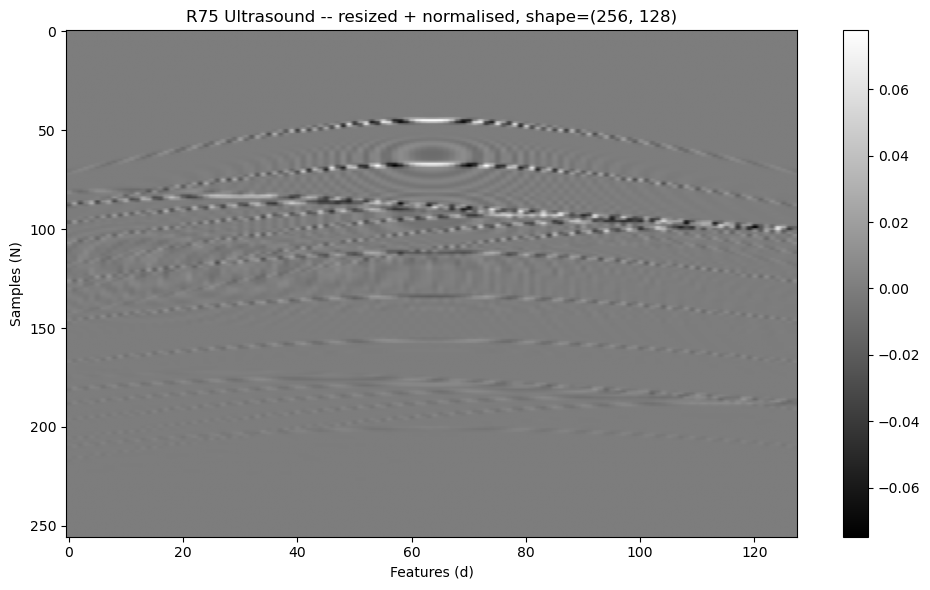

flat vector: shape=(32768,), norm=1.000000
  2^15 = 32768, matches 256*128 = 32768


c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(
c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(



MPS: n_qubits=15, max_bond=128

Roundtrip check: rel err = 1.8989e-15  (PASS)


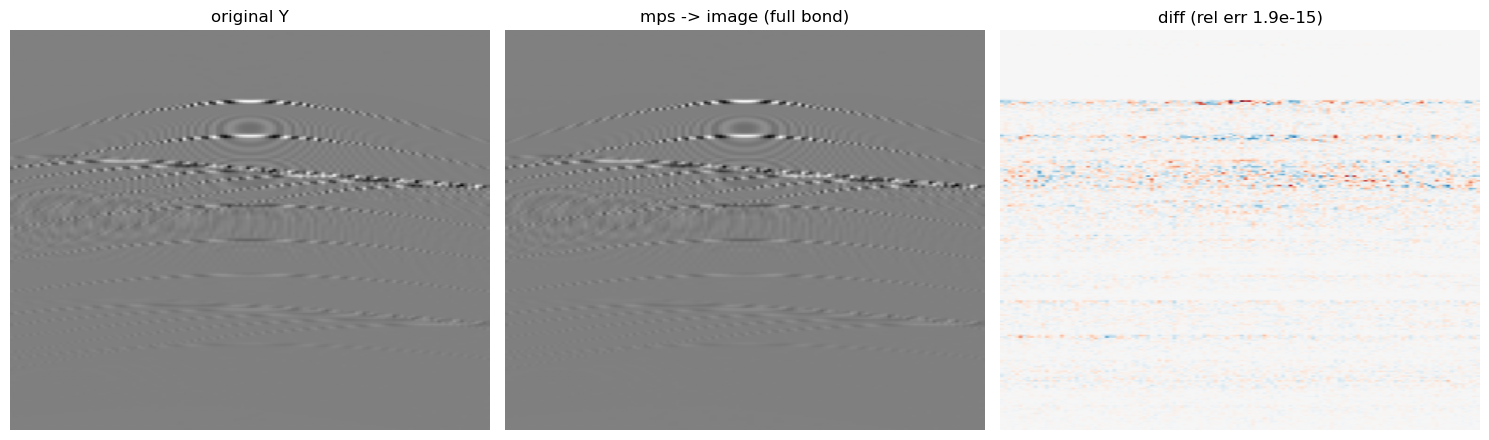

In [6]:
#LOAD R75
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize

df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
print(f"raw shape: {df.shape}")

Y_np = resize(df.to_numpy(), (256, 128), anti_aliasing=True)
print(f"resized: {Y_np.shape}")
Y = Y_np / np.linalg.norm(Y_np)
print(f"normalised: ||Y|| = {np.linalg.norm(Y):.6f}")

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(Y, aspect='auto', cmap='gray')
ax.set_title(f'R75 Ultrasound -- resized + normalised, shape={Y.shape}')
ax.set_xlabel('Features (d)'); ax.set_ylabel('Samples (N)')
plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()
v = Y.T.flatten()
print(f"flat vector: shape={v.shape}, norm={np.linalg.norm(v):.6f}")
print(f"  2^15 = {2**15}, matches 256*128 = {256*128}")

N_QUBITS = 15
ultra_mps = qtn.MatrixProductState.from_dense(
    v.astype(np.complex128),
    dims=[2] * N_QUBITS,
    cutoff=0.0,
)
ultra_mps /= ultra_mps.norm()
print(f"\nMPS: n_qubits={N_QUBITS}, max_bond={ultra_mps.max_bond()}")

ultra_meta = {
    'shape':       Y.shape,
    'flatten':     'Y.T.flatten()',
    'norm':        float(np.linalg.norm(v)),
    'n_qubits':    N_QUBITS,
}

psi_back = np.asarray(ultra_mps.to_dense()).reshape(-1)
psi_back = psi_back / np.linalg.norm(psi_back)
img_back = psi_back.real.reshape(128, 256).T
rel_err = float(np.linalg.norm(img_back - Y) / np.linalg.norm(Y))
print(f"\nRoundtrip check: rel err = {rel_err:.4e}  ({'PASS' if rel_err < 1e-10 else 'FAIL'})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
v_scale = float(np.abs(Y).max())
axes[0].imshow(Y, aspect='auto', cmap='gray', vmin=-v_scale, vmax=v_scale)
axes[0].set_title('original Y'); axes[0].axis('off')
axes[1].imshow(img_back, aspect='auto', cmap='gray', vmin=-v_scale, vmax=v_scale)
axes[1].set_title('mps -> image (full bond)'); axes[1].axis('off')
diff = img_back - Y
dv = max(float(np.abs(diff).max()), 1e-16)
axes[2].imshow(diff, aspect='auto', cmap='RdBu_r', vmin=-dv, vmax=dv)
axes[2].set_title(f'diff (rel err {rel_err:.1e})'); axes[2].axis('off')
plt.tight_layout(); plt.show()



In [7]:
import numpy as np, pandas as pd
from skimage.transform import resize

df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
Y_small = resize(df.to_numpy(), (32, 4), anti_aliasing=True)   # (rowlen=32, n_rows=8)
Y = Y_small / np.linalg.norm(Y_small)
print(Y.shape, "-> N_ROWS =", Y.shape[1], " row length =", Y.shape[0])


(32, 4) -> N_ROWS = 4  row length = 32


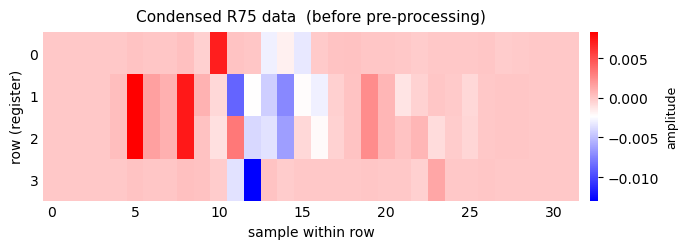

In [8]:
import matplotlib.pyplot as plt

img = Y_small.T                              # (32, 8) -> (8, 32): 8 rows across, 32 samples wide

fig, ax = plt.subplots(figsize=(7, 2.6))
im = ax.imshow(img, aspect='auto', cmap='bwr',
               interpolation='nearest',
               vmin=img.min(), vmax=img.max())

ax.set_title('Condensed R75 data  (before pre-processing)',
             fontsize=11, pad=8)
ax.set_xlabel('sample within row')
ax.set_ylabel('row (register)')
ax.set_yticks(range(img.shape[0]))

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.outline.set_visible(False)
cbar.set_label('amplitude', fontsize=9)

for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)

plt.tight_layout()
plt.show()


# Fidelity comparisons

## Row by row SSO

In [27]:
import json, os, time
import numpy as np

# ---------------- config ----------------
N_ROWS  = Y_small.shape[1]           # 8 rows (Y_small.T[i]), each length 32 = 5 qubits
CHIS    = [2]
K_PER_CHI = {2: 12, 4: 1, 8: 1}      # 5-qubit rows: chi=2 saturates well before 30
N_ITER  = 200

OUTDIR = r"SSO results\row_sweep_8x32"      # separate folder from the 128-row run
os.makedirs(OUTDIR, exist_ok=True)
RESULTS_JSON = os.path.join(OUTDIR, "row_fids_xsmall.json")

# ---------------- resume ----------------
if os.path.exists(RESULTS_JSON):
    with open(RESULTS_JSON) as f:
        all_results = json.load(f)
    print(f"resuming — {len(all_results)} rows already done", flush=True)
else:
    all_results = {}

def build_row_mps(i):
    row = Y_small.T[i]; row = row / np.linalg.norm(row)
    n = int(np.log2(len(row)))
    m = qtn.MatrixProductState.from_dense(row.astype(np.complex128), dims=[2]*n, cutoff=0.0)
    return m / m.norm()

def atomic_save(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)

# ---------------- sweep ----------------
for i in range(N_ROWS):
    if str(i) in all_results:
        continue

    print(f"\n===== ROW {i+1}/{N_ROWS}  (index {i}) =====", flush=True)
    t0 = time.time()
    row_mps = build_row_mps(i)

    row_data = {"n_qubits": row_mps.L, "chi": {}}
    for chi in CHIS:
        print(f"    chi={chi} running ({K_PER_CHI[chi]} layers)...", flush=True)
        res  = sequential_disentangle_warm(
            row_mps, chi=chi, num_layers=K_PER_CHI[chi], n_iter=N_ITER, verbose=False,
        )
        fids = [float(v) for v in res["chi_fids"]]
        row_data["chi"][str(chi)] = {"chi_fids": fids, "final_fid": fids[-1]}
        print(f"    chi={chi} per-layer fids: [" +
              ", ".join(f"{v:.4f}" for v in fids) + "]", flush=True)
        print(f"    chi={chi} DONE -> final fid = {fids[-1]:.5f}", flush=True)

    row_data["runtime_s"] = round(time.time() - t0, 1)
    all_results[str(i)] = row_data
    atomic_save(all_results, RESULTS_JSON)

    print(f"  row {i} saved  ({row_data['runtime_s']:.0f}s)  " +
          "  ".join(f"chi{c}={row_data['chi'][str(c)]['final_fid']:.4f}" for c in CHIS),
          flush=True)

print("\nDONE ->", RESULTS_JSON, flush=True)



===== ROW 1/4  (index 0) =====
    chi=2 running (12 layers)...
    chi=2 per-layer fids: [0.9992, 0.9998, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]
    chi=2 DONE -> final fid = 1.00000
  row 0 saved  (6s)  chi2=1.0000

===== ROW 2/4  (index 1) =====
    chi=2 running (12 layers)...
    chi=2 per-layer fids: [0.9091, 0.9971, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]
    chi=2 DONE -> final fid = 1.00000
  row 1 saved  (10s)  chi2=1.0000

===== ROW 3/4  (index 2) =====
    chi=2 running (12 layers)...
    chi=2 per-layer fids: [0.8415, 0.9969, 0.9998, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]
    chi=2 DONE -> final fid = 1.00000
  row 2 saved  (8s)  chi2=1.0000

===== ROW 4/4  (index 3) =====
    chi=2 running (12 layers)...
    chi=2 per-layer fids: [0.9990, 0.9999, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]
  

## Full state SSO

In [6]:
#HERE SET THE TARGET
v = Y_small.flatten()
print(f"flat vector: shape={v.shape}, norm={np.linalg.norm(v):.6f}")
print(f"  2^7 = {2**7}, matches 4*32 = {4*32}")
N_QUBITS = 7
ultra_mps = qtn.MatrixProductState.from_dense(
    v.astype(np.complex128),
    dims=[2] * N_QUBITS,
    cutoff=0.0,
)
ultra_mps /= ultra_mps.norm()
print(f"\nMPS: n_qubits={N_QUBITS}, max_bond={ultra_mps.max_bond()}")

ultra_meta = {
    'shape':       Y.shape,
    'flatten':     'Y.T.flatten()',
    'norm':        float(np.linalg.norm(v)),
    'n_qubits':    N_QUBITS,
}

flat vector: shape=(128,), norm=0.027971
  2^7 = 128, matches 4*32 = 128

MPS: n_qubits=7, max_bond=8


In [21]:
import os, time, pickle
import numpy as np

# ===================== CONFIG (bump the target to continue) =====================
CHI                 = 2
ULTRA_TARGET_LAYERS = 120       # <-- raise this and re-run to progress further
ULTRA_N_ITER        = 200
ULTRA_CUTOFF        = 1e-7     # Schmidt cutoff for replay / reconstruction

OUTDIR = r"SSO results\ultra_warm_chi2"
os.makedirs(OUTDIR, exist_ok=True)
CKPT = os.path.join(OUTDIR, f"warm_chi{CHI}.pkl")

# ------------------------------------------------------------------------------
n = ultra_mps.L

def _to_mps(vec):
    m = qtn.MatrixProductState.from_dense(
        np.asarray(vec).astype(np.complex128), dims=[2]*n, cutoff=0.0)
    return m / m.norm()

def _mps_to_vec(m):
    m = m.copy()
    m.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else np.asarray(x))
    v = np.asarray(m.to_dense()).reshape(-1)
    return (v / np.linalg.norm(v)).astype(np.complex128)

def _save_ckpt(state):
    tmp = CKPT + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(state, f)
    os.replace(tmp, CKPT)

# ---------------------------------- resume ------------------------------------
if os.path.exists(CKPT):
    with open(CKPT, "rb") as f:
        ck = pickle.load(f)
    layers       = ck["layers"]
    chi_fids     = ck["chi_fids"]
    init_losses  = ck["init_losses"]
    final_losses = ck["final_losses"]
    cur_vec      = ck["cur_vec"]
    print(f"resuming warm chi={CHI} at layer {len(chi_fids)-1}/{ULTRA_TARGET_LAYERS}  "
          f"(fid = {chi_fids[-1]:.5f})", flush=True)
else:
    v0 = ultra_mps.to_dense().reshape(-1)
    cur_vec      = (v0 / np.linalg.norm(v0)).astype(np.complex128)
    layers       = []
    chi_fids     = [float(chi_fidelity(_to_mps(cur_vec), CHI))]
    init_losses  = []
    final_losses = []
    print(f"fresh warm chi={CHI} run, n={n} qubits, init fid = {chi_fids[0]:.5f}", flush=True)

# ------------------------- extend one layer at a time -------------------------
while len(chi_fids) - 1 < ULTRA_TARGET_LAYERS:
    t0 = time.time()
    res = sequential_disentangle_warm(
        _to_mps(cur_vec), chi=CHI, num_layers=1, n_iter=ULTRA_N_ITER, verbose=False)

    layers.append(res["layers"][-1])
    chi_fids.append(float(res["chi_fids"][-1]))
    init_losses.append(float(res["init_losses"][-1]))
    final_losses.append(float(res["final_losses"][-1]))
    cur_vec = _mps_to_vec(res["final_mps"])

    _save_ckpt({"chi": CHI, "layers": layers, "chi_fids": chi_fids,
                "init_losses": init_losses, "final_losses": final_losses,
                "cur_vec": cur_vec})
    print(f"  layer {len(chi_fids)-1}/{ULTRA_TARGET_LAYERS}  "
          f"chi{CHI} fid = {chi_fids[-1]:.5f}  ({time.time()-t0:.0f}s)", flush=True)

print(f"\n========== WARM chi={CHI}  ({len(chi_fids)-1} layers) ==========")
print(f"  chi_fids: {[f'{v:.4f}' for v in chi_fids]}")

# ------------- downstream replay / reconstruction on the full layer set -------
replay = img_sso_replay_with_cutoff(ultra_mps, layers, CHI, cutoff=ULTRA_CUTOFF)
print(f"  residual bond per L: {replay['bond_dims']}")
recon_bonds = reconstruction_bond_growth(
    ultra_mps, layers, replay['gate_infos'], CHI, cutoff=ULTRA_CUTOFF)
print(f"  reconstruction bond per L (0..K): {recon_bonds}")

WARM_RESULTS = {CHI: {
    'sweep':       {'chi': CHI, 'num_layers': len(layers), 'layers': layers,
                    'chi_fids': chi_fids, 'init_losses': init_losses,
                    'final_losses': final_losses},
    'gate_infos':  replay['gate_infos'],
    'bond_dims':   replay['bond_dims'],
    'recon_bonds': recon_bonds,
}}

# keep the old name working for any downstream cell that reads it
ULTRA_K_CHI2 = len(chi_fids) - 1


fresh warm chi=2 run, n=7 qubits, init fid = 0.63485
  layer 1/120  chi2 fid = 0.79043  (2s)
  layer 2/120  chi2 fid = 0.94951  (2s)
  layer 3/120  chi2 fid = 0.97753  (2s)
  layer 4/120  chi2 fid = 0.98511  (2s)
  layer 5/120  chi2 fid = 0.99199  (2s)
  layer 6/120  chi2 fid = 0.99611  (2s)
  layer 7/120  chi2 fid = 0.99790  (2s)
  layer 8/120  chi2 fid = 0.99841  (2s)
  layer 9/120  chi2 fid = 0.99911  (2s)
  layer 10/120  chi2 fid = 0.99945  (2s)
  layer 11/120  chi2 fid = 0.99967  (2s)
  layer 12/120  chi2 fid = 0.99978  (2s)
  layer 13/120  chi2 fid = 0.99984  (2s)
  layer 14/120  chi2 fid = 0.99989  (2s)
  layer 15/120  chi2 fid = 0.99992  (2s)
  layer 16/120  chi2 fid = 0.99994  (2s)
  layer 17/120  chi2 fid = 0.99996  (2s)
  layer 18/120  chi2 fid = 0.99997  (2s)
  layer 19/120  chi2 fid = 0.99998  (2s)
  layer 20/120  chi2 fid = 0.99998  (2s)
  layer 21/120  chi2 fid = 0.99999  (2s)
  layer 22/120  chi2 fid = 0.99999  (2s)
  layer 23/120  chi2 fid = 0.99999  (2s)
  layer 24/12

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 4 is different from 2)

## Checking single layerflattened state also can be efficiently row encoded

In [13]:
#All functions needed for classical pre-processing step
import numpy as np, torch
import quimb.tensor as qtn

def build_initial_and_layer(Y, eps_init=0.0, seed=0):
    """
    Step 1 of the classical preprocessing.
      - Sets the normalised, flattened image as the initial state (an MPS).
        No preparation circuit is built -- Y_small IS the starting state.
      - Builds one chi=2 SU(4) staircase layer V (from the SSO code) to act on it.
    eps_init = 0.0  ->  V is exactly the identity (used for the sanity check).
    Returns (mps, layer).
    """
    v = np.asarray(Y, dtype=np.complex128).T.flatten()     # rows stacked (same order as the encoding)
    v = v / np.linalg.norm(v)
    n = int(round(np.log2(v.size)))                        # 8 qubits for a 32x8 image
    mps = qtn.MatrixProductState.from_dense(v.reshape([2]*n), dims=[2]*n)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    layer = make_chi2_staircase(n, eps=eps_init, seed=seed)   # SU(4) staircase, from SSO setup
    return mps, layer

def state_after_layer(layer, mps):
    """Dense, normalised state vector of V|psi>."""
    psi = dense_state_from_op_mps(layer, mps).reshape(-1)
    psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
    return psi.detach().cpu().numpy()
def ipr_of(state):
    """Inverse participation ratio:  sum_i |state_i|^4.
       = 1/D for the uniform state, = 1 for a single basis state. Lower = flatter."""
    a2 = np.abs(np.asarray(state).ravel())**2
    return float(np.sum(a2**2))

def ipr_after_layer(layer, mps):
    """IPR of V|psi> as a torch scalar -- this is exactly the loss the optimiser will minimise."""
    psi = dense_state_from_op_mps(layer, mps).reshape(-1)
    psi = psi / torch.sqrt((psi.conj() * psi).sum().real)   # normalise defensively
    return (torch.abs(psi)**4).sum()
def optimise_flatten_layer(mps, n_iter=300, eps_init=1e-2, seed=0, verbose=True):
    """
    Optimise one SU(4) chi=2 staircase V to MINIMISE IPR(V|psi>).
    Returns dict:
        layer   -- the best V found (a staircase TN of SU(4) gates)
        ipr0    -- IPR before (identity / do-nothing baseline)
        ipr     -- IPR after
        history -- IPR at every optimiser evaluation (for a convergence plot)
    Falls back to the identity layer if optimisation never beats doing nothing.
    """
    n = mps.L

    # baseline: IPR of doing nothing (identity layer). This is what we must beat.
    id_layer = make_chi2_staircase(n, eps=0.0)
    ipr0 = float(ipr_after_layer(id_layer, mps))

    # perturbed start: all-zero params is a saddle, so kick it slightly.
    layer = make_chi2_staircase(n, eps=eps_init, seed=seed)

    history = []
    best = {"val": float("inf"), "params": None}

    def loss(op, init_tn):
        val = ipr_after_layer(op, init_tn)          # the torch scalar from the previous cell
        s = float(val.detach())
        history.append(s)
        if s < best["val"]:                          # snapshot the best iterate we've seen
            best["val"] = s
            best["params"] = {k: vv.detach().cpu().numpy().copy()
                              for k, vv in op.get_params().items()}
        return val

    tnopt = qtn.TNOptimizer(
        layer, loss, loss_constants={"init_tn": mps},
        optimizer="l-bfgs-b", autodiff_backend="torch", progbar=verbose,
    )
    tnopt.optimize(n=n_iter)

    # keep the best iterate; fall back to identity if it didn't beat doing nothing
    if best["params"] is not None and best["val"] < ipr0:
        layer.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        final_layer, ipr_final = layer, best["val"]
    else:
        final_layer, ipr_final = id_layer, ipr0
    psi_flat = state_after_layer(final_layer, mps)          # the transformed state V|psi>

    if verbose:
        print(f"IPR {ipr0:.6f} -> {ipr_final:.6f}   (uniform floor 1/D = {1/2**n:.6f})")
    return {"layer": final_layer,      # the gate set V (SU(4) staircase)
            "psi_flat": psi_flat,      # the transformed state, normalised numpy vector
            "ipr0": ipr0, "ipr": ipr_final, "history": history}


+0.008176785534 [best: +0.008176785534] :  37%|███▋      | 110/300 [00:01<00:02, 86.78it/s]


IPR 0.094962 -> 0.008177   (uniform floor 1/D = 0.007812)
flattened-state norm: 1.0
all gates unitary: OK
IPR dropped: True


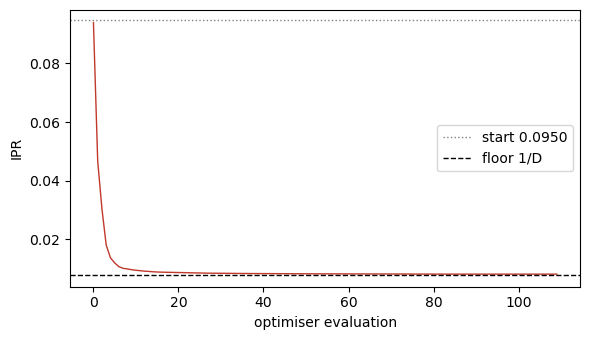

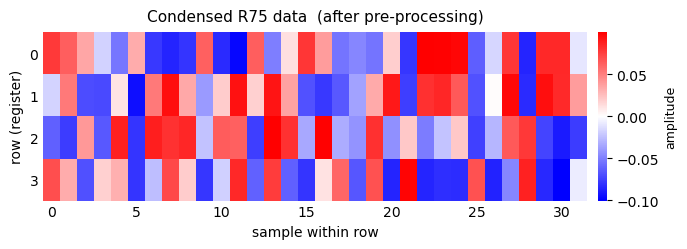

In [11]:
mps, _ = build_initial_and_layer(Y_small, eps_init=0.0)     # fresh initial state
res = optimise_flatten_layer(mps, n_iter=300, eps_init=1e-2, seed=0)

# check 1: V is unitary, so the flattened state is still normalised
psi_flat = state_after_layer(res["layer"], mps)
print("flattened-state norm:", round(float(np.linalg.norm(psi_flat)), 10))   # expect 1.0
assert_layer_unitary(res["layer"])                          # SSO helper: all gates unitary
print("all gates unitary: OK")

# check 2: IPR actually dropped
print("IPR dropped:", res["ipr"] < res["ipr0"])

# check 3: convergence curve
import matplotlib.pyplot as plt
plt.figure(figsize=(6,3.5))
plt.plot(res["history"], color='#c0392b', lw=1)
plt.axhline(res["ipr0"], color='grey', ls=':',  lw=1, label=f"start {res['ipr0']:.4f}")
plt.axhline(1/mps.L and 1/2**mps.L, color='black', ls='--', lw=1, label=f"floor 1/D")
plt.xlabel("optimiser evaluation"); plt.ylabel("IPR"); plt.legend(); plt.tight_layout(); plt.show()

M, N = 4, 32                                  # registers, samples-per-row
Y_small_flat = psi_flat.reshape(M, N).T        # flat 256-vector -> (32, 8) image, Y_small convention

import matplotlib.pyplot as plt

img = Y_small_flat.real.T                              # (32, 8) -> (8, 32): 8 rows across, 32 samples wide

fig, ax = plt.subplots(figsize=(7, 2.6))
im = ax.imshow(img, aspect='auto', cmap='bwr',
               interpolation='nearest',
               vmin=img.min(), vmax=img.max())

ax.set_title('Condensed R75 data  (after pre-processing)',
             fontsize=11, pad=8)
ax.set_xlabel('sample within row')
ax.set_ylabel('row (register)')
ax.set_yticks(range(img.shape[0]))

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.outline.set_visible(False)
cbar.set_label('amplitude', fontsize=9)

for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)

plt.tight_layout()
plt.show()


In [26]:
import json, os, time
import numpy as np

# ---------------- config ----------------
N_ROWS  = Y_small_flat.shape[1]      # 8 rows (Y_small_flat.T[i]), each length 32 = 5 qubits
CHIS    = [2]
K_PER_CHI = {2: 12, 4: 1, 8: 1}      # 5-qubit rows: chi=2 saturates well before 30
N_ITER  = 200

OUTDIR = r"SSO results\row_sweep_8x32_flat"   # separate folder from the un-flattened run
os.makedirs(OUTDIR, exist_ok=True)
RESULTS_JSON = os.path.join(OUTDIR, "row_fids_xsmall.json")

# ---------------- resume ----------------
if os.path.exists(RESULTS_JSON):
    with open(RESULTS_JSON) as f:
        all_results_flat = json.load(f)
    print(f"resuming — {len(all_results_flat)} rows already done", flush=True)
else:
    all_results_flat = {}

def build_row_mps(i):
    row = Y_small_flat.T[i]; row = row / np.linalg.norm(row)
    n = int(np.log2(len(row)))
    m = qtn.MatrixProductState.from_dense(row.astype(np.complex128), dims=[2]*n, cutoff=0.0)
    return m / m.norm()

def atomic_save(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)

# ---------------- sweep ----------------
for i in range(N_ROWS):
    if str(i) in all_results_flat:
        continue

    print(f"\n===== ROW {i+1}/{N_ROWS}  (index {i}) =====", flush=True)
    t0 = time.time()
    row_mps = build_row_mps(i)

    row_data = {"n_qubits": row_mps.L, "chi": {}}
    for chi in CHIS:
        print(f"    chi={chi} running ({K_PER_CHI[chi]} layers)...", flush=True)
        res  = sequential_disentangle_warm(
            row_mps, chi=chi, num_layers=K_PER_CHI[chi], n_iter=N_ITER, verbose=False,
        )
        fids = [float(v) for v in res["chi_fids"]]
        row_data["chi"][str(chi)] = {"chi_fids": fids, "final_fid": fids[-1]}
        print(f"    chi={chi} per-layer fids: [" +
              ", ".join(f"{v:.4f}" for v in fids) + "]", flush=True)
        print(f"    chi={chi} DONE -> final fid = {fids[-1]:.5f}", flush=True)

    row_data["runtime_s"] = round(time.time() - t0, 1)
    all_results_flat[str(i)] = row_data
    atomic_save(all_results_flat, RESULTS_JSON)

    print(f"  row {i} saved  ({row_data['runtime_s']:.0f}s)  " +
          "  ".join(f"chi{c}={row_data['chi'][str(c)]['final_fid']:.4f}" for c in CHIS),
          flush=True)

print("\nDONE ->", RESULTS_JSON, flush=True)



===== ROW 1/4  (index 0) =====
    chi=2 running (12 layers)...
    chi=2 per-layer fids: [0.8604, 0.9983, 0.9999, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]
    chi=2 DONE -> final fid = 1.00000
  row 0 saved  (9s)  chi2=1.0000

===== ROW 2/4  (index 1) =====
    chi=2 running (12 layers)...
    chi=2 per-layer fids: [0.8292, 0.9818, 0.9999, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]
    chi=2 DONE -> final fid = 1.00000
  row 1 saved  (10s)  chi2=1.0000

===== ROW 3/4  (index 2) =====
    chi=2 running (12 layers)...
    chi=2 per-layer fids: [0.7522, 0.9944, 0.9999, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]
    chi=2 DONE -> final fid = 1.00000
  row 2 saved  (9s)  chi2=1.0000

===== ROW 4/4  (index 3) =====
    chi=2 running (12 layers)...
    chi=2 per-layer fids: [0.7719, 0.9937, 0.9996, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]
  

## Comparison of results

In [14]:
def total_chi_fids(results, chi=2):
    """Combined multi-register fidelity per layer = prod_i F_i  (paper Eq. 5).
    `results` is the all_results dict: {str(i): {"chi": {str(chi): {"chi_fids":[...]}}}}.
    Returns the total FIDELITY array (caller does 1 - this for infidelity)."""
    key = str(chi)
    fids = [np.array(v["chi"][key]["chi_fids"], float) for v in results.values()]
    L = min(len(x) for x in fids)                        # align to shortest row
    F = np.clip(np.stack([x[:L] for x in fids]), 1e-300, 1.0)
    return np.exp(np.sum(np.log(F), axis=0))             # = prod over rows, log-stable


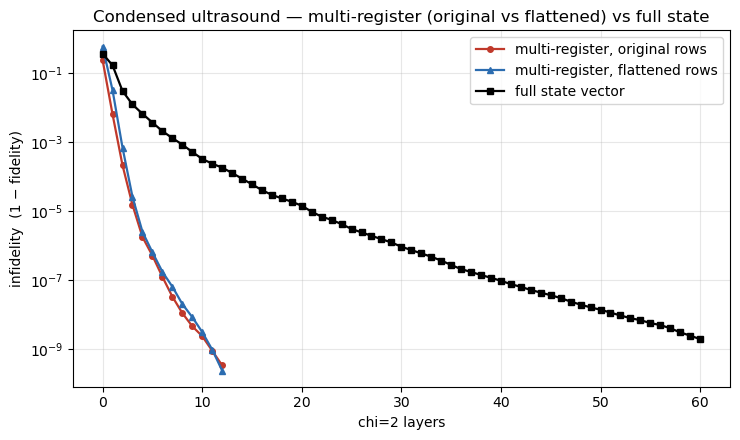

multi-register (original)  final infidelity: 3.312e-10
multi-register (flattened) final infidelity: 2.343e-10
full state (60 layers)      final infidelity: 1.904e-09


In [28]:
import matplotlib.pyplot as plt
import numpy as np
import os, pickle

# ---- multi-register combined, ORIGINAL rows (target = Y_small rows, via all_results) ----
tot_orig   = total_chi_fids(all_results, chi=2)
infid_orig = np.clip(1.0 - tot_orig, 1e-16, None)

# ---- multi-register combined, FLATTENED rows (target = Y_small_flat rows, via all_results_flat) ----
tot_flat   = total_chi_fids(all_results_flat, chi=2)
infid_flat = np.clip(1.0 - tot_flat, 1e-16, None)

# ---- full state-vector encoding: REUSE the already-run chi=2 warm sweep -------
# Prefer the in-memory result from the WARM_RESULTS cell; otherwise load the
# checkpoint it saved. No new optimisation is run here.
if 'WARM_RESULTS' in globals() and 2 in WARM_RESULTS:
    full_fids = np.array(WARM_RESULTS[2]['sweep']['chi_fids'], dtype=float)
elif 'chi_fids' in globals():
    full_fids = np.array(chi_fids, dtype=float)
else:
    CKPT = r"SSO results\ultra_warm_chi2\warm_chi2.pkl"
    if not os.path.exists(CKPT):
        raise RuntimeError("No full-state results found — run the WARM_RESULTS cell first.")
    with open(CKPT, "rb") as f:
        full_fids = np.array(pickle.load(f)["chi_fids"], dtype=float)

infid_full = np.clip(1.0 - full_fids, 1e-16, None)

# ---- plot ----
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.semilogy(np.arange(len(infid_orig)), infid_orig, marker='o', ms=4, lw=1.6,
            color='#c0392b', label='multi-register, original rows')
ax.semilogy(np.arange(len(infid_flat)), infid_flat, marker='^', ms=4, lw=1.6,
            color='#2b6cb0', label='multi-register, flattened rows')
ax.semilogy(np.arange(len(infid_full)), infid_full, marker='s', ms=4, lw=1.6,
            color='black', label='full state vector')

ax.set_xlabel('chi=2 layers')
ax.set_ylabel('infidelity  (1 \u2212 fidelity)')
ax.set_title('Condensed ultrasound \u2014 multi-register (original vs flattened) vs full state')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout(); plt.show()

print(f"multi-register (original)  final infidelity: {infid_orig[-1]:.3e}")
print(f"multi-register (flattened) final infidelity: {infid_flat[-1]:.3e}")
print(f"full state ({len(infid_full)-1} layers)      final infidelity: {infid_full[-1]:.3e}")


## Running for full flattened state

In [27]:
import numpy as np, pandas as pd, torch
from skimage.transform import resize

df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
Y_full = resize(df.to_numpy(), (256, 128), anti_aliasing=True)      # (samples, registers) = (256, 128)
Y_full = Y_full / np.linalg.norm(Y_full)
M, N = Y_full.shape[1], Y_full.shape[0]                              # 128 registers, 256 samples
print("Y_full:", Y_full.shape, " -> 15 qubits, M =", M, "registers of", N)

# flatten it (one SU(4) chi=2 layer on the full 15-qubit state)
mps_full, _ = build_initial_and_layer(Y_full, eps_init=0.0)
flat_full   = optimise_flatten_layer(mps_full, n_iter=300, eps_init=1e-2, seed=0, verbose=True)
Y_full_flat = flat_full["psi_flat"].reshape(M, N).T                 # (256, 128), flattened, complex
print("IPR", flat_full["ipr0"], "->", flat_full["ipr"])


Y_full: (256, 128)  -> 15 qubits, M = 128 registers of 256


+0.000066512234 [best: +0.000066512234] :   2%|▏         | 5/300 [00:00<00:15, 19.62it/s]


IPR 0.001557 -> 0.000067   (uniform floor 1/D = 0.000031)
IPR 0.0015572609903244103 -> 6.651223378612357e-05


In [ ]:
#Old flattneed latyer for 1 staircvase IPR
#IMPORTANT: seed for this is generated with seed=0 for reproducibility

import json, os, time, numpy as np

Y_target, RUN_NAME, K = Y_full_flat, "R75full_flat", 140

OUTDIR = rf"SSO results\row_sweep_{RUN_NAME}"; os.makedirs(OUTDIR, exist_ok=True)
FIDS_JSON  = os.path.join(OUTDIR, "row_fids.json")
STATES_NPZ = os.path.join(OUTDIR, "row_states.npz")
N_ROWS = Y_target.shape[1]; n = int(np.log2(Y_target.shape[0]))

# ---- load prior results, closing file handles immediately ----
if os.path.exists(FIDS_JSON):
    with open(FIDS_JSON) as f: all_results = json.load(f)
else:
    all_results = {}
if os.path.exists(STATES_NPZ):
    with np.load(STATES_NPZ) as z: states = dict(z)
else:
    states = {}

def to_mps(vec):
    m = qtn.MatrixProductState.from_dense(vec.astype(np.complex128), dims=[2]*n, cutoff=0.0); return m/m.norm()
def mps_to_vec(m):
    m=m.copy(); m.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x,'detach') else np.asarray(x))
    v=np.asarray(m.to_dense()).reshape(-1); return (v/np.linalg.norm(v)).astype(np.complex128)

def _rep(tmp, dst):                                        # retry os.replace through OneDrive/AV locks
    for _ in range(30):
        try: os.replace(tmp, dst); return
        except PermissionError: time.sleep(0.5)
    os.replace(tmp, dst)
def save_all():
    tj = FIDS_JSON + ".tmp"
    with open(tj, "w") as f: json.dump(all_results, f, indent=2)
    _rep(tj, FIDS_JSON)
    tn = STATES_NPZ + ".tmp.npz"; np.savez(tn, **states); _rep(tn, STATES_NPZ)

for i in range(N_ROWS):
    key = str(i)
    done = (len(all_results[key]["chi"]["2"]["chi_fids"]) - 1) if key in all_results else 0
    if done >= K:
        continue
    t0 = time.time()
    if done > 0 and key in states:                         # resume from saved state
        start = to_mps(states[key]); fids = all_results[key]["chi"]["2"]["chi_fids"]
    else:                                                  # fresh (or old stateless results -> restart clean)
        start = to_mps(Y_target.T[i] / np.linalg.norm(Y_target.T[i])); fids = None; done = 0

    res = sequential_disentangle_warm(start, chi=2, num_layers=K - done, n_iter=200, verbose=False)
    new = [float(v) for v in res["chi_fids"]]
    fids = new if fids is None else fids + new[1:]
    states[key] = mps_to_vec(res["final_mps"])
    all_results[key] = {"n_qubits": n, "chi": {"2": {"chi_fids": fids, "final_fid": fids[-1]}}}
    save_all()
    print(f"  row {i+1}/{N_ROWS}: {done}->{K} layers ({time.time()-t0:.0f}s)  fid={fids[-1]:.4f}", flush=True)
print("DONE ->", FIDS_JSON, flush=True)


  row 64/128: 120->140 layers (2s)  fid=1.0000
  row 65/128: 120->140 layers (3s)  fid=1.0000
  row 66/128: 120->140 layers (3s)  fid=1.0000
  row 67/128: 120->140 layers (3s)  fid=1.0000
  row 68/128: 120->140 layers (3s)  fid=1.0000
  row 69/128: 120->140 layers (3s)  fid=1.0000
  row 70/128: 120->140 layers (2s)  fid=1.0000
  row 71/128: 120->140 layers (2s)  fid=1.0000
  row 72/128: 120->140 layers (2s)  fid=1.0000
  row 73/128: 120->140 layers (3s)  fid=1.0000
  row 74/128: 120->140 layers (2s)  fid=1.0000
  row 75/128: 120->140 layers (3s)  fid=1.0000
  row 76/128: 120->140 layers (1s)  fid=1.0000
  row 77/128: 120->140 layers (4s)  fid=1.0000
  row 78/128: 120->140 layers (2s)  fid=1.0000
  row 79/128: 120->140 layers (2s)  fid=1.0000
  row 80/128: 120->140 layers (3s)  fid=1.0000
  row 81/128: 120->140 layers (2s)  fid=1.0000
  row 82/128: 120->140 layers (3s)  fid=1.0000
  row 83/128: 120->140 layers (2s)  fid=1.0000
  row 84/128: 120->140 layers (2s)  fid=1.0000
  row 85/128:

In [7]:
# --- recover layer_results / base_result / seq from the FIXED seed sweep on disk ---
# (survives a kernel restart; picks the best seed by reweighting success P at FLAT_L)
import pickle, glob, os, numpy as np

FLAT_L = 10                                   # flattening depth you want to encode
FLOOR  = 1.0 / 32768                          # uniform IPR floor for 15 qubits

cands = []
for p in sorted(glob.glob(os.path.join("results", "v_full_seed*.pkl")),
                key=lambda s: int(s.split("seed")[-1].split(".")[0])):
    with open(p, "rb") as f:
        d = pickle.load(f)
    lr = d["layer_results"]
    if FLAT_L not in lr:
        continue
    ratio = lr[FLAT_L]["ipr"] / FLOOR
    assert ratio > 1.05, (f"{os.path.basename(p)} is a BROKEN non-unitary run "
                          f"(IPR = {ratio:.4f}x the uniform floor). Delete it and re-run the sweep.")
    cands.append((lr[FLAT_L]["res"]["mean"], p, d))

assert cands, f"no seed pickle contains layer {FLAT_L}"
best_P, best_path, best_data = max(cands, key=lambda t: t[0])
layer_results = best_data["layer_results"]
base_result   = best_data["base_result"]
seq           = best_data["seq"]

print(f"recovered {os.path.basename(best_path)} (best of {len(cands)} seeds)")
print(f"   P@{FLAT_L}      = {best_P:.4f}   (baseline {base_result['mean']:.4f}, "
      f"{best_P/base_result['mean']:.1f}x)")
print(f"   IPR@{FLAT_L}    = {layer_results[FLAT_L]['ipr']:.4e} "
      f"({layer_results[FLAT_L]['ipr']/FLOOR:.3f}x uniform floor)")


recovered v_full_seed7.pkl (best of 10 seeds)
   P@10      = 0.3154   (baseline 0.0053, 60.1x)
   IPR@10    = 4.2694e-05 (1.399x uniform floor)


In [12]:
#IMPORTANT: FIXED brickwall optimiser (constant_tags=["ID"]) -- supersedes the broken *_L7 run
import json, os, time, numpy as np

FLAT_L   = 10                                    # flattening depth to encode
Y_target = layer_results[FLAT_L]["Y_flat"]       # from the FIXED compare_flatten_layers run
RUN_NAME = f"R75full_brickwallFIXED_L{FLAT_L}"   # NEW folder -- never reuse the broken one
K        = 120                                    # chi=2 layers per row

# --- guard: refuse to encode a non-unitary "flattened" state ---
_ipr, _floor = float((np.abs(Y_target.T.ravel())**4).sum()), 1.0 / Y_target.size
assert _ipr / _floor > 1.05, (
    f"IPR is {_ipr/_floor:.4f}x the uniform floor -- this is the BROKEN non-unitary state. "
    "Re-run the fixed compare_flatten_layers cell first.")
print(f"{RUN_NAME}: IPR {_ipr:.4e} ({_ipr/_floor:.3f}x floor), "
      f"P = {layer_results[FLAT_L]['res']['mean']:.4f}")

OUTDIR = rf"SSO results\row_sweep_{RUN_NAME}"; os.makedirs(OUTDIR, exist_ok=True)
FIDS_JSON  = os.path.join(OUTDIR, "row_fids.json")
STATES_NPZ = os.path.join(OUTDIR, "row_states.npz")
N_ROWS = Y_target.shape[1]; n = int(np.log2(Y_target.shape[0]))


# ---- load prior results, closing file handles immediately ----
if os.path.exists(FIDS_JSON):
    with open(FIDS_JSON) as f: all_results = json.load(f)
else:
    all_results = {}
if os.path.exists(STATES_NPZ):
    with np.load(STATES_NPZ) as z: states = dict(z)
else:
    states = {}

def to_mps(vec):
    m = qtn.MatrixProductState.from_dense(vec.astype(np.complex128), dims=[2]*n, cutoff=0.0); return m/m.norm()
def mps_to_vec(m):
    m=m.copy(); m.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x,'detach') else np.asarray(x))
    v=np.asarray(m.to_dense()).reshape(-1); return (v/np.linalg.norm(v)).astype(np.complex128)

def _rep(tmp, dst):                                        # retry os.replace through OneDrive/AV locks
    for _ in range(30):
        try: os.replace(tmp, dst); return
        except PermissionError: time.sleep(0.5)
    os.replace(tmp, dst)
def save_all():
    tj = FIDS_JSON + ".tmp"
    with open(tj, "w") as f: json.dump(all_results, f, indent=2)
    _rep(tj, FIDS_JSON)
    tn = STATES_NPZ + ".tmp.npz"; np.savez(tn, **states); _rep(tn, STATES_NPZ)

for i in range(N_ROWS):
    key = str(i)
    done = (len(all_results[key]["chi"]["2"]["chi_fids"]) - 1) if key in all_results else 0
    if done >= K:
        continue
    t0 = time.time()
    if done > 0 and key in states:                         # resume from saved state
        start = to_mps(states[key]); fids = all_results[key]["chi"]["2"]["chi_fids"]
    else:                                                  # fresh (or old stateless results -> restart clean)
        start = to_mps(Y_target.T[i] / np.linalg.norm(Y_target.T[i])); fids = None; done = 0

    res = sequential_disentangle_warm(start, chi=2, num_layers=K - done, n_iter=200, verbose=False)
    new = [float(v) for v in res["chi_fids"]]
    fids = new if fids is None else fids + new[1:]
    states[key] = mps_to_vec(res["final_mps"])
    all_results[key] = {"n_qubits": n, "chi": {"2": {"chi_fids": fids, "final_fid": fids[-1]}}}
    save_all()
    print(f"  row {i+1}/{N_ROWS}: {done}->{K} layers ({time.time()-t0:.0f}s)  fid={fids[-1]:.4f}", flush=True)
print("DONE ->", FIDS_JSON, flush=True)


R75full_brickwallFIXED_L10: IPR 4.2694e-05 (1.399x floor), P = 0.3154
  row 1/128: 110->120 layers (4s)  fid=1.0000
  row 2/128: 110->120 layers (4s)  fid=1.0000
  row 3/128: 110->120 layers (3s)  fid=1.0000
  row 4/128: 110->120 layers (3s)  fid=1.0000
  row 5/128: 110->120 layers (3s)  fid=1.0000
  row 6/128: 110->120 layers (4s)  fid=1.0000
  row 7/128: 110->120 layers (3s)  fid=1.0000
  row 8/128: 110->120 layers (3s)  fid=1.0000
  row 9/128: 110->120 layers (3s)  fid=1.0000
  row 10/128: 110->120 layers (3s)  fid=1.0000
  row 11/128: 110->120 layers (3s)  fid=1.0000
  row 12/128: 110->120 layers (3s)  fid=1.0000
  row 13/128: 110->120 layers (3s)  fid=1.0000
  row 14/128: 110->120 layers (3s)  fid=1.0000
  row 15/128: 110->120 layers (3s)  fid=1.0000
  row 16/128: 110->120 layers (3s)  fid=1.0000
  row 17/128: 110->120 layers (3s)  fid=1.0000
  row 18/128: 110->120 layers (3s)  fid=1.0000
  row 19/128: 110->120 layers (3s)  fid=1.0000
  row 20/128: 110->120 layers (3s)  fid=1.0000

In [49]:
#Original MR
import json, os, time, numpy as np

Y_target, RUN_NAME, K = Y_full, "R75full_orig", 140    # NORMAL (unflattened) state; new folder

OUTDIR = rf"SSO results\row_sweep_{RUN_NAME}"; os.makedirs(OUTDIR, exist_ok=True)
FIDS_JSON  = os.path.join(OUTDIR, "row_fids.json")
STATES_NPZ = os.path.join(OUTDIR, "row_states.npz")
N_ROWS = Y_target.shape[1]; n = int(np.log2(Y_target.shape[0]))

all_results = json.load(open(FIDS_JSON)) if os.path.exists(FIDS_JSON) else {}
states = dict(np.load(STATES_NPZ)) if os.path.exists(STATES_NPZ) else {}

def to_mps(vec):
    m = qtn.MatrixProductState.from_dense(vec.astype(np.complex128), dims=[2]*n, cutoff=0.0); return m/m.norm()
def mps_to_vec(m):
    m=m.copy(); m.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x,'detach') else np.asarray(x))
    v=np.asarray(m.to_dense()).reshape(-1); return (v/np.linalg.norm(v)).astype(np.complex128)
def save_all():
    tj=FIDS_JSON+".tmp"; json.dump(all_results, open(tj,"w"), indent=2); os.replace(tj, FIDS_JSON)
    tn=STATES_NPZ+".tmp.npz"; np.savez(tn, **states); os.replace(tn, STATES_NPZ)

for i in range(N_ROWS):
    key = str(i)
    done = (len(all_results[key]["chi"]["2"]["chi_fids"]) - 1) if key in all_results else 0
    if done >= K:
        continue
    t0 = time.time()
    if done > 0 and key in states:                       # resume from saved state
        start = to_mps(states[key]); fids = all_results[key]["chi"]["2"]["chi_fids"]
    else:                                                 # fresh (or old stateless results -> restart clean)
        start = to_mps(Y_target.T[i] / np.linalg.norm(Y_target.T[i])); fids = None; done = 0

    res = sequential_disentangle_warm(start, chi=2, num_layers=K - done, n_iter=200, verbose=False)
    new = [float(v) for v in res["chi_fids"]]
    fids = new if fids is None else fids + new[1:]
    states[key] = mps_to_vec(res["final_mps"])
    all_results[key] = {"n_qubits": n, "chi": {"2": {"chi_fids": fids, "final_fid": fids[-1]}}}
    save_all()
    print(f"  row {i+1}/{N_ROWS}: {done}->{K} layers ({time.time()-t0:.0f}s)  fid={fids[-1]:.4f}", flush=True)
print("DONE ->", FIDS_JSON, flush=True)


  row 1/128: 130->140 layers (1s)  fid=1.0000
  row 2/128: 130->140 layers (1s)  fid=1.0000
  row 3/128: 130->140 layers (1s)  fid=1.0000
  row 4/128: 130->140 layers (1s)  fid=1.0000
  row 5/128: 130->140 layers (1s)  fid=1.0000
  row 6/128: 130->140 layers (1s)  fid=1.0000
  row 7/128: 130->140 layers (1s)  fid=1.0000
  row 8/128: 130->140 layers (1s)  fid=1.0000
  row 9/128: 130->140 layers (1s)  fid=1.0000
  row 10/128: 130->140 layers (1s)  fid=1.0000
  row 11/128: 130->140 layers (1s)  fid=1.0000
  row 12/128: 130->140 layers (1s)  fid=1.0000
  row 13/128: 130->140 layers (1s)  fid=1.0000
  row 14/128: 130->140 layers (1s)  fid=1.0000
  row 15/128: 130->140 layers (1s)  fid=1.0000
  row 16/128: 130->140 layers (1s)  fid=1.0000
  row 17/128: 130->140 layers (1s)  fid=1.0000
  row 18/128: 130->140 layers (1s)  fid=1.0000
  row 19/128: 130->140 layers (1s)  fid=1.0000
  row 20/128: 130->140 layers (1s)  fid=1.0000
  row 21/128: 130->140 layers (1s)  fid=1.0000
  row 22/128: 130->140

In [ ]:
#This is for full state
import os, shutil
os.makedirs(os.path.join(os.getcwd(), "SSO results", "fullstate_R75full"), exist_ok=True)
src = r"SSO results\fullstate_R75full\checkpoint.npz"          # current (OneDrive)
dst = os.path.join(os.getcwd(), "SSO results", "fullstate_R75full", "checkpoint.npz")
if os.path.exists(src) and not os.path.exists(dst):
    shutil.copy2(src, dst); print("copied 30-layer checkpoint to local")


copied 30-layer checkpoint to local


In [ ]:
#Full state
import os, time, numpy as np

OUTDIR_C = os.path.join(os.getcwd(), "SSO results", "fullstate_R75full"); os.makedirs(OUTDIR_C, exist_ok=True)   # local is fine
CKPT = os.path.join(OUTDIR_C, "checkpoint.npz")
TARGET_LAYERS, CHI = 140, 2

v0 = Y_full.T.flatten(); v0 = (v0/np.linalg.norm(v0)).astype(np.complex128)
n  = int(round(np.log2(v0.size)))

def to_mps(vec):
    m = qtn.MatrixProductState.from_dense(vec, dims=[2]*n, cutoff=0.0); return m/m.norm()
def mps_to_vec(m):
    m = m.copy(); m.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x,'detach') else np.asarray(x))
    v = np.asarray(m.to_dense()).reshape(-1); return (v/np.linalg.norm(v)).astype(np.complex128)
def save_ckpt(cur, chi_fids):
    tmp = CKPT + ".tmp.npz"
    np.savez(tmp, state=cur, chi_fids=np.array(chi_fids, dtype=float))
    os.replace(tmp, CKPT)

# resume -- READ INSIDE `with` SO THE FILE HANDLE IS RELEASED
if os.path.exists(CKPT):
    with np.load(CKPT) as d:
        cur = np.array(d["state"]); chi_fids = list(map(float, d["chi_fids"]))
    print(f"resuming full-state at layer {len(chi_fids)-1}/{TARGET_LAYERS}", flush=True)
else:
    cur = v0.copy(); chi_fids = [chi_fidelity(to_mps(cur), CHI)]
    print(f"fresh full-state run, n={n} qubits, init chi{CHI} fid = {chi_fids[0]:.5f}", flush=True)

while len(chi_fids) - 1 < TARGET_LAYERS:
    t0 = time.time()
    res = sequential_disentangle_warm(to_mps(cur), chi=CHI, num_layers=1, n_iter=200, verbose=False)
    cur = mps_to_vec(res["final_mps"])
    chi_fids.append(float(res["chi_fids"][-1]))
    save_ckpt(cur, chi_fids)
    print(f"  full-state {len(chi_fids)-1}/{TARGET_LAYERS}  chi{CHI} fid = {chi_fids[-1]:.5f}  ({time.time()-t0:.0f}s)", flush=True)
print("DONE ->", CKPT, flush=True)


resuming full-state at layer 120/140
  full-state 121/140  chi2 fid = 0.69175  (84s)
  full-state 122/140  chi2 fid = 0.69290  (77s)
  full-state 123/140  chi2 fid = 0.69436  (82s)
  full-state 124/140  chi2 fid = 0.69583  (82s)
  full-state 125/140  chi2 fid = 0.69668  (71s)
  full-state 126/140  chi2 fid = 0.69861  (75s)
  full-state 127/140  chi2 fid = 0.69976  (87s)
  full-state 128/140  chi2 fid = 0.70154  (81s)
  full-state 129/140  chi2 fid = 0.70236  (79s)
  full-state 130/140  chi2 fid = 0.70402  (90s)
  full-state 131/140  chi2 fid = 0.70530  (80s)
  full-state 132/140  chi2 fid = 0.70638  (81s)
  full-state 133/140  chi2 fid = 0.70788  (78s)
  full-state 134/140  chi2 fid = 0.70952  (84s)
  full-state 135/140  chi2 fid = 0.71063  (89s)
  full-state 136/140  chi2 fid = 0.71112  (77s)
  full-state 137/140  chi2 fid = 0.71266  (82s)
  full-state 138/140  chi2 fid = 0.71322  (86s)
  full-state 139/140  chi2 fid = 0.71422  (78s)
  full-state 140/140  chi2 fid = 0.71576  (71s)
DON

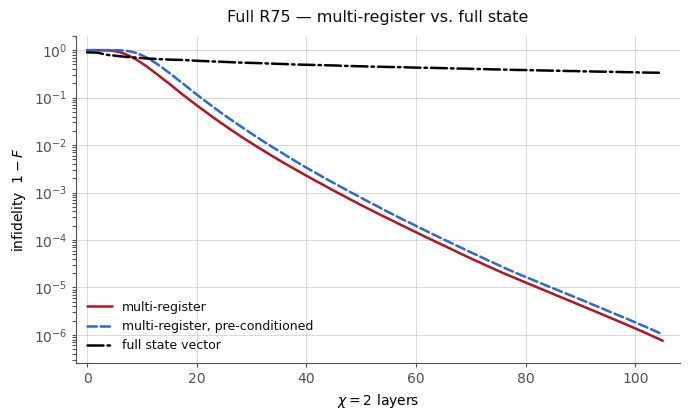

In [ ]:
import json, numpy as np, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

def combined_infid(run_name):
    with open(rf"SSO results\row_sweep_{run_name}\row_fids.json") as f:
        d = json.load(f)
    fids = [np.array(v["chi"]["2"]["chi_fids"], float) for v in d.values()]
    L = min(len(x) for x in fids)
    F = np.clip(np.array([x[:L] for x in fids]), 1e-300, 1.0)
    return np.clip(-np.expm1(np.sum(np.log(F), axis=0)), 1e-16, None)

infid_A = combined_infid("R75full_orig")
infid_B = combined_infid("R75full_brickwallFIXED_L10")
with np.load(os.path.join(os.getcwd(), "SSO results", "fullstate_R75full", "checkpoint.npz")) as ck:
    infid_C = np.clip(1.0 - np.array(ck["chi_fids"], float), 1e-16, None)

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
YFLOOR = 1e-13        # 1 - prod(F_i) over 128 rows bottoms out here in double precision
XMAX   = 105          # <-- ADD: stop every curve at this many layers

SERIES = [(infid_A, "#b7131e", "-",  "multi-register"),
          (infid_B, "#2968d5", "--", "multi-register, pre-conditioned"),
          (infid_C, "#020207", "-.", "full state vector")]

fig, ax = plt.subplots(figsize=(7.0, 4.3))
ax.set_axisbelow(True); ax.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)

ENDS = []
for y, c, ls, lab in SERIES:
    keep = np.flatnonzero(y > YFLOOR)
    n = (keep[-1] + 1) if keep.size else len(y)
    n = min(n, XMAX + 1)                      # <-- ADD: +1 because layer 0 is a point
    ax.semilogy(np.arange(n), y[:n], ls=ls, lw=1.8, color=c, label=lab,
        solid_capstyle="round", dash_capstyle="round")

    ENDS.append((n - 1, y[n - 1], c, lab))

ax.set_xlabel(r"$\chi=2$ layers"); ax.set_ylabel(r"infidelity  $1-F$")
ax.set_ylim(min(e[1] for e in ENDS) / 3.0, 2.0)
ax.set_xlim(-2, max(e[0] for e in ENDS) * 1.03)
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=20))
ax.yaxis.set_minor_formatter(NullFormatter())
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color(MUTED); ax.spines[s].set_linewidth(0.8)
ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
ax.legend(frameon=False, fontsize=9, loc="lower left", labelcolor=INK)
ax.set_title("Full R75 — multi-register vs. full state", fontsize=11.5, color=INK, pad=10)
plt.savefig("Multiregister_vs_direct_encoding.pdf", bbox_inches="tight")
plt.tight_layout(); plt.show()

# Sucess probabilities (functions and R75)

## No classical pre-processing

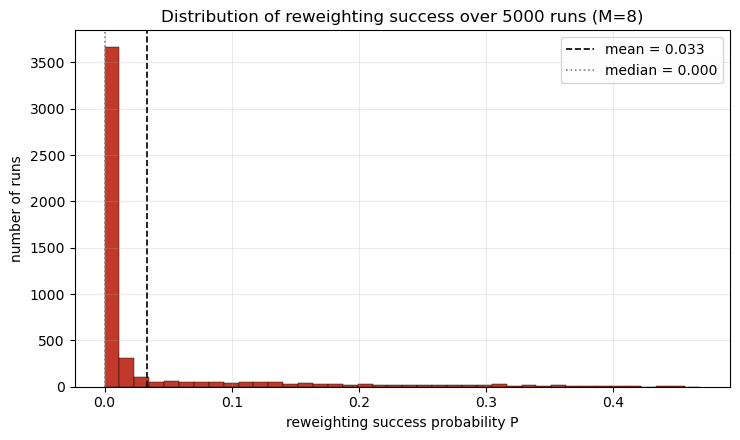

mean success = 0.0334 +/- 0.0011   (median 0.0001)


In [125]:
sigma, chunks = extract_row_weights(Y_small)
results = success_distribution(chunks, sigma, n_shots=5000, seed=0)
print(f"mean success = {results['mean']:.4f} +/- {results['sem']:.4f}   (median {results['median']:.4f})")


## Classical Pre-processing

  0%|          | 0/300 [00:00<?, ?it/s]

+0.008176785534 [best: +0.008176785534] :  37%|███▋      | 110/300 [00:01<00:02, 89.62it/s]


IPR 0.094962 -> 0.008177   (uniform floor 1/D = 0.007812)
flattened-state norm: 1.0
all gates unitary: OK
IPR dropped: True


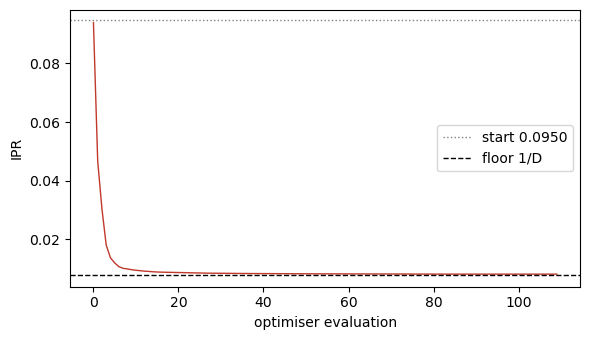

In [ ]:
mps, _ = build_initial_and_layer(Y_small, eps_init=0.0)     # fresh initial state
res = optimise_flatten_layer(mps, n_iter=300, eps_init=1e-2, seed=0)

# check 1: V is unitary, so the flattened state is still normalised
psi_flat = state_after_layer(res["layer"], mps)
print("flattened-state norm:", round(float(np.linalg.norm(psi_flat)), 10))   # expect 1.0
assert_layer_unitary(res["layer"])                          # SSO helper: all gates unitary
print("all gates unitary: OK")

# check 2: IPR actually dropped
print("IPR dropped:", res["ipr"] < res["ipr0"])

# check 3: convergence curve
import matplotlib.pyplot as plt
plt.figure(figsize=(6,3.5))
plt.plot(res["history"], color='#c0392b', lw=1)
plt.axhline(res["ipr0"], color='grey', ls=':',  lw=1, label=f"start {res['ipr0']:.4f}")
plt.axhline(1/mps.L and 1/2**mps.L, color='black', ls='--', lw=1, label=f"floor 1/D")
plt.xlabel("optimiser evaluation"); plt.ylabel("IPR"); plt.legend(); plt.tight_layout(); plt.show()


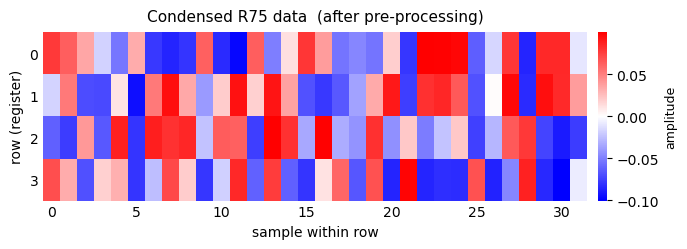

In [66]:
import matplotlib.pyplot as plt

img = Y_small_flat.real.T                              # (32, 8) -> (8, 32): 8 rows across, 32 samples wide

fig, ax = plt.subplots(figsize=(7, 2.6))
im = ax.imshow(img, aspect='auto', cmap='bwr',
               interpolation='nearest',
               vmin=img.min(), vmax=img.max())

ax.set_title('Condensed R75 data  (after pre-processing)',
             fontsize=11, pad=8)
ax.set_xlabel('sample within row')
ax.set_ylabel('row (register)')
ax.set_yticks(range(img.shape[0]))

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.outline.set_visible(False)
cbar.set_label('amplitude', fontsize=9)

for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)

plt.tight_layout()
plt.show()

[[ 0.0768033 +6.98719208e-02j  0.06293228-7.13042611e-02j
   0.03469318+9.16311815e-02j -0.0180653 -8.81240204e-02j
  -0.05402915-6.47869065e-02j  0.03183699+9.07872029e-02j
  -0.07841637-4.06457175e-02j -0.0858456 -3.64314036e-03j
  -0.07927038-4.95554509e-02j  0.06187651+1.48696899e-02j
  -0.08323915+2.58844540e-02j -0.09793251+1.10307828e-02j
   0.06288158+5.99864838e-02j -0.05086968-8.65075979e-02j
   0.01208744-9.06311799e-02j  0.0786206 -4.67079567e-02j
   0.03825756-8.21347729e-02j -0.05461419+5.40210109e-02j
  -0.04749811-6.12784119e-02j -0.05488429-1.95503522e-02j
   0.01862242+5.03749093e-02j -0.07906661-2.52725897e-02j
   0.0998847 -1.81369855e-02j  0.09881496+4.65564638e-02j
   0.09707348+4.30170590e-02j -0.06361104+8.89749045e-02j
  -0.01611111-7.86578757e-02j  0.07820501-4.00000326e-02j
  -0.08568262-2.32987020e-02j  0.08411984-3.36651767e-03j
   0.08385584+2.75534535e-02j -0.01036777+8.74643078e-02j]
 [-0.01737644-7.99275777e-02j  0.05194596+3.80560674e-02j
  -0.07003734

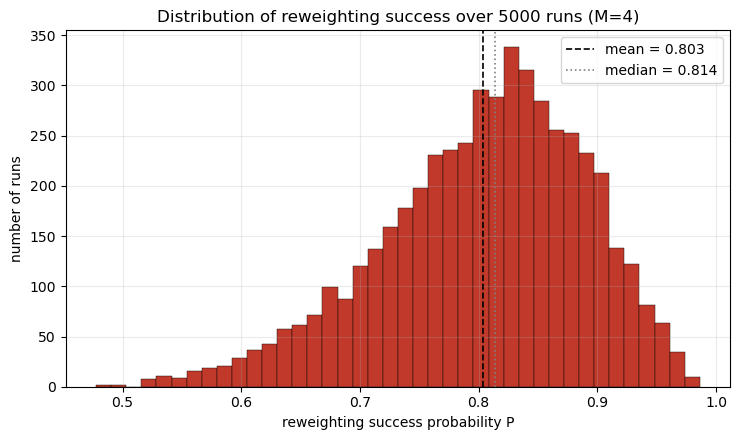

mean success = 0.8033 +/- 0.0012   (median 0.8142)


In [67]:
M, N = 4, 32                                  # registers, samples-per-row
Y_small_flat = psi_flat.reshape(M, N).T        # flat 256-vector -> (32, 8) image, Y_small convention
sigma_f, chunks_f = extract_row_weights(Y_small_flat)   # then use exactly like Y_small
results_flat = success_distribution(chunks_f, sigma_f, n_shots=5000, seed=0)
print(f"mean success = {results_flat['mean']:.4f} +/- {results_flat['sem']:.4f}   (median {results_flat['median']:.4f})")

## Results Comparision

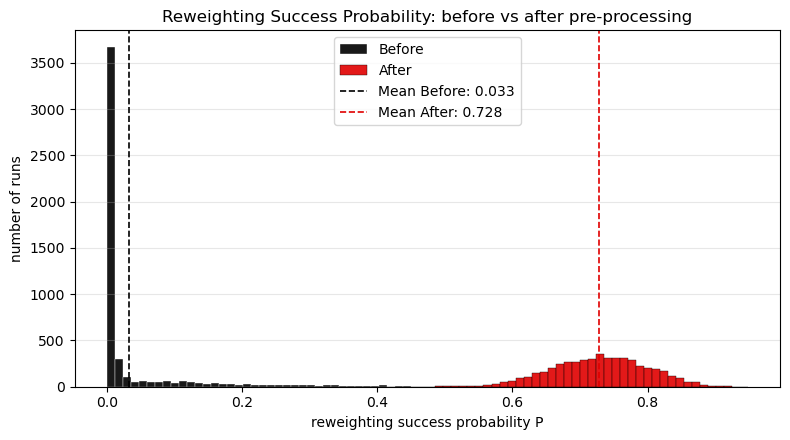

In [97]:
import matplotlib.pyplot as plt
import numpy as np


def plot_success_histograms(data_flat, data_base,
                            label_flat="After", label_base="Before", n_bins=80):
    """Overlay the reweighting-success distributions (flattened vs baseline) with means."""
    combined_min = min(np.min(data_flat), np.min(data_base))
    combined_max = max(np.max(data_flat), np.max(data_base))
    bins = np.linspace(combined_min, combined_max, n_bins + 1)

    mean_flat = np.mean(data_flat)
    mean_base = np.mean(data_base)

    plt.figure(figsize=(8, 4.5))
    plt.hist(data_base, bins=bins, alpha=0.9, color="black",   edgecolor="white", linewidth=0.3,
                 label=label_base)
    plt.hist(data_flat, bins=bins, alpha=0.9, color="#e00000", edgecolor="black", linewidth=0.3,
             label=label_flat)
    
    plt.axvline(mean_base, color="black",   linestyle="dashed", linewidth=1.2,
                label=f"Mean {label_base}: {mean_base:.3f}")
    plt.axvline(mean_flat, color="#e00000", linestyle="dashed", linewidth=1.2,
                label=f"Mean {label_flat}: {mean_flat:.3f}")
   

    plt.xlabel("reweighting success probability P")
    plt.ylabel("number of runs")
    plt.title(f"Reweighting Success Probability: before vs after pre-processing")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_success_histograms(results_flat["P"], results["P"])   # res_flat = CELL 27, res = CELL 20


# Sinogram Test case

Same as above, just running on a different data set (Jens's Sinogram file)

Y_sino shape: (32, 8)  complex: True


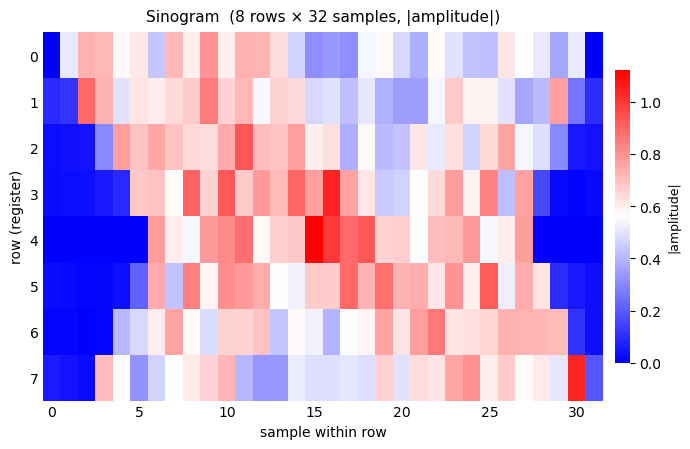

In [102]:
import numpy as np
import matplotlib.pyplot as plt

def load_sinogram(path="sinogram.txt"):
    """
    Load the 8x32 complex sinogram and return it in Y_small form: shape (32, 8),
    i.e. (samples, registers), so sinogram.T[i] is register i (length 32) --
    exactly the convention the rest of the pipeline expects.
    """
    with open(path) as f:
        rows = [[complex(tok) for tok in line.split()] for line in f if line.strip()]
    arr = np.array(rows)          # (8, 32): 8 rows/registers x 32 samples
    return arr.T                  # (32, 8): matches Y_small (samples, registers)

Y_sino = load_sinogram("sinogram.txt")
print("Y_sino shape:", Y_sino.shape, " complex:", np.iscomplexobj(Y_sino))

# --- display, same style as the Y_small plot (magnitude, since it's complex) ---
img = np.abs(Y_sino.T)                        # (8, 32): 8 rows across, 32 samples wide
fig, ax = plt.subplots(figsize=(7, 4.6))
im = ax.imshow(img, aspect='auto', cmap='bwr', interpolation='nearest',
               vmin=img.min(), vmax=img.max())
ax.set_title('Sinogram  (8 rows × 32 samples, |amplitude|)', fontsize=11, pad=8)
ax.set_xlabel('sample within row'); ax.set_ylabel('row (register)')
ax.set_yticks(range(img.shape[0]))
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.outline.set_visible(False); cbar.set_label('|amplitude|', fontsize=9)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
plt.tight_layout(); plt.show()


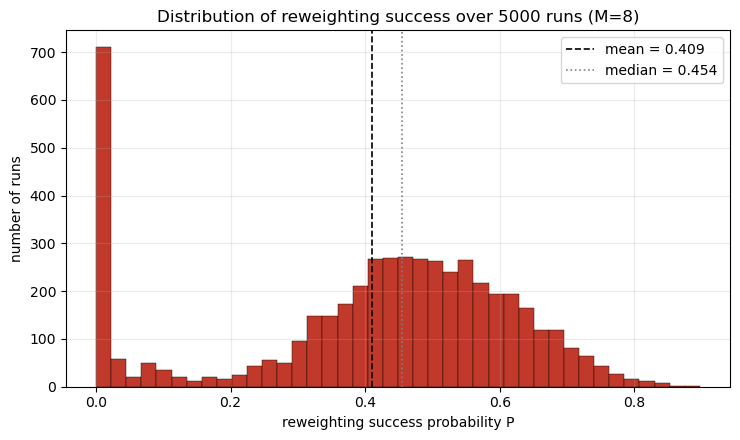

mean success = 0.4094 +/- 0.0031   (median 0.4539)


In [104]:
sigma, chunks = extract_row_weights(Y_sino)
results = success_distribution(chunks, sigma, n_shots=5000, seed=0)
print(f"mean success = {results['mean']:.4f} +/- {results['sem']:.4f}   (median {results['median']:.4f})")
 

+0.003984024445 [best: +0.003984024445] :  34%|███▎      | 101/300 [00:01<00:03, 61.69it/s]


IPR 0.005938 -> 0.003984   (uniform floor 1/D = 0.003906)
flattened-state norm: 1.0
all gates unitary: OK
IPR dropped: True


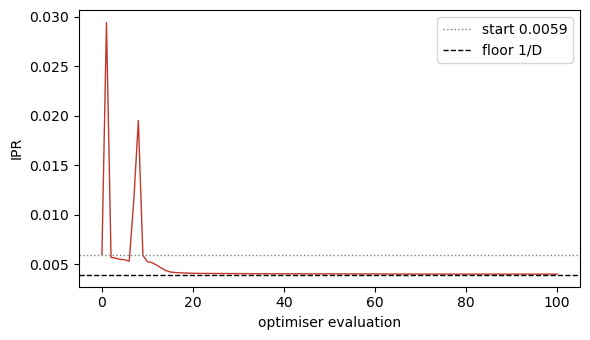

In [105]:
mps, _ = build_initial_and_layer(Y_sino, eps_init=0.0)     # fresh initial state
res = optimise_flatten_layer(mps, n_iter=300, eps_init=1e-2, seed=0)

# check 1: V is unitary, so the flattened state is still normalised
psi_flat = state_after_layer(res["layer"], mps)
print("flattened-state norm:", round(float(np.linalg.norm(psi_flat)), 10))   # expect 1.0
assert_layer_unitary(res["layer"])                          # SSO helper: all gates unitary
print("all gates unitary: OK")

# check 2: IPR actually dropped
print("IPR dropped:", res["ipr"] < res["ipr0"])

# check 3: convergence curve
import matplotlib.pyplot as plt
plt.figure(figsize=(6,3.5))
plt.plot(res["history"], color='#c0392b', lw=1)
plt.axhline(res["ipr0"], color='grey', ls=':',  lw=1, label=f"start {res['ipr0']:.4f}")
plt.axhline(1/mps.L and 1/2**mps.L, color='black', ls='--', lw=1, label=f"floor 1/D")
plt.xlabel("optimiser evaluation"); plt.ylabel("IPR"); plt.legend(); plt.tight_layout(); plt.show()


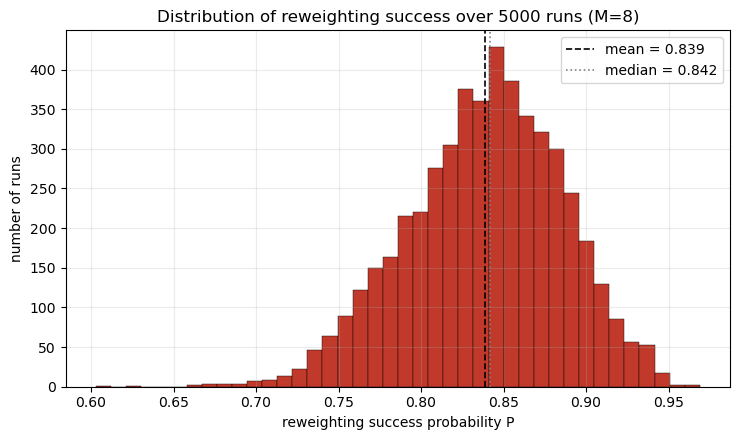

mean success = 0.8387 +/- 0.0007   (median 0.8419)


In [106]:
M, N = 8, 32                                  # registers, samples-per-row
Y_small_flat = psi_flat.reshape(M, N).T        # flat 256-vector -> (32, 8) image, Y_small convention
sigma_f, chunks_f = extract_row_weights(Y_small_flat)   # then use exactly like Y_small
results_flat = success_distribution(chunks_f, sigma_f, n_shots=5000, seed=0)
print(f"mean success = {results_flat['mean']:.4f} +/- {results_flat['sem']:.4f}   (median {results_flat['median']:.4f})")

In [21]:
import matplotlib.pyplot as plt
import numpy as np


def plot_success_histograms(data_flat, data_base,
                            label_flat="After", label_base="Before", n_bins=80):
    """Overlay the reweighting-success distributions (flattened vs baseline) with means."""
    combined_min = min(np.min(data_flat), np.min(data_base))
    combined_max = max(np.max(data_flat), np.max(data_base))
    bins = np.linspace(combined_min, combined_max, n_bins + 1)

    mean_flat = np.mean(data_flat)
    mean_base = np.mean(data_base)

    plt.figure(figsize=(8, 4.5))
    plt.hist(data_base, bins=bins, alpha=0.9, color="black",   edgecolor="white", linewidth=0.3,
                 label=label_base)
    plt.hist(data_flat, bins=bins, alpha=0.9, color="#e00000", edgecolor="black", linewidth=0.3,
             label=label_flat)
    
    plt.axvline(mean_base, color="black",   linestyle="dashed", linewidth=1.2,
                label=f"Mean {label_base}: {mean_base:.3f}")
    plt.axvline(mean_flat, color="#e00000", linestyle="dashed", linewidth=1.2,
                label=f"Mean {label_flat}: {mean_flat:.3f}")
   

    plt.xlabel("reweighting success probability P")
    plt.ylabel("number of runs")
    plt.title(f"Reweighting Success Probability: before vs after pre-processing")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_success_histograms(results_flat["P"], results["P"])   # res_flat = CELL 27, res = CELL 20


NameError: name 'results_flat' is not defined

# Other test States (full sino and R75)

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def _display_state(Y2d, title):
    """imshow |amplitude| of a (samples, registers) state, 8-rows-across style."""
    img = np.abs(np.asarray(Y2d).T)                 # (registers, samples)
    n_rows = img.shape[0]

    fig, ax = plt.subplots(figsize=(12, 4))
    im = ax.imshow(img, aspect='auto', cmap='bwr', interpolation='nearest',
                   vmin=img.min(), vmax=img.max())
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_xlabel('sample within row'); ax.set_ylabel('row (register)')

    if n_rows <= 16:
        ax.set_yticks(range(n_rows))                # label every row when there are few
    else:
        ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=8, integer=True))  # ~8 ticks for many

    cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cbar.outline.set_visible(False); cbar.set_label('|amplitude|', fontsize=9)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
    plt.tight_layout(); plt.show()



def run_flatten_pipeline(Y, name="state", n_shots=5000, n_iter=300, seed=0):
    """
    Full classical-preprocessing demo for one (samples, registers) state Y
    (shape (32, 8): Y_small or the sinogram). Produces, in order:
      1. the target state
      2. reweighting-success histogram BEFORE flattening
      3. the IPR-reduction (optimiser convergence) curve
      4. the flattened state
      5. reweighting-success histogram AFTER flattening
      6. the before-vs-after comparison histogram
    Returns a dict with all intermediates.
    """
    Y = np.asarray(Y)
    N, M = Y.shape                       # N samples/row, M registers  (32, 8)

    # 1) target state
    _display_state(Y, f"{name} — target state (|amplitude|)")

    # 2) reweighting success BEFORE flattening
    sigma0, chunks0 = extract_row_weights(Y)
    print(f"[{name}] baseline reweighting success:")
    res_before = success_distribution(chunks0, sigma0, n_shots=n_shots, seed=seed, plot=True)

    # 3) flatten + IPR-reduction curve
    mps, _ = build_initial_and_layer(Y, eps_init=0.0)
    flat = optimise_flatten_layer(mps, n_iter=n_iter, eps_init=1e-2, seed=seed, verbose=False)
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    ax.plot(flat["history"], color='#c0392b', lw=1)
    ax.axhline(flat["ipr0"], color='grey',  ls=':',  lw=1, label=f"start IPR {flat['ipr0']:.4f}")
    ax.axhline(flat["ipr"],  color='black', ls='--', lw=1, label=f"final IPR {flat['ipr']:.4f}")
    ax.axhline(1/2**mps.L,   color='blue',  ls='--', lw=0.8, label=f"floor 1/D {1/2**mps.L:.4f}")
    ax.set_xlabel("optimiser evaluation"); ax.set_ylabel("IPR")
    ax.set_title(f"{name} — IPR reduction (flattening)"); ax.legend()
    plt.tight_layout(); plt.show()

    # 4) flattened state
    psi_flat = flat["psi_flat"]
    Y_flat = psi_flat.reshape(M, N).T           # back to (samples, registers)
    _display_state(Y_flat, f"{name} — flattened state (|amplitude|)")

    # 5) reweighting success AFTER flattening
    sigmaF, chunksF = extract_row_weights(Y_flat)
    print(f"[{name}] flattened reweighting success:")
    res_after = success_distribution(chunksF, sigmaF, n_shots=n_shots, seed=seed, plot=True)

    # 6) before vs after
    plot_success_histograms(res_after["P"], res_before["P"],
                            label_flat="Flattened", label_base="Baseline")

    print(f"[{name}]  success {res_before['mean']:.4f} -> {res_after['mean']:.4f}  "
          f"({res_after['mean']/res_before['mean']:.1f}x)   "
          f"IPR {flat['ipr0']:.4f} -> {flat['ipr']:.4f}")

    return {"Y": Y, "Y_flat": Y_flat, "psi_flat": psi_flat, "layer": flat["layer"],
            "res_before": res_before, "res_after": res_after,
            "ipr0": flat["ipr0"], "ipr": flat["ipr"]}


In [11]:
import numpy as np, pandas as pd
from skimage.transform import resize

df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
Y_big = resize(df.to_numpy(), (128,256), anti_aliasing=True)   # (rowlen=32, n_rows=8)
Y = Y_big / np.linalg.norm(Y_small)
print(Y.shape, "-> N_ROWS =", Y.shape[1], " row length =", Y.shape[0])


(128, 256) -> N_ROWS = 256  row length = 128


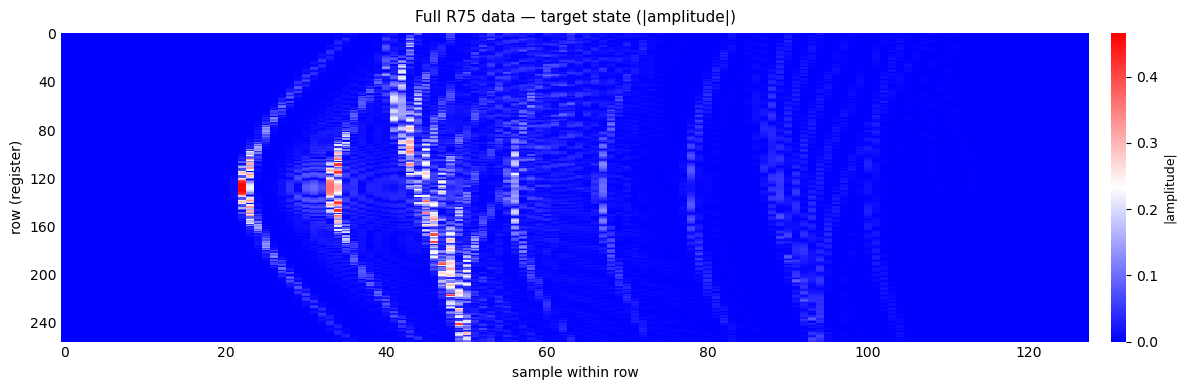

[[-9.27788135e-18 -6.88619096e-18  7.78497877e-18 ...  4.32453528e-18
  -1.05831145e-17  6.17589978e-18]
 [-9.27788135e-18 -6.88619096e-18  7.78497877e-18 ...  4.32453528e-18
  -1.05831145e-17  6.17589978e-18]
 [-1.08853959e-18  2.02015465e-18  4.42302529e-18 ...  1.00954062e-17
   2.90927793e-18  6.55776866e-19]
 ...
 [-1.15909037e-18  5.21449145e-18  6.77018384e-18 ...  3.06326424e-04
   1.40694685e-05 -1.45199918e-07]
 [-2.46123974e-18  3.68407283e-18  2.60895195e-18 ... -1.52730921e-04
   1.61210906e-05  1.47834490e-07]
 [-2.46123974e-18  3.68407283e-18  2.60895195e-18 ... -1.52730921e-04
   1.61210906e-05  1.47834490e-07]]
[Full R75 data] baseline reweighting success:


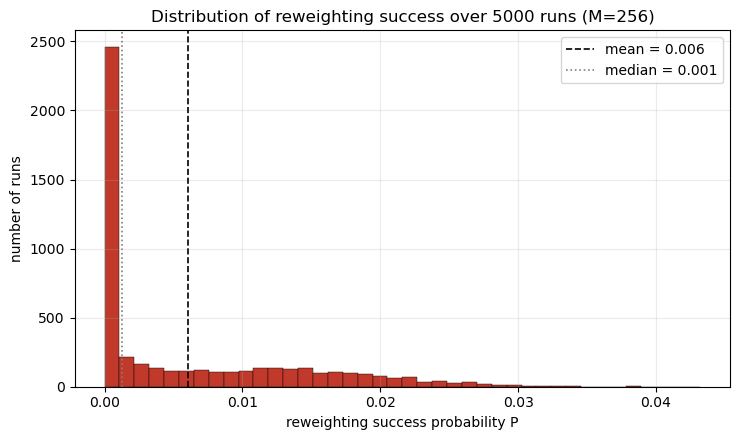

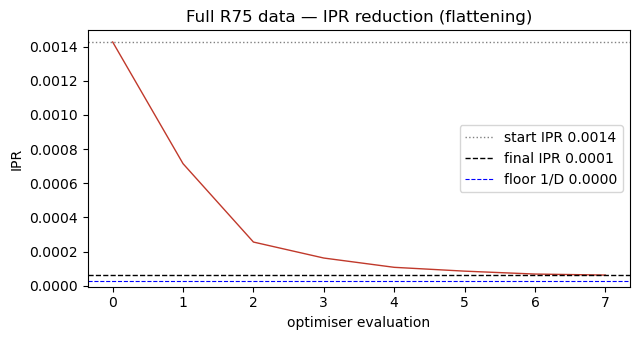

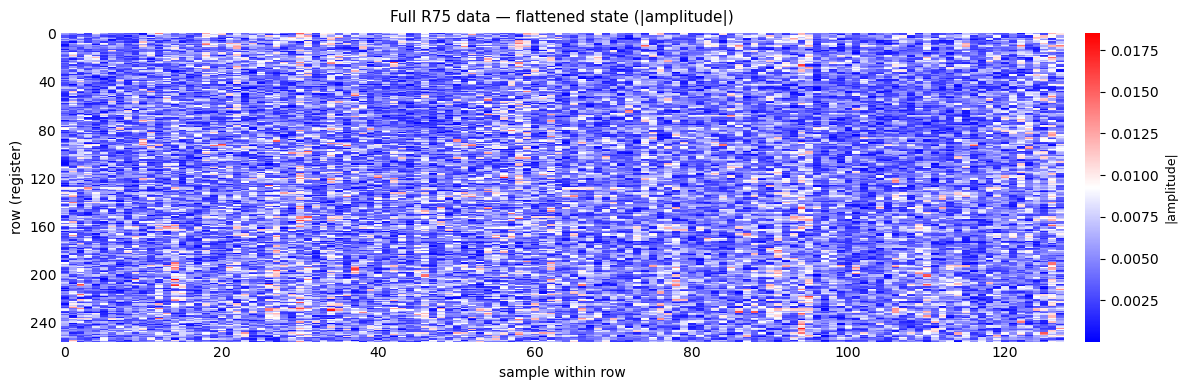

[[-4.41978920e-03+0.00373697j  2.81209536e-03-0.00374125j
  -3.49933147e-03-0.00658255j ... -2.44829704e-03+0.00066807j
   8.41871718e-03+0.00857691j -9.70247956e-03-0.00317834j]
 [ 4.12117095e-03+0.00295056j -3.82601198e-03-0.00092156j
  -1.94876360e-03+0.00106345j ...  1.20799434e-04-0.00258273j
   6.51520437e-03+0.00622297j -9.61521162e-03-0.00424864j]
 [-1.70588446e-03-0.00239484j -8.45600933e-04-0.00190305j
  -3.92161387e-03+0.00042053j ... -4.33154438e-03-0.01087389j
   1.84041532e-03-0.00927753j -9.82985913e-04+0.0057406j ]
 ...
 [ 1.78729558e-03+0.00145365j -2.22061572e-03+0.00374097j
  -1.81755090e-05+0.00284417j ... -7.45580293e-04+0.00283333j
  -6.86768687e-04+0.00279406j  1.24632839e-03+0.00038702j]
 [-1.47010258e-04+0.00239733j -1.21319593e-02+0.0014208j
   2.43777959e-04+0.00537339j ...  6.08653904e-04-0.00021538j
  -5.08145868e-03-0.00272229j  2.38294520e-04+0.00642742j]
 [ 9.51239358e-05-0.00261423j  6.33539376e-03+0.00737651j
  -1.08348495e-03-0.00181606j ... -2.110644

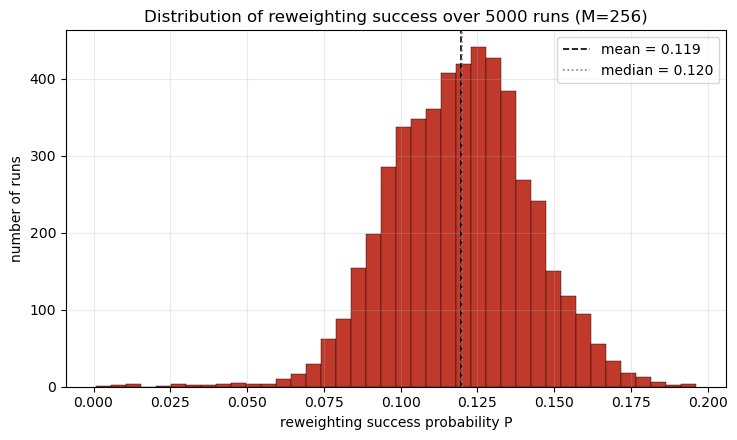

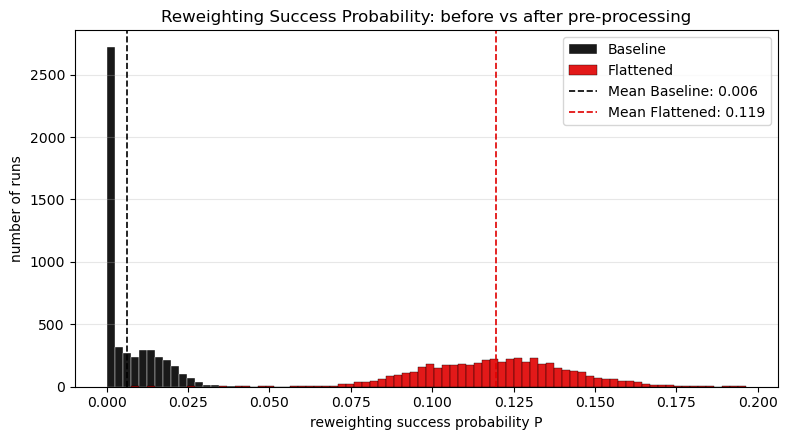

[Full R75 data]  success 0.0061 -> 0.1195  (19.7x)   IPR 0.0014 -> 0.0001


In [23]:
result = run_flatten_pipeline(Y_big, name="Full R75 data")


In [145]:
Y_sino_big = load_sinogram("sinogram_full.txt")

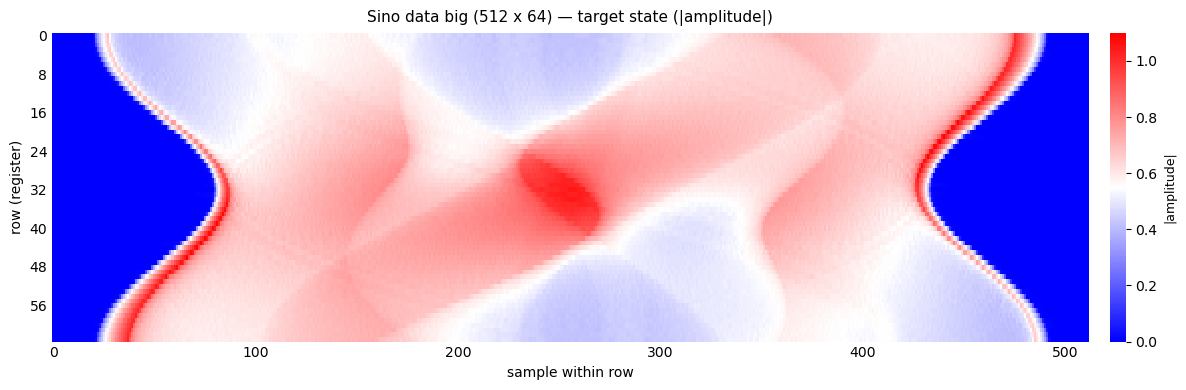

[Sino data big (512 x 64)] baseline reweighting success:


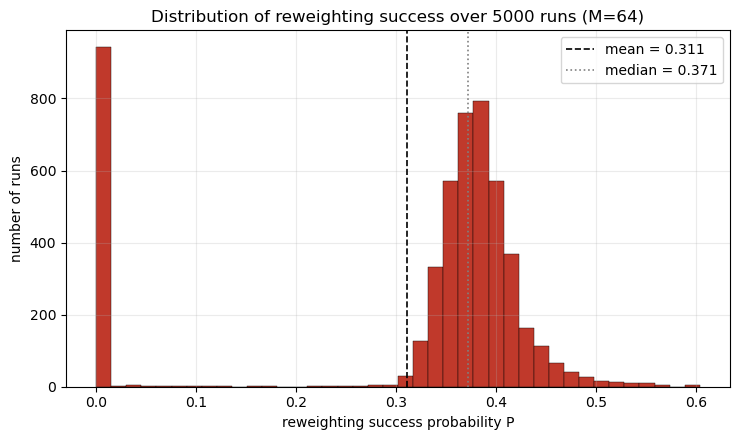

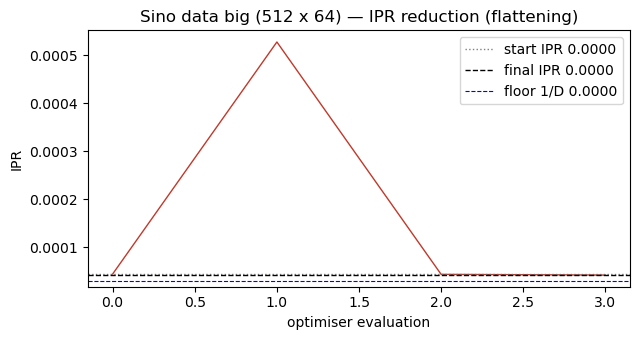

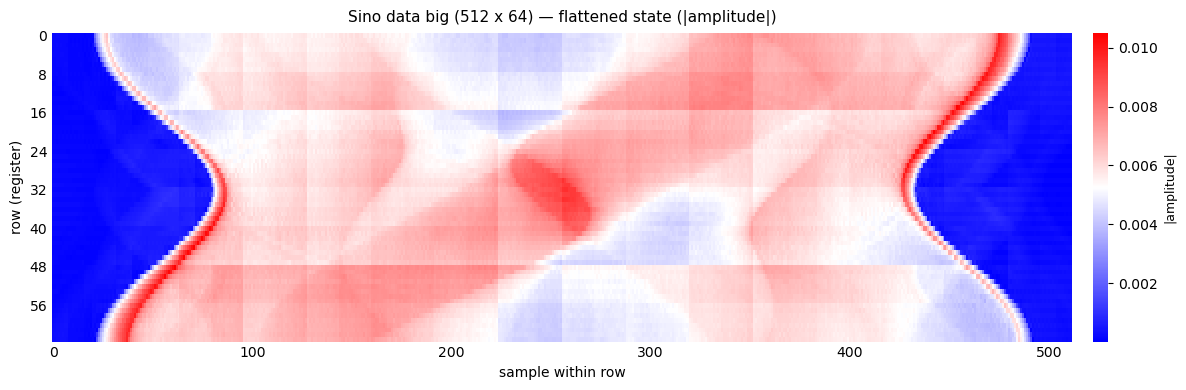

[Sino data big (512 x 64)] flattened reweighting success:


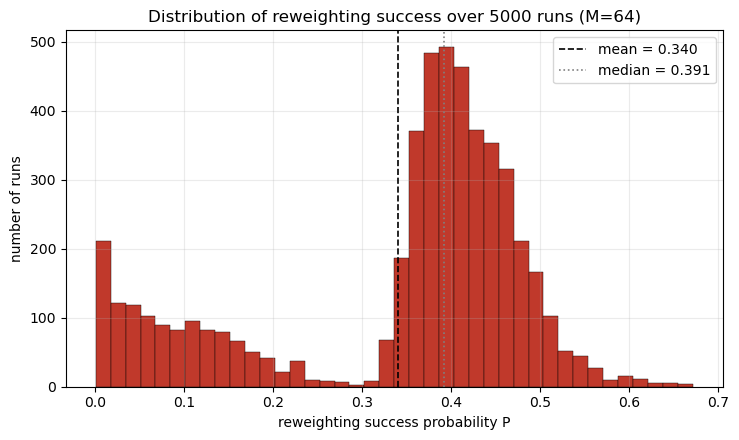

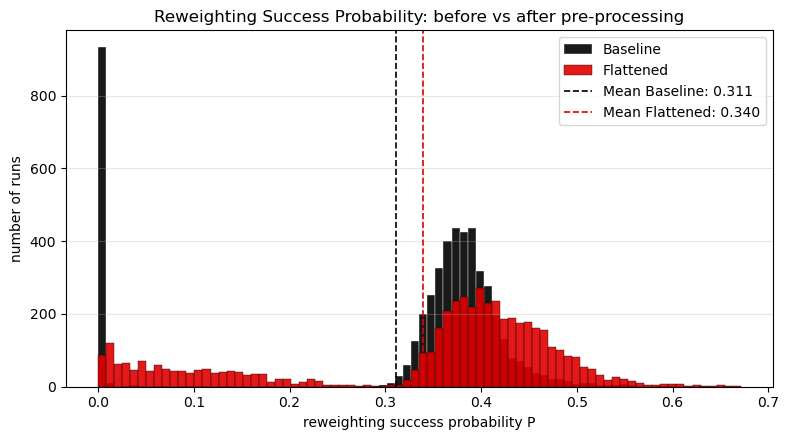

[Sino data big (512 x 64)]  success 0.3109 -> 0.3398  (1.1x)   IPR 0.0000 -> 0.0000


In [148]:
result = run_flatten_pipeline(Y_sino_big, name="Sino data big (512 x 64)")

# New Storage only anstatz

In [14]:
import numpy as np, torch, quimb.tensor as qtn
from quimb.tensor import PTensor

def make_chi2_staircase_storage(n_total, n_index, eps=0.0, seed=None):
    """chi=2 SU(4) staircase acting ONLY on storage qubits [n_index .. n_total-1].
       Index qubits [0 .. n_index-1] pass through as identity (tagged 'ID')."""
    if seed is not None: torch.manual_seed(seed)
    def _init(m):
        p = torch.zeros(m, dtype=torch.float64)
        if eps > 0: p = p + eps*torch.randn(m, dtype=torch.float64)
        return p.requires_grad_(True)
    T = []
    for j in range(n_index):                                     # index qubits: identity (constant)
        T.append(qtn.Tensor(torch.eye(2, dtype=torch.complex128), inds=(f"k{j}", f"b{j}"), tags={"ID"}))
    s0 = n_index; nS = n_total - n_index                         # storage staircase
    kf = bf = s0; cc = 0
    T.append(PTensor(su4_matrix, _init(15), inds=(f"k{kf}", f"k{kf+1}", f"b{bf}", f"c{cc}"), tags={"SU4"}))
    kf += 2; bf += 1; prev = f"c{cc}"; cc += 1
    for _ in range(nS - 2):
        T.append(PTensor(su4_matrix, _init(15), inds=(prev, f"k{kf}", f"b{bf}", f"c{cc}"), tags={"SU4"}))
        kf += 1; bf += 1; prev = f"c{cc}"; cc += 1
    T.append(PTensor(su2_matrix, _init(3), inds=(prev, f"b{bf}"), tags={"SU2"}))
    return qtn.TensorNetwork(T)


def build_initial_and_storage_layer(Y, eps_init=0.0, seed=0):
    """Like build_initial_and_layer, but V acts ONLY on the storage (within-row) qubits.
       Convention: Y is (samples, registers); index qubits are the top log2(#registers),
       storage qubits the bottom log2(#samples). Returns (mps, layer, n_index)."""
    N, M = Y.shape                                               # samples, registers
    v = np.asarray(Y, dtype=np.complex128).T.flatten(); v /= np.linalg.norm(v)
    n = int(round(np.log2(v.size)))
    n_index = int(round(np.log2(M)))                            # register-index qubits (top)
    mps = qtn.MatrixProductState.from_dense(v.reshape([2]*n), dims=[2]*n)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    layer = make_chi2_staircase_storage(n, n_index, eps=eps_init, seed=seed)
    print(f"index qubits 0..{n_index-1} (identity) | storage qubits {n_index}..{n-1} (staircase)")
    return mps, layer, n_index


def optimise_storage_flatten_layer(mps, n_index, n_iter=300, eps_init=1e-2, seed=0, verbose=True):
    """Minimise IPR over a storage-only staircase. The index identity tensors are held
       CONSTANT (constant_tags=['ID']) so the optimiser cannot act on the index qubits."""
    n = mps.L
    def ipr_after(op):
        psi = dense_state_from_op_mps(op, mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj()*psi).sum().real)
        return (torch.abs(psi)**4).sum()

    id_layer = make_chi2_staircase_storage(n, n_index, eps=0.0)
    ipr0 = float(ipr_after(id_layer))
    layer = make_chi2_staircase_storage(n, n_index, eps=eps_init, seed=seed)
    best = {"val": float("inf"), "params": None}
    def loss(op, init_tn):
        val = ipr_after(op); s = float(val.detach())
        if s < best["val"]:
            best["val"] = s
            best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
        return val

    tnopt = qtn.TNOptimizer(layer, loss, loss_constants={"init_tn": mps},
                            constant_tags=["ID"],                  # <-- CRUCIAL: index stays identity
                            optimizer="l-bfgs-b", autodiff_backend="torch", progbar=verbose)
    tnopt.optimize(n=n_iter)

    if best["params"] is not None and best["val"] < ipr0:
        layer.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        final, iprf = layer, best["val"]
    else:
        final, iprf = id_layer, ipr0
    psi_flat = dense_state_from_op_mps(final, mps).detach().reshape(-1)
    psi_flat = (psi_flat / torch.sqrt((psi_flat.conj()*psi_flat).sum().real)).cpu().numpy()
    if verbose:
        print(f"IPR {ipr0:.6f} -> {iprf:.6f}  (storage-only; index qubits untouched)")
    return {"layer": final, "psi_flat": psi_flat, "ipr0": ipr0, "ipr": iprf}


In [15]:
mps_s, _, n_index = build_initial_and_storage_layer(Y_full, eps_init=0.0)   # prints qubit split
res_s = optimise_storage_flatten_layer(mps_s, n_index, n_iter=300, seed=0)
Y_full_storeflat = res_s["psi_flat"].reshape(Y_full.shape[1], Y_full.shape[0]).T


index qubits 0..6 (identity) | storage qubits 7..14 (staircase)


+0.000090258742 [best: +0.000090258742] :   2%|▏         | 6/300 [00:00<00:09, 29.86it/s]


IPR 0.001557 -> 0.000090  (storage-only; index qubits untouched)


In [16]:
def sigma_of(vec, M, N): 
    r = vec.reshape(M, N); rn = np.linalg.norm(r, axis=1); return rn/np.linalg.norm(rn)
M, N = Y_full.shape[1], Y_full.shape[0]
s0 = sigma_of(Y_full.T.flatten(), M, N)
s1 = sigma_of(res_s["psi_flat"], M, N)
print("sigma unchanged (storage-only):", np.allclose(s0, s1, atol=1e-8))   # MUST be True


sigma unchanged (storage-only): True


In [22]:
import numpy as np, torch, quimb.tensor as qtn, matplotlib.pyplot as plt

def _display_state(Y2d, title):
    img = np.abs(np.asarray(Y2d).T); nr = img.shape[0]
    fig, ax = plt.subplots(figsize=(12, 4))
    im = ax.imshow(img, aspect='auto', cmap='magma', interpolation='nearest', vmin=img.min(), vmax=img.max())
    ax.set_title(title, fontsize=11, pad=8); ax.set_xlabel('sample within row'); ax.set_ylabel('row (register)')
    if nr <= 16: ax.set_yticks(range(nr))
    else: ax.yaxis.set_major_locator(plt.MaxNLocator(8, integer=True))
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.outline.set_visible(False); cb.set_label('|amplitude|', fontsize=9)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0); plt.tight_layout(); plt.show()


def run_storage_flatten_pipeline(Y, name="state", n_shots=3000, n_iter=300, seed=0):
    """Full storage-only flatten analysis, printing every graph:
       target state -> ansatz diagram -> baseline success -> IPR reduction
       -> flattened state -> flattened success -> before/after overlay."""
    Y = np.asarray(Y); N, M = Y.shape
    n = int(round(np.log2(M*N))); n_index = int(round(np.log2(M)))

    # 1) target state
    _display_state(Y, f"{name} — target state (|amplitude|)")

    # 2) build MPS + identity-init storage ansatz, and DRAW the ansatz
    v = Y.astype(np.complex128).T.flatten(); v /= np.linalg.norm(v)
    mps = qtn.MatrixProductState.from_dense(v.reshape([2]*n), dims=[2]*n)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    id_layer = make_chi2_staircase_storage(n, n_index, eps=0.0)
    print(f"ANSATZ: index qubits 0..{n_index-1} = IDENTITY (untouched) | "
          f"storage qubits {n_index}..{n-1} = chi=2 SU(4) staircase")
    try:
        id_layer.draw(color=["ID", "SU4", "SU2"], show_tags=True, figsize=(6, 6))
    except Exception as e:
        print("  (ansatz draw skipped:", e, ")")

    # 3) baseline reweighting success
    sigma0, chunks0 = extract_row_weights(Y)
    print(f"[{name}] baseline reweighting success:")
    res_before = success_distribution(chunks0, sigma0, n_shots=n_shots, seed=seed, plot=True)

    # 4) optimise the storage-only flatten (index held constant), with IPR curve
    def ipr_after(op):
        psi = dense_state_from_op_mps(op, mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj()*psi).sum().real)
        return (torch.abs(psi)**4).sum()
    ipr0 = float(ipr_after(id_layer))
    layer = make_chi2_staircase_storage(n, n_index, eps=1e-2, seed=seed)
    hist = []; best = {"v": float("inf"), "p": None}
    def loss(op, init_tn):
        val = ipr_after(op); s = float(val.detach()); hist.append(s)
        if s < best["v"]:
            best["v"] = s; best["p"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
        return val
    qtn.TNOptimizer(layer, loss, loss_constants={"init_tn": mps}, constant_tags=["ID"],
                    optimizer="l-bfgs-b", autodiff_backend="torch", progbar=False).optimize(n=n_iter)
    if best["p"] is not None and best["v"] < ipr0:
        layer.set_params({k: torch.as_tensor(vv) for k, vv in best["p"].items()}); final, iprf = layer, best["v"]
    else:
        final, iprf = id_layer, ipr0
    psi_flat = dense_state_from_op_mps(final, mps).detach().reshape(-1).cpu().numpy(); psi_flat /= np.linalg.norm(psi_flat)

    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    ax.plot(hist, color='#c0392b', lw=1)
    ax.axhline(ipr0, color='grey',  ls=':',  lw=1, label=f"start {ipr0:.2e}")
    ax.axhline(iprf, color='black', ls='--', lw=1, label=f"final {iprf:.2e}")
    ax.axhline(1/2**n, color='blue', ls='--', lw=.8, label=f"floor {1/2**n:.2e}")
    ax.set_xlabel("optimiser evaluation"); ax.set_ylabel("IPR")
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    ax.set_title(f"{name} — storage-only IPR reduction"); ax.legend(); plt.tight_layout(); plt.show()

    # 5) flattened state
    Y_flat = psi_flat.reshape(M, N).T
    _display_state(Y_flat, f"{name} — storage-flattened state (|amplitude|)")

    # 6) flattened reweighting success
    sigmaF, chunksF = extract_row_weights(Y_flat)
    print(f"[{name}] storage-flattened reweighting success:")
    res_after = success_distribution(chunksF, sigmaF, n_shots=n_shots, seed=seed, plot=True)

    # 7) before/after overlay + sigma check
    plot_success_histograms(res_after["P"], res_before["P"], label_flat="Storage-flattened", label_base="Baseline")
    print(f"[{name}]  success {res_before['mean']:.4f} -> {res_after['mean']:.4f} "
          f"({res_after['mean']/res_before['mean']:.2f}x)  |  IPR {ipr0:.2e} -> {iprf:.2e}")
    print(f"sigma unchanged (storage-only confirmed): {np.allclose(sigma0, sigmaF, atol=1e-8)}")

    return {"Y": Y, "Y_flat": Y_flat, "psi_flat": psi_flat, "layer": final,
            "res_before": res_before, "res_after": res_after, "ipr0": ipr0, "ipr": iprf}


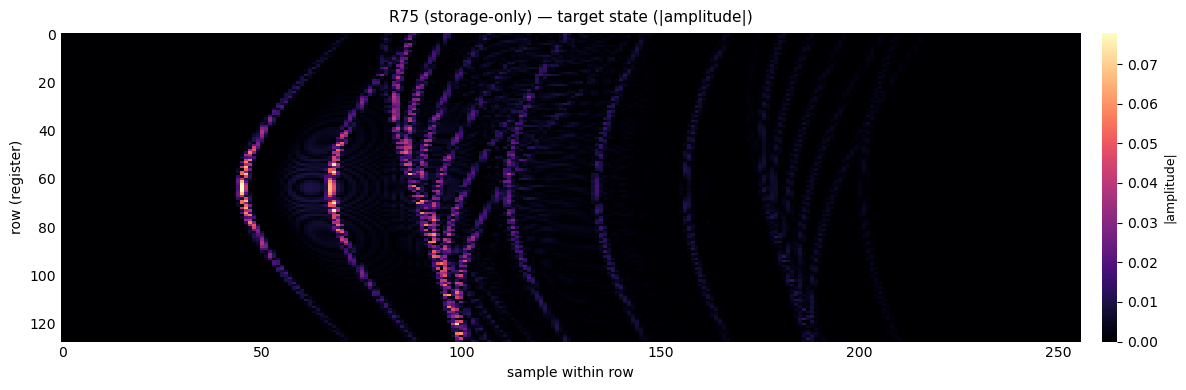

ANSATZ: index qubits 0..6 = IDENTITY (untouched) | storage qubits 7..14 = chi=2 SU(4) staircase


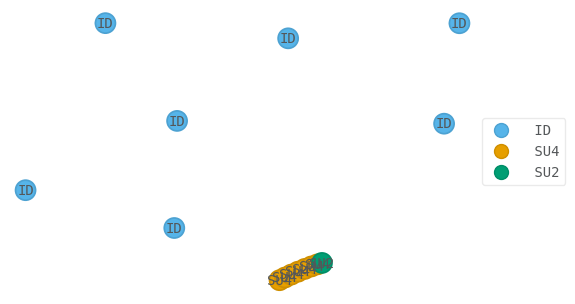

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 (storage-only)] baseline reweighting success:


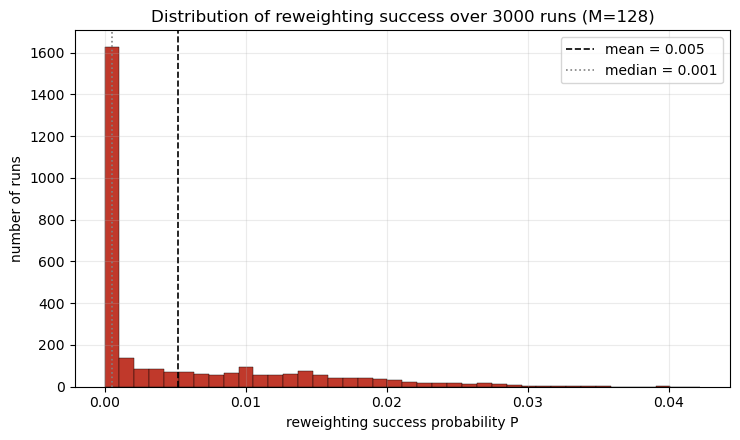

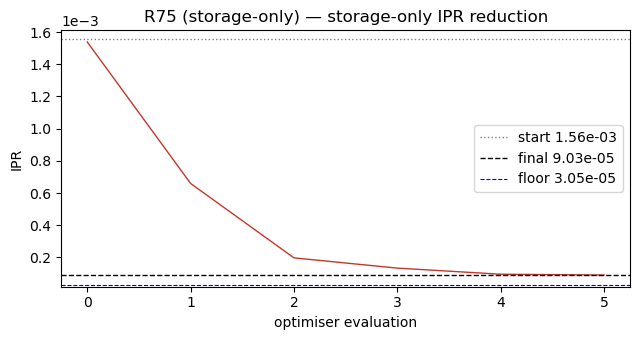

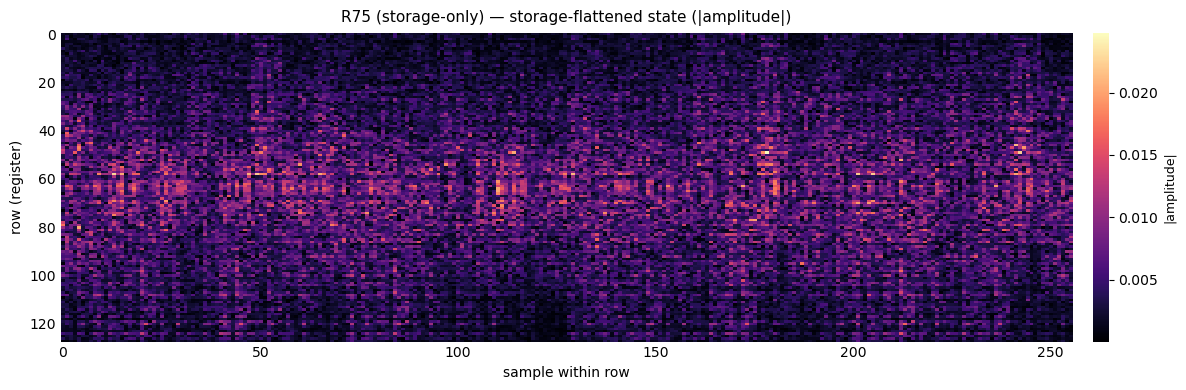

[[ 9.81909298e-04-1.24271557e-03j  9.00554876e-04+6.69199789e-04j
   7.37588052e-04+9.26139993e-04j ...  1.53112191e-03+9.13523890e-04j
  -1.53229839e-03-1.12809109e-03j -2.85148568e-05+1.44686405e-03j]
 [-1.03837091e-03-2.56863875e-04j -2.80481106e-03+2.14389215e-03j
  -3.97572135e-04-1.77330028e-04j ... -5.10166666e-04-2.01467366e-04j
   6.82510950e-04+4.53467802e-04j -3.03227136e-04-9.13768010e-04j]
 [-2.26106510e-04+1.10339263e-03j  4.27045909e-03-3.18082629e-03j
  -7.13803072e-04+1.12941089e-03j ... -1.73096261e-04-5.60177692e-04j
   1.54422727e-03+5.25144384e-04j  1.11393188e-03-5.64968766e-04j]
 ...
 [ 8.86778919e-04+6.70076199e-04j  2.24673920e-03+1.16018876e-03j
  -1.51922180e-04+3.06656758e-03j ... -2.17273495e-03+1.11940245e-03j
   8.80157354e-04+5.64500191e-04j -1.08623098e-04-1.91487950e-03j]
 [-1.33291881e-03+3.41922733e-03j -3.89055366e-04-1.72519661e-03j
  -2.93300669e-03-4.97348961e-04j ...  1.70805444e-03-5.72346986e-04j
  -2.16712265e-04-1.26644648e-03j -1.38186348e-

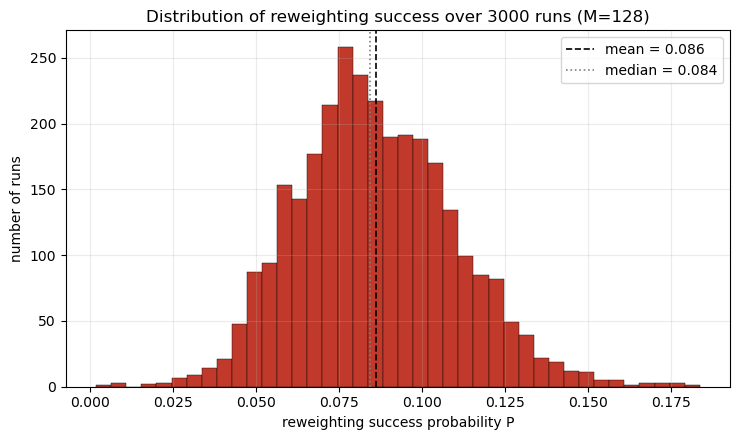

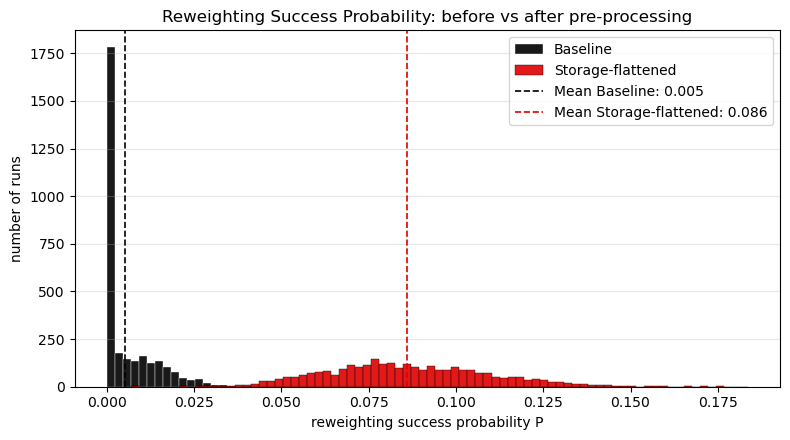

[R75 (storage-only)]  success 0.0052 -> 0.0860 (16.44x)  |  IPR 1.56e-03 -> 9.03e-05
sigma unchanged (storage-only confirmed): True


In [23]:
result_store = run_storage_flatten_pipeline(Y_full, name="R75 (storage-only)")


[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[[ 9.81909298e-04-1.24271557e-03j  9.00554876e-04+6.69199789e-04j
   7.37588052e-04+9.26139993e-04j ...  1.53112191e-03+9.13523890e-04j
  -1.53229839e-03-1.12809109e-03j -2.85148568e-05+1.44686405e-03j]
 [-1.03837091e-03-2.56863875e-04j -2.80481106e-03+2.14389215e-03j
  -3.97572135e-04-1.77330028e-04j ... -5.10166666e-04-2.01467366e-04j
   6.82510950e-04+4.53467

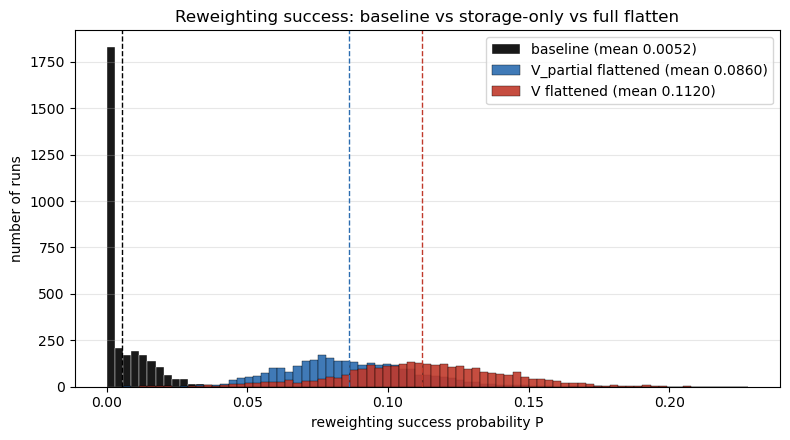

In [33]:
import numpy as np, matplotlib.pyplot as plt

def summarize(Ystate, label, n_shots=3000):
    sig, chk = extract_row_weights(Ystate)
    res = success_distribution(chk, sig, n_shots=n_shots, seed=0, plot=False)
    flat = np.asarray(Ystate).ravel(); flat = flat/np.linalg.norm(flat)
    return res["P"], {"label": label, "mean": res["mean"],
                      "sigma_spread": sig.max()/sig.min(),
                      "ipr": float(np.sum(np.abs(flat)**4))}

P_base, s_base = summarize(Y_full,           "baseline")
P_stor, s_stor = summarize(Y_full_storeflat, "storage-flat")
P_full, s_full = summarize(Y_full_flat,      "full-flat")

print(f"{'ansatz':14s} {'IPR':>10s} {'sigma spread':>13s} {'mean success':>13s}")
for s in (s_base, s_stor, s_full):
    print(f"{s['label']:14s} {s['ipr']:>10.2e} {s['sigma_spread']:>13.2f} {s['mean']:>13.4f}")

lo = min(P_base.min(), P_stor.min(), P_full.min()); hi = max(P_base.max(), P_stor.max(), P_full.max())
bins = np.linspace(lo, hi, 80)

plt.figure(figsize=(8, 4.5))
plt.hist(P_base, bins=bins, alpha=0.9, color="black",   edgecolor="white", lw=0.3, label=f"baseline (mean {s_base['mean']:.4f})")
plt.hist(P_stor, bins=bins, alpha=0.9, color="#2b6cb0", edgecolor="black", lw=0.3, label=f"V_partial flattened (mean {s_stor['mean']:.4f})")
plt.hist(P_full, bins=bins, alpha=0.9, color="#c0392b", edgecolor="black", lw=0.3, label=f"V flattened (mean {s_full['mean']:.4f})")
plt.axvline(s_base['mean'], color="black",   ls="--", lw=1.0)
plt.axvline(s_stor['mean'], color="#2b6cb0", ls="--", lw=1.0)
plt.axvline(s_full['mean'], color="#c0392b", ls="--", lw=1.0)

plt.xlabel("reweighting success probability P"); plt.ylabel("number of runs")
plt.title("Reweighting success: baseline vs storage-only vs full flatten")
plt.legend(); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()


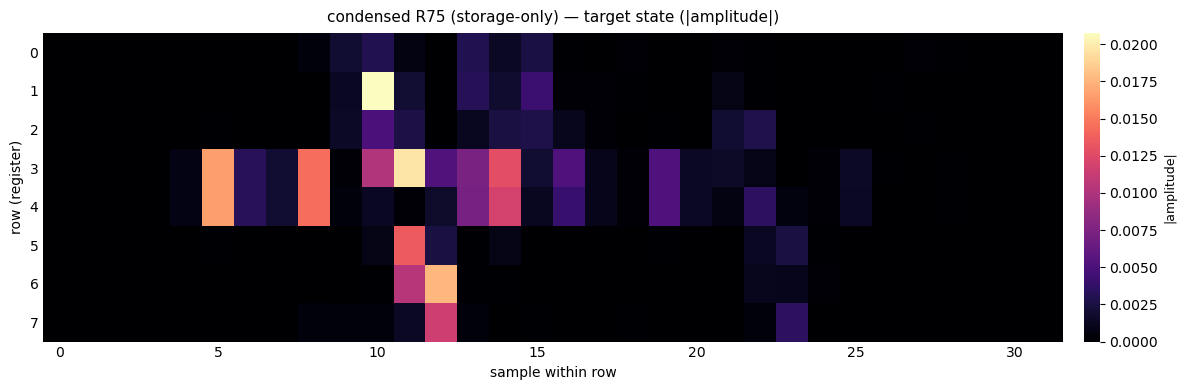

ANSATZ: index qubits 0..2 = IDENTITY (untouched) | storage qubits 3..7 = chi=2 SU(4) staircase


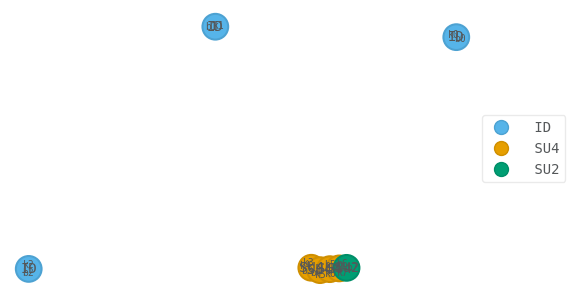

[[ 1.36542964e-19 -3.54699840e-19  1.21925135e-20  6.65066191e-15
  -2.28617031e-11 -1.83254366e-08 -1.80262132e-07  6.80490804e-06
   4.57849745e-04 -1.91643257e-03 -2.95708471e-03 -6.88424704e-04
   7.40541433e-05 -2.96653170e-03 -1.43915478e-03 -2.57972596e-03
  -1.40011040e-04  4.92727777e-05  2.35259400e-04  2.17916309e-05
  -3.71907556e-05 -3.02665641e-04  1.25624851e-04  1.05998984e-05
  -1.99795122e-05 -1.82618120e-05  1.77501226e-05 -2.98697869e-04
  -1.19095160e-04 -1.09496625e-06  1.99903584e-08  2.84762793e-12]
 [ 2.06140462e-19 -2.57464046e-19 -9.33421039e-19  1.54179610e-13
  -1.51798206e-08 -1.11972465e-06 -7.81425073e-06 -4.76218130e-07
  -3.87690053e-06  1.36038630e-03  2.07473477e-02  1.95931414e-03
   3.70953475e-05 -3.17797327e-03 -1.83523923e-03 -4.13744731e-03
   2.04251642e-04  2.36252105e-04  1.45159252e-04  1.01690100e-06
   4.82805763e-05  8.24403744e-04  1.21425875e-04 -3.10728999e-06
  -2.48415598e-06  2.29188212e-06  1.39354971e-04 -4.36439923e-05
  -7.3482

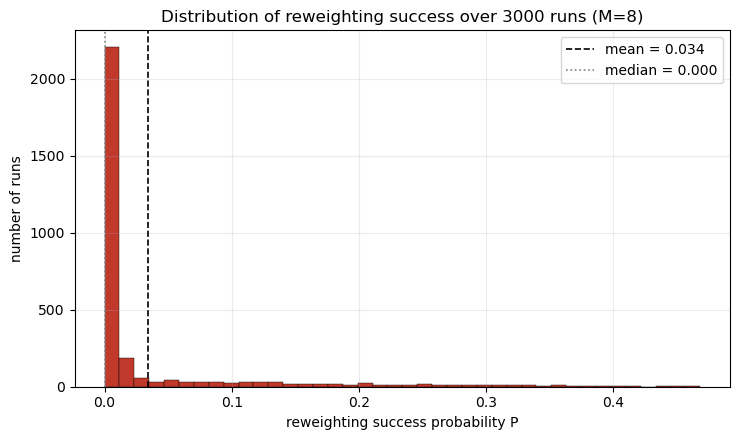

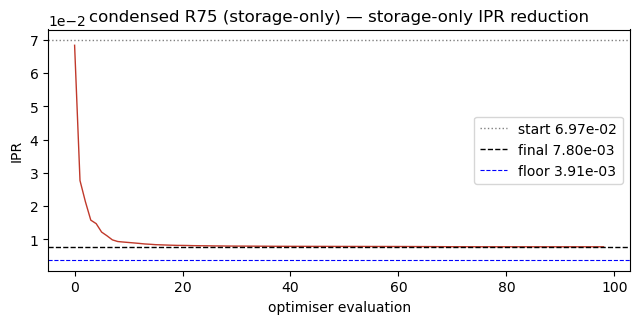

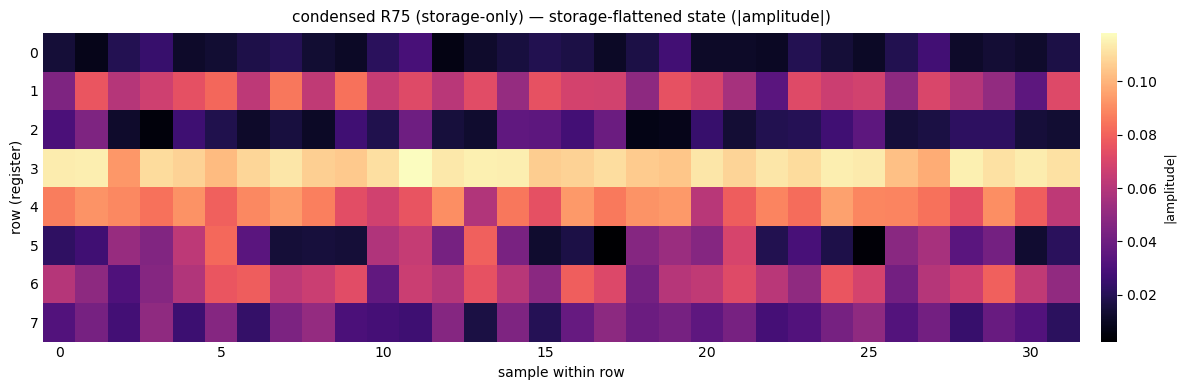

[[-0.00524416-0.01332942j -0.00383373-0.00698131j  0.01853872+0.0064099j
   0.02331803-0.00832132j  0.00923415-0.00737357j  0.00986382-0.0094344j
   0.01610791+0.00653669j  0.01874672+0.006285j    0.00147087+0.01327411j
   0.00331132+0.01028869j -0.01899364-0.00951018j -0.02631096+0.01293193j
  -0.00511955+0.00450497j -0.00598927+0.01070526j -0.01567441-0.00279131j
  -0.01874839-0.00222814j  0.01683051+0.00229567j  0.01090295-0.00069094j
  -0.01253035+0.011477j   -0.00091983+0.02746183j  0.01047261+0.00364742j
   0.01126584+0.0023719j   0.00043721+0.0104744j   0.0043991 +0.01871863j
   0.01289765-0.00668484j  0.00720477-0.00809123j -0.00322756+0.01876685j
   0.01545355+0.02290116j  0.01112465-0.00405712j  0.0090145 -0.01046752j
   0.01019349+0.00683459j  0.01311706+0.01117999j]
 [-0.03411552-0.02919739j -0.05504937-0.05261241j -0.0530476 -0.02800047j
  -0.05597172+0.03701052j  0.04119457+0.06189967j -0.0573132 -0.05748476j
  -0.06114318-0.01119827j -0.08378587-0.01644924j  0.03790851+0

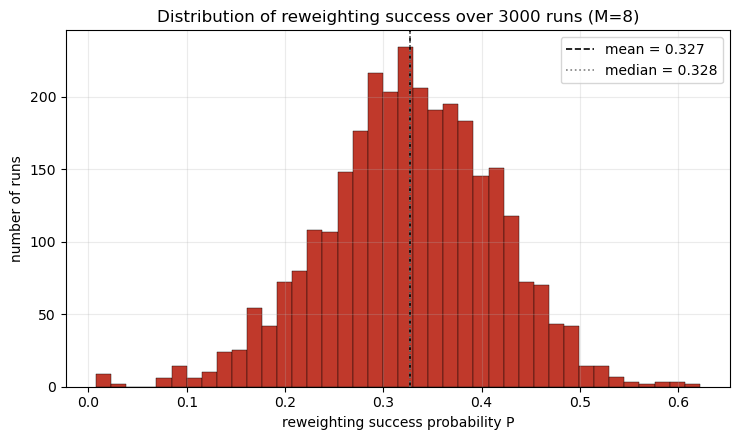

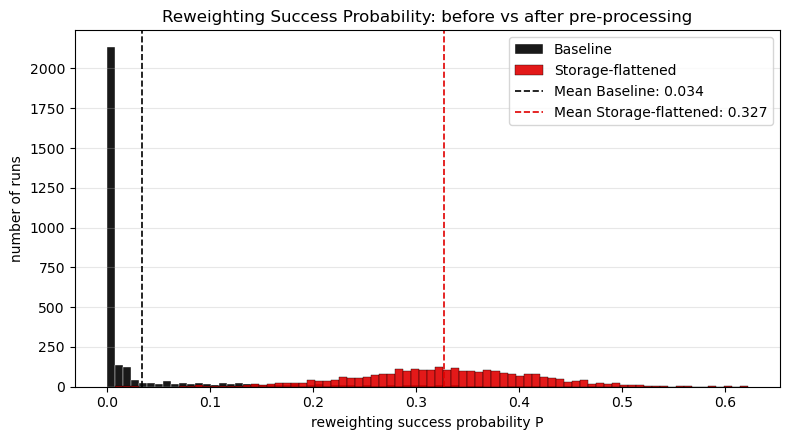

[condensed R75 (storage-only)]  success 0.0340 -> 0.3269 (9.62x)  |  IPR 6.97e-02 -> 7.80e-03
sigma unchanged (storage-only confirmed): True
[[ 1.36542964e-19 -3.54699840e-19  1.21925135e-20  6.65066191e-15
  -2.28617031e-11 -1.83254366e-08 -1.80262132e-07  6.80490804e-06
   4.57849745e-04 -1.91643257e-03 -2.95708471e-03 -6.88424704e-04
   7.40541433e-05 -2.96653170e-03 -1.43915478e-03 -2.57972596e-03
  -1.40011040e-04  4.92727777e-05  2.35259400e-04  2.17916309e-05
  -3.71907556e-05 -3.02665641e-04  1.25624851e-04  1.05998984e-05
  -1.99795122e-05 -1.82618120e-05  1.77501226e-05 -2.98697869e-04
  -1.19095160e-04 -1.09496625e-06  1.99903584e-08  2.84762793e-12]
 [ 2.06140462e-19 -2.57464046e-19 -9.33421039e-19  1.54179610e-13
  -1.51798206e-08 -1.11972465e-06 -7.81425073e-06 -4.76218130e-07
  -3.87690053e-06  1.36038630e-03  2.07473477e-02  1.95931414e-03
   3.70953475e-05 -3.17797327e-03 -1.83523923e-03 -4.13744731e-03
   2.04251642e-04  2.36252105e-04  1.45159252e-04  1.01690100e-06


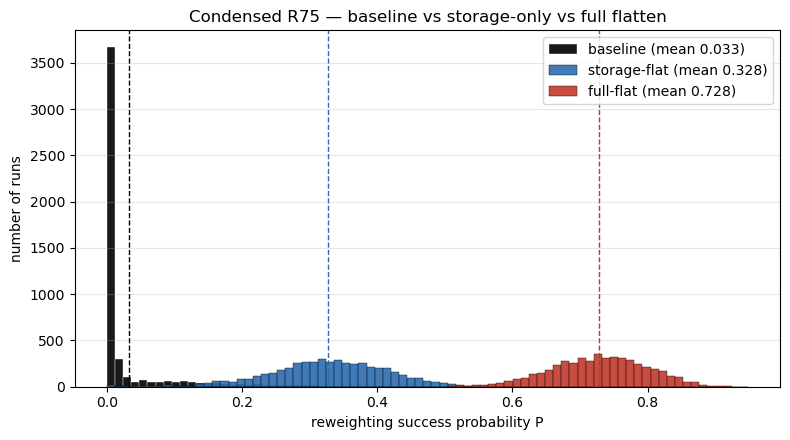

In [31]:
# --- 1) storage-only pipeline on the condensed data (all graphs + ansatz) ---
result_store_small = run_storage_flatten_pipeline(Y_small, name="condensed R75 (storage-only)")

# --- 2) also make the FULL-flatten of Y_small for comparison ---
M, N = Y_small.shape[1], Y_small.shape[0]                 # 8 registers, 32 samples
mps_f, _ = build_initial_and_layer(Y_small, eps_init=0.0)
full = optimise_flatten_layer(mps_f, n_iter=300, eps_init=1e-2, seed=0, verbose=False)
Y_small_flat      = full["psi_flat"].reshape(M, N).T
Y_small_storeflat = result_store_small["Y_flat"]

# --- 3) three-way comparison (same style: black / blue / red) ---
import numpy as np, matplotlib.pyplot as plt

def summarize(Ystate, label, n_shots=5000):
    sig, chk = extract_row_weights(Ystate)
    res = success_distribution(chk, sig, n_shots=n_shots, seed=0, plot=False)
    flat = np.asarray(Ystate).ravel(); flat = flat/np.linalg.norm(flat)
    return res["P"], {"label": label, "mean": res["mean"],
                      "sigma_spread": sig.max()/sig.min(),
                      "ipr": float(np.sum(np.abs(flat)**4))}

P_base, s_base = summarize(Y_small,           "baseline")
P_stor, s_stor = summarize(Y_small_storeflat, "storage-flat")
P_full, s_full = summarize(Y_small_flat,      "full-flat")

print(f"{'ansatz':14s} {'IPR':>10s} {'sigma spread':>13s} {'mean success':>13s}")
for s in (s_base, s_stor, s_full):
    print(f"{s['label']:14s} {s['ipr']:>10.2e} {s['sigma_spread']:>13.2f} {s['mean']:>13.4f}")

lo = min(P_base.min(), P_stor.min(), P_full.min()); hi = max(P_base.max(), P_stor.max(), P_full.max())
bins = np.linspace(lo, hi, 80)
plt.figure(figsize=(8, 4.5))
plt.hist(P_base, bins=bins, alpha=0.9, color="black",   edgecolor="white", lw=0.3, label=f"baseline (mean {s_base['mean']:.3f})")
plt.hist(P_stor, bins=bins, alpha=0.9, color="#2b6cb0", edgecolor="black", lw=0.3, label=f"storage-flat (mean {s_stor['mean']:.3f})")
plt.hist(P_full, bins=bins, alpha=0.9, color="#c0392b", edgecolor="black", lw=0.3, label=f"full-flat (mean {s_full['mean']:.3f})")
plt.axvline(s_base['mean'], color="black",   ls="--", lw=1.0)
plt.axvline(s_stor['mean'], color="#2b6cb0", ls="--", lw=1.0)
plt.axvline(s_full['mean'], color="#c0392b", ls="--", lw=1.0)
plt.xlabel("reweighting success probability P"); plt.ylabel("number of runs")
plt.title("Condensed R75 — baseline vs storage-only vs full flatten")
plt.legend(); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()


# Implementing reweighting with Josh Green Theorem 6

In [13]:
def make_trial_D_state(M=4, N=32, seed=0):
    """Proof-of-concept state with the same STRUCTURE as Theorem 6's target: M
    piecewise-constant blocks of length N (i.e. a product state: some M-dim vector
    (x) a uniform N-dim vector). Uses random block weights, not your real data --
    just for testing SSO against the right shape."""
    rng = np.random.default_rng(seed)
    block_weights = rng.normal(size=M) + 1j*rng.normal(size=M)
    block_weights /= np.linalg.norm(block_weights)
    uniform = np.ones(N) / np.sqrt(N)
    return np.kron(block_weights, uniform)

phi = make_trial_D_state(M=4, N=32)


In [ ]:
import numpy as np
import quimb.tensor as qtn
from sso_prep import sequential_disentangle_warm

def make_trial_D_state(M=4, N=32, seed=0):
    """Proof-of-concept state with the same STRUCTURE as Theorem 6's target: M
    piecewise-constant blocks of length N (i.e. a product state: some M-dim vector
    (x) a uniform N-dim vector). Uses random block weights, not your real data --
    just for testing SSO against the right shape."""
    rng = np.random.default_rng(seed)
    block_weights = rng.normal(size=M) + 1j*rng.normal(size=M)
    block_weights /= np.linalg.norm(block_weights)
    uniform = np.ones(N) / np.sqrt(N)
    return np.kron(block_weights, uniform)

phi = make_trial_D_state(M=64, N=32)
n = int(np.log2(len(phi)))


mps = qtn.MatrixProductState.from_dense(phi.astype(np.complex128), dims=[2]*n, cutoff=0.0)
mps /= mps.norm()

res = sequential_disentangle_warm(mps, chi=2, num_layers=10, n_iter=200, verbose=False)

print("chi_fids per layer:", res["chi_fids"])
print("final fid:", res["chi_fids"][-1])


chi_fids per layer: [0.4677354762986239, 0.7908114992318296, 0.948601106934413, 0.9896572041794784, 0.9973315201276962, 0.9987999463102424, 0.9997093111273423, 0.9998868798891595, 0.9999529663034701, 0.999977652811316, 0.9999873831170331]
final fid: 0.9999873831170331


# More expressive IPR reduction layers 

- try different optimisers, is it anstaz or optimiser that is not effective enough. To see if anstaz is wrong run a bunch of different from different initial states to see if its local optimiser. if it is local try adam if lgsb fails.
- try brick wall and multiple staircase to see how IPR is reduced.
TODO
-proof work
-edit paper for w tilde

## Why hybrid (greedy-then-joint) training, brick-wall ansatz

**See `IPR Reduction Ansatz Comparison.ipynb` for the full comparison and evidence.**

**Correction from the first version of this note:** the original comparison had a
bug — `optimise_flatten_layers_hybrid` combined independently-built layers into one
`TensorNetwork` by renaming only the outer `k`/`b` legs, but `make_chi2_staircase`
(and `make_brick_wall_layer`) reuse the *same* internal bond names on every call
(the staircase's `c0..c_{n-3}` carrier bond; brick wall's `mid0..mid_{n-1}`
even→odd connector). Since quimb identifies indices by name, layer 1's internal
bond and layer 2's internal bond were silently getting wired together across
layers — invisible at `eps=0` (identity gates are too degenerate to reveal it) but
producing an uncomposable, physically-unrealizable "circuit" once gates were
actually optimized. That's why the numbers looked so good (P≈0.98-0.99): the
optimizer had access to a search space that no real 2-layer circuit corresponds to.

**Corrected results on `Y_full` (15 qubits), 4 layers, reweighting success
probability P (baseline P = 0.0052):**

| ansatz | greedy | joint (cold start) | hybrid |
|---|---|---|---|
| staircase | ~0.20-0.25 (plateaus) | IPR 4.71e-5 | **P = 0.253** (48.3x) |
| brick-wall | ~0.20-0.32 (plateaus) | IPR 4.14e-5 | **P = 0.492 (93.9x)** |

- Joint/hybrid do genuinely beat pure greedy once correctly wired — consistently,
  at every depth, for both ansätze — but the gain is *modest* (~5-16% lower IPR),
  not the dramatic jump to near-floor the buggy version showed.
- **Brick wall clearly beats the staircase again, at every depth, under every
  training strategy** — hybrid brick wall (P=0.49) is roughly 2x the staircase
  (P=0.25). The "they're basically identical" conclusion from the buggy run doesn't
  survive the fix. The *original* plain-greedy result (brick wall winning) was
  right all along.
- **Practical choice, updated: brick wall, not the staircase**, if this state can
  tolerate the unconstrained bond dimension it produces (it isn't representable as
  a cheap chi=2 MPS the way the staircase's output is — check this matters for your
  downstream use before switching).


> ## 🚨 Brick-wall bug — FIXED in the cell below (2026-08-25)
>
> `make_brick_wall_layer` pads the leftover qubit of each sublayer with a plain
> `qtn.Tensor(torch.eye(2), tags={"ID"})`. A plain `Tensor` is **not** a `PTensor`, so
> `quimb.TNOptimizer` exposed its raw complex entries as **free, unconstrained variables**.
> `optimise_flatten_layers_hybrid` did not pass `constant_tags=["ID"]`, so **`V` was not
> unitary** — and because the IPR loss normalises the state afterwards, the optimiser was
> *rewarded* for learning a non-physical rescaling instead of a circuit.
>
> On the full R75 state (7 layers, seed 7):
>
> | | baseline `Y_full` | broken | fixed (`constant_tags=["ID"]`) |
> |---|---|---|---|
> | IPR / uniform floor | 51.03× | **1.0001×** | 1.4699× |
> | \|amp\| max/min | 4.8e21 | 1.049 | 187.6 |
> | last-qubit Schmidt weight | 0.235 | 8.4e-33 | 0.421 |
> | mean row χ=2 fidelity, 0 layers | 0.6611 | 0.9950 | **0.4013** |
> | mean reweighting P | 0.0053 | 0.9699 | **0.2858** |
>
> The broken version drove R75 to an **exact phase state** — the Appendix-A configuration
> that gives P = 1 deterministically. It also made the flattened rows *easier* to encode
> (0.661 → 0.995), which is backwards: flattening should make them harder, and the fixed
> version does exactly that (0.661 → 0.401).
>
> **Two changes below:** `constant_tags=["ID"]` on the `TNOptimizer` call, and a unitarity
> assertion every round. `make_chi2_staircase` was never affected (15/15 `PTensor`, no
> padding identities), so every staircase result in this notebook is fine — including
> paper Figs. 3 and 4.
>
> Pre-fix copy of this notebook: `MainMREnotebook.PRE-BRICKWALLFIX-BACKUP.ipynb`.

In [41]:
def make_brick_wall_layer(n, eps=0.0, seed=None):
    """One brick-wall layer: SU(4) on all EVEN bonds (0,1),(2,3),... then SU(4) on
    all ODD bonds (1,2),(3,4),...

    !! The leftover qubit in each sublayer is padded with a PLAIN qtn.Tensor identity
    tagged "ID". A plain Tensor is NOT a PTensor, so quimb's TNOptimizer exposes its raw
    complex entries as free, UNCONSTRAINED variables. Any optimiser driving this ansatz
    MUST pass constant_tags=["ID"], or the resulting V is not unitary and is not a circuit.

    The earlier claim that this ansatz "empirically outperforms the staircase" is
    RETRACTED: it was an artefact of exactly that hole. The brick wall had a non-unitary
    escape hatch; make_chi2_staircase (15/15 PTensor, no padding identities) did not.
    See ansatz_headtohead_FIXED.csv for the corrected, unitarity-checked comparison."""
    if seed is not None: torch.manual_seed(seed)
    def _init(m):
        p = torch.zeros(m, dtype=torch.float64)
        if eps > 0: p = p + eps * torch.randn(m, dtype=torch.float64)
        return p.requires_grad_(True)
    tensors = []
    def sublayer(in_prefix, out_prefix, pairs, untouched):
        for (q0, q1) in pairs:
            tensors.append(PTensor(su4_matrix, _init(15),
                                   inds=(f"{in_prefix}{q0}", f"{in_prefix}{q1}",
                                         f"{out_prefix}{q0}", f"{out_prefix}{q1}"),
                                   tags={"SU4"}))
        for q in untouched:
            tensors.append(qtn.Tensor(torch.eye(2, dtype=torch.complex128),
                                      inds=(f"{in_prefix}{q}", f"{out_prefix}{q}"), tags={"ID"}))
    even_pairs = [(i, i + 1) for i in range(0, n - 1, 2)]
    even_untouched = [q for q in range(n) if q not in {x for p in even_pairs for x in p}]
    sublayer("k", "mid", even_pairs, even_untouched)
    odd_pairs = [(i, i + 1) for i in range(1, n - 1, 2)]
    odd_untouched = [q for q in range(n) if q not in {x for p in odd_pairs for x in p}]
    sublayer("mid", "b", odd_pairs, odd_untouched)
    return qtn.TensorNetwork(tensors)


def optimise_flatten_layers_hybrid(mps, max_layers, layer_builder=make_brick_wall_layer,
                                    n_iter=200, eps_init=1e-2, seed=0, tol=1e-14, verbose=False,
                                    plateau_rel_tol=1e-3, plateau_patience=2):
    """Greedy warm-start + joint fine-tune, per layer. Adds TWO safety mechanisms on
    top of the original version:
      1. Never accepts a round that makes IPR WORSE than the previous accepted round
         (rejects it, keeps the previous stack, tries a fresh layer next round instead).
      2. Stops adding layers once IPR improvement plateaus (< plateau_rel_tol for
         plateau_patience consecutive rounds) -- once the training objective has
         nothing left to gain, further layers just wander a flat/degenerate part of
         the loss landscape, which is pure risk for worst-case success probability P
         (which IPR is only a proxy for) and wasted compute for zero benefit.
    Still carries the internal-bond namespacing fix (L{L}_ prefix on new_layer's
    internal indices) that prevents cross-layer bond collisions when stacking.

    FIX (2026-08-25): constant_tags=["ID"] is now passed to TNOptimizer, and a unitarity
    assertion runs every round. Without them, make_brick_wall_layer's padding identities
    were free non-unitary parameters, so the optimiser "flattened" by non-physically
    rescaling amplitudes rather than by finding a circuit -- driving the full R75 state to
    an EXACT phase state (IPR pinned to the 1/2^n floor, every sigma_i = 1/sqrt(M), one
    qubit fully disentangled, reweighting P ~ 0.97). Everything produced by this function
    before that date is invalid; see the warning cell above."""
    n = mps.L

    def ipr_of_op(op, target_mps):
        psi = dense_state_from_op_mps(op, target_mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return (torch.abs(psi) ** 4).sum()

    def optimise_stack(stack_init, target_mps, n_iter_, history):
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = ipr_of_op(op, init_tn); s = float(val.detach()); history.append(s)
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        qtn.TNOptimizer(stack_init, loss, loss_constants={"init_tn": target_mps}, optimizer="l-bfgs-b",
                autodiff_backend="torch", progbar=verbose,
                constant_tags=["ID"]).optimize(n=n_iter_, tol=tol)

        if best["params"] is not None:
            stack_init.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            return stack_init, best["val"]
        return stack_init, float(ipr_of_op(stack_init, target_mps).detach())

    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)

    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]
    full_history, layer_boundaries = [], [0]

    stack = None
    stall_count = 0
    for L in range(max_layers):
        new_layer = layer_builder(n, eps=eps_init, seed=seed + L)
        new_layer, ipr_greedy = optimise_stack(new_layer, current_mps, n_iter, full_history)
        layer_boundaries.append(len(full_history))   # greedy -> joint transition

        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})

        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))

        candidate, ipr_joint = optimise_stack(candidate, mps, n_iter, full_history)
        layer_boundaries.append(len(full_history))   # joint -> next layer's greedy

        # --- UNITARITY GUARD -------------------------------------------------------
        # A non-unitary V is not a circuit, and IPR-minimisation actively rewards
        # cheating this way (it normalises the state afterwards). This one line would
        # have caught both the free-"ID"-tensor bug and the earlier index-collision bug
        # the day they were introduced. Cost: one contraction per layer.
        _psi = dense_state_from_op_mps(candidate, mps).reshape(-1)
        _nerr = abs(float(torch.linalg.norm(_psi)) - 1.0)
        if _nerr > 1e-9:
            raise RuntimeError(
                f"V is not unitary at layer {L+1}: | ||V|psi>|| - 1 | = {_nerr:.3e}. "
                f"Check that every TNOptimizer call passes constant_tags=['ID'].")

        prev_ipr = per_layer_ipr[-1]
        if ipr_joint <= prev_ipr:
            stack = candidate
            accepted_ipr = ipr_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_ipr = prev_ipr
            if verbose:
                print(f"  layer {L+1}: regression ({ipr_joint:.4e} > {prev_ipr:.4e}), rejected, keeping previous stack")

        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_ipr.append(accepted_ipr)
        per_layer_psi.append(psi_now)

        rel_improve = (prev_ipr - accepted_ipr) / prev_ipr if prev_ipr > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if verbose:
            print(f"  layer {L+1}/{max_layers}: greedy IPR={ipr_greedy:.4e}  after joint fine-tune={ipr_joint:.4e}  "
                  f"accepted={accepted_ipr:.4e}  rel_improve={rel_improve:.2%}  stall={stall_count}")

        if stall_count >= plateau_patience:
            if verbose:
                print(f"  IPR plateaued (< {plateau_rel_tol:.1%} improvement for {plateau_patience} rounds) "
                      f"-- stopping at layer {L+1}/{max_layers}, remaining layer counts repeat this state")
            while len(per_layer_ipr) <= max_layers:
                per_layer_ipr.append(per_layer_ipr[-1])
                per_layer_psi.append(per_layer_psi[-1])
            break

    return {"per_layer_ipr": per_layer_ipr, "per_layer_psi": per_layer_psi,
            "history": full_history, "layer_boundaries": layer_boundaries}


def compare_flatten_layers(Y, layer_counts=(1, 2, 3, 5, 10), name="state", layer_builder=make_brick_wall_layer,
                            n_shots=5000, n_iter=200, seed=0, eps_init=1e-2, tol=1e-14):
    Y = np.asarray(Y); N, M = Y.shape
    n = int(round(np.log2(M * N)))

    _display_state(Y, f"{name} — target state (|amplitude|)")

    v = np.asarray(Y, dtype=np.complex128).T.flatten(); v /= np.linalg.norm(v)
    mps = qtn.MatrixProductState.from_dense(v.reshape([2] * n), dims=[2] * n)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    ipr_base = float(np.sum(np.abs(v) ** 4))

    sigma0, chunks0 = extract_row_weights(Y)
    print(f"[{name}] baseline reweighting success:")
    res_base = success_distribution(chunks0, sigma0, n_shots=n_shots, seed=seed, plot=False)

    max_L = max(layer_counts)
    print(f"[{name}] training up to {max_L} layers ({layer_builder.__name__}, hybrid, plateau-guarded)...")
    seq = optimise_flatten_layers_hybrid(mps, max_layers=max_L, layer_builder=layer_builder, n_iter=n_iter,
                                          eps_init=eps_init, seed=seed, tol=tol, verbose=False)

    colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(layer_counts)))
    results = {}
    for L in layer_counts:
        psi_flat = seq["per_layer_psi"][L]
        Y_flat = psi_flat.reshape(M, N).T
        sigmaF, chunksF = extract_row_weights(Y_flat)
        res = success_distribution(chunksF, sigmaF, n_shots=n_shots, seed=seed, plot=False)
        results[L] = {"psi_flat": psi_flat, "Y_flat": Y_flat, "ipr": seq["per_layer_ipr"][L], "res": res}
        print(f"  {L} layer(s): IPR {ipr_base:.3e} -> {results[L]['ipr']:.3e}   "
              f"success {res_base['mean']:.4f} -> {res['mean']:.4f}  ({res['mean']/res_base['mean']:.2f}x)")

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.axhline(ipr_base, color="black", ls=":", lw=1.2, label=f"baseline {ipr_base:.2e}")
    ax.axhline(1 / 2**n, color="blue", ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
    ax.plot(range(max_L + 1), seq["per_layer_ipr"], color="#c0392b", marker="o", ms=4, lw=1.8)
    ax.set_yscale("log")
    ax.set_xlabel("number of layers"); ax.set_ylabel("final IPR")
    ax.set_title(f"{name} — IPR vs. depth ({layer_builder.__name__}, hybrid training)")
    ax.legend(); ax.grid(alpha=0.25, which="both")
    plt.tight_layout(); plt.show()

    means = [results[L]["res"]["mean"] for L in layer_counts]
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.axhline(res_base["mean"], color="black", ls=":", lw=1.2, label="baseline")
    ax.plot(layer_counts, means, color="#2b6cb0", marker="o", lw=1.8)
    ax.set_xlabel("number of layers"); ax.set_ylabel("mean reweighting success P")
    ax.set_title(f"{name} — success probability vs. depth ({layer_builder.__name__}, hybrid training)")
    ax.legend(); ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()

    best_L = max(layer_counts, key=lambda L: results[L]["res"]["mean"])   # <-- best BY P, not lowest IPR
    _display_state(results[best_L]["Y_flat"], f"{name} — flattened state, {best_L} layer(s) (|amplitude|)")

    all_P = [res_base["P"]] + [results[L]["res"]["P"] for L in layer_counts]
    lo = min(p.min() for p in all_P); hi = max(p.max() for p in all_P)
    bins = np.linspace(lo, hi, 80)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(res_base["P"], bins=bins, alpha=0.85, color="black", edgecolor="white", lw=0.3,
            label=f"baseline (mean {res_base['mean']:.4f})")
    for L, color in zip(layer_counts, colors):
        ax.hist(results[L]["res"]["P"], bins=bins, alpha=0.55, color=color, edgecolor="black", lw=0.3,
                label=f"{L} layer(s) (mean {results[L]['res']['mean']:.4f})")
    ax.set_xlabel("reweighting success probability P"); ax.set_ylabel("number of runs")
    ax.set_title(f"{name} — success probability, baseline vs. depth ({layer_builder.__name__}, hybrid training)")
    ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.plot(seq["history"], color="#c0392b", lw=1)
    for b in seq["layer_boundaries"][1:-1]:
        ax.axvline(b, color="grey", ls=":", lw=0.8)
    ax.set_yscale("log"); ax.set_xlabel("optimiser evaluation (dashed = greedy/joint-fine-tune/next-layer boundaries)")
    ax.set_ylabel("IPR")
    ax.set_title(f"{name} — convergence diagnostic")
    ax.grid(alpha=0.2, which="both")
    plt.tight_layout(); plt.show()

    print(f"\n{'layers':>7s} {'IPR':>12s} {'mean success':>13s} {'gain vs baseline':>18s}")
    print(f"{'base':>7s} {ipr_base:>12.3e} {res_base['mean']:>13.4f} {'--':>18s}")
    for L in layer_counts:
        gain = results[L]["res"]["mean"] / res_base["mean"]
        print(f"{L:>7d} {results[L]['ipr']:>12.3e} {results[L]['res']['mean']:>13.4f} {gain:>17.2f}x")
    print(f"\nbest observed success probability: {results[best_L]['res']['mean']:.4f} at {best_L} layer(s) "
          f"(NOT necessarily the deepest -- check this before assuming more layers = better)")

    return results, res_base, seq


> ### 🚨 Every output in the cells below was produced by the broken (non-unitary) brick wall
>
> The code above is fixed but these cells have **not** been re-run. Their stored outputs,
> and everything they wrote to disk, are invalid:
>
> - `results/v_full_seed0..9.pkl`, `results/v_full_results_trial1..4.pkl`
> - `SSO results/row_sweep_R75full_newbrickwall_flat_L7/`
> - any `psi_flat` / `Y_flat` / `P` / IPR number printed or plotted below
>
> Re-run from the fixed definition cell to regenerate. Delete or rename the stale pickles
> first — the seed sweep skips any seed whose `.pkl` already exists, so it will silently
> reload the broken results otherwise.

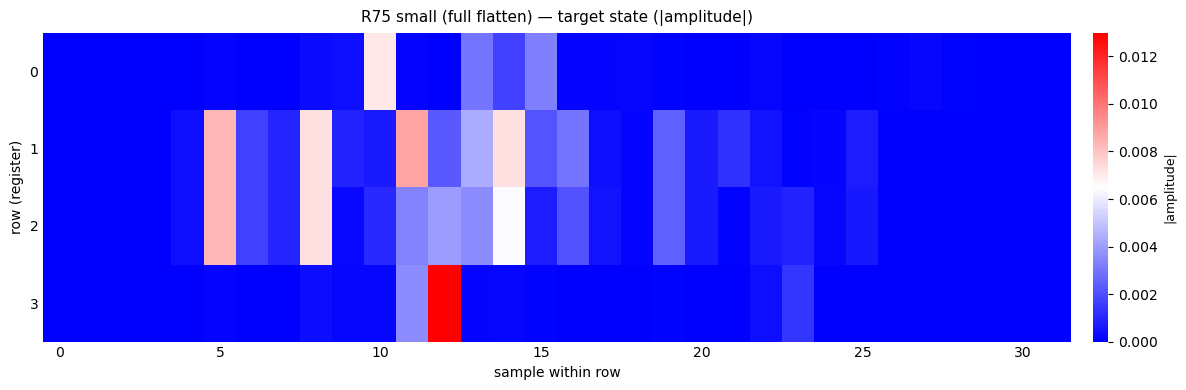

[[ 1.76777444e-19 -3.24899160e-19 -3.95929060e-19  1.20609500e-10
   5.46919147e-06  1.06063290e-04  1.43851735e-05  1.82982344e-05
   2.95714683e-04 -3.78298029e-04  7.05234479e-03  1.04937955e-04
   1.53773839e-05 -2.96219604e-03 -1.68974424e-03 -3.27304846e-03
  -1.18472962e-04  1.30402474e-04  1.88049632e-04  5.66109519e-05
   1.43967547e-05 -2.72856974e-05 -1.61805177e-04  1.29182224e-06
  -1.59857533e-05 -2.67647786e-05  6.34207869e-05 -1.66045071e-04
  -8.97447151e-05 -6.64267831e-07  9.54464017e-09  1.56332547e-12]
 [ 1.44507639e-18  3.38585390e-19 -1.16639721e-18  5.86921260e-09
   4.04245063e-04  8.33120109e-03  1.66097317e-03  9.43667200e-04
   7.29567604e-03  9.05220514e-04 -6.78260776e-04 -8.80938573e-03
  -2.30626832e-03 -4.39156157e-03 -7.25436513e-03 -2.16559183e-03
  -2.96601350e-03 -4.05100170e-04  1.49101898e-04  2.50288479e-03
   6.95080391e-04 -1.22383463e-03 -4.61092488e-04  5.92372646e-05
  -1.37213138e-04 -7.23671849e-04 -4.86152317e-05  4.68372917e-05
   4.1687

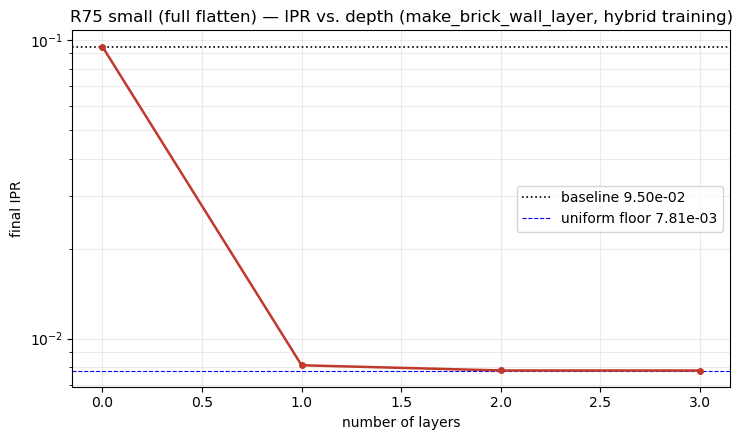

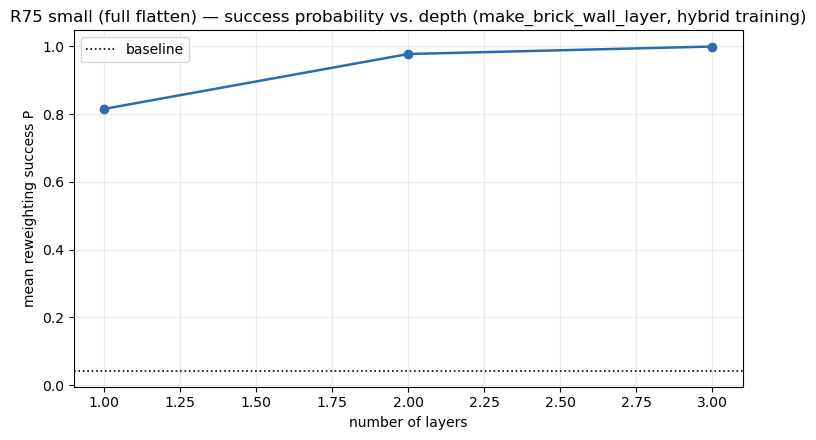

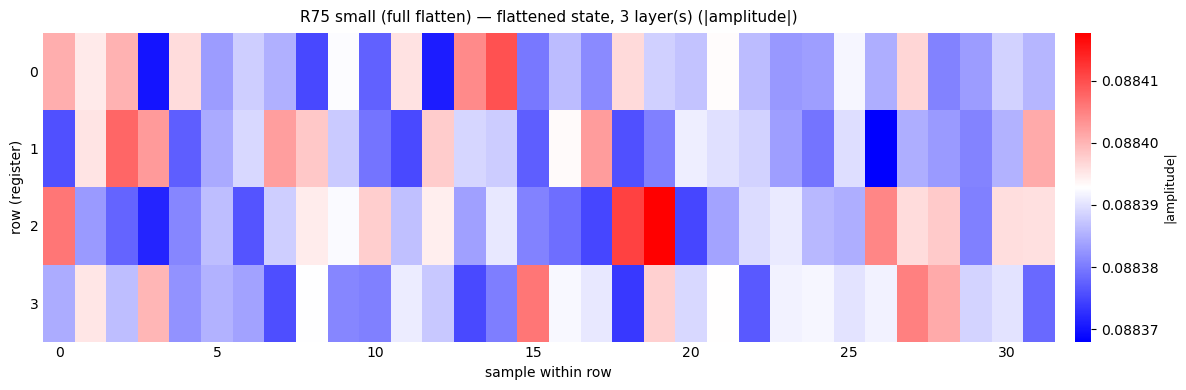

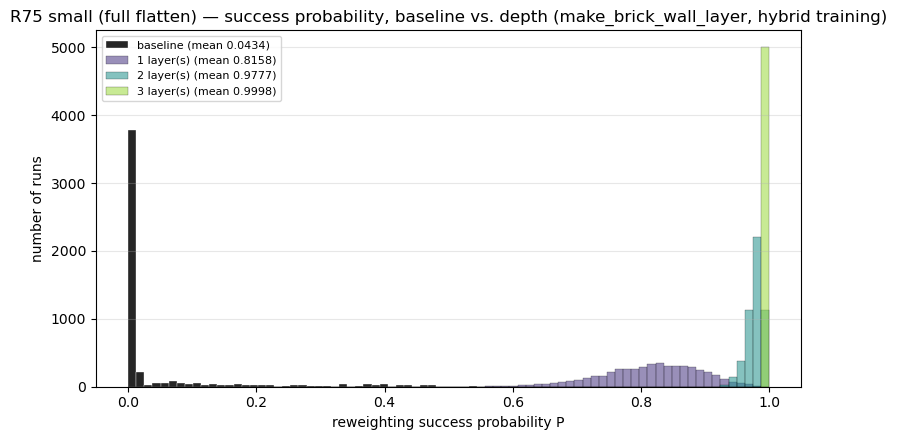

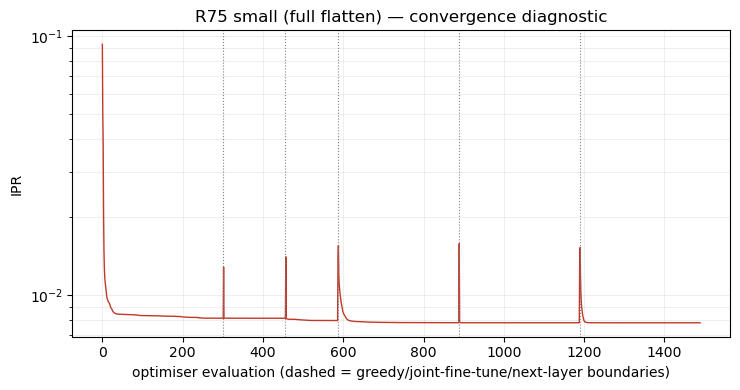


 layers          IPR  mean success   gain vs baseline
   base    9.496e-02        0.0434                 --
      1    8.136e-03        0.8158             18.78x
      2    7.816e-03        0.9777             22.50x
      3    7.813e-03        0.9998             23.01x

best observed success probability: 0.9998 at 3 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)


In [42]:
layer_results, base_result, seq = compare_flatten_layers(
    Y_small, layer_counts=(1, 2, 3), name="R75 small (full flatten)",
    n_shots=5000, n_iter=300, seed=0,
)


Y_full: (256, 128)  -> 15 qubits, M = 128 registers of 256


+0.000066512234 [best: +0.000066512234] :   2%|▏         | 5/300 [00:00<00:10, 27.76it/s]


IPR 0.001557 -> 0.000067   (uniform floor 1/D = 0.000031)
IPR 0.0015572609903244103 -> 6.651223378612357e-05


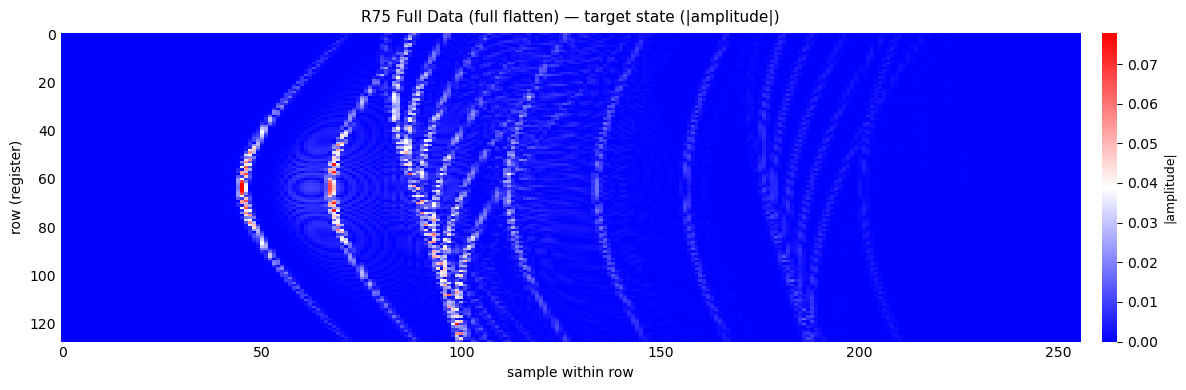

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (full flatten)] baseline reweighting success:
[R75 Full Data (full flatten)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[ 1.66455915e-03-0.00298387j  7.20962294e-04-0.00466154j
  -6.13058280e-03-0.0045786j  ... -2.81254265e-03+0.00405268j
   5.82291608e-03-0.00210248j -1.39212039e-04-0.00256535j]
 [-1.77935065e-0

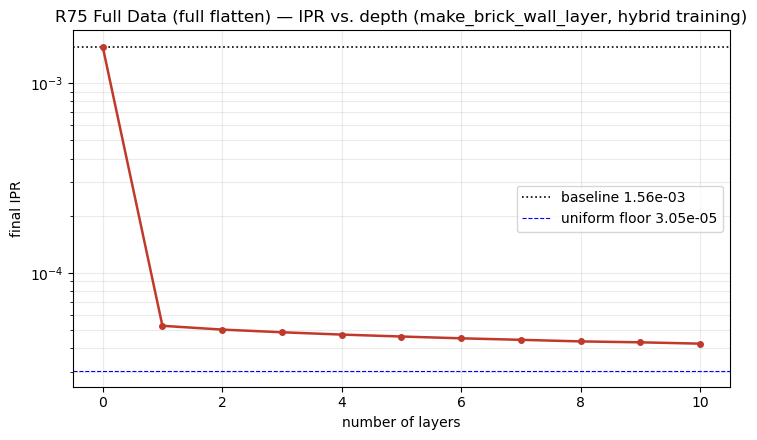

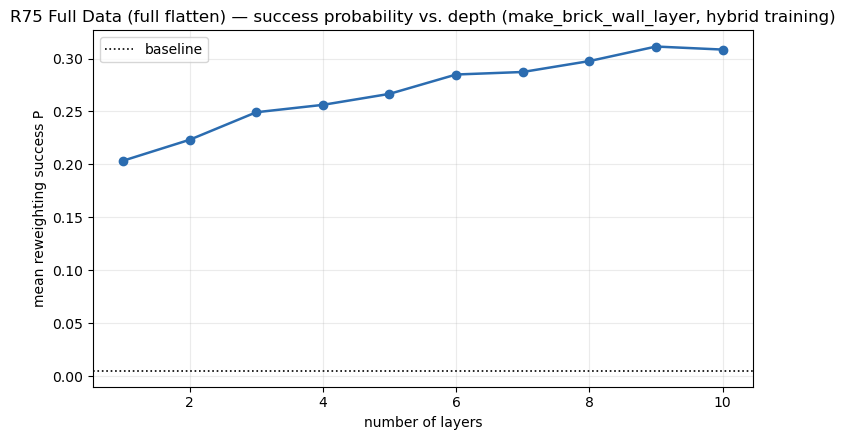

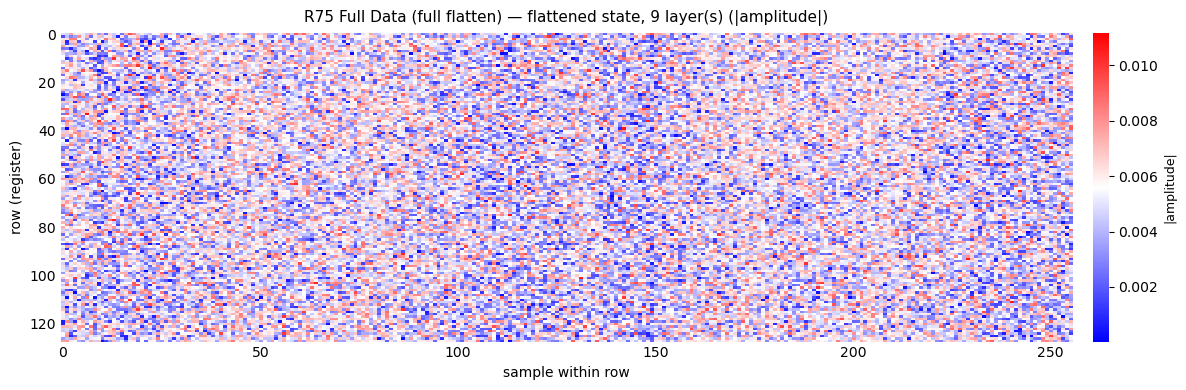

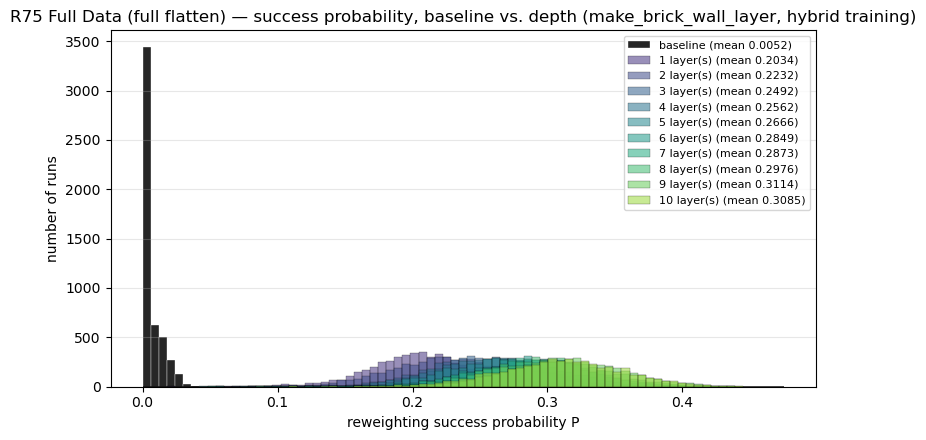

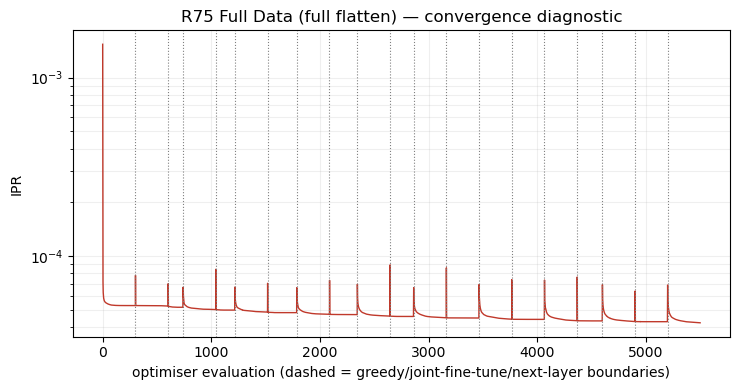


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0052                 --
      1    5.251e-05        0.2034             39.25x
      2    5.016e-05        0.2232             43.08x
      3    4.855e-05        0.2492             48.10x
      4    4.720e-05        0.2562             49.45x
      5    4.611e-05        0.2666             51.45x
      6    4.512e-05        0.2849             54.98x
      7    4.430e-05        0.2873             55.44x
      8    4.345e-05        0.2976             57.44x
      9    4.298e-05        0.3114             60.09x
     10    4.229e-05        0.3085             59.53x

best observed success probability: 0.3114 at 9 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)


In [43]:
#redefine Y_full
import numpy as np, pandas as pd, torch
from skimage.transform import resize

df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
Y_full = resize(df.to_numpy(), (256, 128), anti_aliasing=True)      # (samples, registers) = (256, 128)
Y_full = Y_full / np.linalg.norm(Y_full)
M, N = Y_full.shape[1], Y_full.shape[0]                              # 128 registers, 256 samples
print("Y_full:", Y_full.shape, " -> 15 qubits, M =", M, "registers of", N)

# flatten it (one SU(4) chi=2 layer on the full 15-qubit state)
mps_full, _ = build_initial_and_layer(Y_full, eps_init=0.0)
flat_full   = optimise_flatten_layer(mps_full, n_iter=300, eps_init=1e-2, seed=0, verbose=True)
Y_full_flat = flat_full["psi_flat"].reshape(M, N).T                 # (256, 128), flattened, complex
print("IPR", flat_full["ipr0"], "->", flat_full["ipr"])

layer_results, base_result, seq = compare_flatten_layers(
    Y_full, layer_counts=(1,2,3,4,5,6,7,8,9,10), name="R75 Full Data (full flatten)",
    n_shots=5000, n_iter=300, seed=0,
)

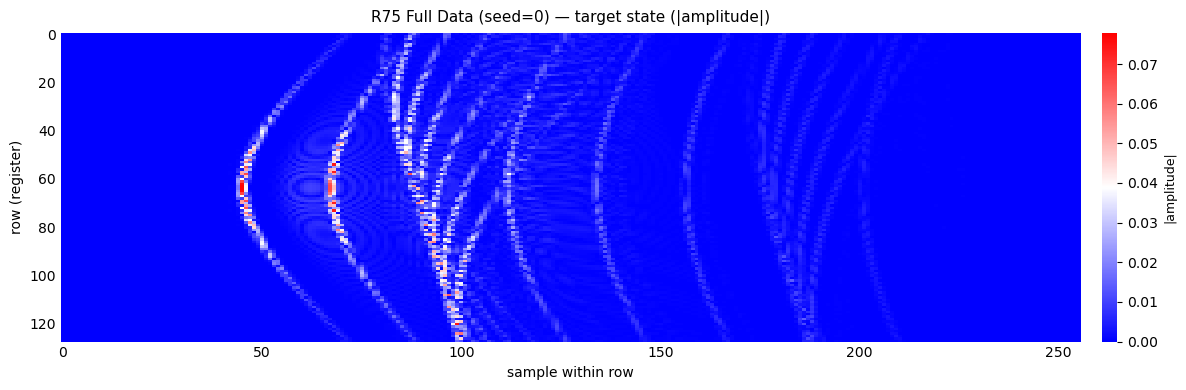

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=0)] baseline reweighting success:
[R75 Full Data (seed=0)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[ 1.66455915e-03-0.00298387j  7.20962294e-04-0.00466154j
  -6.13058280e-03-0.0045786j  ... -2.81254265e-03+0.00405268j
   5.82291608e-03-0.00210248j -1.39212039e-04-0.00256535j]
 [-1.77935065e-03+0.00036558

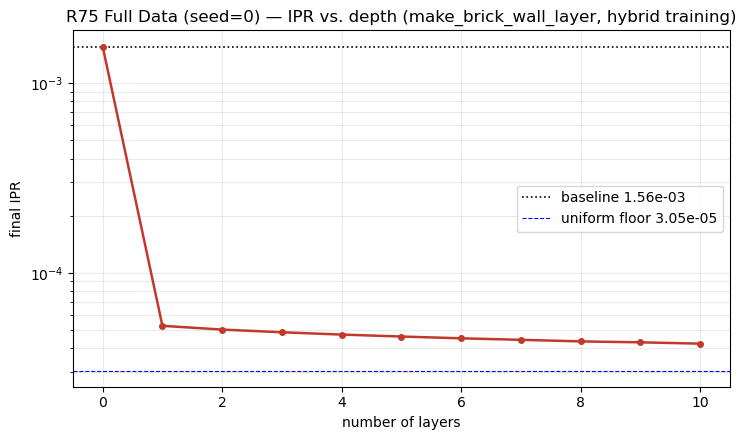

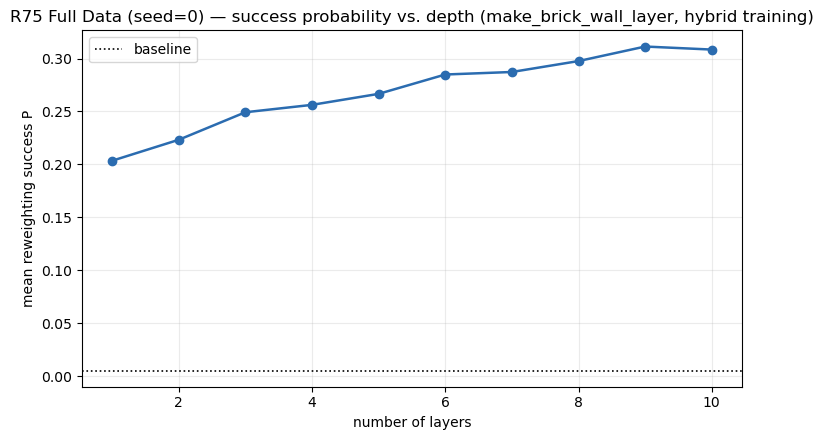

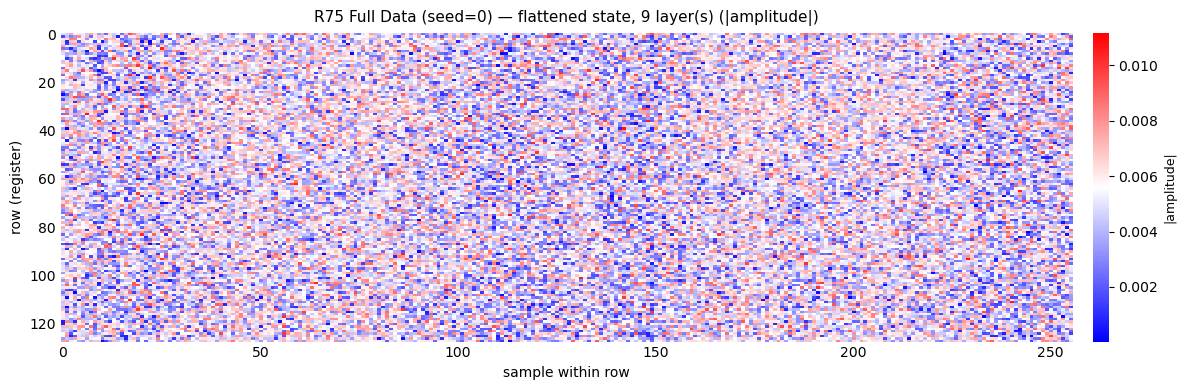

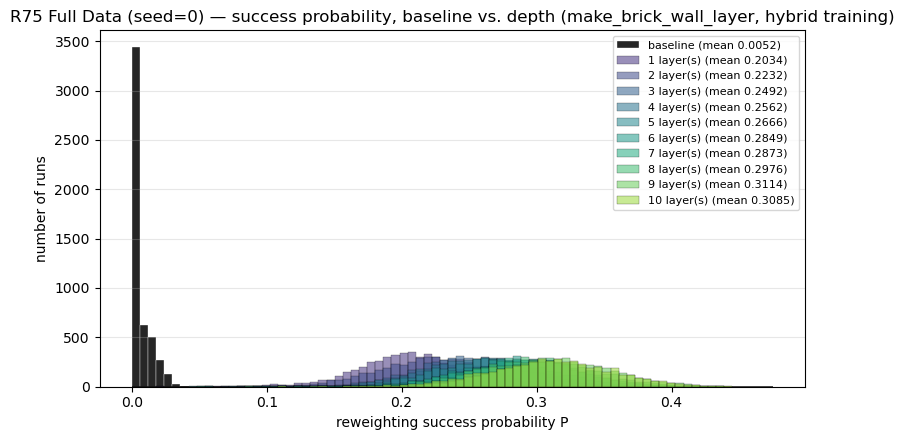

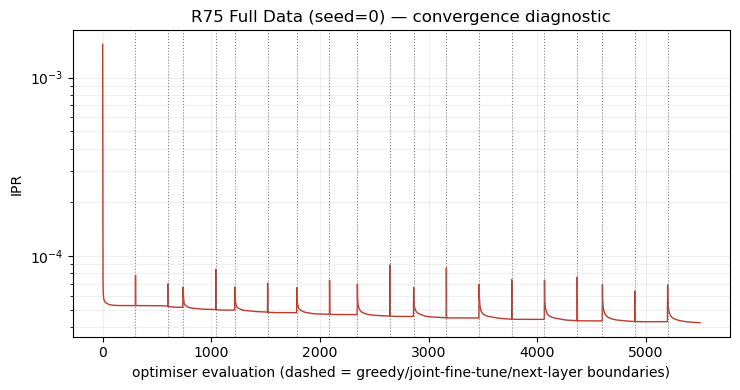


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0052                 --
      1    5.251e-05        0.2034             39.25x
      2    5.016e-05        0.2232             43.08x
      3    4.855e-05        0.2492             48.10x
      4    4.720e-05        0.2562             49.45x
      5    4.611e-05        0.2666             51.45x
      6    4.512e-05        0.2849             54.98x
      7    4.430e-05        0.2873             55.44x
      8    4.345e-05        0.2976             57.44x
      9    4.298e-05        0.3114             60.09x
     10    4.229e-05        0.3085             59.53x

best observed success probability: 0.3114 at 9 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 0: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed0.pkl  (585.3s)
  -> 10-layer success probability P = 0.3085   IPR = 4.2290e-05


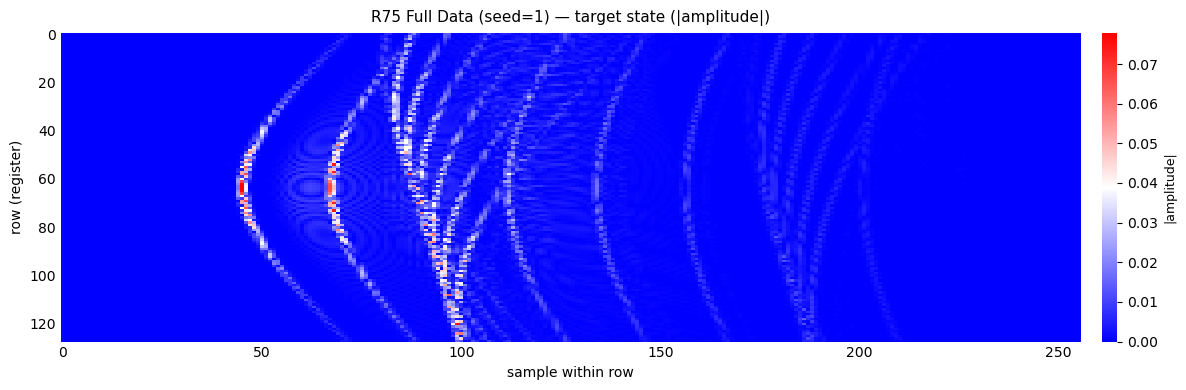

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=1)] baseline reweighting success:
[R75 Full Data (seed=1)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[ 0.00316097-0.00330053j  0.00031349-0.00349033j -0.00727211+0.00548555j
  ... -0.00034219+0.00205418j  0.00197873-0.00120239j
  -0.00307176-0.00268476j]
 [ 0.00018121-0.00588726j -0.00297738+0.00391742j -0

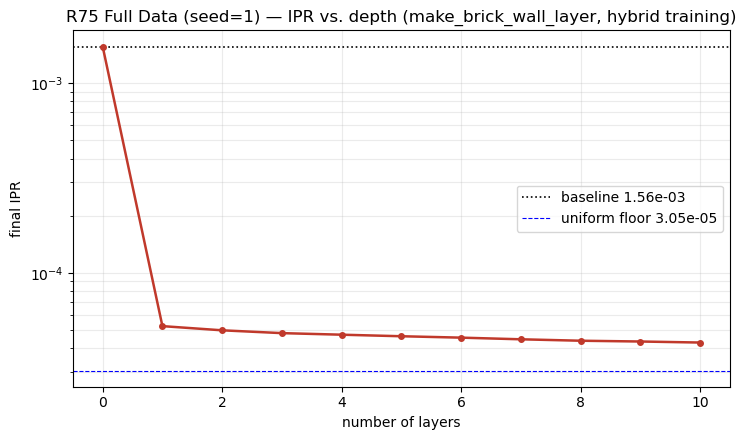

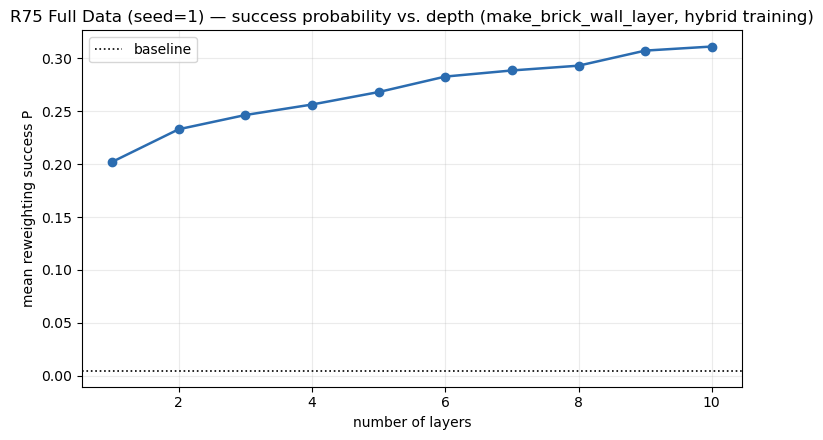

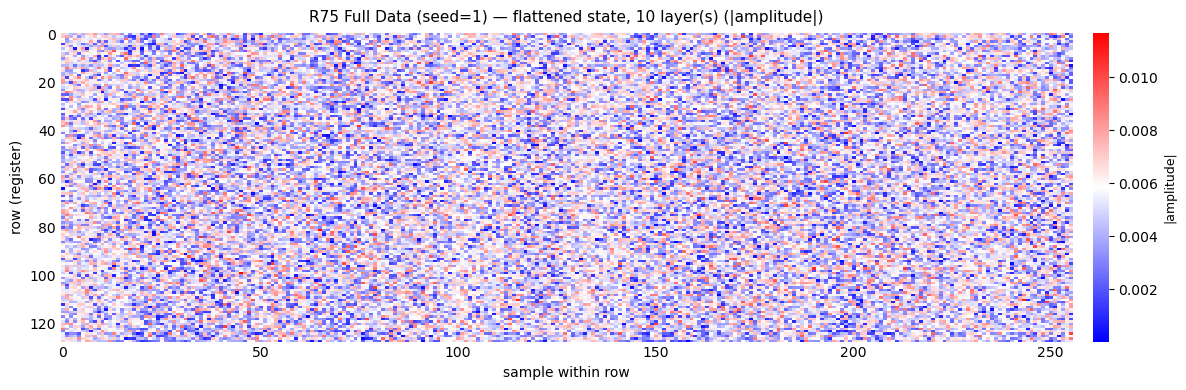

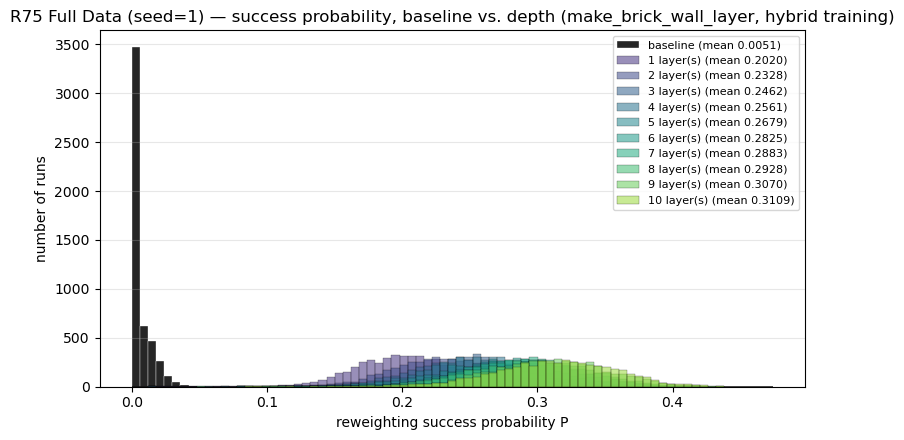

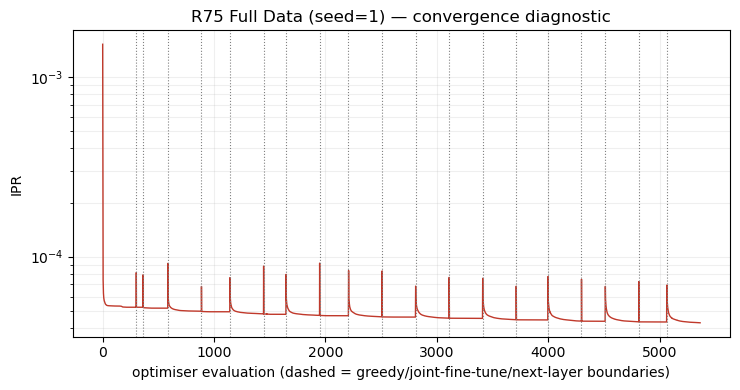


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0051                 --
      1    5.231e-05        0.2020             39.37x
      2    4.971e-05        0.2328             45.38x
      3    4.805e-05        0.2462             48.00x
      4    4.714e-05        0.2561             49.93x
      5    4.626e-05        0.2679             52.23x
      6    4.548e-05        0.2825             55.07x
      7    4.458e-05        0.2883             56.20x
      8    4.381e-05        0.2928             57.08x
      9    4.340e-05        0.3070             59.85x
     10    4.286e-05        0.3109             60.60x

best observed success probability: 0.3109 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 1: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed1.pkl  (566.5s)
  -> 10-layer success probability P = 0.3109   IPR = 4.2858e-05


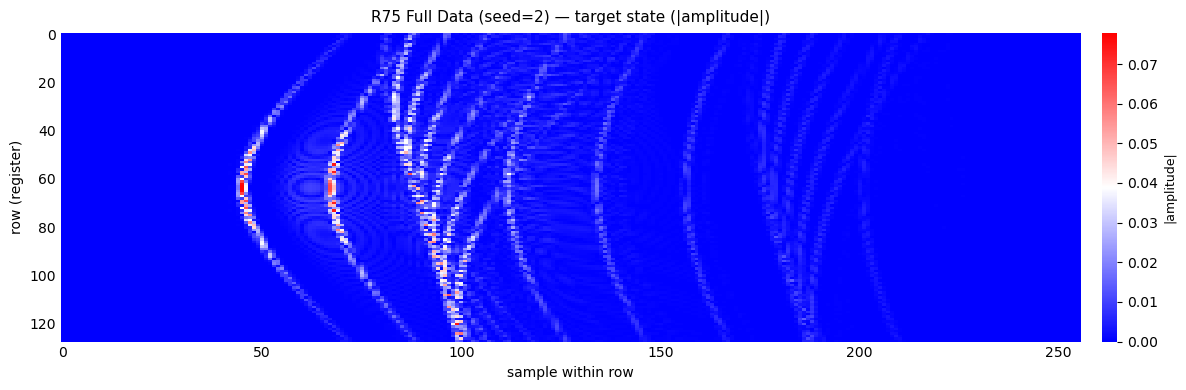

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=2)] baseline reweighting success:
[R75 Full Data (seed=2)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[ 0.00234185-2.62921700e-05j -0.00715217-2.18451300e-03j
  -0.0018599 +2.40424890e-04j ... -0.00717699+3.40602076e-03j
  -0.0038399 +2.04420633e-03j  0.00403147-1.12127977e-04j]
 [ 0.00296853+6.68157458e-03

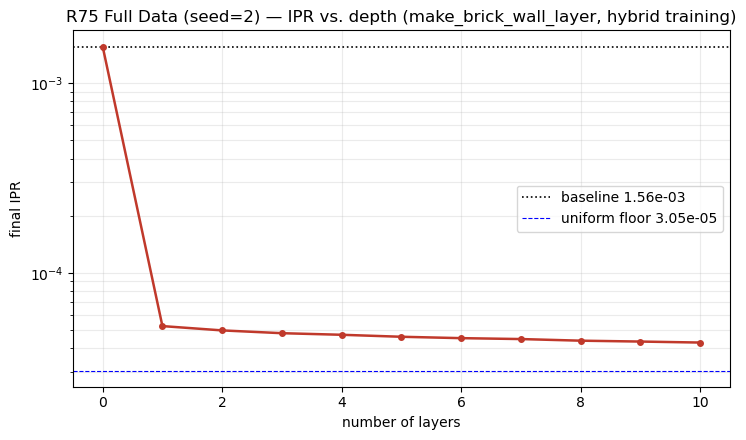

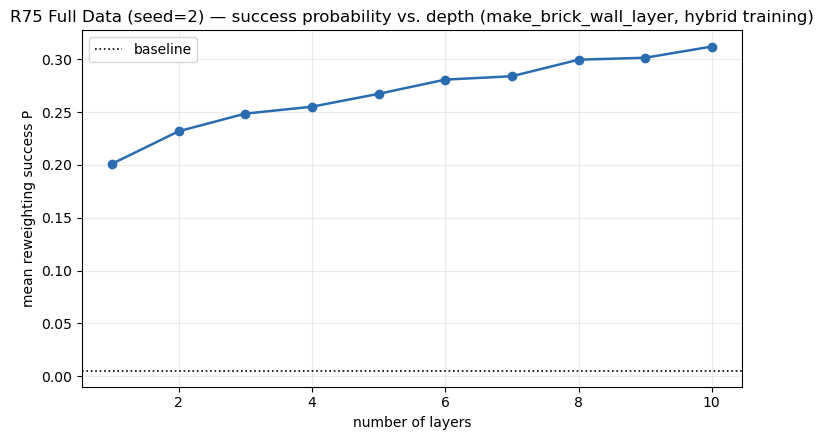

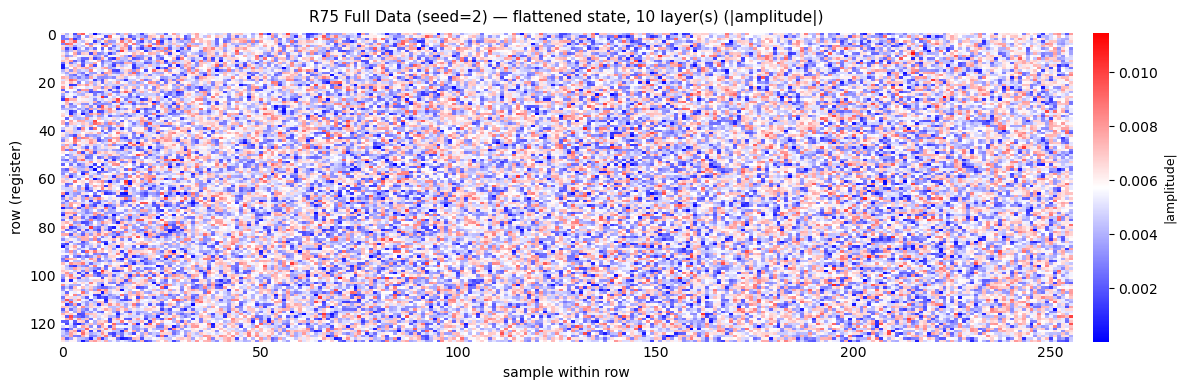

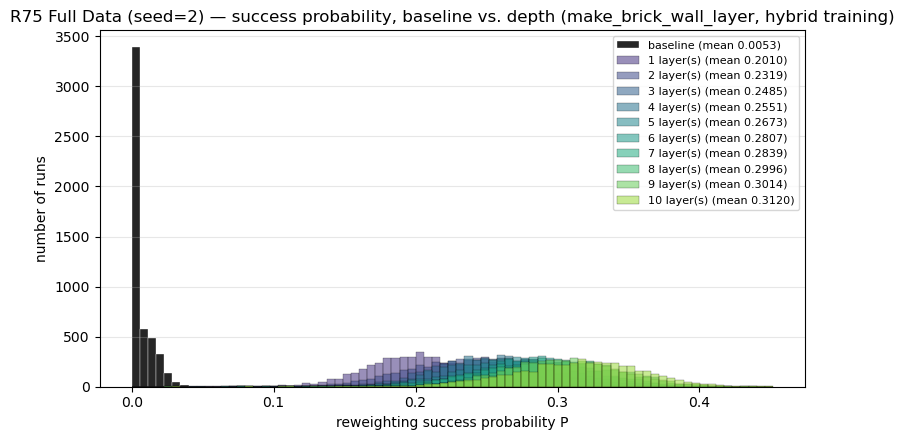

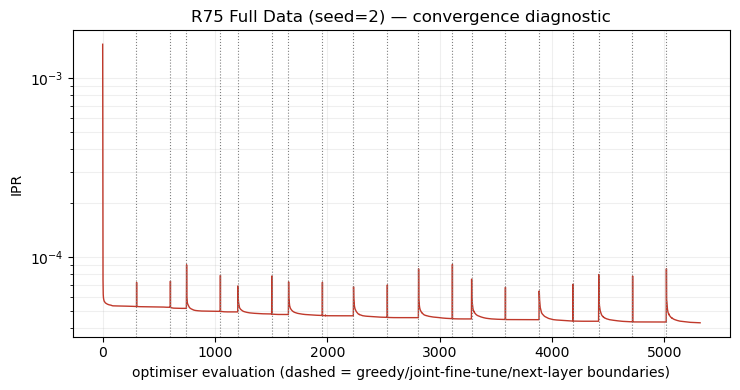


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0053                 --
      1    5.233e-05        0.2010             37.75x
      2    4.966e-05        0.2319             43.54x
      3    4.801e-05        0.2485             46.67x
      4    4.709e-05        0.2551             47.90x
      5    4.597e-05        0.2673             50.19x
      6    4.521e-05        0.2807             52.72x
      7    4.471e-05        0.2839             53.31x
      8    4.384e-05        0.2996             56.25x
      9    4.338e-05        0.3014             56.60x
     10    4.285e-05        0.3120             58.60x

best observed success probability: 0.3120 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 2: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed2.pkl  (576.5s)
  -> 10-layer success probability P = 0.3120   IPR = 4.2853e-05


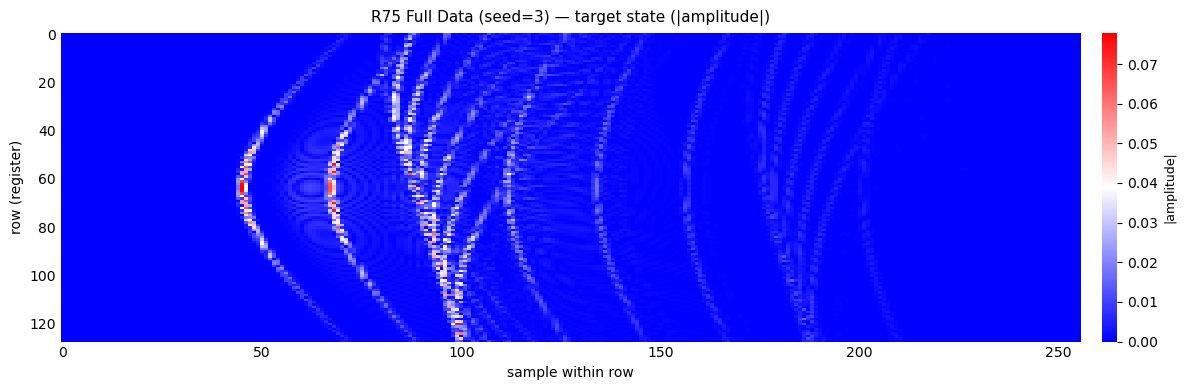

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=3)] baseline reweighting success:
[R75 Full Data (seed=3)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[-0.00215809-2.93713702e-04j -0.00082046-1.53394685e-03j
  -0.00433647-2.80095701e-03j ... -0.00594626+5.92841348e-03j
   0.00019359+2.96692080e-04j -0.00372752-1.50516446e-03j]
 [ 0.00726412-3.89752327e-03

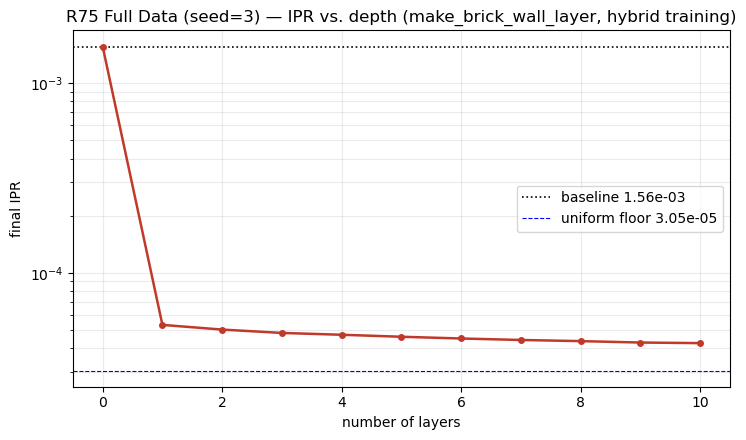

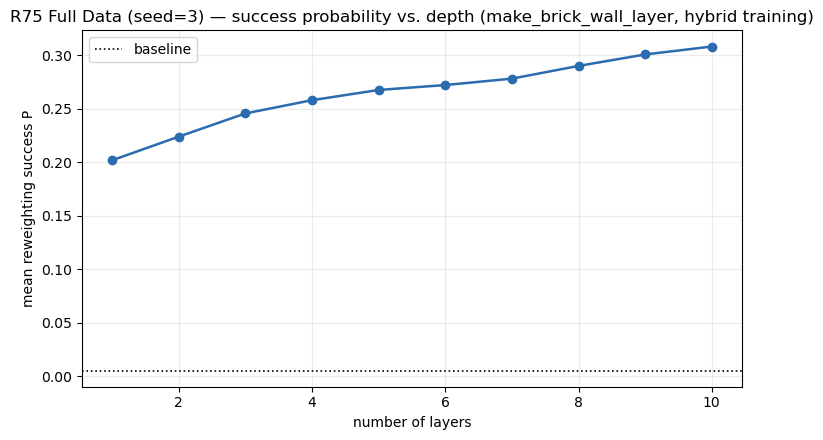

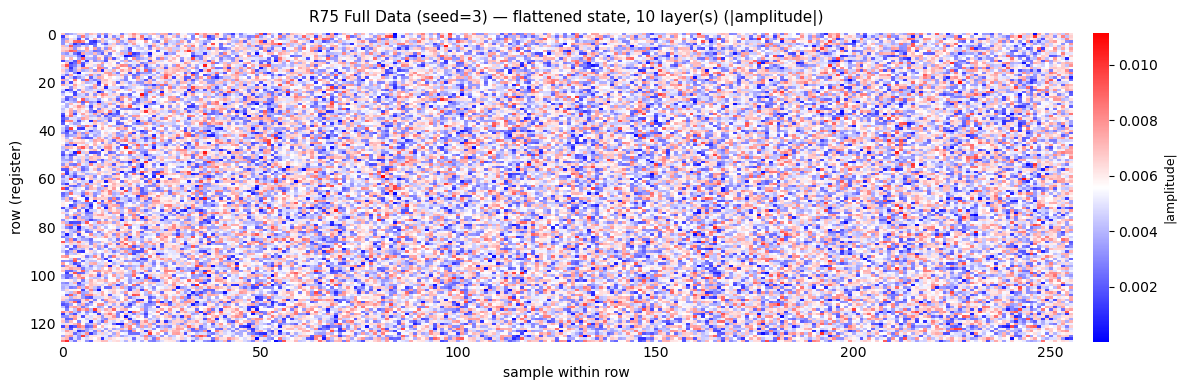

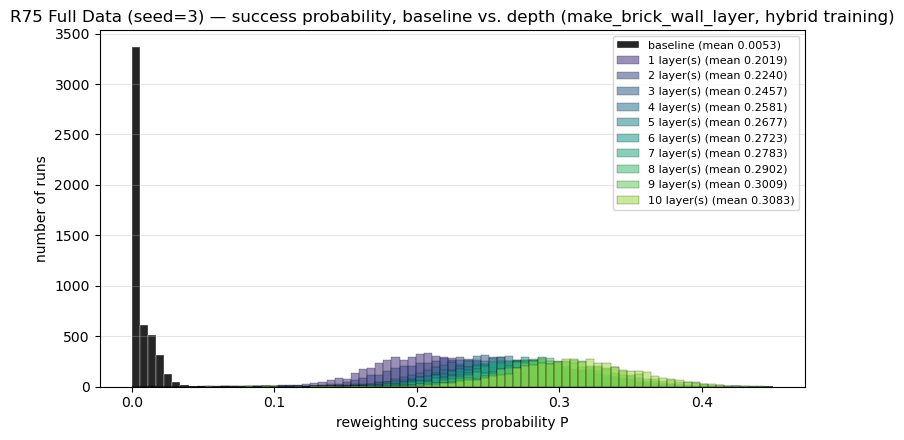

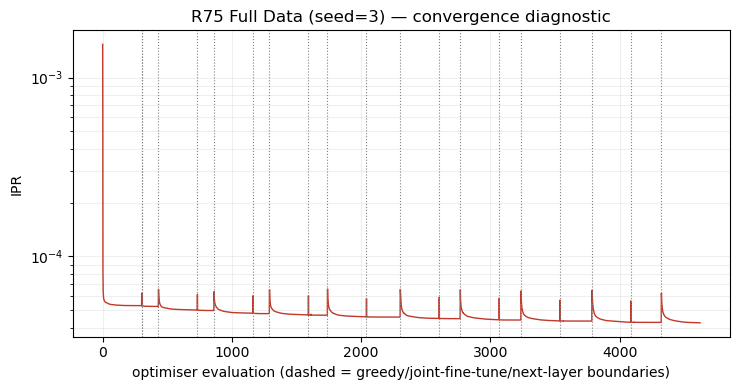


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0053                 --
      1    5.310e-05        0.2019             38.19x
      2    5.016e-05        0.2240             42.37x
      3    4.816e-05        0.2457             46.48x
      4    4.710e-05        0.2581             48.82x
      5    4.598e-05        0.2677             50.64x
      6    4.501e-05        0.2723             51.50x
      7    4.421e-05        0.2783             52.64x
      8    4.361e-05        0.2902             54.89x
      9    4.286e-05        0.3009             56.92x
     10    4.256e-05        0.3083             58.32x

best observed success probability: 0.3083 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 3: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed3.pkl  (545.4s)
  -> 10-layer success probability P = 0.3083   IPR = 4.2556e-05


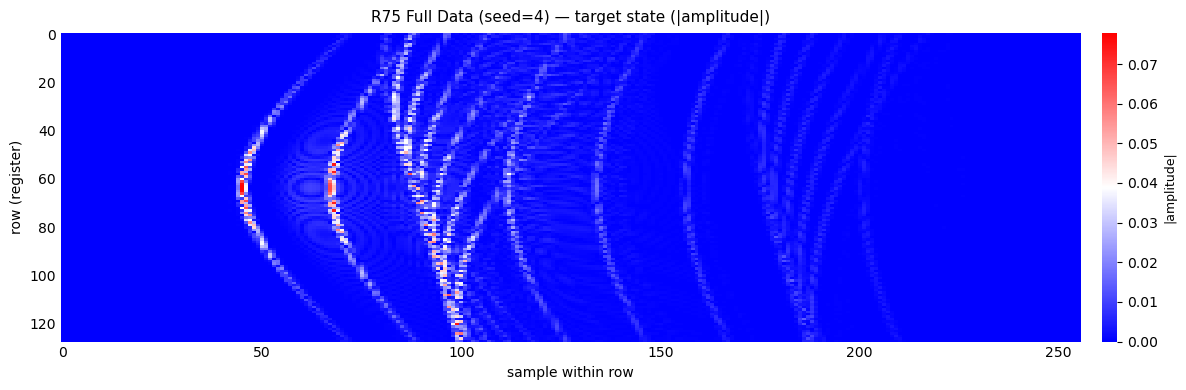

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=4)] baseline reweighting success:
[R75 Full Data (seed=4)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[ 5.61988840e-04-7.84206332e-05j -6.13700009e-03-4.19342190e-03j
  -1.26249585e-03+5.45566086e-03j ... -7.24644363e-04-2.98215209e-04j
  -6.64174426e-04+5.23517274e-03j -2.49191069e-03+9.19268701e-04j]
 [ 1

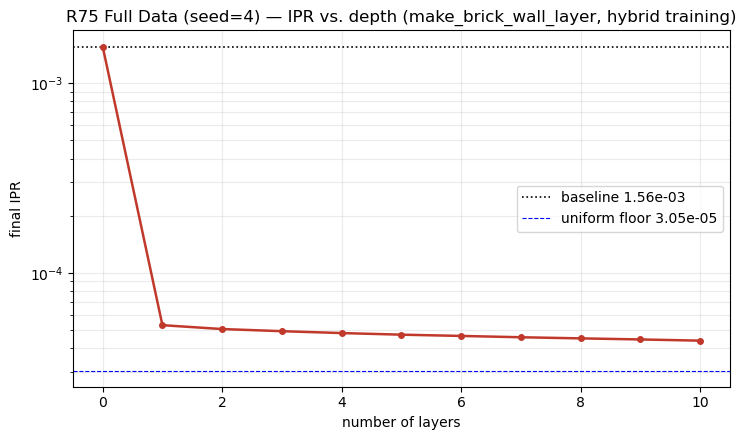

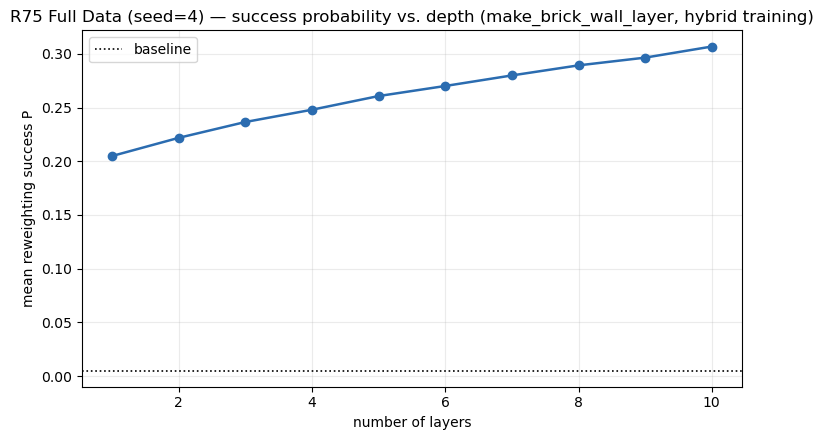

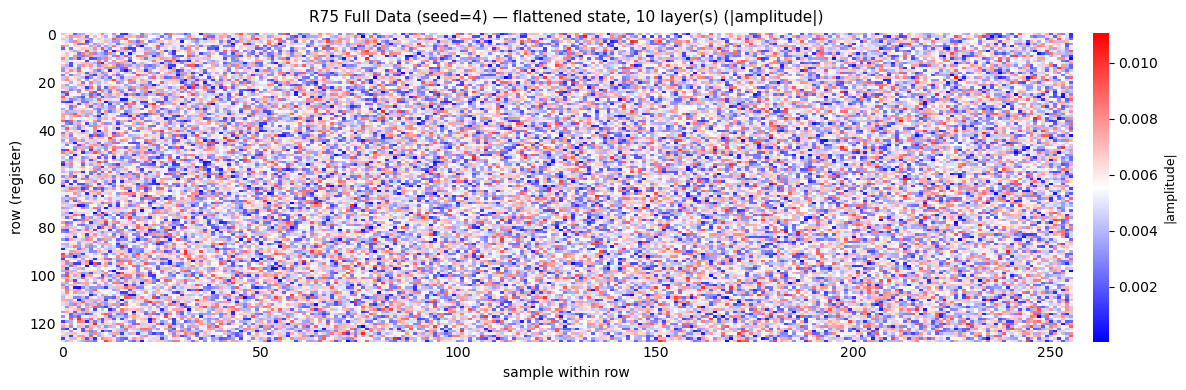

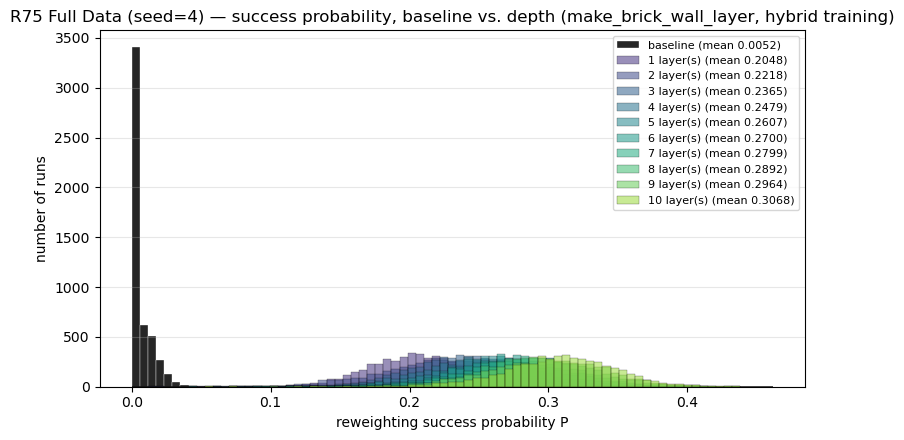

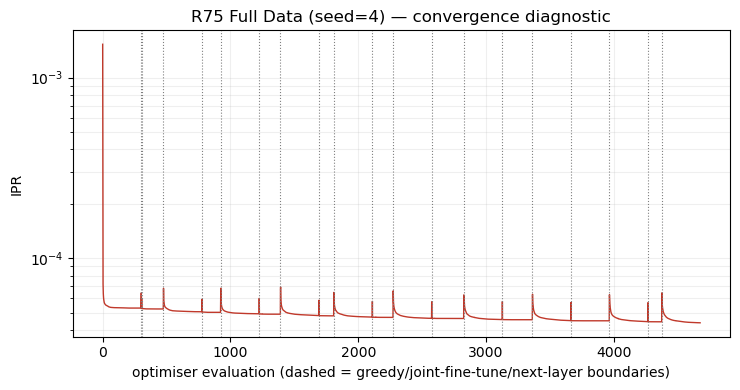


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0052                 --
      1    5.291e-05        0.2048             39.56x
      2    5.048e-05        0.2218             42.82x
      3    4.919e-05        0.2365             45.67x
      4    4.808e-05        0.2479             47.87x
      5    4.716e-05        0.2607             50.34x
      6    4.644e-05        0.2700             52.15x
      7    4.570e-05        0.2799             54.04x
      8    4.508e-05        0.2892             55.85x
      9    4.450e-05        0.2964             57.24x
     10    4.385e-05        0.3068             59.24x

best observed success probability: 0.3068 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 4: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed4.pkl  (543.7s)
  -> 10-layer success probability P = 0.3068   IPR = 4.3852e-05


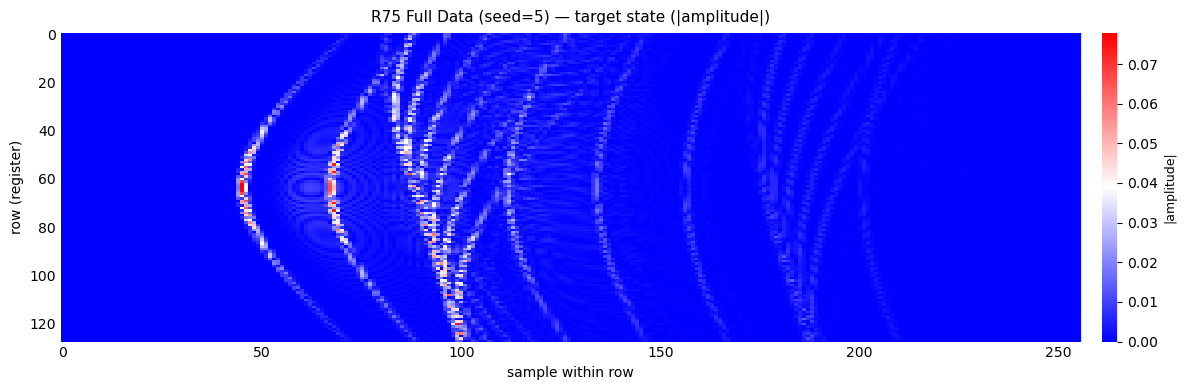

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=5)] baseline reweighting success:
[R75 Full Data (seed=5)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[ 0.00371372+0.00526606j -0.00010191+0.00459906j  0.002446  +0.00258799j
  ... -0.0050746 -0.00084155j  0.00050471+0.00234083j
   0.01015083-0.001305j  ]
 [ 0.00501032-0.00844621j -0.00581211-0.00134794j  0

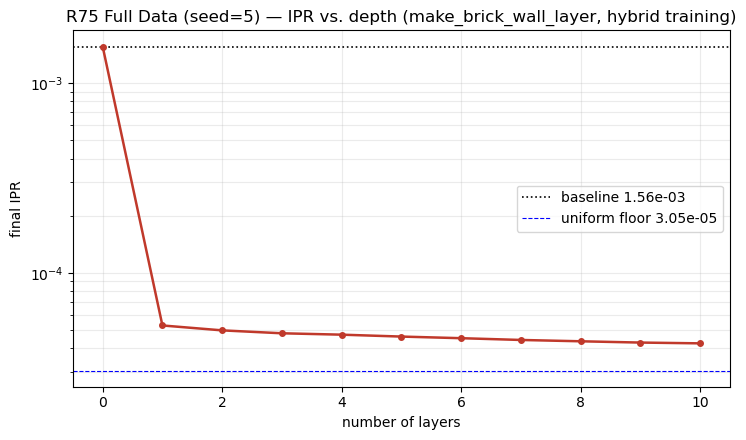

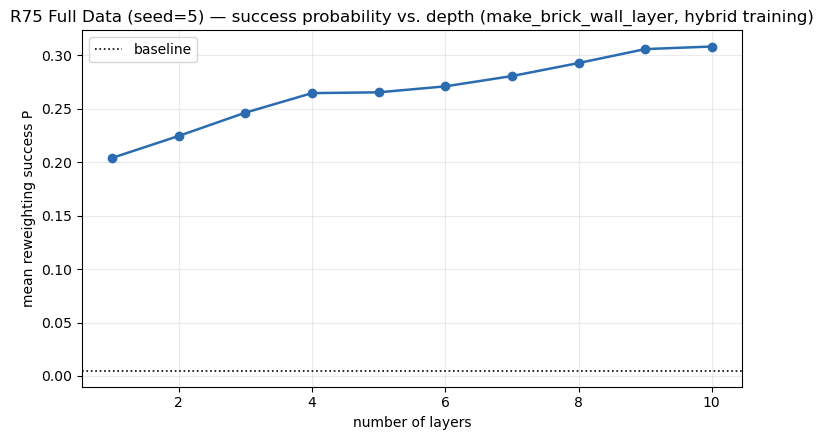

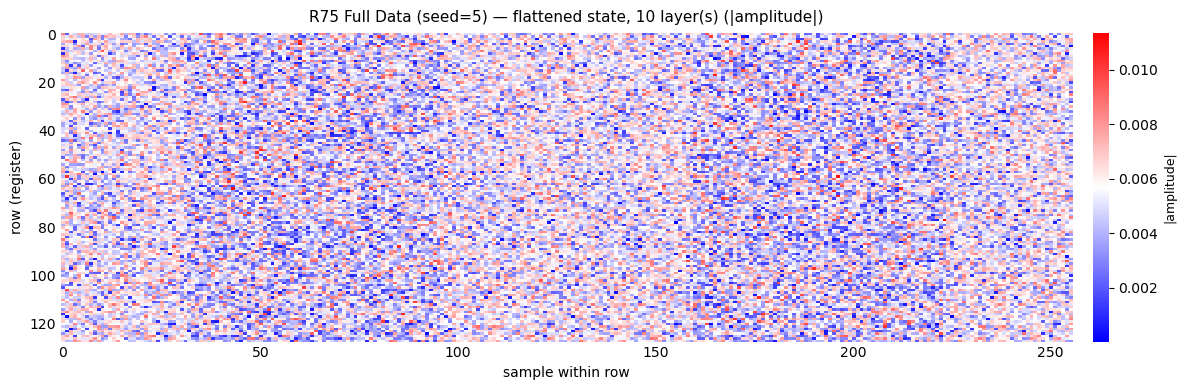

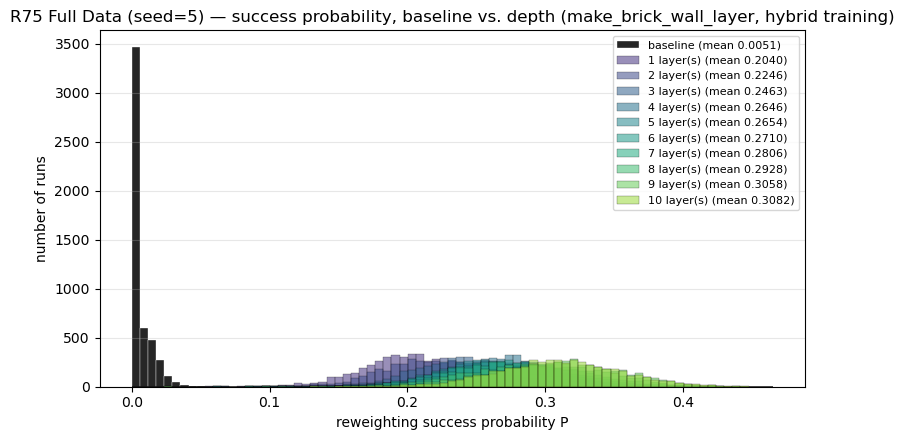

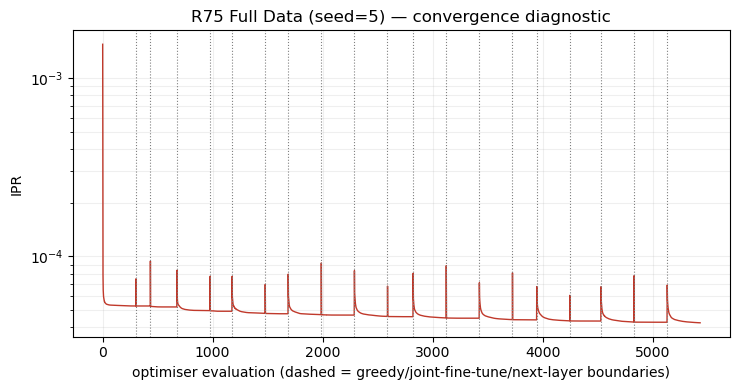


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0051                 --
      1    5.273e-05        0.2040             39.85x
      2    4.968e-05        0.2246             43.87x
      3    4.795e-05        0.2463             48.12x
      4    4.715e-05        0.2646             51.69x
      5    4.608e-05        0.2654             51.84x
      6    4.518e-05        0.2710             52.93x
      7    4.422e-05        0.2806             54.81x
      8    4.352e-05        0.2928             57.19x
      9    4.285e-05        0.3058             59.74x
     10    4.244e-05        0.3082             60.21x

best observed success probability: 0.3082 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 5: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed5.pkl  (561.4s)
  -> 10-layer success probability P = 0.3082   IPR = 4.2440e-05


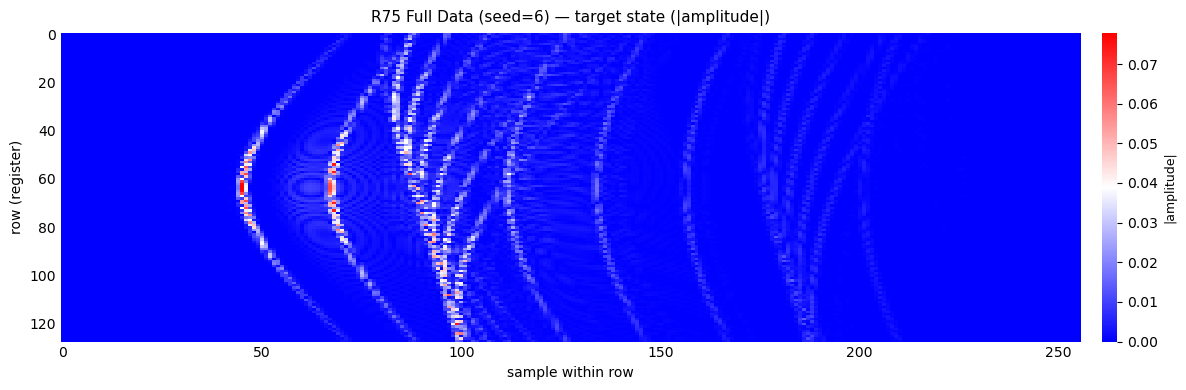

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=6)] baseline reweighting success:
[R75 Full Data (seed=6)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[ 3.20364370e-03-0.00138236j -4.70475514e-03+0.00577421j
  -2.73865570e-03+0.00794018j ...  1.92013682e-03-0.00351227j
  -7.69106644e-04+0.00175181j  1.98943806e-04-0.00370839j]
 [-8.85174773e-04-0.00520789

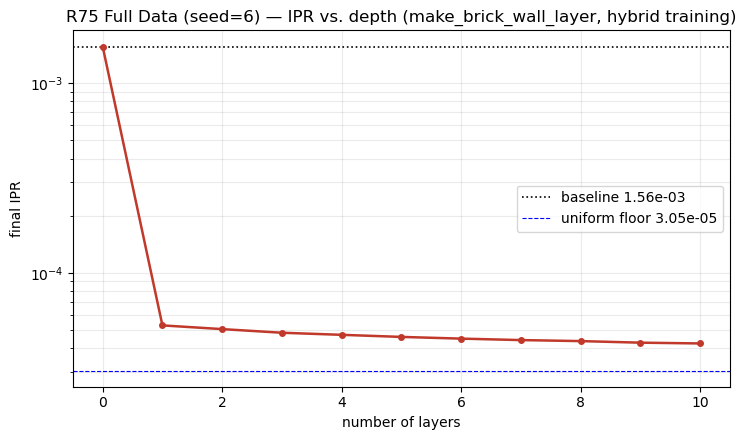

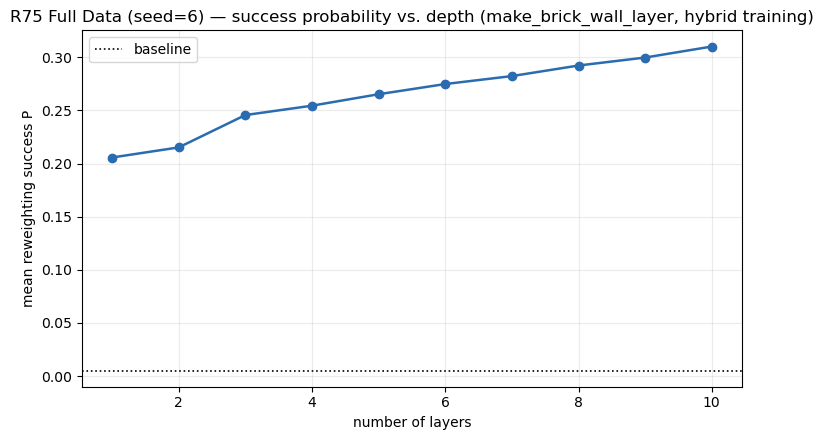

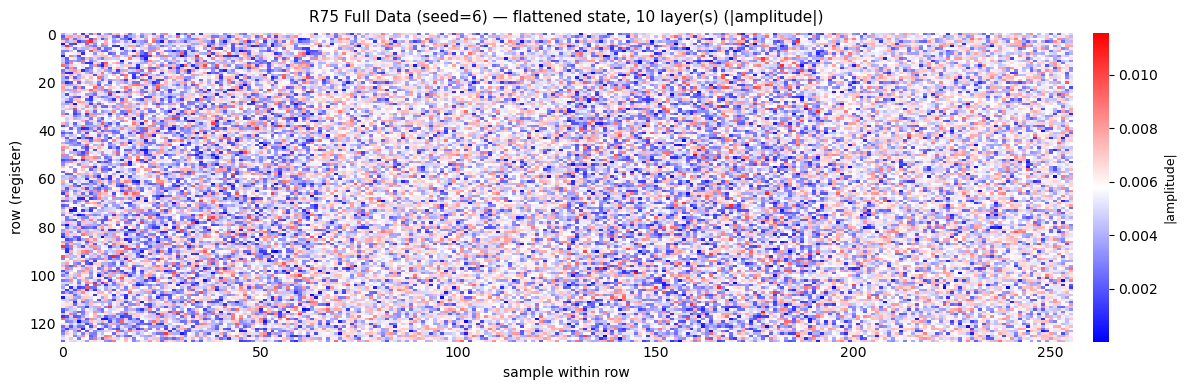

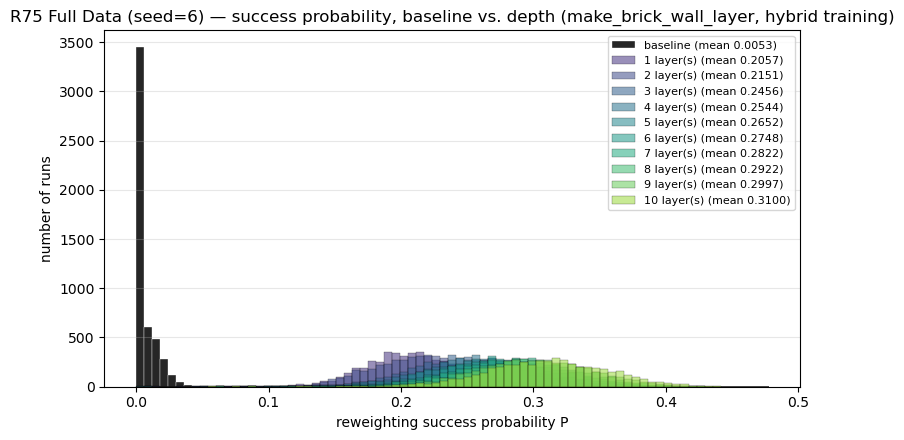

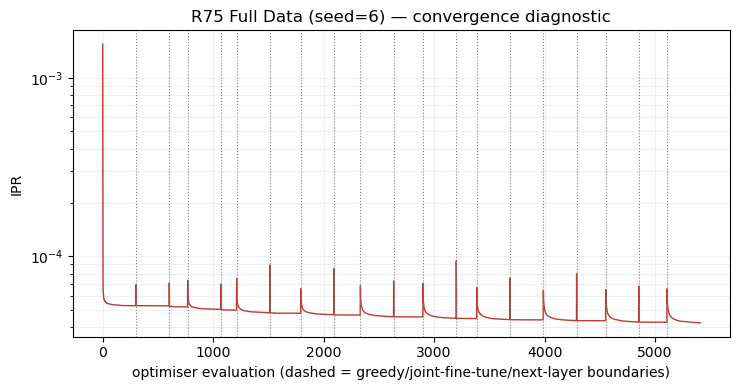


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0053                 --
      1    5.277e-05        0.2057             39.08x
      2    5.045e-05        0.2151             40.88x
      3    4.827e-05        0.2456             46.67x
      4    4.707e-05        0.2544             48.34x
      5    4.589e-05        0.2652             50.39x
      6    4.495e-05        0.2748             52.22x
      7    4.416e-05        0.2822             53.64x
      8    4.362e-05        0.2922             55.53x
      9    4.279e-05        0.2997             56.95x
     10    4.239e-05        0.3100             58.92x

best observed success probability: 0.3100 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 6: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed6.pkl  (561.3s)
  -> 10-layer success probability P = 0.3100   IPR = 4.2392e-05


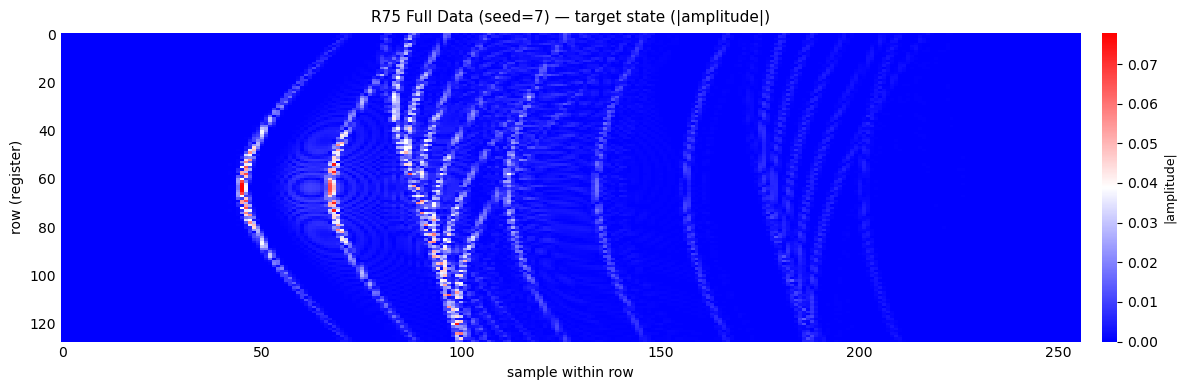

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=7)] baseline reweighting success:
[R75 Full Data (seed=7)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[-0.00148946+0.00611802j  0.00204741-0.00610244j -0.00055592-0.002022j
  ...  0.00283034-0.00368031j  0.00936483+0.0016037j
   0.00277504-0.00163666j]
 [ 0.00569598+0.00188741j -0.00138413-0.00751092j -0.00

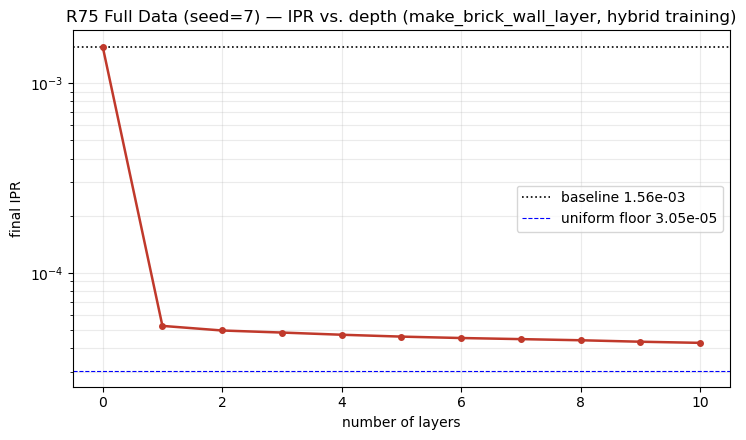

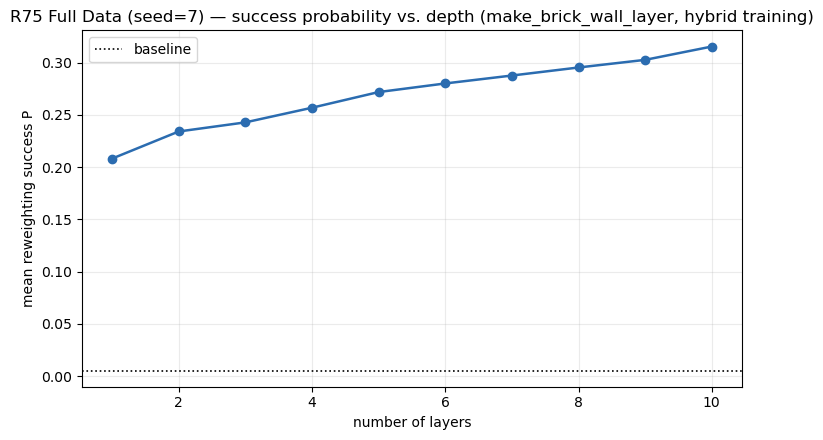

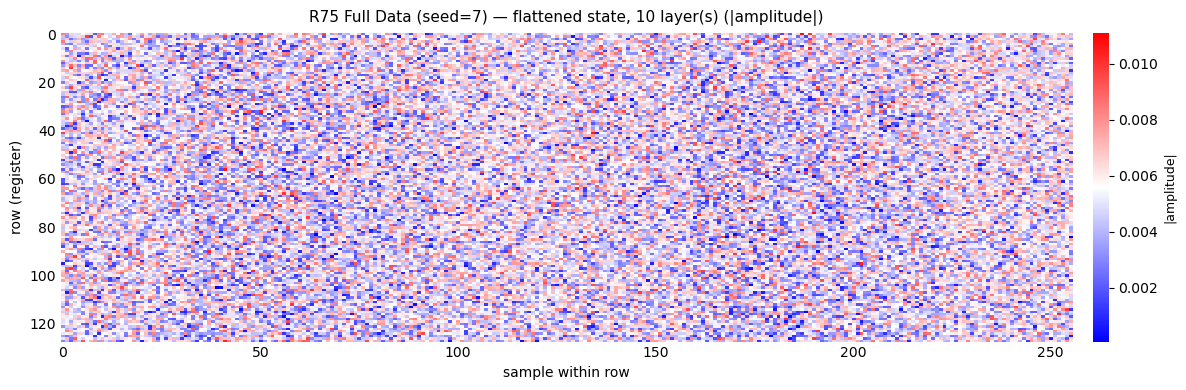

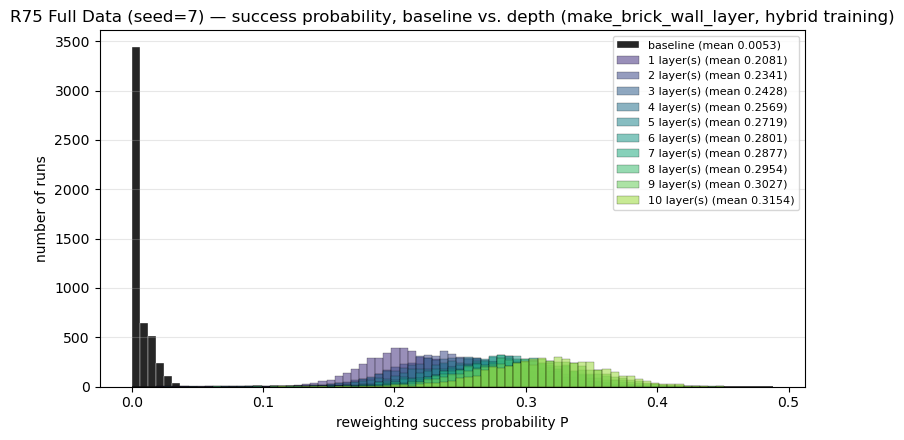

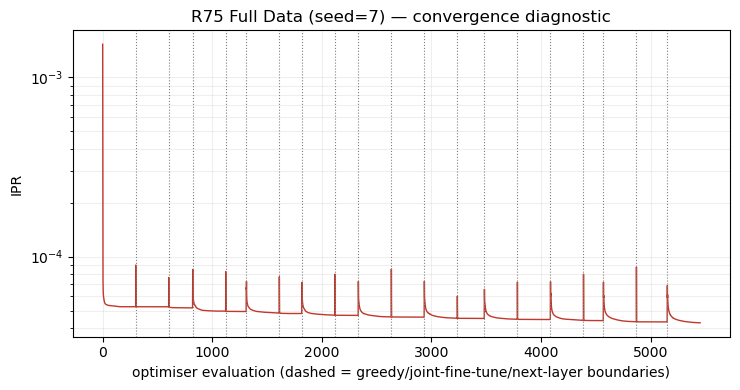


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0053                 --
      1    5.246e-05        0.2081             39.64x
      2    4.961e-05        0.2341             44.58x
      3    4.838e-05        0.2428             46.24x
      4    4.711e-05        0.2569             48.91x
      5    4.606e-05        0.2719             51.77x
      6    4.528e-05        0.2801             53.34x
      7    4.468e-05        0.2877             54.78x
      8    4.407e-05        0.2954             56.25x
      9    4.329e-05        0.3027             57.64x
     10    4.269e-05        0.3154             60.07x

best observed success probability: 0.3154 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 7: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed7.pkl  (566.5s)
  -> 10-layer success probability P = 0.3154   IPR = 4.2694e-05


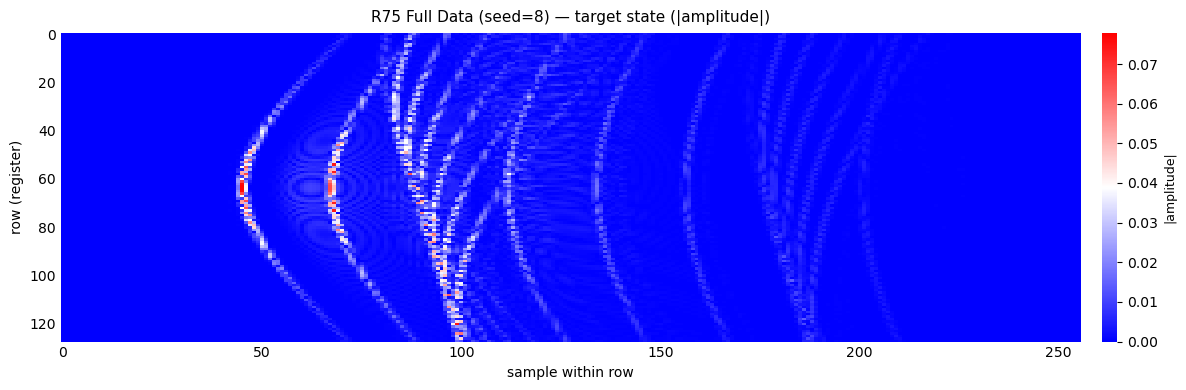

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=8)] baseline reweighting success:
[R75 Full Data (seed=8)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[ 1.66493503e-03-0.00260706j  3.28698984e-05+0.00232551j
   2.96780455e-03+0.0040568j  ... -4.22865804e-03+0.00393385j
  -5.73067320e-03+0.00064493j  2.04272456e-03+0.00169482j]
 [ 2.39524658e-03-0.00262582

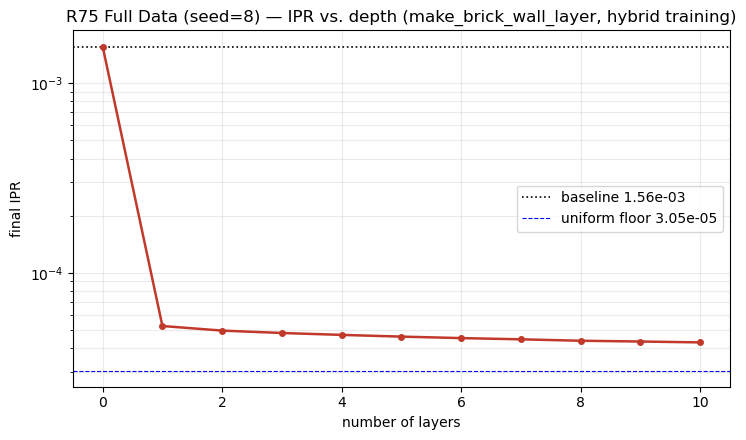

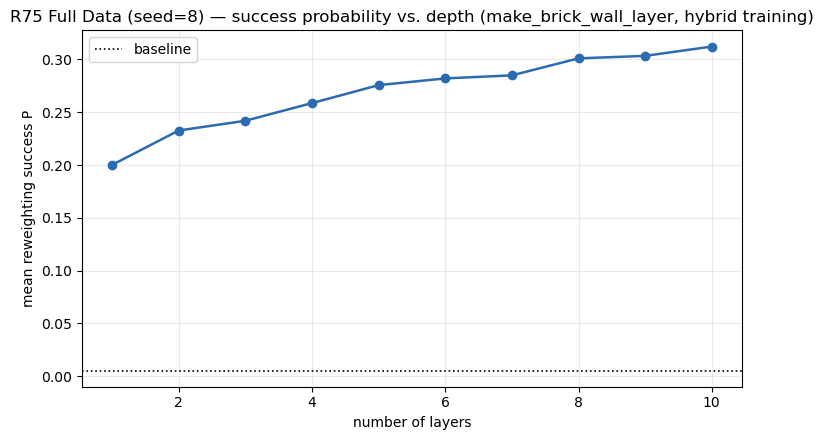

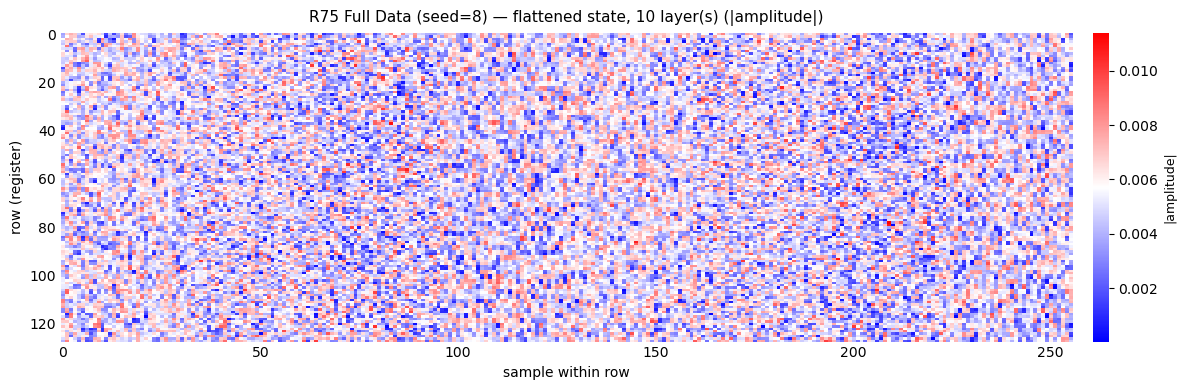

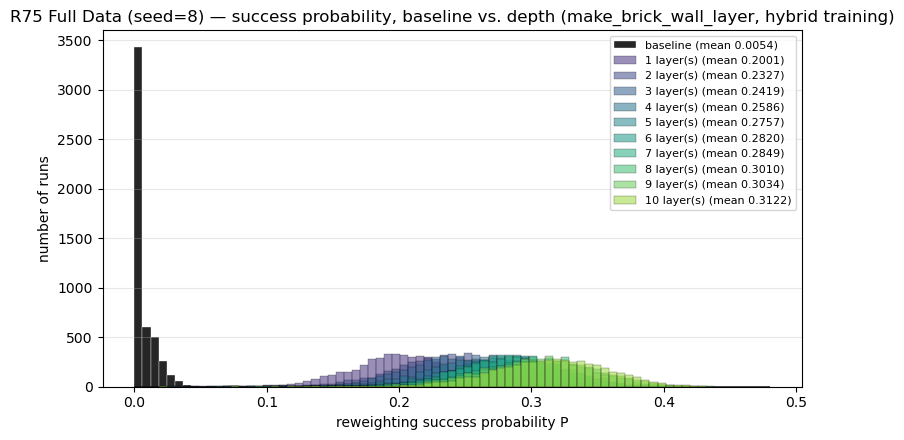

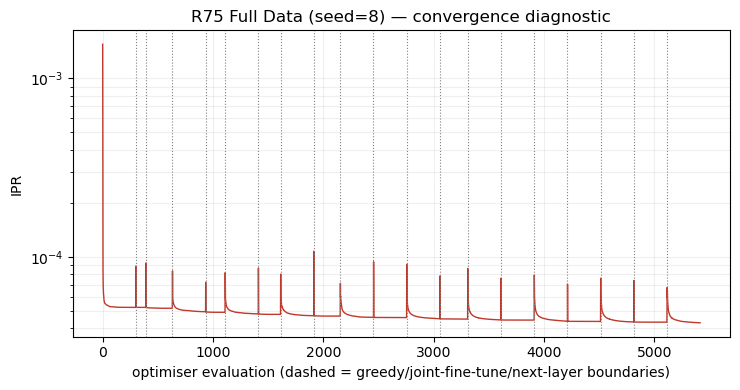


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0054                 --
      1    5.238e-05        0.2001             37.13x
      2    4.954e-05        0.2327             43.18x
      3    4.813e-05        0.2419             44.89x
      4    4.703e-05        0.2586             48.00x
      5    4.605e-05        0.2757             51.16x
      6    4.524e-05        0.2820             52.33x
      7    4.457e-05        0.2849             52.87x
      8    4.380e-05        0.3010             55.86x
      9    4.339e-05        0.3034             56.29x
     10    4.294e-05        0.3122             57.94x

best observed success probability: 0.3122 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 8: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed8.pkl  (562.0s)
  -> 10-layer success probability P = 0.3122   IPR = 4.2936e-05


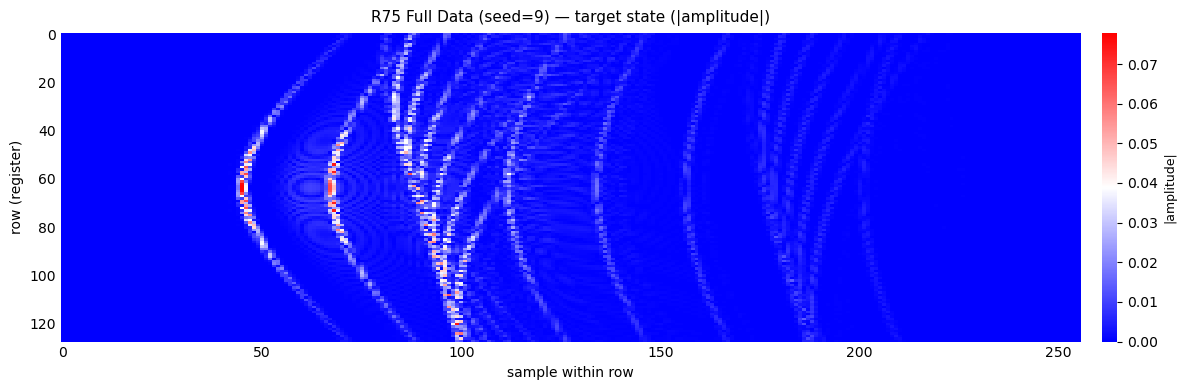

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (seed=9)] baseline reweighting success:
[R75 Full Data (seed=9)] training up to 10 layers (make_brick_wall_layer, hybrid, plateau-guarded)...
[[-1.64552009e-03-0.00102734j  3.18546576e-03-0.00018169j
  -2.25928932e-03+0.00473344j ... -4.73254778e-03+0.00739853j
  -4.32596044e-04+0.00063727j  4.17163055e-03+0.00423157j]
 [ 5.50893942e-03-0.00137638

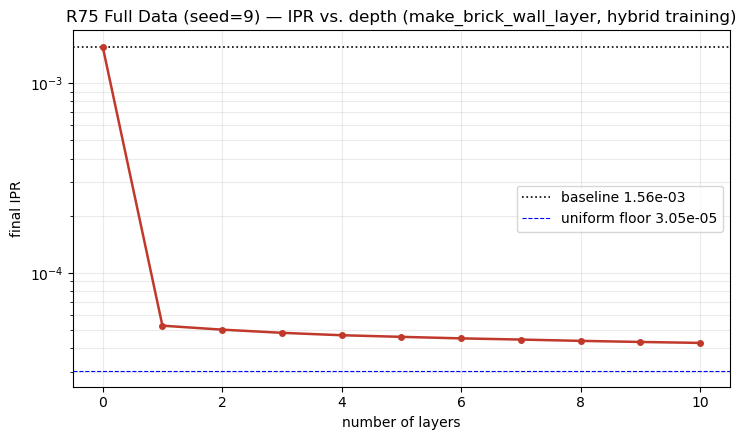

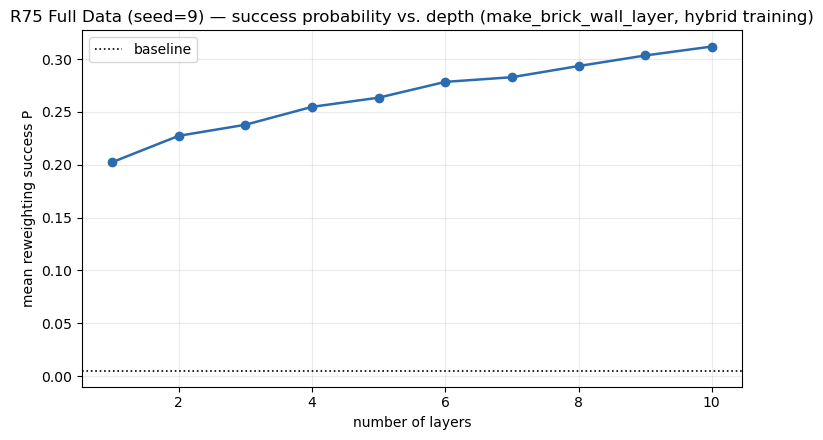

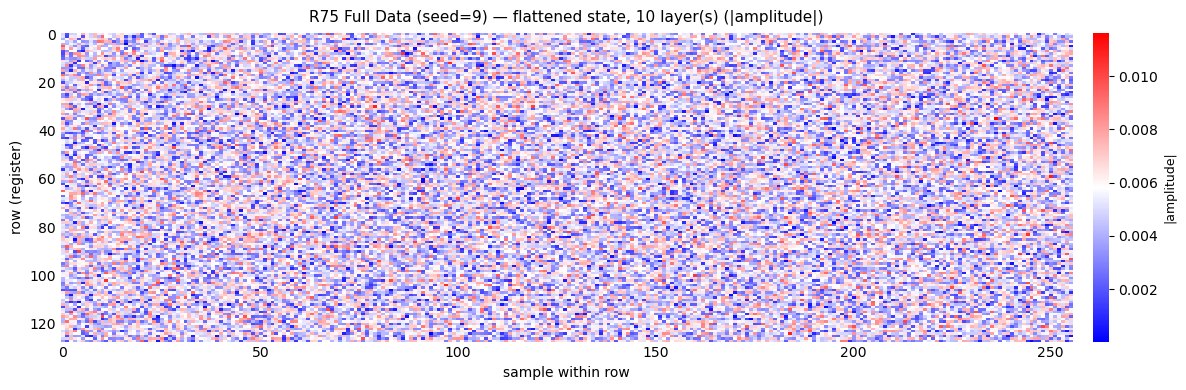

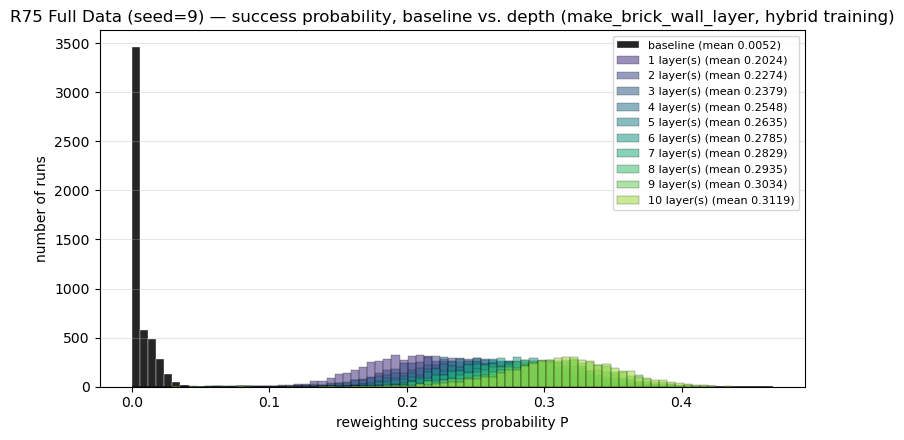

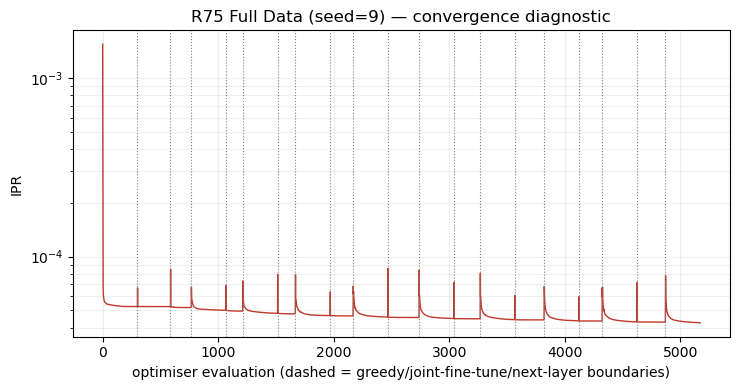


 layers          IPR  mean success   gain vs baseline
   base    1.557e-03        0.0052                 --
      1    5.260e-05        0.2024             38.79x
      2    5.012e-05        0.2274             43.58x
      3    4.823e-05        0.2379             45.58x
      4    4.683e-05        0.2548             48.83x
      5    4.593e-05        0.2635             50.50x
      6    4.508e-05        0.2785             53.36x
      7    4.444e-05        0.2829             54.21x
      8    4.374e-05        0.2935             56.24x
      9    4.316e-05        0.3034             58.15x
     10    4.267e-05        0.3119             59.78x

best observed success probability: 0.3119 at 10 layer(s) (NOT necessarily the deepest -- check this before assuming more layers = better)
seed 9: done and saved to C:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\results\v_full_seed9.pkl  (554.5s)
  -> 10-layer success probability P = 0.3119   IPR = 4.2671e-05

(total 5623.2s)
 s

In [45]:
#ITERATIVE RUN TO GET BEST IPR REDUCTOIN
import pickle, os, time

TRIAL_SEEDS = list(range(10))   # 10 independent trials
RESULTS_DIR = os.path.join(os.getcwd(), "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

summary_rows = []
t0 = time.time()
for seed in TRIAL_SEEDS:
    save_path = os.path.join(RESULTS_DIR, f"v_full_seed{seed}.pkl")
    if os.path.exists(save_path):
        with open(save_path, "rb") as f:
            data = pickle.load(f)
        layer_results, base_result, seq = data["layer_results"], data["base_result"], data["seq"]
        print(f"seed {seed}: already done (loaded from disk)")
    else:
        tt0 = time.time()
        layer_results, base_result, seq = compare_flatten_layers(
            Y_full, layer_counts=(1,2,3,4,5,6,7,8,9,10), name=f"R75 Full Data (seed={seed})",
            n_shots=5000, n_iter=300, seed=seed,
        )
        with open(save_path, "wb") as f:
            pickle.dump({"layer_results": layer_results, "base_result": base_result, "seq": seq}, f)
        print(f"seed {seed}: done and saved to {save_path}  ({time.time()-tt0:.1f}s)")

    L10 = layer_results[10]
    summary_rows.append({"seed": seed, "P_10": L10["res"]["mean"], "IPR_10": L10["ipr"], "save_path": save_path})
    print(f"  -> 10-layer success probability P = {L10['res']['mean']:.4f}   IPR = {L10['ipr']:.4e}")

print(f"\n(total {time.time()-t0:.1f}s)")
summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

best_row = summary_df.loc[summary_df["P_10"].idxmax()]
print(f"\nBEST: seed={int(best_row['seed'])}  P={best_row['P_10']:.4f}  saved at {best_row['save_path']}")


In [46]:
with open(best_row["save_path"], "rb") as f:
    best_data = pickle.load(f)
layer_results_best, base_result_best, seq_best = best_data["layer_results"], best_data["base_result"], best_data["seq"]
psi_flat_10_best = layer_results_best[10]["psi_flat"]
Y_flat_10_best = layer_results_best[10]["Y_flat"]
print(f"loaded best (seed={int(best_row['seed'])}): P={layer_results_best[10]['res']['mean']:.4f}")


loaded best (seed=7): P=0.3154


saved -> PreConditioning Boost.pdf


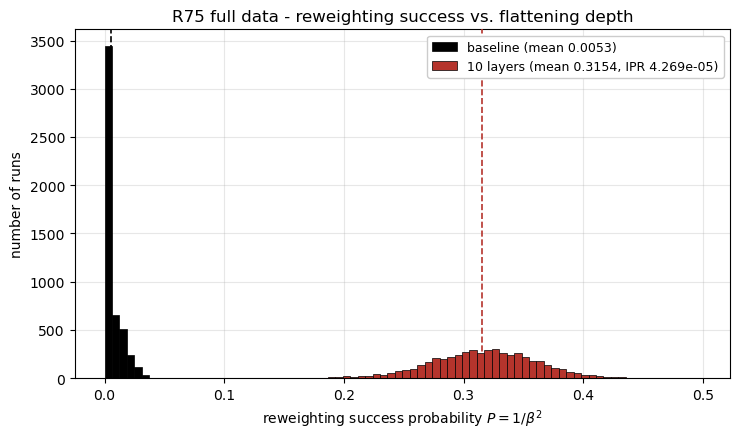

 layers    mean P    median   gain vs baseline
   base    0.0053    0.0005                 --
     10    0.3154    0.3173              60.1x


In [28]:
# --- reweighting success histogram, selected depths (0 = baseline, no flattening) ---
import numpy as np, matplotlib.pyplot as plt

SHOW_LAYERS     = [0, 10]                    # 0 = baseline; others index layer_results
BASE_COLOR      = "#000000"                  # baseline
NON_BASE_COLORS = ["#b5342c", "#3a7ebf"]     # one color per non-baseline layer, in order
EDGE_LW         = 0.5                        # black bar outline
NBINS           = 80
LOG_Y           = False                      # True if the baseline spike squashes everything else
SAVE_AS         = None                       # e.g. "GQSPfidelity to target state.pdf"

def plot_success_hist(layer_results, base_result, show_layers=SHOW_LAYERS,
                      nbins=NBINS, log_y=LOG_Y, name="R75 full data", save_as=SAVE_AS,
                      base_color=BASE_COLOR, colors=NON_BASE_COLORS, edge_lw=EDGE_LW):
    missing = [L for L in show_layers if L != 0 and L not in layer_results]
    if missing:
        raise ValueError(f"no results for layer(s) {missing}; have {sorted(layer_results)}")

    series = []
    for L in show_layers:
        if L == 0:
            series.append((L, np.asarray(base_result["P"]), base_result["mean"], None))
        else:
            r = layer_results[L]
            series.append((L, np.asarray(r["res"]["P"]), r["res"]["mean"], r.get("ipr")))

    lo = min(P.min() for _, P, _, _ in series)
    hi = max(P.max() for _, P, _, _ in series)
    bins = np.linspace(lo, hi * 1.02, nbins + 1)

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ci = 0
    for L, P, mean, ipr in series:
        if L == 0:
            c, lab = base_color, f"baseline (mean {mean:.4f})"
        else:
            c = colors[ci % len(colors)]; ci += 1
            lab = f"{L} layer{'s' if L > 1 else ''} (mean {mean:.4f}"
            lab += f", IPR {ipr:.3e})" if ipr is not None else ")"
        ax.hist(P, bins=bins, color=c, alpha=1.0, edgecolor="black", lw=edge_lw,
                label=lab, zorder=2)
        ax.axvline(mean, color=c, ls="--", lw=1.2, zorder=3)

    if log_y:
        ax.set_yscale("log")
    ax.set_xlabel("reweighting success probability $P = 1/\\beta^2$")
    ax.set_ylabel("number of runs")
    ax.set_title(f"{name} - reweighting success vs. flattening depth")
    ax.legend(fontsize=9, framealpha=1.0, loc="upper right")
    ax.grid(alpha=0.3, zorder=0)
    plt.tight_layout()
    if save_as:
        fig.savefig(save_as, dpi=200, bbox_inches="tight"); print("saved ->", save_as)
    plt.show()

    print(f"{'layers':>7s} {'mean P':>9s} {'median':>9s} {'gain vs baseline':>18s}")
    for L, P, mean, _ in series:
        tag  = "base" if L == 0 else str(L)
        gain = "--" if L == 0 else f"{mean/base_result['mean']:.1f}x"
        print(f"{tag:>7s} {mean:>9.4f} {np.median(P):>9.4f} {gain:>18s}")

plot_success_hist(layer_results, base_result, save_as="PreConditioning Boost.pdf")


## Doing the same as above for V partial

> ✅ **`V_partial` was never affected.** `optimise_flatten_layers_hybrid_storage` below
> already passes `constant_tags=["ID"]` (that is what freezes the index qubits at identity),
> which incidentally also froze the brick wall's padding identities. Its results stand,
> including the P = 0.0866 figure quoted in the paper.

In [24]:
def optimise_flatten_layers_hybrid_storage(mps, n_index, max_layers, n_iter=200, eps_init=1e-2,
                                            seed=0, tol=1e-14, verbose=False,
                                            plateau_rel_tol=1e-3, plateau_patience=2):
    """Same greedy-warm-start + joint-fine-tune hybrid strategy as optimise_flatten_layers_hybrid,
       restricted to storage qubits via constant_tags=['ID'] (freezes index qubits AND any
       untouched edge qubit at exact identity every round). Uses the same per-layer internal-bond
       namespacing fix as the full-flatten version to avoid cross-layer bond collisions when
       stacking. Also rejects any round that makes IPR worse than the previous accepted round,
       and stops adding layers once IPR improvement plateaus -- see optimise_flatten_layers_hybrid
       for why."""
    n = mps.L

    def ipr_of_op(op, target_mps):
        psi = dense_state_from_op_mps(op, target_mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return (torch.abs(psi) ** 4).sum()

    def optimise_stack(stack_init, target_mps, n_iter_, history):
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = ipr_of_op(op, init_tn); s = float(val.detach()); history.append(s)
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        qtn.TNOptimizer(stack_init, loss, loss_constants={"init_tn": target_mps},
                         constant_tags=["ID"],                       # <-- CRUCIAL: index qubits stay identity
                         optimizer="l-bfgs-b", autodiff_backend="torch", progbar=verbose).optimize(n=n_iter_, tol=tol)
        if best["params"] is not None:
            stack_init.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            return stack_init, best["val"]
        return stack_init, float(ipr_of_op(stack_init, target_mps).detach())

    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)
    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]
    full_history, layer_boundaries = [], [0]
    stack = None
    stall_count = 0
    for L in range(max_layers):
        new_layer = make_brick_wall_layer_storage(n, n_index, eps=eps_init, seed=seed + L)
        new_layer, ipr_greedy = optimise_stack(new_layer, current_mps, n_iter, full_history)
        layer_boundaries.append(len(full_history))

        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})

        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))

        candidate, ipr_joint = optimise_stack(candidate, mps, n_iter, full_history)
        layer_boundaries.append(len(full_history))

        prev_ipr = per_layer_ipr[-1]
        if ipr_joint <= prev_ipr:
            stack = candidate
            accepted_ipr = ipr_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_ipr = prev_ipr
            if verbose:
                print(f"  layer {L+1}: regression ({ipr_joint:.4e} > {prev_ipr:.4e}), rejected, keeping previous stack")

        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_ipr.append(accepted_ipr)
        per_layer_psi.append(psi_now)

        rel_improve = (prev_ipr - accepted_ipr) / prev_ipr if prev_ipr > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if verbose:
            print(f"  layer {L+1}/{max_layers}: greedy IPR={ipr_greedy:.4e}  after joint fine-tune={ipr_joint:.4e}  "
                  f"accepted={accepted_ipr:.4e}  rel_improve={rel_improve:.2%}  stall={stall_count}")

        if stall_count >= plateau_patience:
            if verbose:
                print(f"  IPR plateaued -- stopping at layer {L+1}/{max_layers}, remaining layer counts repeat this state")
            while len(per_layer_ipr) <= max_layers:
                per_layer_ipr.append(per_layer_ipr[-1])
                per_layer_psi.append(per_layer_psi[-1])
            break

    return {"per_layer_ipr": per_layer_ipr, "per_layer_psi": per_layer_psi,
            "history": full_history, "layer_boundaries": layer_boundaries}


def compare_storage_layers(Y, layer_counts=(1, 2, 3), name="state",
                            n_shots=5000, n_iter=200, seed=0, eps_init=1e-2, tol=1e-14):
    """Storage-only (V-partial) counterpart of compare_flatten_layers: same pipeline, same
       outputs, but V acts only on the storage (within-row) qubits -- so sigma / which register
       each amplitude belongs to is provably untouched (checked per layer count below)."""
    Y = np.asarray(Y); N, M = Y.shape
    n = int(round(np.log2(M * N)))
    n_index = int(round(np.log2(M)))
    print(f"[{name}] index qubits 0..{n_index-1} (identity) | storage qubits {n_index}..{n-1} (brick-wall)")

    _display_state(Y, f"{name} target")
    v = np.asarray(Y, dtype=np.complex128).T.flatten(); v /= np.linalg.norm(v)
    mps = qtn.MatrixProductState.from_dense(v.reshape([2] * n), dims=[2] * n)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    ipr_base = float(np.sum(np.abs(v) ** 4))

    sigma0, chunks0 = extract_row_weights(Y)
    print(f"[{name}] baseline reweighting success:")
    res_base = success_distribution(chunks0, sigma0, n_shots=n_shots, seed=seed, plot=False)

    max_L = max(layer_counts)
    print(f"[{name}] training up to {max_L} storage-only brick-wall layers (hybrid, plateau-guarded)...")
    seq = optimise_flatten_layers_hybrid_storage(mps, n_index, max_layers=max_L, n_iter=n_iter,
                                                  eps_init=eps_init, seed=seed, tol=tol, verbose=False)

    results = {}
    for L in layer_counts:
        psi_flat = seq["per_layer_psi"][L]
        Y_flat = psi_flat.reshape(M, N).T
        sigmaF, chunksF = extract_row_weights(Y_flat)
        sigma_ok = bool(np.allclose(sigma0, sigmaF, atol=1e-8))
        res = success_distribution(chunksF, sigmaF, n_shots=n_shots, seed=seed, plot=False)
        results[L] = {"psi_flat": psi_flat, "Y_flat": Y_flat, "ipr": seq["per_layer_ipr"][L],
                       "res": res, "sigma_preserved": sigma_ok}
        print(f"  {L} layer(s): IPR {ipr_base:.3e} -> {results[L]['ipr']:.3e}   "
              f"success {res_base['mean']:.4f} -> {res['mean']:.4f}  ({res['mean']/res_base['mean']:.2f}x)   "
              f"sigma unchanged: {sigma_ok}")

    best_L = max(layer_counts, key=lambda L: results[L]["res"]["mean"])
    print(f"[{name}] best observed success probability: {results[best_L]['res']['mean']:.4f} at {best_L} layer(s) "
          f"(NOT necessarily the deepest -- check this before assuming more layers = better)")

    return results, res_base, seq


[R75 Full Data (V-partial, storage-only)] index qubits 0..6 (identity) | storage qubits 7..14 (brick-wall)


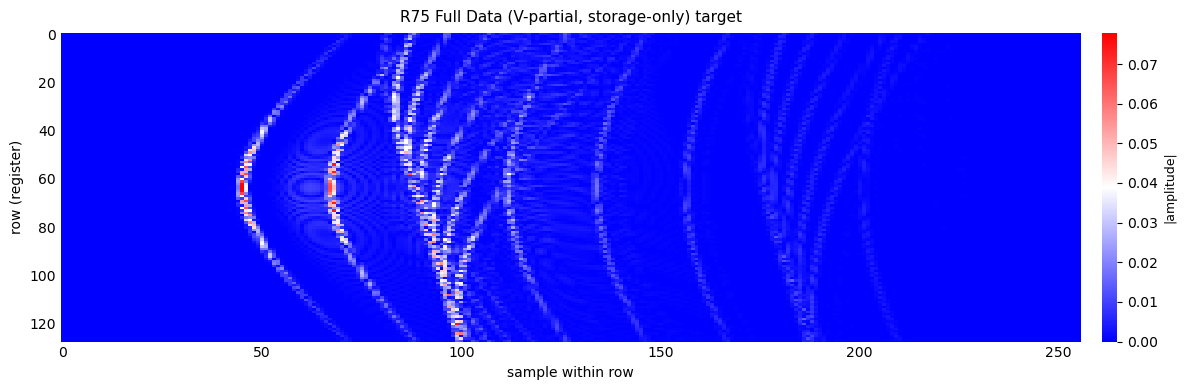

[[-1.18175533e-18 -1.96471333e-18 -1.90577618e-18 ... -1.61198350e-18
   1.77281143e-18  2.66201340e-19]
 [-3.48672286e-19 -1.38067699e-20  2.19873170e-18 ...  4.43602110e-19
   1.26152380e-19 -1.89647234e-19]
 [-9.83917934e-19 -1.94519122e-18 -1.02733466e-18 ... -1.21887270e-18
   3.99957961e-19 -1.88055941e-18]
 ...
 [-2.88296342e-19 -1.15342488e-18  1.39182639e-18 ... -3.75818062e-08
   7.38753910e-08  6.39584937e-12]
 [ 5.54255862e-19 -2.44908974e-19  1.61224936e-18 ... -1.80642495e-08
  -1.19584490e-07 -1.03554208e-11]
 [-1.26048192e-19 -7.43343141e-19  5.49433763e-19 ...  6.57927727e-07
   9.05650643e-08  7.84452701e-12]]
[R75 Full Data (V-partial, storage-only)] baseline reweighting success:
[R75 Full Data (V-partial, storage-only)] training up to 20 storage-only brick-wall layers (hybrid, plateau-guarded)...
[[-2.83811548e-04+1.22941765e-03j -9.80866973e-04-1.79969421e-05j
   5.28570834e-05+9.35985521e-04j ... -2.37268204e-03-1.20782997e-03j
   1.40058911e-03+3.28878257e-03j -3

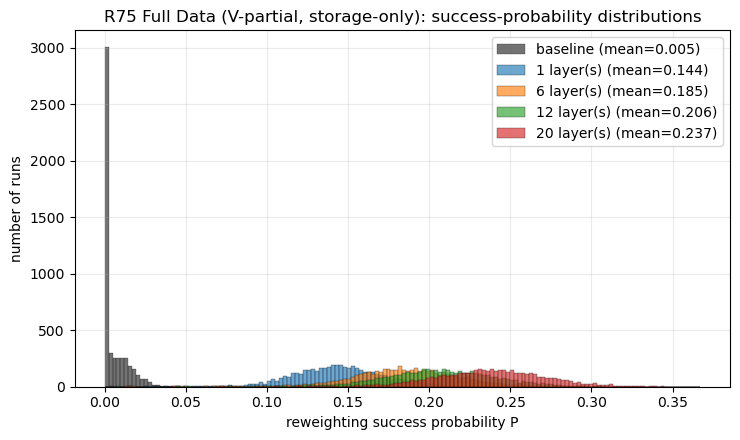

In [25]:

# ---- run it on the full data, same sweep as V-full ----
layer_results_partial, base_result_partial, seq_partial = compare_storage_layers(
    Y_full, layer_counts=(1, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20), name="R75 Full Data (V-partial, storage-only)",
    n_shots=5000, n_iter=300, seed=0,
)
SAVE_DIR = Path(os.path.join(os.getcwd(), "results"))
SAVE_DIR.mkdir(exist_ok=True)

def save_results(layer_results, base_result, seq, filename):
    path = SAVE_DIR / filename
    with open(path, "wb") as f:
        pickle.dump({"layer_results": layer_results, "base_result": base_result, "seq": seq}, f)
    print(f"saved -> {path}")

def load_results(filename):
    path = SAVE_DIR / filename
    with open(path, "rb") as f:
        data = pickle.load(f)
    print(f"loaded <- {path}")
    return data["layer_results"], data["base_result"], data["seq"]
# ---- save V-partial ----
save_results(layer_results_partial, base_result_partial, seq_partial, "v_partial_results.pkl")

# ---- same histogram style as V-full (reuses plot_success_histograms defined earlier) ----
plot_success_histograms(layer_results_partial, base_result_partial, layer_counts=[1, 6, 12, 20],
                         name="R75 Full Data (V-partial, storage-only)")

# Hopefully last run needed for R75

In [3]:
def make_brick_wall_layer(n, eps=0.0, seed=None):
    """One brick-wall layer: SU(4) on all EVEN bonds (0,1),(2,3),... then SU(4) on
    all ODD bonds (1,2),(3,4),...

    !! The leftover qubit in each sublayer is padded with a PLAIN qtn.Tensor identity
    tagged "ID". A plain Tensor is NOT a PTensor, so quimb's TNOptimizer exposes its raw
    complex entries as free, UNCONSTRAINED variables. Any optimiser driving this ansatz
    MUST pass constant_tags=["ID"], or the resulting V is not unitary and is not a circuit.

    The earlier claim that this ansatz "empirically outperforms the staircase" is
    RETRACTED: it was an artefact of exactly that hole. The brick wall had a non-unitary
    escape hatch; make_chi2_staircase (15/15 PTensor, no padding identities) did not.
    See ansatz_headtohead_FIXED.csv for the corrected, unitarity-checked comparison."""
    if seed is not None: torch.manual_seed(seed)
    def _init(m):
        p = torch.zeros(m, dtype=torch.float64)
        if eps > 0: p = p + eps * torch.randn(m, dtype=torch.float64)
        return p.requires_grad_(True)
    tensors = []
    def sublayer(in_prefix, out_prefix, pairs, untouched):
        for (q0, q1) in pairs:
            tensors.append(PTensor(su4_matrix, _init(15),
                                   inds=(f"{in_prefix}{q0}", f"{in_prefix}{q1}",
                                         f"{out_prefix}{q0}", f"{out_prefix}{q1}"),
                                   tags={"SU4"}))
        for q in untouched:
            tensors.append(qtn.Tensor(torch.eye(2, dtype=torch.complex128),
                                      inds=(f"{in_prefix}{q}", f"{out_prefix}{q}"), tags={"ID"}))
    even_pairs = [(i, i + 1) for i in range(0, n - 1, 2)]
    even_untouched = [q for q in range(n) if q not in {x for p in even_pairs for x in p}]
    sublayer("k", "mid", even_pairs, even_untouched)
    odd_pairs = [(i, i + 1) for i in range(1, n - 1, 2)]
    odd_untouched = [q for q in range(n) if q not in {x for p in odd_pairs for x in p}]
    sublayer("mid", "b", odd_pairs, odd_untouched)
    return qtn.TensorNetwork(tensors)


def optimise_flatten_layers_hybrid(mps, max_layers, layer_builder=make_brick_wall_layer,
                                    n_iter=200, eps_init=1e-2, seed=0, tol=1e-14, verbose=False,
                                    plateau_rel_tol=1e-3, plateau_patience=2):
    """Greedy warm-start + joint fine-tune, per layer. Adds TWO safety mechanisms on
    top of the original version:
      1. Never accepts a round that makes IPR WORSE than the previous accepted round
         (rejects it, keeps the previous stack, tries a fresh layer next round instead).
      2. Stops adding layers once IPR improvement plateaus (< plateau_rel_tol for
         plateau_patience consecutive rounds) -- once the training objective has
         nothing left to gain, further layers just wander a flat/degenerate part of
         the loss landscape, which is pure risk for worst-case success probability P
         (which IPR is only a proxy for) and wasted compute for zero benefit.
    Still carries the internal-bond namespacing fix (L{L}_ prefix on new_layer's
    internal indices) that prevents cross-layer bond collisions when stacking.

    FIX (2026-08-25): constant_tags=["ID"] is now passed to TNOptimizer, and a unitarity
    assertion runs every round. Without them, make_brick_wall_layer's padding identities
    were free non-unitary parameters, so the optimiser "flattened" by non-physically
    rescaling amplitudes rather than by finding a circuit -- driving the full R75 state to
    an EXACT phase state (IPR pinned to the 1/2^n floor, every sigma_i = 1/sqrt(M), one
    qubit fully disentangled, reweighting P ~ 0.97). Everything produced by this function
    before that date is invalid; see the warning cell above."""
    n = mps.L

    def ipr_of_op(op, target_mps):
        psi = dense_state_from_op_mps(op, target_mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return (torch.abs(psi) ** 4).sum()

    def optimise_stack(stack_init, target_mps, n_iter_, history):
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = ipr_of_op(op, init_tn); s = float(val.detach()); history.append(s)
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        qtn.TNOptimizer(stack_init, loss, loss_constants={"init_tn": target_mps}, optimizer="l-bfgs-b",
                autodiff_backend="torch", progbar=verbose,
                constant_tags=["ID"]).optimize(n=n_iter_, tol=tol)

        if best["params"] is not None:
            stack_init.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            return stack_init, best["val"]
        return stack_init, float(ipr_of_op(stack_init, target_mps).detach())

    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)

    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]
    full_history, layer_boundaries = [], [0]

    stack = None
    stall_count = 0
    for L in range(max_layers):
        new_layer = layer_builder(n, eps=eps_init, seed=seed + L)
        new_layer, ipr_greedy = optimise_stack(new_layer, current_mps, n_iter, full_history)
        layer_boundaries.append(len(full_history))   # greedy -> joint transition

        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})

        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))

        candidate, ipr_joint = optimise_stack(candidate, mps, n_iter, full_history)
        layer_boundaries.append(len(full_history))   # joint -> next layer's greedy

        # --- UNITARITY GUARD -------------------------------------------------------
        # A non-unitary V is not a circuit, and IPR-minimisation actively rewards
        # cheating this way (it normalises the state afterwards). This one line would
        # have caught both the free-"ID"-tensor bug and the earlier index-collision bug
        # the day they were introduced. Cost: one contraction per layer.
        _psi = dense_state_from_op_mps(candidate, mps).reshape(-1)
        _nerr = abs(float(torch.linalg.norm(_psi)) - 1.0)
        if _nerr > 1e-9:
            raise RuntimeError(
                f"V is not unitary at layer {L+1}: | ||V|psi>|| - 1 | = {_nerr:.3e}. "
                f"Check that every TNOptimizer call passes constant_tags=['ID'].")

        prev_ipr = per_layer_ipr[-1]
        if ipr_joint <= prev_ipr:
            stack = candidate
            accepted_ipr = ipr_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_ipr = prev_ipr
            if verbose:
                print(f"  layer {L+1}: regression ({ipr_joint:.4e} > {prev_ipr:.4e}), rejected, keeping previous stack")

        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_ipr.append(accepted_ipr)
        per_layer_psi.append(psi_now)

        rel_improve = (prev_ipr - accepted_ipr) / prev_ipr if prev_ipr > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if verbose:
            print(f"  layer {L+1}/{max_layers}: greedy IPR={ipr_greedy:.4e}  after joint fine-tune={ipr_joint:.4e}  "
                  f"accepted={accepted_ipr:.4e}  rel_improve={rel_improve:.2%}  stall={stall_count}")

        if stall_count >= plateau_patience:
            if verbose:
                print(f"  IPR plateaued (< {plateau_rel_tol:.1%} improvement for {plateau_patience} rounds) "
                      f"-- stopping at layer {L+1}/{max_layers}, remaining layer counts repeat this state")
            while len(per_layer_ipr) <= max_layers:
                per_layer_ipr.append(per_layer_ipr[-1])
                per_layer_psi.append(per_layer_psi[-1])
            break

    return {"per_layer_ipr": per_layer_ipr, "per_layer_psi": per_layer_psi,
            "history": full_history, "layer_boundaries": layer_boundaries}


def compare_flatten_layers(Y, layer_counts=(1, 2, 3, 5, 10), name="state", layer_builder=make_brick_wall_layer,
                            n_shots=5000, n_iter=200, seed=0, eps_init=1e-2, tol=1e-14):
    Y = np.asarray(Y); N, M = Y.shape
    n = int(round(np.log2(M * N)))

    _display_state(Y, f"{name} — target state (|amplitude|)")

    v = np.asarray(Y, dtype=np.complex128).T.flatten(); v /= np.linalg.norm(v)
    mps = qtn.MatrixProductState.from_dense(v.reshape([2] * n), dims=[2] * n)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    ipr_base = float(np.sum(np.abs(v) ** 4))

    sigma0, chunks0 = extract_row_weights(Y)
    print(f"[{name}] baseline reweighting success:")
    res_base = success_distribution(chunks0, sigma0, n_shots=n_shots, seed=seed, plot=False)

    max_L = max(layer_counts)
    print(f"[{name}] training up to {max_L} layers ({layer_builder.__name__}, hybrid, plateau-guarded)...")
    seq = optimise_flatten_layers_hybrid(mps, max_layers=max_L, layer_builder=layer_builder, n_iter=n_iter,
                                          eps_init=eps_init, seed=seed, tol=tol, verbose=False)

    colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(layer_counts)))
    results = {}
    for L in layer_counts:
        psi_flat = seq["per_layer_psi"][L]
        Y_flat = psi_flat.reshape(M, N).T
        sigmaF, chunksF = extract_row_weights(Y_flat)
        res = success_distribution(chunksF, sigmaF, n_shots=n_shots, seed=seed, plot=False)
        results[L] = {"psi_flat": psi_flat, "Y_flat": Y_flat, "ipr": seq["per_layer_ipr"][L], "res": res}
        print(f"  {L} layer(s): IPR {ipr_base:.3e} -> {results[L]['ipr']:.3e}   "
              f"success {res_base['mean']:.4f} -> {res['mean']:.4f}  ({res['mean']/res_base['mean']:.2f}x)")

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.axhline(ipr_base, color="black", ls=":", lw=1.2, label=f"baseline {ipr_base:.2e}")
    ax.axhline(1 / 2**n, color="blue", ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
    ax.plot(range(max_L + 1), seq["per_layer_ipr"], color="#c0392b", marker="o", ms=4, lw=1.8)
    ax.set_yscale("log")
    ax.set_xlabel("number of layers"); ax.set_ylabel("final IPR")
    ax.set_title(f"{name} — IPR vs. depth ({layer_builder.__name__}, hybrid training)")
    ax.legend(); ax.grid(alpha=0.25, which="both")
    plt.tight_layout(); plt.show()

    means = [results[L]["res"]["mean"] for L in layer_counts]
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.axhline(res_base["mean"], color="black", ls=":", lw=1.2, label="baseline")
    ax.plot(layer_counts, means, color="#2b6cb0", marker="o", lw=1.8)
    ax.set_xlabel("number of layers"); ax.set_ylabel("mean reweighting success P")
    ax.set_title(f"{name} — success probability vs. depth ({layer_builder.__name__}, hybrid training)")
    ax.legend(); ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()

    best_L = max(layer_counts, key=lambda L: results[L]["res"]["mean"])   # <-- best BY P, not lowest IPR
    _display_state(results[best_L]["Y_flat"], f"{name} — flattened state, {best_L} layer(s) (|amplitude|)")

    all_P = [res_base["P"]] + [results[L]["res"]["P"] for L in layer_counts]
    lo = min(p.min() for p in all_P); hi = max(p.max() for p in all_P)
    bins = np.linspace(lo, hi, 80)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(res_base["P"], bins=bins, alpha=0.85, color="black", edgecolor="white", lw=0.3,
            label=f"baseline (mean {res_base['mean']:.4f})")
    for L, color in zip(layer_counts, colors):
        ax.hist(results[L]["res"]["P"], bins=bins, alpha=0.55, color=color, edgecolor="black", lw=0.3,
                label=f"{L} layer(s) (mean {results[L]['res']['mean']:.4f})")
    ax.set_xlabel("reweighting success probability P"); ax.set_ylabel("number of runs")
    ax.set_title(f"{name} — success probability, baseline vs. depth ({layer_builder.__name__}, hybrid training)")
    ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.plot(seq["history"], color="#c0392b", lw=1)
    for b in seq["layer_boundaries"][1:-1]:
        ax.axvline(b, color="grey", ls=":", lw=0.8)
    ax.set_yscale("log"); ax.set_xlabel("optimiser evaluation (dashed = greedy/joint-fine-tune/next-layer boundaries)")
    ax.set_ylabel("IPR")
    ax.set_title(f"{name} — convergence diagnostic")
    ax.grid(alpha=0.2, which="both")
    plt.tight_layout(); plt.show()

    print(f"\n{'layers':>7s} {'IPR':>12s} {'mean success':>13s} {'gain vs baseline':>18s}")
    print(f"{'base':>7s} {ipr_base:>12.3e} {res_base['mean']:>13.4f} {'--':>18s}")
    for L in layer_counts:
        gain = results[L]["res"]["mean"] / res_base["mean"]
        print(f"{L:>7d} {results[L]['ipr']:>12.3e} {results[L]['res']['mean']:>13.4f} {gain:>17.2f}x")
    print(f"\nbest observed success probability: {results[best_L]['res']['mean']:.4f} at {best_L} layer(s) "
          f"(NOT necessarily the deepest -- check this before assuming more layers = better)")

    return results, res_base, seq


In [4]:
# === Q-MERGE Fig. 3/4 on the HARDWARE-RESOLUTION dataset: M = 128 registers x N = 1024 ===
#
# Why this dataset: Sec. IV B 1 encodes M=4 rows of length N=2^10=1024, "upscaled by a
# factor of 4 from the R75 ultrasound data". This builds the SAME upscale but keeps all
# 128 registers, so the numerical figures and the hardware demo sit on one dataset.
#   resize(raw (382,128) -> (1024,128)): the SAMPLE axis is resampled 382 -> 1024.
#   The register axis stays at its native 128 -- no interpolation across registers.
#   n = log2(1024) = 10 qubits/register, m = log2(128) = 7 index qubits, 17 total.
#
# Cheap (seconds). Re-run after any kernel restart, BEFORE any other cell in this block.
# PREREQS in-kernel: cell 0 (SSO setup), cell 2 (success_distribution), cell 68 (brickwall).
import os, json, time, glob, pickle
import numpy as np
import pandas as pd
import quimb.tensor as qtn
from skimage.transform import resize

BASE = os.getcwd()

TAG      = "R75x4"                 # all files for this dataset carry this tag
FULL_N   = 1024                    # samples per register  -> n = 10 qubits
FULL_M   = 128                     # registers             -> m = 7 qubits
RUN_ORIG    = f"{TAG}_orig"        # un-preconditioned rows      (panel a, RED)
RUN_PRECOND = f"{TAG}_precond_L10" # 10-brickwall-layer rows     (panel a, BLUE)
FULLSTATE_DIR = os.path.join(BASE, "SSO results", f"fullstate_{TAG}")   # direct (panel a, BLACK)
SEED_DIR      = os.path.join(BASE, "results")                           # v_{TAG}_seed*.pkl (panel b)

_df   = pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None)
Y_x4  = resize(_df.to_numpy(), (FULL_N, FULL_M), anti_aliasing=True)     # (1024, 128)
Y_x4  = Y_x4 / np.linalg.norm(Y_x4)                                      # ||Y|| = 1

n_row  = int(round(np.log2(FULL_N)))          # 10 qubits per preparation register
m_idx  = int(round(np.log2(FULL_M)))          # 7 index qubits
n_full = n_row + m_idx                        # 17 qubits for the direct encoding
IPR_FLOOR = 1.0 / 2 ** n_full                 # uniform-amplitude IPR floor (unitarity guard)

def row_weights(Y):
    """sigma_i, |psi_i> of Eq. (1): sigma_i = ||row_i|| / ||Y||, chunks_i = row_i/||row_i||.
    Same maths as extract_row_weights (cell 2) without its debug print of the whole array."""
    rows      = np.asarray(Y).T                      # (M, N)
    row_norms = np.linalg.norm(rows, axis=1)
    sigma     = row_norms / np.linalg.norm(row_norms)
    return sigma, rows / row_norms[:, None]

sigma_x4, chunks_x4 = row_weights(Y_x4)

print(f"raw excel        : {_df.shape}  (samples, registers)")
print(f"Y_{TAG}          : {Y_x4.shape}  ||Y|| = {np.linalg.norm(Y_x4):.6f}")
print(f"partition        : M = {FULL_M} registers x N = {FULL_N} samples")
print(f"qubits           : n = {n_row}/register, m = {m_idx} index, {n_full} total "
      f"(direct encoding dimension {2**n_full})")
print(f"sigma            : sum sigma^2 = {(sigma_x4**2).sum():.10f}   "
      f"min {sigma_x4.min():.3e}  max {sigma_x4.max():.3e}")
print(f"baseline IPR     : {float((np.abs(Y_x4.T.ravel())**4).sum()):.4e}   "
      f"({float((np.abs(Y_x4.T.ravel())**4).sum())/IPR_FLOOR:.2f}x the uniform floor {IPR_FLOOR:.3e})")


raw excel        : (382, 128)  (samples, registers)
Y_R75x4          : (1024, 128)  ||Y|| = 1.000000
partition        : M = 128 registers x N = 1024 samples
qubits           : n = 10/register, m = 7 index, 17 total (direct encoding dimension 131072)
sigma            : sum sigma^2 = 1.0000000000   min 2.994e-02  max 1.604e-01
baseline IPR     : 3.9630e-04   (51.94x the uniform floor 7.629e-06)


In [5]:
# Resumable, BREADTH-FIRST row-sweep driver. Shared by the un-preconditioned run (A2)
# and the preconditioned run (B2) -- run once, it only defines a function.
#
# Breadth-first is the whole point for an overnight-batched run: it advances EVERY row
# by `chunk` layers before going deeper, instead of taking row 0 to layer 140 and leaving
# row 127 at zero. The aggregate fidelity is only defined at a depth ALL rows reach, so
# after any interrupted session you still have a plottable curve -- just a shorter one.
# Stop it whenever (interrupt the kernel, or let `budget_min` expire); every completed
# chunk is already on disk.
#
# On disk, per run_name, in  SSO results/row_sweep_<run_name>/ :
#   row_fids.json  -- {row: {"n_qubits":n, "chi": {"2": {"chi_fids": [...], "final_fid": f}}}}
#   row_states.npz -- each row's current post-layer state, so a resumed row warm-starts from
#                     exactly where it stopped rather than re-running the earlier layers.
#   sigma.npy      -- THIS run's target weights sigma_i. Saved because the aggregate fidelity
#                     F = (sum_i sigma_i^2 sqrt(F_i))^2 must be weighted by the weights of the
#                     state that was actually encoded. For the pre-conditioned run that is the
#                     FLATTENED state V|psi>, whose sigma_i are near-uniform (~1/sqrt(M)) and
#                     so quite different from the raw data's. (DiagramsForMultiRegisterEncoding
#                     cell 4 reuses the raw sigma for both curves; that is wrong for the
#                     pre-conditioned one, and it is why this is stored per run.)
def run_row_sweep(Y_target, run_name, K=140, chunk=20, n_iter=200, budget_min=None, rows=None):
    """Advance every row of Y_target (columns = registers) to K chi=2 SSO layers.

    K          -- final layer count per row
    chunk      -- layers added per row per pass (smaller = finer resume granularity)
    budget_min -- stop cleanly after this many wall-clock minutes (None = run to K)
    rows       -- restrict to these row indices (None = all)
    """
    outdir = os.path.join(BASE, "SSO results", f"row_sweep_{run_name}")
    os.makedirs(outdir, exist_ok=True)
    fids_json  = os.path.join(outdir, "row_fids.json")
    states_npz = os.path.join(outdir, "row_states.npz")

    N, M = Y_target.shape[0], Y_target.shape[1]
    n    = int(round(np.log2(N)))
    idxs = list(range(M)) if rows is None else list(rows)

    sigma_run, _ = row_weights(Y_target)          # this run's own target weights
    np.save(os.path.join(outdir, "sigma.npy"), sigma_run)

    all_results = json.load(open(fids_json)) if os.path.exists(fids_json) else {}
    if os.path.exists(states_npz):
        with np.load(states_npz) as z:
            states = dict(z)
    else:
        states = {}

    def to_mps(vec):
        mm = qtn.MatrixProductState.from_dense(np.asarray(vec).astype(np.complex128),
                                               dims=[2] * n, cutoff=0.0)
        return mm / mm.norm()

    def mps_to_vec(mm):
        mm = mm.copy()
        mm.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x))
        v = np.asarray(mm.to_dense()).reshape(-1)
        return (v / np.linalg.norm(v)).astype(np.complex128)

    def _replace(tmp, dst):                 # OneDrive/AV can hold the handle briefly
        for _ in range(30):
            try:
                os.replace(tmp, dst); return
            except PermissionError:
                time.sleep(0.5)
        os.replace(tmp, dst)

    def save_all():
        tj = fids_json + ".tmp"
        with open(tj, "w") as f:
            json.dump(all_results, f, indent=2)
        _replace(tj, fids_json)
        tn = states_npz + ".tmp.npz"
        np.savez(tn, **states)
        _replace(tn, states_npz)

    def depth(i):
        k = str(i)
        return (len(all_results[k]["chi"]["2"]["chi_fids"]) - 1) if k in all_results else 0

    t_start  = time.time()
    deadline = t_start + budget_min * 60 if budget_min else None

    print(f"[{run_name}]  M={M} rows x N={N} (n={n} qubits)   target K={K} layers, "
          f"chunk={chunk}, n_iter={n_iter}" + (f", budget {budget_min} min" if budget_min else ""))
    done_now = np.array([depth(i) for i in idxs])
    print(f"  on disk: min depth {done_now.min()}, max {done_now.max()}, "
          f"{int((done_now >= K).sum())}/{len(idxs)} rows already at K\n", flush=True)

    stopped = False
    for milestone in range(chunk, K + chunk, chunk):      # breadth-first depth milestones
        milestone = min(milestone, K)
        pending = [i for i in idxs if depth(i) < milestone]
        if not pending:
            continue
        print(f"--- pass to {milestone} layers: {len(pending)} row(s) to advance ---", flush=True)
        for i in pending:
            if deadline and time.time() > deadline:
                print(f"\n  budget of {budget_min} min reached -- stopping cleanly.", flush=True)
                stopped = True
                break
            key, done = str(i), depth(i)
            t0 = time.time()
            if done > 0 and key in states:
                start, fids = to_mps(states[key]), all_results[key]["chi"]["2"]["chi_fids"]
            else:                                          # fresh row (or stateless old result)
                col  = Y_target[:, i]
                start, fids, done = to_mps(col / np.linalg.norm(col)), None, 0

            res = sequential_disentangle_warm(start, chi=2, num_layers=milestone - done,
                                              n_iter=n_iter, verbose=False)
            new  = [float(v) for v in res["chi_fids"]]
            fids = new if fids is None else fids + new[1:]
            states[key]      = mps_to_vec(res["final_mps"])
            all_results[key] = {"n_qubits": n,
                                "chi": {"2": {"chi_fids": fids, "final_fid": fids[-1]}}}
            save_all()
            print(f"  row {i:>3d}  {done:>3d}->{milestone:>3d} layers  "
                  f"F_i = {fids[-1]:.6f}  (1-F_i = {1-fids[-1]:.2e})  "
                  f"[{time.time()-t0:.0f}s]", flush=True)
        if stopped:
            break

    depths = np.array([depth(i) for i in idxs])
    common = int(depths.min())
    print(f"\n[{run_name}] session {(time.time()-t_start)/60:.1f} min. "
          f"Common depth across all rows: {common}/{K} layers.")
    if common > 0:
        F = np.array([all_results[str(i)]["chi"]["2"]["chi_fids"][common] for i in idxs])
        print(f"  per-segment F_i at layer {common}: min {F.min():.6f}  "
              f"mean {F.mean():.6f}  max {F.max():.6f}")
        if len(idxs) == M:                        # sigma_i^2 only sums to 1 over ALL registers
            F_agg = float(((sigma_run**2 * np.sqrt(np.clip(F, 0, 1))).sum())**2)
            print(f"  aggregate F = (sum_i sigma_i^2 sqrt(F_i))^2 = {F_agg:.10f}   "
                  f"(1-F = {1-F_agg:.3e})")
    print(f"  -> {os.path.join('SSO results', 'row_sweep_'+run_name, 'row_fids.json')}")
    return all_results


In [20]:
# BATCH CELL (long).  Panel (a) RED curve: Q-MERGE on the un-preconditioned 128x1024 rows.
# Re-run this same cell every night -- it resumes from disk and prints the per-segment
# fidelities as it goes. Raise BUDGET_MIN (or set it to None) to let it run longer.
# Measured: ~3.6 s per layer per row -> ~2.6 h per 20-layer pass over all 128 rows.
K_LAYERS   = 200      # final chi=2 depth per row (the paper's Fig. 4 shows up to ~105)
CHUNK      = 20        # layers added per row per pass
BUDGET_MIN = 600       # ~10 h; set None to run until K_LAYERS

_ = run_row_sweep(Y_x4, RUN_ORIG, K=K_LAYERS, chunk=CHUNK, n_iter=200, budget_min=BUDGET_MIN)


[R75x4_orig]  M=128 rows x N=1024 (n=10 qubits)   target K=200 layers, chunk=20, n_iter=200, budget 600 min
  on disk: min depth 150, max 150, 0/128 rows already at K

--- pass to 160 layers: 128 row(s) to advance ---
  row   0  150->160 layers  F_i = 0.999991  (1-F_i = 8.96e-06)  [88s]
  row   1  150->160 layers  F_i = 0.999989  (1-F_i = 1.08e-05)  [87s]
  row   2  150->160 layers  F_i = 0.999989  (1-F_i = 1.09e-05)  [86s]
  row   3  150->160 layers  F_i = 0.999988  (1-F_i = 1.19e-05)  [84s]
  row   4  150->160 layers  F_i = 0.999989  (1-F_i = 1.08e-05)  [87s]
  row   5  150->160 layers  F_i = 0.999990  (1-F_i = 1.01e-05)  [85s]
  row   6  150->160 layers  F_i = 0.999990  (1-F_i = 1.01e-05)  [86s]
  row   7  150->160 layers  F_i = 0.999991  (1-F_i = 8.82e-06)  [85s]
  row   8  150->160 layers  F_i = 0.999991  (1-F_i = 8.65e-06)  [84s]
  row   9  150->160 layers  F_i = 0.999988  (1-F_i = 1.19e-05)  [87s]
  row  10  150->160 layers  F_i = 0.999990  (1-F_i = 9.86e-06)  [84s]
  row  11  1

In [19]:
# BATCH CELL (long).  Panel (a) BLACK curve: DIRECT encoding of the whole 17-qubit state
# (no partitioning) under the same SSO method -- this is the comparison the 7-orders-of-
# magnitude claim rests on. One checkpoint per layer, so it resumes anywhere.
# Measured: ~83 s per layer at n=17 -> ~3.2 h for 140 layers.
#
# Written to a LOCAL disk (C:\qruns) by default, not OneDrive: the checkpoint is rewritten
# every layer and OneDrive sync contention on it is the one thing that reliably corrupts
# these runs. The plot cell reads either location.
FULLSTATE_LOCAL = os.path.join(BASE, "SSO results", f"fullstate_{TAG}")
TARGET_LAYERS   = 200
FS_BUDGET_MIN   = 600          # None = run to TARGET_LAYERS

os.makedirs(FULLSTATE_LOCAL, exist_ok=True)
CKPT = os.path.join(FULLSTATE_LOCAL, "checkpoint.npz")

v0 = Y_x4.T.flatten()                                   # register-major, matches Eq. (1) ordering
v0 = (v0 / np.linalg.norm(v0)).astype(np.complex128)
assert int(round(np.log2(v0.size))) == n_full

def _fs_to_mps(vec):
    mm = qtn.MatrixProductState.from_dense(np.asarray(vec).astype(np.complex128),
                                           dims=[2] * n_full, cutoff=0.0)
    return mm / mm.norm()

def _fs_to_vec(mm):
    mm = mm.copy()
    mm.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x))
    v = np.asarray(mm.to_dense()).reshape(-1)
    return (v / np.linalg.norm(v)).astype(np.complex128)

def _fs_save(cur, chi_fids):
    tmp = CKPT + ".tmp.npz"
    np.savez(tmp, state=cur, chi_fids=np.array(chi_fids, dtype=float))
    os.replace(tmp, CKPT)

if os.path.exists(CKPT):
    with np.load(CKPT) as d:                            # read inside `with` -> handle released
        cur, chi_fids = np.array(d["state"]), list(map(float, d["chi_fids"]))
    print(f"resuming direct {TAG} at layer {len(chi_fids)-1}/{TARGET_LAYERS} "
          f"(fid {chi_fids[-1]:.6f})", flush=True)
else:
    cur, chi_fids = v0.copy(), [float(chi_fidelity(_fs_to_mps(v0), 2))]
    print(f"fresh direct {TAG} run, n={n_full} qubits, init chi2 fid = {chi_fids[0]:.6f}", flush=True)

_t0 = time.time()
_deadline = _t0 + FS_BUDGET_MIN * 60 if FS_BUDGET_MIN else None
while len(chi_fids) - 1 < TARGET_LAYERS:
    if _deadline and time.time() > _deadline:
        print(f"\nbudget of {FS_BUDGET_MIN} min reached -- stopping cleanly.", flush=True)
        break
    t0 = time.time()
    res = sequential_disentangle_warm(_fs_to_mps(cur), chi=2, num_layers=1, n_iter=200, verbose=False)
    cur = _fs_to_vec(res["final_mps"])
    chi_fids.append(float(res["chi_fids"][-1]))
    _fs_save(cur, chi_fids)
    print(f"  direct layer {len(chi_fids)-1:>3d}/{TARGET_LAYERS}  F = {chi_fids[-1]:.6f}  "
          f"(1-F = {1-chi_fids[-1]:.3e})  [{time.time()-t0:.0f}s]", flush=True)
print(f"\ndirect {TAG}: {len(chi_fids)-1} layers done, 1-F = {1-chi_fids[-1]:.3e}  -> {CKPT}")


resuming direct R75x4 at layer 140/200 (fid 0.666913)
  direct layer 141/200  F = 0.667709  (1-F = 3.323e-01)  [306s]
  direct layer 142/200  F = 0.669412  (1-F = 3.306e-01)  [288s]
  direct layer 143/200  F = 0.670640  (1-F = 3.294e-01)  [275s]
  direct layer 144/200  F = 0.672003  (1-F = 3.280e-01)  [291s]
  direct layer 145/200  F = 0.673157  (1-F = 3.268e-01)  [375s]
  direct layer 146/200  F = 0.674739  (1-F = 3.253e-01)  [407s]
  direct layer 147/200  F = 0.675125  (1-F = 3.249e-01)  [334s]
  direct layer 148/200  F = 0.676127  (1-F = 3.239e-01)  [299s]
  direct layer 149/200  F = 0.678102  (1-F = 3.219e-01)  [289s]
  direct layer 150/200  F = 0.678999  (1-F = 3.210e-01)  [314s]
  direct layer 151/200  F = 0.679697  (1-F = 3.203e-01)  [308s]
  direct layer 152/200  F = 0.680588  (1-F = 3.194e-01)  [305s]
  direct layer 153/200  F = 0.681432  (1-F = 3.186e-01)  [314s]
  direct layer 154/200  F = 0.682492  (1-F = 3.175e-01)  [311s]
  direct layer 155/200  F = 0.684021  (1-F = 3.160

## IPR stuff

In [15]:
# BATCH CELL.  The IPR / pre-conditioning step on the 17-qubit 128x1024 state: L brickwall
# layers of SU(4) optimised to minimise IPR, then the Stage-2 reweighting success
# P = 1/beta^2 Monte-Carlo'd at each depth. This produces the "baseline -> 10 layers" boost
# (panel b) AND the flattened target Y_flat that the pre-conditioned row sweep (B2) encodes.
#
# Same data path as compare_flatten_layers (cell 68) -- identical calls, identical seeds --
# but without its per-seed figures, since this runs over many seeds. The pickle has the same
# {"layer_results", "base_result", "seq"} shape, so the plot cells and the existing recovery
# cell (cell 24) read it unchanged.
#
# Measured: ~110 ms/optimiser eval at n=17 -> roughly 15-45 min per seed, plus ~12 s per
# depth for the 5000-shot Monte Carlo.
#
# RESUMING: one pickle per seed; a seed whose pickle exists is skipped. To split over nights
# just trim SEEDS. A part-finished seed is NOT saved, so leave time for at least one seed.
#
# UNITARITY: optimise_flatten_layers_hybrid asserts || V|psi> || = 1 every layer, so the
# 2026-08-25 non-unitary brickwall bug cannot silently return. The floor check below is the
# second line of defence: a "flattened" state sitting ON the uniform IPR floor is the
# signature of that bug, not a good result.
import os, pickle, time
import numpy as np

SEEDS        = list(range(10))        # trim to e.g. [0,1,2] to do a few per night
LAYER_COUNTS = (1,2,3,4,5,6,7,8,9,10) # 10 brickwall layers = the paper's pre-conditioning V
N_SHOTS      = 5000                   # Monte-Carlo shots per depth (same as the paper)
N_ITER_FLAT  = 300
SEED_BUDGET_MIN = 600                 # None = run all SEEDS

os.makedirs(SEED_DIR, exist_ok=True)

def flatten_seed_run(Y, seed, layer_counts=LAYER_COUNTS, n_shots=N_SHOTS, n_iter=N_ITER_FLAT):
    """compare_flatten_layers' data path, no plots. Returns (layer_results, base_result, seq)."""
    N, M = Y.shape
    n    = int(round(np.log2(M * N)))

    v = np.asarray(Y, dtype=np.complex128).T.flatten()
    v = v / np.linalg.norm(v)
    mps = qtn.MatrixProductState.from_dense(v.reshape([2] * n), dims=[2] * n)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    ipr_base = float(np.sum(np.abs(v) ** 4))

    sigma0, chunks0 = row_weights(Y)
    t0 = time.time()
    res_base = success_distribution(chunks0, sigma0, n_shots=n_shots, seed=seed, plot=False)
    print(f"  baseline: IPR {ipr_base:.4e} ({ipr_base/IPR_FLOOR:.2f}x floor)   "
          f"P = {res_base['mean']:.4f}  [{time.time()-t0:.0f}s]", flush=True)

    seq = optimise_flatten_layers_hybrid(mps, max_layers=max(layer_counts),
                                         layer_builder=make_brick_wall_layer,
                                         n_iter=n_iter, eps_init=1e-2, seed=seed,
                                         tol=1e-14, verbose=False)

    results = {}
    for L in layer_counts:
        psi_flat = seq["per_layer_psi"][L]
        Y_flat   = psi_flat.reshape(M, N).T
        sigmaF, chunksF = row_weights(Y_flat)
        res = success_distribution(chunksF, sigmaF, n_shots=n_shots, seed=seed, plot=False)
        results[L] = {"psi_flat": psi_flat, "Y_flat": Y_flat,
                      "ipr": seq["per_layer_ipr"][L], "res": res}
        print(f"  {L:>2d} layer(s): IPR {ipr_base:.3e} -> {results[L]['ipr']:.3e} "
              f"({results[L]['ipr']/IPR_FLOOR:.3f}x floor)   "
              f"P {res_base['mean']:.4f} -> {res['mean']:.4f} "
              f"({res['mean']/res_base['mean']:.2f}x)", flush=True)
    return results, res_base, seq

_t0 = time.time()
_deadline = _t0 + SEED_BUDGET_MIN * 60 if SEED_BUDGET_MIN else None
rows_summary = []
for seed in SEEDS:
    path = os.path.join(SEED_DIR, f"v_{TAG}_seed{seed}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            d = pickle.load(f)
        print(f"seed {seed}: already on disk", flush=True)
    else:
        if _deadline and time.time() > _deadline:
            print(f"\nbudget of {SEED_BUDGET_MIN} min reached -- stopping before seed {seed}.",
                  flush=True)
            break
        print(f"\n===== seed {seed} =====", flush=True)
        ts = time.time()
        lr, br, sq = flatten_seed_run(Y_x4, seed)
        d = {"layer_results": lr, "base_result": br, "seq": sq}
        with open(path, "wb") as f:
            pickle.dump(d, f)
        print(f"seed {seed}: saved -> {os.path.basename(path)}  ({(time.time()-ts)/60:.1f} min)",
              flush=True)

    L10 = d["layer_results"][10]
    assert L10["ipr"] / IPR_FLOOR > 1.05, (
        f"v_{TAG}_seed{seed}.pkl sits on the uniform IPR floor "
        f"({L10['ipr']/IPR_FLOOR:.4f}x) -- that is the non-unitary-V signature. Delete and re-run.")
    rows_summary.append({"seed": seed, "P_base": d["base_result"]["mean"],
                         "P_10": L10["res"]["mean"], "IPR_10": L10["ipr"]})

print(f"\n(total {(time.time()-_t0)/60:.1f} min)")
if rows_summary:
    _s = pd.DataFrame(rows_summary)
    print(_s.to_string(index=False))
    _best = _s.loc[_s["P_10"].idxmax()]
    print(f"\nBEST: seed {int(_best['seed'])}  P {_best['P_base']:.4f} -> {_best['P_10']:.4f} "
          f"({_best['P_10']/_best['P_base']:.1f}x)")



===== seed 0 =====
  baseline: IPR 3.9630e-04 (51.94x floor)   P = 0.0050  [13s]
   1 layer(s): IPR 3.963e-04 -> 1.328e-05 (1.740x floor)   P 0.0050 -> 0.1956 (38.82x)
   2 layer(s): IPR 3.963e-04 -> 1.252e-05 (1.641x floor)   P 0.0050 -> 0.2201 (43.67x)
   3 layer(s): IPR 3.963e-04 -> 1.210e-05 (1.586x floor)   P 0.0050 -> 0.2302 (45.69x)
   4 layer(s): IPR 3.963e-04 -> 1.175e-05 (1.541x floor)   P 0.0050 -> 0.2484 (49.29x)
   5 layer(s): IPR 3.963e-04 -> 1.154e-05 (1.513x floor)   P 0.0050 -> 0.2599 (51.58x)
   6 layer(s): IPR 3.963e-04 -> 1.132e-05 (1.484x floor)   P 0.0050 -> 0.2506 (49.74x)
   7 layer(s): IPR 3.963e-04 -> 1.113e-05 (1.459x floor)   P 0.0050 -> 0.2693 (53.43x)
   8 layer(s): IPR 3.963e-04 -> 1.101e-05 (1.443x floor)   P 0.0050 -> 0.2844 (56.43x)
   9 layer(s): IPR 3.963e-04 -> 1.078e-05 (1.413x floor)   P 0.0050 -> 0.2857 (56.70x)
  10 layer(s): IPR 3.963e-04 -> 1.074e-05 (1.408x floor)   P 0.0050 -> 0.2990 (59.33x)
seed 0: saved -> v_R75x4_seed0.pkl  (14.0 min)



In [ ]:
# BATCH CELL (long).  Panel (a) BLUE curve: the SAME row sweep as A2, but on the
# pre-conditioned (IPR-flattened) rows, so the figure shows what the flattening costs in
# encoding difficulty. Needs cell B1 to have finished at least one seed.
# Picks the best seed by P at 10 layers -- the same selection rule as cell 24.
import glob, pickle

FLAT_L = 10
cands = []
for p in sorted(glob.glob(os.path.join(SEED_DIR, f"v_{TAG}_seed*.pkl")),
                key=lambda s: int(s.split("seed")[-1].split(".")[0])):
    with open(p, "rb") as f:
        d = pickle.load(f)
    if FLAT_L not in d["layer_results"]:
        continue
    r = d["layer_results"][FLAT_L]
    assert r["ipr"] / IPR_FLOOR > 1.05, f"{os.path.basename(p)} is a non-unitary run -- delete it"
    cands.append((r["res"]["mean"], p, d))
assert cands, f"no v_{TAG}_seed*.pkl contains layer {FLAT_L} -- run cell B1 first"

best_P, best_path, best_data = max(cands, key=lambda t: t[0])
Y_x4_flat = best_data["layer_results"][FLAT_L]["Y_flat"]          # (1024, 128), complex
print(f"using {os.path.basename(best_path)} (best of {len(cands)} seeds): "
      f"P {best_data['base_result']['mean']:.4f} -> {best_P:.4f}, "
      f"IPR {best_data['layer_results'][FLAT_L]['ipr']:.4e} "
      f"({best_data['layer_results'][FLAT_L]['ipr']/IPR_FLOOR:.3f}x floor)\n")

_ = run_row_sweep(Y_x4_flat, RUN_PRECOND, K=K_LAYERS, chunk=CHUNK, n_iter=200,
                  budget_min=BUDGET_MIN)


using v_R75x4_seed4.pkl (best of 10 seeds): P 0.0050 -> 0.3021, IPR 1.0775e-05 (1.412x floor)

[R75x4_precond_L10]  M=128 rows x N=1024 (n=10 qubits)   target K=200 layers, chunk=20, n_iter=200, budget 600 min
  on disk: min depth 160, max 180, 0/128 rows already at K

--- pass to 180 layers: 96 row(s) to advance ---
  row  32  160->180 layers  F_i = 0.999995  (1-F_i = 4.85e-06)  [81s]
  row  33  160->180 layers  F_i = 0.999993  (1-F_i = 7.00e-06)  [80s]
  row  34  160->180 layers  F_i = 0.999994  (1-F_i = 5.84e-06)  [103s]
  row  35  160->180 layers  F_i = 0.999995  (1-F_i = 4.68e-06)  [207s]
  row  36  160->180 layers  F_i = 0.999995  (1-F_i = 5.24e-06)  [187s]
  row  37  160->180 layers  F_i = 0.999995  (1-F_i = 4.96e-06)  [186s]
  row  38  160->180 layers  F_i = 0.999995  (1-F_i = 4.80e-06)  [177s]
  row  39  160->180 layers  F_i = 0.999995  (1-F_i = 4.78e-06)  [170s]
  row  40  160->180 layers  F_i = 0.999994  (1-F_i = 5.98e-06)  [174s]
  row  41  160->180 layers  F_i = 0.999995  

In [ ]:
# FIGURE, panel (b):  the 10-layer pre-conditioning boost on the 128x1024 dataset -- the
# distribution of the Stage-2 reweighting success P = 1/beta^2 over 5000 simulated Stage-1
# measurement outcomes, before and after the flattening circuit V.
# Same report style and colour key: RED = baseline, BLUE = 10 layers.
# Reads results/v_{TAG}_seed*.pkl only -- needs cell B1, nothing else.
import os, glob, pickle
import numpy as np
import matplotlib.pyplot as plt

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE = "#b7131e", "#2968d5"

def tidy(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED); ax.spines[s].set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

FLAT_L = 10

cands = []
for p in sorted(glob.glob(os.path.join(SEED_DIR, f"v_{TAG}_seed*.pkl")),
                key=lambda s: int(s.split("seed")[-1].split(".")[0])):
    with open(p, "rb") as f:
        d = pickle.load(f)
    if FLAT_L not in d["layer_results"]:
        continue
    r = d["layer_results"][FLAT_L]
    assert r["ipr"] / IPR_FLOOR > 1.05, (
        f"{os.path.basename(p)} sits on the uniform IPR floor -- non-unitary V, delete it")
    cands.append((r["res"]["mean"], p, d))
assert cands, f"no v_{TAG}_seed*.pkl with layer {FLAT_L} -- run cell B1 first"

best_P, best_path, best_data = max(cands, key=lambda t: t[0])
P0, m0 = np.asarray(best_data["base_result"]["P"]), best_data["base_result"]["mean"]
rL     = best_data["layer_results"][FLAT_L]
P1, m1 = np.asarray(rL["res"]["P"]), rL["res"]["mean"]

bins = np.linspace(min(P0.min(), P1.min()), max(P0.max(), P1.max()) * 1.02, 81)

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    fig, ax = plt.subplots(figsize=(6.4, 4.3))
    ax.grid(alpha=0.3, zorder=0, lw=0.6, color=GRID)
    for P, mean, c, lab in ((P0, m0, RED,  f"baseline (mean {m0:.4f})"),
                            (P1, m1, BLUE, f"{FLAT_L} layers (mean {m1:.4f})")):
        ax.hist(P, bins=bins, color=c, edgecolor="black", lw=0.5, label=lab, zorder=2)
        ax.axvline(mean, color=c, ls="--", lw=1.2, zorder=3)
    ax.set_xlabel(r"reweighting success probability $P = 1/\beta^2$")
    ax.set_ylabel("number of runs")
    style_legend(ax, loc="upper right")
    tidy(ax)
    fig.tight_layout()
    fig.savefig(os.path.join(BASE, f"fig_{TAG}_success.pdf"), bbox_inches="tight")
    plt.show()

print(f"{os.path.basename(best_path)} (best of {len(cands)} seeds)")
print(f"  baseline  mean P = {m0:.4f}   median {np.median(P0):.4f}")
print(f"  {FLAT_L} layers  mean P = {m1:.4f}   median {np.median(P1):.4f}   ({m1/m0:.1f}x)")
print(f"  IPR at {FLAT_L} layers = {rL['ipr']:.4e}  ({rL['ipr']/IPR_FLOOR:.3f}x the uniform floor)")


# Okay actually last plot stuff (M=32 target)

In [7]:
# ============================== CELL E1 (incremental) ==============================
# IPR pre-conditioning of the M=32 sub-state, ONE LAYER AT A TIME: after every layer it
# evaluates the Stage-2 success probability, prints it, and saves. Replaces the previous E1.
#
# WHY THE REWRITE: optimise_flatten_layers_hybrid jointly fine-tunes the WHOLE stack every
# round, so its cost grows superlinearly with depth and it returns nothing until all MAX_L
# layers are done -- minutes of silence, then everything at once, and nothing on disk if you
# interrupt. This version stacks greedily instead: each new layer is optimised on top of the
# frozen state produced by the previous ones.
#
# WHAT THAT COSTS YOU: greedy != the hybrid. Because earlier layers are never revisited, the
# IPR at a given depth will be somewhat WORSE than the hybrid would reach, so these numbers
# are NOT directly comparable with the paper's 10-layer figure (which used the hybrid on the
# 17-qubit full state). It is the right trade for exploring where P saturates -- once you know
# the depth you want, re-run that depth through the hybrid for the publication number.
#
# In exchange: constant cost per layer, a result after every layer, resumable, and the file
# is readable by cell E2 while it is still running.
#
# RESUMING: re-run the cell. It loads the saved state and continues from the last layer done.
# Raise MAX_L to push further -- unlike the hybrid version, that genuinely extends the run
# rather than restarting it.
#
# Needs in-kernel: cell 0 (SSO setup), cell 2 (success_distribution), cell 68 (brickwall +
# optimise_flatten_layers_hybrid), A0 (Y_x4, row_weights, TAG, FULL_M, FULL_N, SEED_DIR).
import os, pickle, time
import numpy as np
import quimb.tensor as qtn
import torch

M_SUB   = 32
MAX_L   = 30          # target depth; raise and re-run to extend
N_SHOTS = 5000        # Monte-Carlo shots per depth for P
N_ITER  = 300
SEED    = 0

ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))
n_sub    = int(round(np.log2(M_SUB * FULL_N)))
FLOOR    = 1.0 / 2 ** n_sub
OUT      = os.path.join(SEED_DIR, f"v_{TAG}_M{M_SUB}_incr.pkl")

Y_sub = Y_x4[:, SUB_ROWS]; Y_sub = Y_sub / np.linalg.norm(Y_sub)
sigma_sub, chunks_sub = row_weights(Y_sub)
v0 = np.asarray(Y_sub, dtype=np.complex128).T.flatten(); v0 /= np.linalg.norm(v0)

def _save(state):
    tmp = OUT + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(state, f)
    for _ in range(30):                       # OneDrive can hold the handle briefly
        try:
            os.replace(tmp, OUT); return
        except PermissionError:
            time.sleep(0.5)
    os.replace(tmp, OUT)

def _P(Yf):
    sg, ch = row_weights(Yf)
    return success_distribution(ch, sg, n_shots=N_SHOTS, seed=SEED, plot=False)

# ---------------- resume or start ----------------
if os.path.exists(OUT):
    with open(OUT, "rb") as f:
        st = pickle.load(f)
    assert st["M_sub"] == M_SUB, f"{os.path.basename(OUT)} is M_sub={st['M_sub']}"
    cur, done = st["cur_psi"], max(st["layer_results"]) if st["layer_results"] else 0
    print(f"resuming {os.path.basename(OUT)} at layer {done}/{MAX_L} "
          f"(P = {st['layer_results'][done]['res']['mean']:.4f})" if done else "resuming", flush=True)
else:
    print(f"sub-state: rows {SUB_ROWS[0]}..{SUB_ROWS[-1]}   M={M_SUB} x N={FULL_N}   "
          f"n={n_sub} qubits   uniform IPR floor {FLOOR:.3e}", flush=True)
    t0 = time.time()
    rb = _P(Y_sub)
    ipr0 = float(np.sum(np.abs(v0) ** 4))
    print(f"  layer  0 (baseline): IPR {ipr0:.4e} ({ipr0/FLOOR:7.2f}x floor)   "
          f"P = {rb['mean']:.4f}   [{time.time()-t0:.0f}s]", flush=True)
    st = {"layer_results": {}, "base_result": rb, "base_ipr": ipr0, "cur_psi": v0,
          "M_sub": M_SUB, "sub_rows": SUB_ROWS, "n_sub": n_sub, "seed": SEED}
    cur, done = v0, 0
    _save(st)

# ---------------- stack layers one at a time ----------------
print(f"\n{'layer':>5} {'IPR':>12} {'x floor':>9} {'mean P':>9} {'median P':>9} "
      f"{'vs base':>9} {'time':>7}")
for L in range(done + 1, MAX_L + 1):
    t0 = time.time()
    m = qtn.MatrixProductState.from_dense(cur.reshape([2] * n_sub), dims=[2] * n_sub)
    m.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    # one layer only. plateau_patience is set huge so the guard can never fire on a
    # single-round call; the unitarity assertion inside still runs every layer.
    s1 = optimise_flatten_layers_hybrid(m, max_layers=1,
                                        layer_builder=make_brick_wall_layer,
                                        n_iter=N_ITER, eps_init=1e-2, seed=SEED + L,
                                        tol=1e-14, verbose=False,
                                        plateau_rel_tol=0.0, plateau_patience=10**9)
    cur = s1["per_layer_psi"][1]
    ipr = float(s1["per_layer_ipr"][1])
    Yf  = cur.reshape(M_SUB, FULL_N).T
    r   = _P(Yf)

    st["layer_results"][L] = {"psi_flat": cur, "Y_flat": Yf, "ipr": ipr, "res": r}
    st["cur_psi"] = cur
    _save(st)
    print(f"{L:>5d} {ipr:>12.4e} {ipr/FLOOR:>9.3f} {r['mean']:>9.4f} "
          f"{np.median(r['P']):>9.4f} {r['mean']/st['base_result']['mean']:>8.1f}x "
          f"{time.time()-t0:>6.0f}s", flush=True)

lr = st["layer_results"]
best_L = max(lr, key=lambda L: lr[L]["res"]["mean"])
print(f"\nbest P = {lr[best_L]['res']['mean']:.4f} at {best_L} layer(s)   "
      f"(baseline {st['base_result']['mean']:.4f}, "
      f"{lr[best_L]['res']['mean']/st['base_result']['mean']:.1f}x)")
print(f"CNOT cost of {best_L} brickwall layers: {6*best_L} depth")
print(f"saved -> {os.path.basename(OUT)}")


sub-state: rows 48..79   M=32 x N=1024   n=15 qubits   uniform IPR floor 3.052e-05
  layer  0 (baseline): IPR 1.1236e-03 (  36.82x floor)   P = 0.0102   [3s]

layer          IPR   x floor    mean P  median P   vs base    time
    1   4.6832e-05     1.535    0.3053    0.3057     30.0x     22s
    2   4.6046e-05     1.509    0.3166    0.3194     31.1x     14s
    3   4.5831e-05     1.502    0.3170    0.3206     31.1x     18s
    4   4.5704e-05     1.498    0.3211    0.3238     31.5x     14s
    5   4.5643e-05     1.496    0.3223    0.3251     31.6x     21s
    6   4.5592e-05     1.494    0.3196    0.3204     31.4x     20s
    7   4.5552e-05     1.493    0.3209    0.3224     31.5x     21s
    8   4.5529e-05     1.492    0.3217    0.3240     31.6x     20s
    9   4.5514e-05     1.491    0.3201    0.3213     31.4x     19s
   10   4.5498e-05     1.491    0.3214    0.3233     31.5x     19s
   11   4.5488e-05     1.491    0.3218    0.3236     31.6x     19s
   12   4.5478e-05     1.490    0.323

In [7]:
# ============================== CELL D1 ==============================
# BATCH CELL.  DIRECT encoding of a SMALLER sub-dataset: the middle M_SUB rows of the
# 128 x 1024 data, as one monolithic state on log2(M_SUB * 1024) qubits.
#
# WHY: with M = 128 the Q-MERGE merge cost D_2q = 26112 two-qubit depth dwarfs the ~5400 of
# segment preparation, so a CNOT-depth comparison is unreadable. Shrinking M shrinks the merge
# cost linearly while leaving the Q-MERGE infidelity essentially unchanged (2.3e-6 at M=4 vs
# 2.4e-6 at M=128 -- checked), so the comparison becomes legible without becoming flattering.
#
# NOTHING new is needed on the Q-MERGE side: each row's F_i was fitted on the row ALONE
# (normalised), so the existing row_sweep_R75x4_orig fidelities apply unchanged to any subset.
# Only sigma_i has to be renormalised over the subset -- the plot cell does that.
# The DIRECT curve is the only thing that must be re-run, because a 16x1024 monolithic state
# is a genuinely different optimisation problem from the 128x1024 one.
#
# Resumable, checkpointed every layer, same pattern as A3. Requires A0 + the SSO setup cell.
import os, time
import numpy as np
import quimb.tensor as qtn

M_SUB          = 32          # how many registers in the sub-dataset (middle M_SUB of 128)
TARGET_LAYERS  = 3000         # set as target
SUB_BUDGET_MIN = 600         # None = run to TARGET_LAYERS

ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))
n_sub    = int(round(np.log2(M_SUB * FULL_N)))          # 14 qubits for M_SUB = 16
SUB_TAG  = f"{TAG}_M{M_SUB}"

Y_sub = Y_x4[:, SUB_ROWS]                                # (1024, M_SUB)
Y_sub = Y_sub / np.linalg.norm(Y_sub)                    # the sub-dataset is its own state
sigma_sub, _ = row_weights(Y_sub)

SUB_LOCAL = os.path.join(BASE, "SSO results", f"fullstate_{SUB_TAG}")
os.makedirs(SUB_LOCAL, exist_ok=True)
SUB_CKPT = os.path.join(SUB_LOCAL, "checkpoint.npz")

print(f"sub-dataset: rows {SUB_ROWS[0]}..{SUB_ROWS[-1]}  ({M_SUB} registers x {FULL_N} samples)")
print(f"direct encoding dimension: 2^{n_sub} = {2**n_sub}")
print(f"sigma_sub: sum sq = {(sigma_sub**2).sum():.10f}  min {sigma_sub.min():.4f}  "
      f"max {sigma_sub.max():.4f}")

v0 = Y_sub.T.flatten()                                   # register-major, matches Eq. (1)
v0 = (v0 / np.linalg.norm(v0)).astype(np.complex128)
assert int(round(np.log2(v0.size))) == n_sub

def _sub_to_mps(vec):
    mm = qtn.MatrixProductState.from_dense(np.asarray(vec).astype(np.complex128),
                                           dims=[2] * n_sub, cutoff=0.0)
    return mm / mm.norm()

def _sub_to_vec(mm):
    mm = mm.copy()
    mm.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x))
    v = np.asarray(mm.to_dense()).reshape(-1)
    return (v / np.linalg.norm(v)).astype(np.complex128)

def _sub_save(cur, chi_fids):
    tmp = SUB_CKPT + ".tmp.npz"
    np.savez(tmp, state=cur, chi_fids=np.array(chi_fids, dtype=float),
             rows=np.array(SUB_ROWS), M_sub=M_SUB, n_sub=n_sub)
    os.replace(tmp, SUB_CKPT)

if os.path.exists(SUB_CKPT):
    with np.load(SUB_CKPT) as dd:
        cur, chi_fids = np.array(dd["state"]), list(map(float, dd["chi_fids"]))
        assert int(dd["M_sub"]) == M_SUB, (
            f"checkpoint is for M_sub={int(dd['M_sub'])}, not {M_SUB} -- use a different M_SUB "
            f"or delete {SUB_CKPT}")
    print(f"resuming direct {SUB_TAG} at layer {len(chi_fids)-1}/{TARGET_LAYERS} "
          f"(F = {chi_fids[-1]:.6f})", flush=True)
else:
    cur, chi_fids = v0.copy(), [float(chi_fidelity(_sub_to_mps(v0), 2))]
    print(f"fresh direct {SUB_TAG} run, n={n_sub} qubits, init chi2 F = {chi_fids[0]:.6f}",
          flush=True)

_t0 = time.time()
_deadline = _t0 + SUB_BUDGET_MIN * 60 if SUB_BUDGET_MIN else None
while len(chi_fids) - 1 < TARGET_LAYERS:
    if _deadline and time.time() > _deadline:
        print(f"\nbudget of {SUB_BUDGET_MIN} min reached -- stopping cleanly.", flush=True)
        break
    t0 = time.time()
    res = sequential_disentangle_warm(_sub_to_mps(cur), chi=2, num_layers=1,
                                      n_iter=200, verbose=False)
    cur = _sub_to_vec(res["final_mps"])
    chi_fids.append(float(res["chi_fids"][-1]))
    _sub_save(cur, chi_fids)
    print(f"  direct M{M_SUB} layer {len(chi_fids)-1:>3d}/{TARGET_LAYERS}  F = {chi_fids[-1]:.6f}  "
          f"(1-F = {1-chi_fids[-1]:.3e})  [{time.time()-t0:.0f}s]", flush=True)
print(f"\ndirect {SUB_TAG}: {len(chi_fids)-1} layers, 1-F = {1-chi_fids[-1]:.3e}  -> {SUB_CKPT}")


sub-dataset: rows 48..79  (32 registers x 1024 samples)
direct encoding dimension: 2^15 = 32768
sigma_sub: sum sq = 1.0000000000  min 0.1280  max 0.2307
resuming direct R75x4_M32 at layer 1842/3000 (F = 0.994193)
  direct M32 layer 1843/3000  F = 0.994193  (1-F = 5.807e-03)  [31s]
  direct M32 layer 1844/3000  F = 0.994198  (1-F = 5.802e-03)  [76s]
  direct M32 layer 1845/3000  F = 0.994206  (1-F = 5.794e-03)  [91s]
  direct M32 layer 1846/3000  F = 0.994214  (1-F = 5.786e-03)  [90s]
  direct M32 layer 1847/3000  F = 0.994217  (1-F = 5.783e-03)  [93s]
  direct M32 layer 1848/3000  F = 0.994221  (1-F = 5.779e-03)  [90s]
  direct M32 layer 1849/3000  F = 0.994225  (1-F = 5.775e-03)  [83s]
  direct M32 layer 1850/3000  F = 0.994225  (1-F = 5.775e-03)  [89s]
  direct M32 layer 1851/3000  F = 0.994237  (1-F = 5.763e-03)  [86s]
  direct M32 layer 1852/3000  F = 0.994238  (1-F = 5.762e-03)  [91s]
  direct M32 layer 1853/3000  F = 0.994246  (1-F = 5.754e-03)  [85s]
  direct M32 layer 1854/3000

sub-dataset: rows 48..79  (32 registers x 1024 samples)
direct encoding dimension: 2^15 = 32768
sigma_sub: sum sq = 1.0000000000  min 0.1280  max 0.2307
resuming direct R75x4_M32 at layer 400/1500 (F = 0.967654)
  direct M32 layer 401/1500  F = 0.967654  (1-F = 3.235e-02)  [31s]
  direct M32 layer 402/1500  F = 0.967676  (1-F = 3.232e-02)  [33s]
  direct M32 layer 403/1500  F = 0.967814  (1-F = 3.219e-02)  [37s]
  direct M32 layer 404/1500  F = 0.967926  (1-F = 3.207e-02)  [38s]
  direct M32 layer 405/1500  F = 0.967984  (1-F = 3.202e-02)  [36s]
  direct M32 layer 406/1500  F = 0.967984  (1-F = 3.202e-02)  [34s]
  direct M32 layer 407/1500  F = 0.968050  (1-F = 3.195e-02)  [56s]
  direct M32 layer 408/1500  F = 0.968193  (1-F = 3.181e-02)  [37s]
  direct M32 layer 409/1500  F = 0.968306  (1-F = 3.169e-02)  [41s]
  direct M32 layer 410/1500  F = 0.968379  (1-F = 3.162e-02)  [41s]
  direct M32 layer 411/1500  F = 0.968440  (1-F = 3.156e-02)  [37s]
  direct M32 layer 412/1500  F = 0.968474  (1-F = 3.153e-02)  [37s]
  direct M32 layer 413/1500  F = 0.968546  (1-F = 3.145e-02)  [37s]
  direct M32 layer 414/1500  F = 0.968641  (1-F = 3.136e-02)  [40s]
  direct M32 layer 415/1500  F = 0.968699  (1-F = 3.130e-02)  [43s]
  direct M32 layer 416/1500  F = 0.968826  (1-F = 3.117e-02)  [43s]
  direct M32 layer 417/1500  F = 0.968904  (1-F = 3.110e-02)  [32s]
  direct M32 layer 418/1500  F = 0.968995  (1-F = 3.101e-02)  [31s]
  direct M32 layer 419/1500  F = 0.969052  (1-F = 3.095e-02)  [34s]
  direct M32 layer 420/1500  F = 0.969185  (1-F = 3.082e-02)  [34s]
  direct M32 layer 421/1500  F = 0.969219  (1-F = 3.078e-02)  [37s]
...
  direct M32 layer 669/1500  F = 0.983189  (1-F = 1.681e-02)  [88s]
  direct M32 layer 670/1500  F = 0.983196  (1-F = 1.680e-02)  [88s]
  direct M32 layer 671/1500  F = 0.983239  (1-F = 1.676e-02)  [78s]
  direct M32 layer 672/1500  F = 0.983251  (1-F = 1.675e-02)  [35s]
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...

In [11]:
# ============================== CELL F1 ==============================
# BATCH CELL (overnight).  The BLUE curve: Q-MERGE on the PRE-CONDITIONED M=32 sub-dataset.
#
# Target = the 3-brickwall-layer flattened sub-state from cell E1, read out of
# results/v_R75x4_M32_incr.pkl. Three layers rather than the best-scoring depth because the
# P-vs-depth table is flat past ~4 layers: L=3 gives P = 0.3170 +/- 0.0011 for 18 CNOT depth,
# against 0.3243 +/- 0.0011 at L=27 for 162. The extra 0.007 is ~6 SEM-widths of nothing, so
# 3 layers is both the honest and the cheaper choice.
#
# Only the 32 sub-dataset rows are fitted (not 128), so this is a quarter of the work the
# full-dataset sweeps needed. Expect ~5-9 s per layer per row on flattened rows (they carry
# higher Schmidt rank than the raw ones), i.e. roughly 9-16 h for 32 rows x 200 layers.
#
# Resumable and breadth-first, exactly like A2/B2: re-run it each night, it picks up where it
# stopped, and an interrupted session still leaves every row at (nearly) the same depth so the
# curve stays plottable.
#
# Needs in-kernel: cell 0 (SSO setup), A0, A1 (run_row_sweep).
import os, pickle
import numpy as np

M_SUB     = 32
FLAT_L    = 3            # brickwall layers of pre-conditioning to encode
K_PRECOND = 400          # set the row target here
CHUNK     = 20
BUDGET    = 600          # minutes; None to run to K_PRECOND

ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))
n_sub    = int(round(np.log2(M_SUB * FULL_N)))
FLOOR    = 1.0 / 2 ** n_sub
RUN_PRE  = f"{TAG}_M{M_SUB}_precond_L{FLAT_L}"
SRC      = os.path.join(SEED_DIR, f"v_{TAG}_M{M_SUB}_incr.pkl")

with open(SRC, "rb") as f:
    _st = pickle.load(f)
assert _st["M_sub"] == M_SUB and _st["sub_rows"] == SUB_ROWS, "pickle is for a different subset"
assert FLAT_L in _st["layer_results"], (
    f"layer {FLAT_L} not in {os.path.basename(SRC)} (has 1..{max(_st['layer_results'])})")
_r = _st["layer_results"][FLAT_L]
assert _r["ipr"] / FLOOR > 1.05, "non-unitary V -- delete the pickle and re-run E1"

Y_sub_flat = _r["Y_flat"]                     # (1024, 32), complex
print(f"pre-conditioned target: {os.path.basename(SRC)} layer {FLAT_L}")
print(f"  IPR {_r['ipr']:.4e} ({_r['ipr']/FLOOR:.3f}x floor)   "
      f"P {_st['base_result']['mean']:.4f} -> {_r['res']['mean']:.4f}   "
      f"pre-conditioning cost {6*FLAT_L} CNOT depth")
print(f"  rows {SUB_ROWS[0]}..{SUB_ROWS[-1]}   shape {Y_sub_flat.shape}\n")

_ = run_row_sweep(Y_sub_flat, RUN_PRE, K=K_PRECOND, chunk=CHUNK, n_iter=200, budget_min=BUDGET)


pre-conditioned target: v_R75x4_M32_incr.pkl layer 3
  IPR 4.5831e-05 (1.502x floor)   P 0.0102 -> 0.3170   pre-conditioning cost 18 CNOT depth
  rows 48..79   shape (1024, 32)

[R75x4_M32_precond_L3]  M=32 rows x N=1024 (n=10 qubits)   target K=400 layers, chunk=20, n_iter=200, budget 600 min
  on disk: min depth 200, max 200, 0/32 rows already at K

--- pass to 220 layers: 32 row(s) to advance ---
  row   0  200->220 layers  F_i = 0.999999  (1-F_i = 1.13e-06)  [75s]
  row   1  200->220 layers  F_i = 0.999998  (1-F_i = 1.51e-06)  [76s]
  row   2  200->220 layers  F_i = 0.999998  (1-F_i = 1.67e-06)  [75s]
  row   3  200->220 layers  F_i = 0.999999  (1-F_i = 1.37e-06)  [74s]
  row   4  200->220 layers  F_i = 0.999999  (1-F_i = 1.37e-06)  [74s]
  row   5  200->220 layers  F_i = 0.999998  (1-F_i = 1.70e-06)  [74s]
  row   6  200->220 layers  F_i = 0.999999  (1-F_i = 1.28e-06)  [74s]
  row   7  200->220 layers  F_i = 0.999999  (1-F_i = 1.24e-06)  [75s]
  row   8  200->220 layers  F_i = 0.9

In [10]:
# ============================== CELL F2 ==============================
# BATCH CELL.  Push the RED curve deeper -- but only for the 32 rows the M=32 figure uses,
# instead of all 128. run_row_sweep's `rows` argument restricts which registers are advanced;
# at ~3.76 s/layer/row that makes +100 layers ~3.3 h instead of ~13 h for the full dataset.
#
# This writes into the SAME run folder as the 128-row sweep (row_sweep_R75x4_orig), simply
# taking those 32 rows deeper than the other 96. That is safe: every plot cell truncates each
# curve to the depth its own rows share, so the full-dataset figure still reads at depth 200
# while the M=32 figure reads at whatever these reach. sigma.npy is rewritten from the full
# 128-row Y_x4, i.e. unchanged.
#
# Resumable and breadth-first as usual -- re-run nightly, raise K_DEEPER to go further.
#
# Needs in-kernel: cell 0 (SSO setup), A0, A1 (run_row_sweep).
import numpy as np

M_SUB    = 32
K_DEEPER = 400           # new target depth for the sub-dataset rows
CHUNK    = 20
BUDGET   = 600           # minutes; None to run to K_DEEPER

ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))

print(f"extending the un-preconditioned sweep for rows {SUB_ROWS[0]}..{SUB_ROWS[-1]} "
      f"({M_SUB} of {FULL_M}) to {K_DEEPER} layers\n")

_ = run_row_sweep(Y_x4, RUN_ORIG, K=K_DEEPER, chunk=CHUNK, n_iter=200,
                  budget_min=BUDGET, rows=SUB_ROWS)


extending the un-preconditioned sweep for rows 48..79 (32 of 128) to 400 layers

[R75x4_orig]  M=128 rows x N=1024 (n=10 qubits)   target K=400 layers, chunk=20, n_iter=200, budget 600 min
  on disk: min depth 300, max 300, 0/32 rows already at K

--- pass to 320 layers: 32 row(s) to advance ---


  row  48  300->320 layers  F_i = 1.000000  (1-F_i = 4.34e-08)  [12s]
  row  49  300->320 layers  F_i = 1.000000  (1-F_i = 3.97e-08)  [11s]
  row  50  300->320 layers  F_i = 1.000000  (1-F_i = 4.77e-08)  [10s]
  row  51  300->320 layers  F_i = 1.000000  (1-F_i = 5.94e-08)  [11s]
  row  52  300->320 layers  F_i = 1.000000  (1-F_i = 5.46e-08)  [13s]
  row  53  300->320 layers  F_i = 1.000000  (1-F_i = 5.73e-08)  [11s]
  row  54  300->320 layers  F_i = 1.000000  (1-F_i = 3.82e-08)  [11s]
  row  55  300->320 layers  F_i = 1.000000  (1-F_i = 6.93e-08)  [11s]
  row  56  300->320 layers  F_i = 1.000000  (1-F_i = 4.74e-08)  [11s]
  row  57  300->320 layers  F_i = 1.000000  (1-F_i = 4.20e-08)  [10s]
  row  58  300->320 layers  F_i = 1.000000  (1-F_i = 4.46e-08)  [10s]
  row  59  300->320 layers  F_i = 1.000000  (1-F_i = 5.89e-08)  [10s]
  row  60  300->320 layers  F_i = 1.000000  (1-F_i = 5.76e-08)  [11s]
  row  61  300->320 layers  F_i = 1.000000  (1-F_i = 5.21e-08)  [13s]
  row  62  300->320 